# Formula 1 Podium Prediction: Milestone 1

**Unit of analysis:** one driver entering one race. **Target:** the driver finishes on the podium (`positionOrder` <= 3). **Prediction cutoff:** after qualifying, before the race starts.

## Contents

0. Setup
1. Initial EDA (raw data, before cleaning)
2. Audit and cleaning, table by table: results, qualifying, seasons, races, circuits, drivers, constructors, status, driver_standings, constructor_standings, constructor_results, sprint_results, lap_times, pit_stops
3. Cleaning summary: decisions and findings
4. EDA after cleaning
5. Modelling table, phase 1: the base table
6. Data-engineering questions
   - Q1: which circuits turn a front-row start into a podium, and did that change after 2014?
   - Q2: do drivers podium more often at home, after controlling for starting position?
   - Q3: which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

# 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

# the data folder: the Kaggle input when running on Kaggle, the local data/ folder otherwise
KAGGLE_DIR = '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020'
DATA_DIR = KAGGLE_DIR if os.path.exists(KAGGLE_DIR) else 'data'


def load(name):
    """Read one table from its CSV with the text \\N read as missing.
    Every call reads the file again, so each table we clean is a new copy and the CSVs are never changed."""
    return pd.read_csv(os.path.join(DATA_DIR, f'{name}.csv'), na_values=['\\N'])


# checking and verifying the tables we have
for f in sorted(os.listdir(DATA_DIR)):
    print(f)

circuits.csv
constructor_results.csv
constructor_standings.csv
constructors.csv
driver_standings.csv
drivers.csv
lap_times.csv
pit_stops.csv
qualifying.csv
races.csv
results.csv
seasons.csv
sprint_results.csv
status.csv


In [2]:
# reading the tables above
raw_before = {f[:-4]: pd.read_csv(os.path.join(DATA_DIR, f))
              for f in sorted(os.listdir(DATA_DIR)) if f.endswith('.csv')}

In [3]:
# confirming the tables in the dataset
list(raw_before.keys())

['circuits',
 'constructor_results',
 'constructor_standings',
 'constructors',
 'driver_standings',
 'drivers',
 'lap_times',
 'pit_stops',
 'qualifying',
 'races',
 'results',
 'seasons',
 'sprint_results',
 'status']

In [4]:
# visualizing the size of each table in the dataset
for name, df in raw_before.items():
    print(name, df.shape) # (rows, columns)

circuits (77, 9)
constructor_results (12625, 5)
constructor_standings (13391, 7)
constructors (212, 5)
driver_standings (34863, 7)
drivers (861, 9)
lap_times (589081, 6)
pit_stops (11371, 7)
qualifying (10494, 9)
races (1125, 18)
results (26759, 18)
seasons (75, 2)
sprint_results (360, 16)
status (139, 2)


# 1. Initial EDA (raw data, before cleaning)

This section looks at the 14 tables exactly as they are read, with no options and no cleaning, to see what needs fixing. `raw_before` is never changed, so section 4 can compare the cleaned tables with it.

## 1.1 Size, hidden missing values and text columns

For each table we count the rows and columns, the cells that hold the text `\N`, the cells pandas already counts as missing, and the columns stored as text (`object`). The last line shows which qualifying cells pandas already counts as missing.

**Why these counts.** If pandas understood `\N`, the two missing counts would match. Putting them side by side shows at once whether they do. The chart after the table shows the same counts as bars.

In [5]:
# one line per table: size, the text \N, and text (object) columns, as read with no cleaning
pre_overview = pd.DataFrame({
    name: {'rows': len(df),
           'columns': df.shape[1],
           'cells with \\N': int((df == '\\N').sum().sum()),
           'columns with \\N': int((df == '\\N').any().sum()),
           'missing seen by pandas': int(df.isna().sum().sum()),
           'object columns': int((df.dtypes == object).sum())}
    for name, df in raw_before.items()}).T
display(pre_overview)

# qualifying is the only table where pandas already sees missing values: where are they?
pre_q = raw_before['qualifying'].merge(raw_before['races'][['raceId', 'year']], on='raceId')
pre_q_empty = pre_q[['q1', 'q2', 'q3']].isna()
print('empty cells in qualifying:', pre_q_empty.sum().to_dict(),
      '| seasons:', sorted(pre_q.loc[pre_q_empty.any(axis=1), 'year'].unique().tolist()))

,rows,columns,cells with \N,columns with \N,missing seen by pandas,object columns
circuits,77,9,0,0,0,5
constructor_results,12625,5,12608,1,0,1
constructor_standings,13391,7,0,0,0,1
constructors,212,5,0,0,0,4
driver_standings,34863,7,0,0,0,1
drivers,861,9,1559,2,0,8
lap_times,589081,6,0,0,0,1
pit_stops,11371,7,0,0,0,2
qualifying,10494,9,11600,3,68,3
races,1125,18,11349,11,0,14


empty cells in qualifying: {'q1': 0, 'q2': 22, 'q3': 46} | seasons: [2023, 2024]


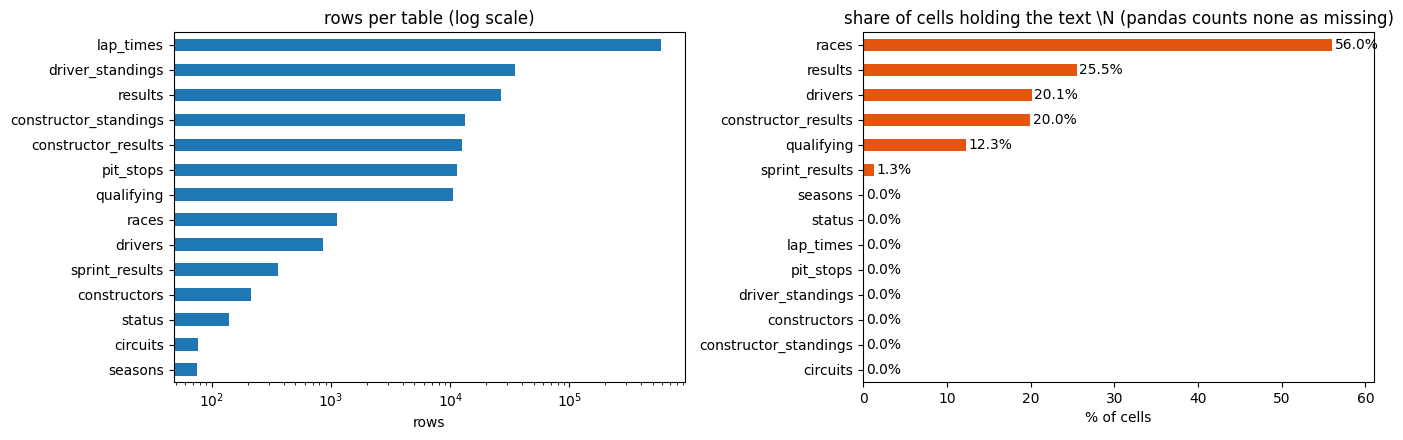

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

pre_overview['rows'].sort_values().plot.barh(ax=axes[0], logx=True)
axes[0].set_title('rows per table (log scale)')
axes[0].set_xlabel('rows')

pre_share = (100 * pre_overview['cells with \\N'] / (pre_overview['rows'] * pre_overview['columns'])).sort_values()
pre_share.plot.barh(ax=axes[1], color='#e6550d')
for i, v in enumerate(pre_share):
    axes[1].text(v + 0.3, i, f'{v:.1f}%', va='center')
axes[1].set_xlim(0, pre_share.max() + 5)
axes[1].set_title('share of cells holding the text \\N (pandas counts none as missing)')
axes[1].set_xlabel('% of cells')

plt.tight_layout()
plt.show()

## 1.2 Coverage over time

For each table with a `raceId`, the share of each season's races that have at least one row in the table (1 = every race, 0 = none). The five tables without a `raceId` (circuits, constructors, drivers, seasons, status) are not about single races, and `races` is the list of races itself, so they are left out.

**Why the share of races, not the number of rows.** The number of rows depends on how many cars raced and on what one row is (a lap, a pit stop, a result). The share of races means the same thing in every table and every season.

**Why it matters.** A feature built from a table is empty in every season the table does not cover.

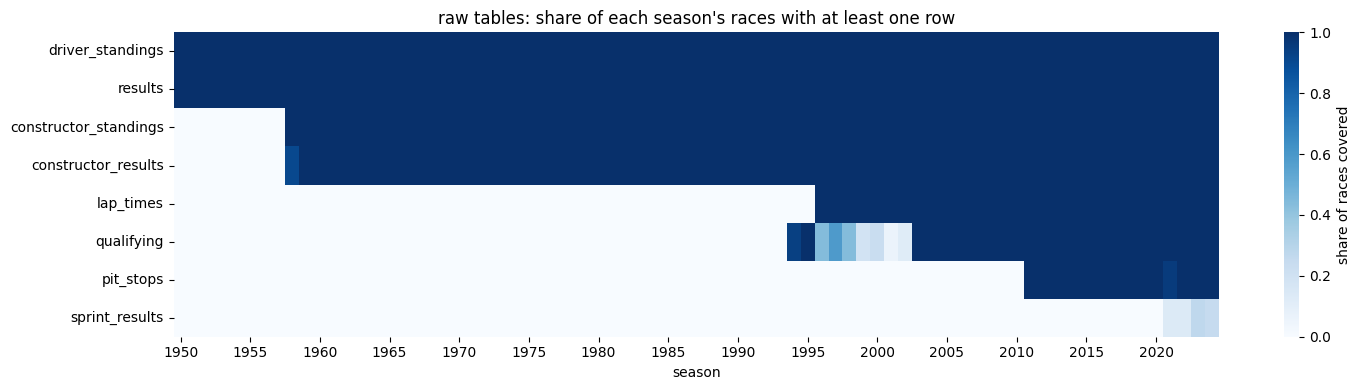

,first season
driver_standings,1950
results,1950
constructor_standings,1958
constructor_results,1958
lap_times,1996
qualifying,1994
pit_stops,2011
sprint_results,2021


qualifying, % of races covered: {1994: 94, 1995: 100, 1996: 44, 1997: 59, 1998: 44, 1999: 19, 2000: 24, 2001: 6, 2002: 12, 2003: 100}


In [7]:
# which seasons each table covers: share of a season's races with at least one row in the table
pre_races = raw_before['races'][['raceId', 'year']]
pre_per_season = pre_races.groupby('year').size()

pre_cov = pd.DataFrame({
    name: (df[['raceId']].drop_duplicates().merge(pre_races, on='raceId')
           .groupby('year').size().reindex(pre_per_season.index, fill_value=0) / pre_per_season)
    for name, df in raw_before.items() if 'raceId' in df.columns and name != 'races'}).T
pre_cov = pre_cov.loc[pre_cov.mean(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(15, 4))
sns.heatmap(pre_cov, cmap='Blues', vmin=0, vmax=1, xticklabels=5,
            cbar_kws={'label': 'share of races covered'})
plt.title("raw tables: share of each season's races with at least one row")
plt.xlabel('season')
plt.ylabel('')
plt.tight_layout()
plt.show()

# first season with any row, per table
display(pre_cov.apply(lambda r: r[r > 0].index.min(), axis=1).rename('first season').to_frame())

# qualifying in its first seasons: % of each season's races covered
print('qualifying, % of races covered:', (100 * pre_cov.loc['qualifying', 1994:2003]).round().astype(int).to_dict())

## 1.3 The target and the grain

The target is a podium: `positionOrder` <= 3. Three checks on the raw `results`:
- how rare a podium is, overall and per decade;
- whether the table is already one row per driver per race, as the brief asks;
- whether every race has exactly 3 podium rows, as it should.

**Why these checks.** A rare target changes how the models are scored, and repeated rows or extra podium rows would give wrong labels.

result rows: 26759 | podium rows: 3397 | podium rate: 12.7%
repeated (raceId, driverId) pairs: 85 | rows in them: 176 | extra rows: 91
races by number of podium rows: {3: 1107, 4: 16, 5: 1, 7: 1}
races with more than 3 podium rows: 18 | seasons: 1950 to 1960


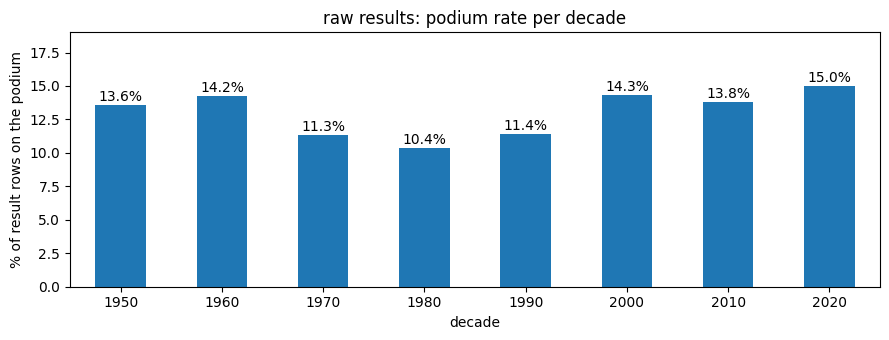

In [8]:
# the target in the raw results: how rare is a podium, is the grain already one row per driver per race,
# and does every race have exactly 3 podium rows?
pre_res = raw_before['results'].merge(raw_before['races'][['raceId', 'year']], on='raceId')
pre_res['podium'] = pre_res.positionOrder <= 3

print('result rows:', len(pre_res), '| podium rows:', int(pre_res.podium.sum()),
      f'| podium rate: {pre_res.podium.mean():.1%}')

# repeated (raceId, driverId) pairs: the rows in them, and the extra rows if one row per pair is kept
pre_pairs = pre_res.groupby(['raceId', 'driverId']).size()
print('repeated (raceId, driverId) pairs:', int((pre_pairs > 1).sum()),
      '| rows in them:', int(pre_pairs[pre_pairs > 1].sum()),
      '| extra rows:', int((pre_pairs[pre_pairs > 1] - 1).sum()))

# podium rows per race (should always be 3)
pre_pod_race = pre_res.groupby('raceId').podium.sum()
pre_more = pre_res[pre_res.raceId.isin(pre_pod_race[pre_pod_race > 3].index)]
print('races by number of podium rows:', pre_pod_race.value_counts().sort_index().to_dict())
print('races with more than 3 podium rows:', pre_more.raceId.nunique(),
      '| seasons:', pre_more.year.min(), 'to', pre_more.year.max())

pre_rate = pre_res.groupby(pre_res.year // 10 * 10).podium.mean() * 100
ax = pre_rate.plot.bar(rot=0, figsize=(9, 3.5))
for i, v in enumerate(pre_rate):
    ax.text(i, v + 0.3, f'{v:.1f}%', ha='center')
ax.set_ylim(0, pre_rate.max() + 4)
plt.xlabel('decade')
plt.ylabel('% of result rows on the podium')
plt.title('raw results: podium rate per decade')
plt.tight_layout()
plt.show()

## 1.4 What the raw data shows, and what it means for the cleaning

**Hidden missing values.** Six tables hold the text `\N` in place of a missing value: `races` (56.0% of its cells), `results` (25.5%), `drivers` (20.1%), `constructor_results` (20.0%), `qualifying` (12.3%) and `sprint_results` (1.3%). pandas counts none of them as missing, and it reads every column that contains `\N` as text, so 8 of the 9 text columns in `results` and 11 of the 14 in `races` are text only because of `\N` (the others are text by nature, such as names, dates and `positionText`). `qualifying` is the only table where pandas already sees missing values: 68 cells of `q2` and `q3`, all in 2023 and 2024, are left empty instead of holding `\N`, so the file marks a missing time in two ways. → Every table is read with `\N` as missing (`load()`), which also keeps the empty cells as missing, and the types are checked again table by table in section 2.

**Coverage over time.** `results` and `driver_standings` cover every season from 1950. The constructor tables start in 1958, `qualifying` in 1994 (94% of the races in 1994 and all of them in 1995, then only 6–59% per season until 2002, and every race from 2003), `lap_times` in 1996, `pit_stops` in 2011 and `sprint_results` in 2021, and only a few races per season have a sprint. → A feature built from one of these tables is empty before its first season, so the coverage is checked for each table in section 2 and decides the training window.

**The target.** 3,397 of the 26,759 result rows (12.7%) are podiums, between 10.4% (1980s) and 15.0% (2020s) per decade, so the positive class is rare in every era. 176 rows sit in 85 repeated (`raceId`, `driverId`) pairs, so the table is not yet one row per driver per race; keeping one row per pair removes 91 rows. Also, 18 races, all between 1950 and 1960, have more than 3 podium rows. → The duplicates are handled first, in the `results` part of section 2, which also explains the races with more than 3 podium rows (*Summary of anomaly checks*).

# 2. Audit and cleaning, table by table

Each table follows the same steps: look at the data, state the problem, decide, fix, and check the fix. Type conversions are made next to the check that showed they were needed.

Only the duplicate driver-race rows are removed in this section, because every later join needs one row per driver per race. Rows that do not belong in the modelling table (`never_ran`, `is_indy500`) are flagged here and removed in section 5, after the history features are built, so they still count in a driver's history.

## `Results Table`

In [9]:
raw_before['results'].head(10)

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1
5,6,18,6,3,8,13,6,6,6,3.0,57,\N,\N,50,14,1:29.639,212.974,11
6,7,18,7,5,14,17,7,7,7,2.0,55,\N,\N,54,8,1:29.534,213.224,5
7,8,18,8,6,1,15,8,8,8,1.0,53,\N,\N,20,4,1:27.903,217.180,5
8,9,18,9,2,4,2,\N,R,9,0.0,47,\N,\N,15,9,1:28.753,215.100,4
9,10,18,10,7,12,18,\N,R,10,0.0,43,\N,\N,23,13,1:29.558,213.166,3


In [10]:
raw_before['results'].dtypes

resultId             int64
raceId               int64
driverId             int64
constructorId        int64
number              object
grid                 int64
position            object
positionText        object
positionOrder        int64
points             float64
laps                 int64
time                object
milliseconds        object
fastestLap          object
rank                object
fastestLapTime      object
fastestLapSpeed     object
statusId             int64
dtype: object

In [11]:
raw_before['results'].isna().sum()    

resultId           0
raceId             0
driverId           0
constructorId      0
number             0
grid               0
position           0
positionText       0
positionOrder      0
points             0
laps               0
time               0
milliseconds       0
fastestLap         0
rank               0
fastestLapTime     0
fastestLapSpeed    0
statusId           0
dtype: int64

In [12]:
# but there are \N values in the cells, so let us count them
(raw_before['results'] == '\\N').sum()             

resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10953
positionText           0
positionOrder          0
points                 0
laps                   0
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
statusId               0
dtype: int64

### results: types and missing values

*Hypothesis: the `\N` text is why pandas reports 0 missing values and reads some numeric columns as `object`.*

*Prediction: after reading `\N` as missing, the missing counts will equal the `\N` counts, and some `object` columns will become numeric.*

In [13]:
results = load('results')

In [14]:
before = raw_before['results']

cmp = pd.DataFrame({
    'dtype_before':   before.dtypes.astype(str),
    'dtype_after':    results.dtypes.astype(str),
    'missing_before': before.isna().sum(),          
    'sentinel_before': (before == '\\N').sum(),     
    'missing_after':  results.isna().sum(),         
})
cmp

,dtype_before,dtype_after,missing_before,sentinel_before,missing_after
resultId,int64,int64,0,0,0
raceId,int64,int64,0,0,0
driverId,int64,int64,0,0,0
constructorId,int64,int64,0,0,0
number,object,float64,0,6,6
grid,int64,int64,0,0,0
position,object,float64,0,10953,10953
positionText,object,object,0,0,0
positionOrder,int64,int64,0,0,0
points,float64,float64,0,0,0


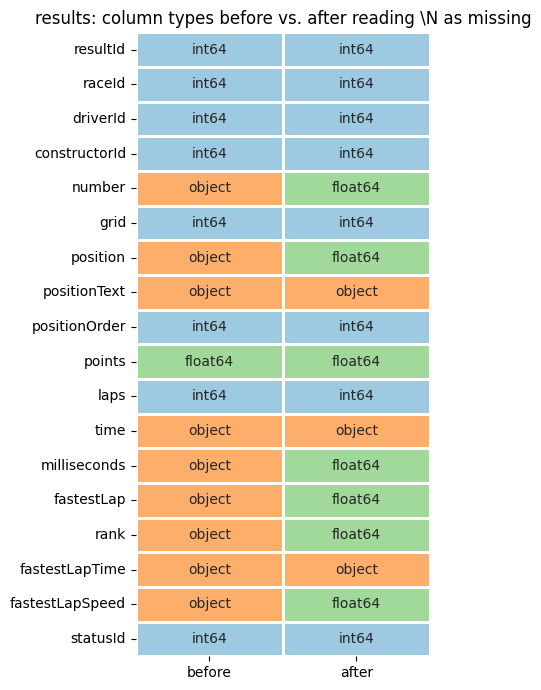

In [15]:
# more clear visualization 
before = raw_before['results'].dtypes.astype(str)
after = results.dtypes.astype(str)
types = pd.DataFrame({'before': before, 'after': after})

codes = {'int64': 0, 'float64': 1, 'object': 2}
num = types.apply(lambda s: s.map(lambda t: codes.get(t, 3)))   # 3 = any other type

plt.figure(figsize=(4.5, 7))
sns.heatmap(num, annot=types, fmt='', cbar=False, linewidths=1, linecolor='white',
            cmap=ListedColormap(['#9ecae1', '#a1d99b', '#fdae6b', '#d9d9d9']),
            vmin=0, vmax=3)
plt.title('results: column types before vs. after reading \\N as missing')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [16]:
# the missing values per column in the results table
results.isna().sum()

resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10953
positionText           0
positionOrder          0
points                 0
laps                   0
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
statusId               0
dtype: int64

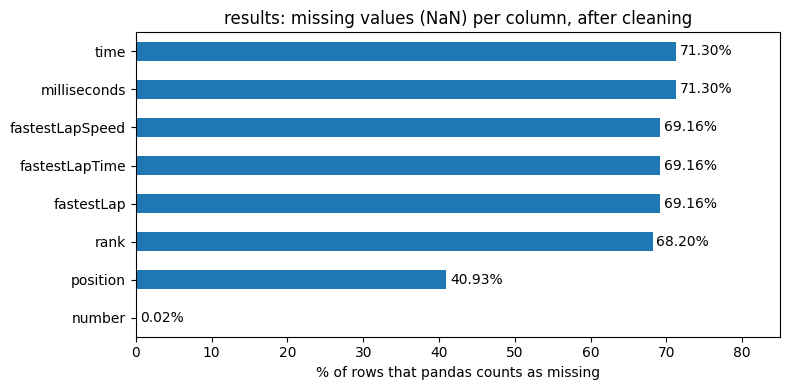

In [17]:
# visualization
pct_after = (results.isna().mean() * 100)
pct_after = pct_after[pct_after > 0].sort_values()

ax = pct_after.plot.barh(figsize=(8, 4))
for i, v in enumerate(pct_after):
    ax.text(v + 0.5, i, f'{v:.2f}%', va='center')

ax.set_xlim(0, 85)
plt.xlabel('% of rows that pandas counts as missing')
plt.title('results: missing values (NaN) per column, after cleaning')
plt.tight_layout()
plt.show()

### results: columns that are still `object` after reading `\N` as missing

After the reload, only three columns remain `object`: `positionText`, `time` and `fastestLapTime`.

- `positionText` holds codes (R, F, W, D, E, N, or a number), so text is its correct type. It is analysed separately.
- `time` and `fastestLapTime` hold durations written as strings, so they need a closer look.

**Method:** replace every digit with a `9` and count how many rows share each string pattern. This shows how many different formats a column contains without reading rows by eye.

In [18]:
for col in ['fastestLapTime', 'time']:
    shapes = (results[col].dropna()
              .str.replace(r'\d', '9', regex=True)
              .value_counts())
    print(col, '-', len(shapes), 'different shapes,', shapes.sum(), 'rows')
    print(shapes.to_string(), '\n')
    # checking if the column hold consistent format for the data
    # fastestLapTime does while time does not as mentioned in the guide
    # A leading + means a gap from winner
    # no + means the winner's full time. One column holds two different meanings.

fastestLapTime - 1 different shapes, 8252 rows
fastestLapTime
9:99.999    8252 

time - 21 different shapes, 7680 rows
time
+99.999        2973
+9:99.999      1614
9:99:99.999     765
+9.999          732
+9:99.99        281
+9:99.9         279
+99.9           259
+99.99          243
9:99:99.9       242
9:99:99.99      118
+9.9             73
+9.99            68
+99:99.99        13
+999.999         10
+99:99.9          3
+9:99.9999        2
99:99.999         1
99:99.9           1
+9:99             1
9:99.999          1
+99.9999          1 



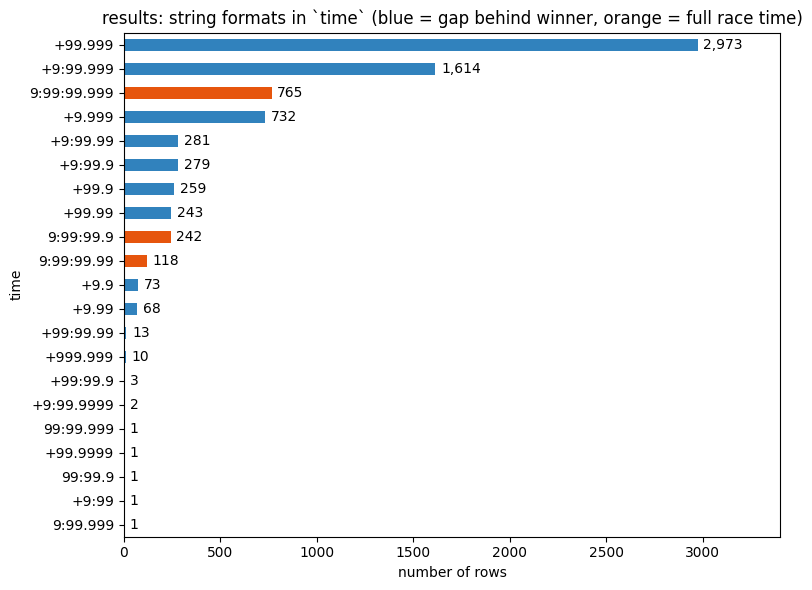

In [19]:
shapes = (results['time'].dropna()
          .str.replace(r'\d', '9', regex=True)
          .value_counts()
          .sort_values())

colors = ['#3182bd' if s.startswith('+') else '#e6550d' for s in shapes.index]

ax = shapes.plot.barh(figsize=(8, 6), color=colors)
for i, v in enumerate(shapes):
    ax.text(v + 30, i, f'{v:,}', va='center')

ax.set_xlim(0, 3400)
plt.xlabel('number of rows')
plt.title('results: string formats in `time` (blue = gap behind winner, orange = full race time)')
plt.tight_layout()
plt.show()

### `time`: what the string formats mean

**Two kinds of values share one column**
- **Leading `+` (6,552 rows):** the gap between this driver and the race winner, e.g. `+5.478` means 5.478 seconds behind.
- **No `+` (1,128 rows):** a full race time, which is the winner's total time, e.g. `1:34:50.616`.

So `time` mixes a duration and a difference in one column, which is why it cannot be treated as a single numeric field.

**Why there are 21 formats: the values are not zero-padded**
The strings are written at their natural length, so the pattern changes with the size of the number. Looking at the gaps by magnitude:
- under 10 seconds, `+9.999`: 873 rows
- 10 to 99 seconds, `+99.999`: 3,476 rows
- 1 to 9 minutes, `+9:99.999`: 2,177 rows
- 10 minutes or more, `+99:99.999`: 16 rows
- 100 seconds or more written as seconds, `+999.999`: 10 rows

Full race times follow the same logic: `9:99:99.999` has hours, while a few short races have no hours (`99:99.999`, 3 rows).

**The number of decimals also varies (0 to 4)**
Most rows have 3 decimals, but many have 1 or 2, and a handful have 0 or 4. We have not checked why. One possible explanation is that precision changed between eras, but that needs a check by season before we claim it.

**Decision**
Parsing would need a separate rule for each combination of hours, minutes, sign and decimals, and the result would duplicate `milliseconds`, which already holds the race duration as a number. We keep `time` as text and use `milliseconds`. `time` is a post-race column, so it is never used as a feature.

**Still to confirm:** that `time` and `milliseconds` are missing in the same rows, meaning they agree.

In [20]:
print('same rows missing:', (results.time.isna() == results.milliseconds.isna()).all())

same rows missing: True


**Decision:** keep `time` as text and use `milliseconds` as the numeric race duration. The dataset documentation (Kaggle) describes `milliseconds` as the finishing time in milliseconds, and `time` mixes full race times and gaps in 21 formats. Both are post-race columns and are never used as features, so we did not verify the two against each other any further.

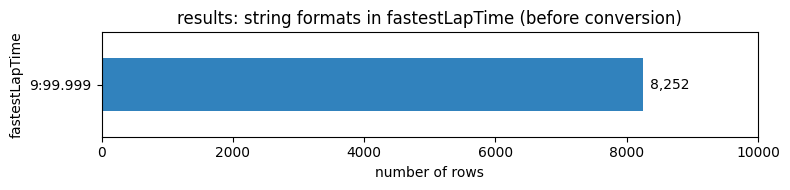

In [21]:
shapes_f = (results['fastestLapTime'].dropna()
            .str.replace(r'\d', '9', regex=True)
            .value_counts()
            .sort_values())

ax = shapes_f.plot.barh(figsize=(8, 2), color='#3182bd')
for i, v in enumerate(shapes_f):
    ax.text(v + 100, i, f'{v:,}', va='center')

ax.set_xlim(0, 10000)
plt.xlabel('number of rows')
plt.title('results: string formats in fastestLapTime (before conversion)')
plt.tight_layout()
plt.show()

### `fastestLapTime`

**Finding:** all 8,252 non-missing values share a single pattern (`9:99.999`, i.e. minutes:seconds.milliseconds, like "1:27.452"). This equals 26,759 rows minus 18,507 missing values, so no values are hidden.

**Decision:** convert it to numeric seconds in a new column, `fastestLapTime_s` (minutes × 60 + seconds). Because there is only one format, a single rule covers every row. This is the "lap-time strings to numeric seconds" step the brief asks for.

In [22]:
parts = results['fastestLapTime'].str.split(':', expand=True)
results['fastestLapTime_s'] = parts[0].astype(float) * 60 + parts[1].astype(float)

In [23]:
print('non-missing before:', results['fastestLapTime'].notna().sum())
print('non-missing after: ', results['fastestLapTime_s'].notna().sum())
results['fastestLapTime_s'].describe()

non-missing before: 8252
non-missing after:  8252


count    8252.000000
mean       90.827595
std        12.338956
min        55.404000
25%        80.848250
50%        90.267500
75%        99.476750
max       202.300000
Name: fastestLapTime_s, dtype: float64

### `positionText`

This is the last of the three columns that stayed `object` after reading `\N` as missing (the other two, `time` and `fastestLapTime`, are covered above). Its text type is correct, because it holds codes and not numbers. What makes it worth a closer look is that it seems to explain why `position` is empty in 10,953 rows (41%).

According to the course's F1 introduction, `positionText` holds the position as text, or a letter code when the driver has no official position:

| Code | Meaning |
|---|---|
| R | Retired (and not classified, see note) |
| D | Disqualified |
| E | Excluded |
| W | Withdrawn |
| F | Failed to qualify |
| N | Not classified |

**Note:** a driver can retire and still be classified, getting a numeric `position`, if they completed at least 90% of the winner's laps. So `R` only appears for retirements without an official position. We rely on the course description for this and did not verify it against `status`.

**Hypothesis:** a missing `position` always comes with a letter in `positionText`, and a filled `position` always comes with a number.

**Prediction:** a cross-tabulation of "`position` is missing" against "`positionText` is a number" will have two empty cells: missing with a number, and filled with a letter.

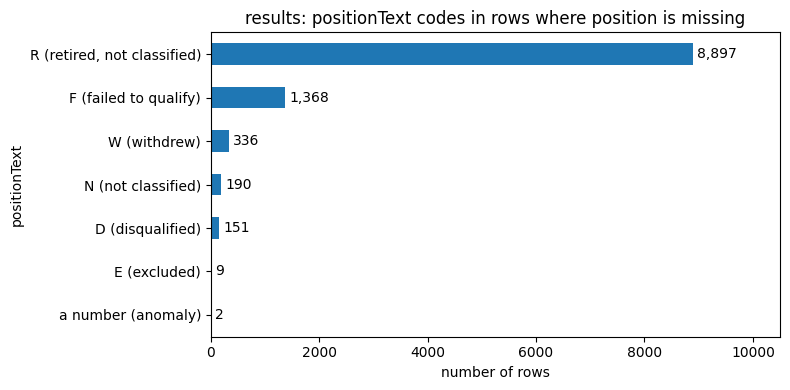

In [24]:
miss = results[results.position.isna()].copy()

def label(code):
    names = {'R': 'R (retired, not classified)', 'F': 'F (failed to qualify)', 'W': 'W (withdrew)',
             'N': 'N (not classified)', 'D': 'D (disqualified)', 'E': 'E (excluded)'}
    return names.get(code, 'a number (anomaly)')

counts = miss.positionText.map(label).value_counts().sort_values()

ax = counts.plot.barh(figsize=(8, 4))
for i, v in enumerate(counts):
    ax.text(v + 80, i, f'{v:,}', va='center')

ax.set_xlim(0, 10500)
plt.xlabel('number of rows')
plt.title('results: positionText codes in rows where position is missing')
plt.tight_layout()
plt.show()

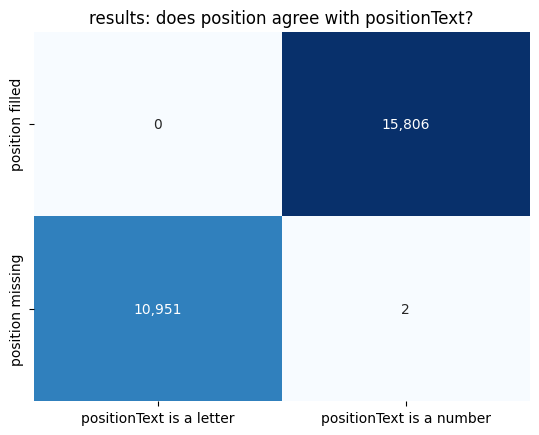

In [25]:
df = results
ct = pd.crosstab(df.position.isna(), df.positionText.str.isdigit())
ct.index = ['position filled', 'position missing']
ct.columns = ['positionText is a letter', 'positionText is a number']

sns.heatmap(ct, annot=True, fmt=',d', cmap='Blues', cbar=False)
plt.title('results: does position agree with positionText?')
plt.ylabel('')
plt.xlabel('')
plt.show()

### The 2 rows where `position` is missing but `positionText` is a number

The crosstab shows 2 rows where `position` is empty even though `positionText` holds a number.

**Question:** are these drivers classified or not?

**What we check:** their `status` (how the race ended), their `grid` (whether they took the start) and their `laps` compared with the winner's laps (the course's F1 introduction says classification requires completing at least 90% of the winner's laps).

In [26]:
odd = results[results.position.isna() & results.positionText.str.isdigit()]

winner_laps = results.groupby('raceId').laps.max()          # most laps completed in each race
out = (odd.merge(raw_before['races'][['raceId', 'year', 'name']], on='raceId')
          .merge(raw_before['drivers'][['driverId', 'surname']], on='driverId')
          .merge(raw_before['status'], on='statusId'))

out['race_laps'] = out.raceId.map(winner_laps)
out['pct_of_race'] = (100 * out.laps / out.race_laps).round(1)

out[['year', 'name', 'surname', 'status', 'grid', 'laps', 'race_laps', 'pct_of_race', 'positionText', 'positionOrder']]

,year,name,surname,status,grid,laps,race_laps,pct_of_race,positionText,positionOrder
0,2005,Australian Grand Prix,Button,+1 Lap,8,56,57,98.2,11,11
1,2005,Australian Grand Prix,Sato,+2 Laps,20,55,57,96.5,14,14


**Result:** both rows are from the 2005 Australian Grand Prix. Button (grid 8) finished 11th, one lap down (56 of 57 laps, 98.2%), and Sato (grid 20) finished 14th, two laps down (55 of 57 laps, 96.5%). Both took the start, both reached the flag with status "+1 Lap" and "+2 Laps", and both completed more than 90% of the race distance. Their `positionText` and `positionOrder` agree. They are therefore classified finishers whose `position` value is missing from the dataset, not unclassified drivers.

**Decision:** this is a data gap in `position` only. The target is built from `positionOrder`, which is complete and consistent for these rows, so the target is unaffected. We leave `position` as missing and document the two rows.

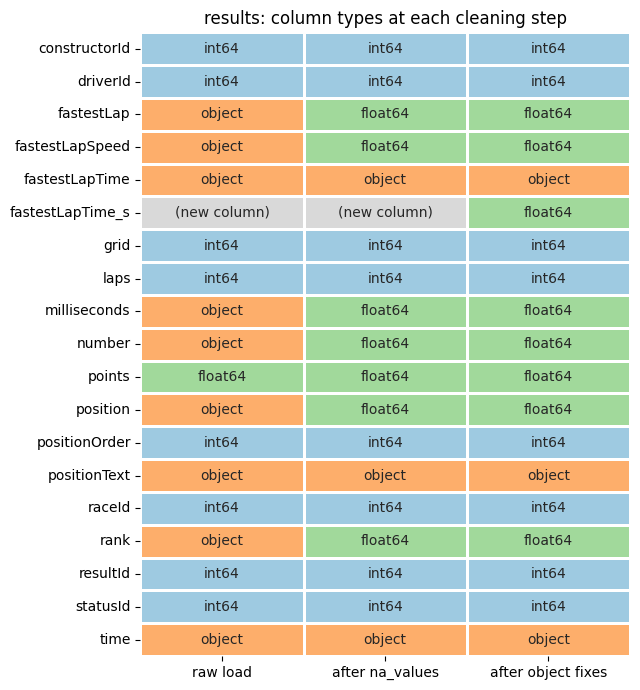

In [27]:
stage1 = raw_before['results'].dtypes.astype(str)
stage2 = results.drop(columns='fastestLapTime_s').dtypes.astype(str)   # state right after the na_values reload
stage3 = results.dtypes.astype(str)                                    # now, after the object investigation

types = pd.DataFrame({'raw load': stage1,
                      'after na_values': stage2,
                      'after object fixes': stage3}).fillna('(new column)')

codes = {'int64': 0, 'float64': 1, 'object': 2}
num = types.apply(lambda s: s.map(lambda t: codes.get(t, 3)))   # 3 = new column

plt.figure(figsize=(6.5, 7))
sns.heatmap(num, annot=types, fmt='', cbar=False, linewidths=1, linecolor='white',
            cmap=ListedColormap(['#9ecae1', '#a1d99b', '#fdae6b', '#d9d9d9']),
            vmin=0, vmax=3)
plt.title('results: column types at each cleaning step')
plt.ylabel('')
plt.tight_layout()
plt.show()

### results: remaining missing values

After reading `\N` as missing, seven columns still contain missing values: `time`, `milliseconds`, `fastestLap`, `rank`, `fastestLapTime`, `fastestLapSpeed` and `number`. (`position` is covered in its own section.)

**Six of them describe the outcome of the race itself** (`time`, `milliseconds`, `fastestLap`, `rank`, `fastestLapTime`, `fastestLapSpeed`). They are not known at the prediction cutoff (after qualifying, before the race starts), so using them would be data leakage and they cannot be features. We leave them as missing and do not fill them: filling columns we never use adds nothing, and for the race columns it would invent results that did not happen.

**`number` is different.** It is the car number, which is not an outcome of the race, so the leakage argument does not apply to it. It is missing in only 6 rows. Before deciding what to do, we look at which rows they are.

In [28]:
missing_num = results[results.number.isna()]

(missing_num.merge(raw_before['races'][['raceId', 'year', 'name']], on='raceId')
            .merge(raw_before['drivers'][['driverId', 'surname']], on='driverId')
            .merge(raw_before['constructors'][['constructorId', 'name']], on='constructorId', suffixes=('_race', '_team'))
            .merge(raw_before['status'], on='statusId')
            [['year', 'name_race', 'surname', 'name_team', 'grid', 'positionText', 'status', 'positionOrder']])

,year,name_race,surname,name_team,grid,positionText,status,positionOrder
0,1962,French Grand Prix,Marsh,BRM,0,W,Withdrew,19
1,1962,French Grand Prix,Davis,Porsche,0,W,Withdrew,20
2,1962,French Grand Prix,Abate,Lotus-Climax,0,W,Withdrew,21
3,1962,French Grand Prix,Burgess,Cooper-Climax,0,W,Withdrew,22
4,1961,French Grand Prix,Bordeu,Lotus-Climax,0,W,Withdrew,28
5,1963,South African Grand Prix,Hailwood,Lola,0,W,Withdrew,23


**Result:** the 6 rows with a missing `number` are all from the early 1960s (1961 to 1963). All have `positionText` = `W` and `status` = Withdrew, and all have `grid` = 0, even though `grid` has no `\N`. This suggests the missing `number` may be related to these drivers having withdrawn, but the data does not say why no car number was recorded.

**Next question:** `grid` normally starts at 1 (pole position), so a value of 0 is unusual. The course's F1 introduction says a `grid` of 0 may mean a pit-lane start ("verify in EDA"). The rows above are drivers who withdrew, which does not look like a pit-lane start, so we will need to investigate what `grid` = 0 means in `results` as a whole.

**Decision for `number`:** leave as missing, no fill. It is an identifier and not a feature.

### results: one row per driver per race

Each row of the modelling table is one prediction: "will this driver finish on the podium in this race?" That requires the pair (`raceId`, `driverId`) to be unique. The course material says duplicates come from shared drives in early F1 (mainly the 1950s), when drivers swapped cars mid-race, so a driver can have two result rows in one race.

**Question:** how many pairs appear more than once, and in which years?

**Method:** count the rows whose (`raceId`, `driverId`) pair occurs more than once.

,duplicated pairs,rows involved
2 rows for the same driver in one race,79,158
3 rows for the same driver in one race,6,18
Total,85,176


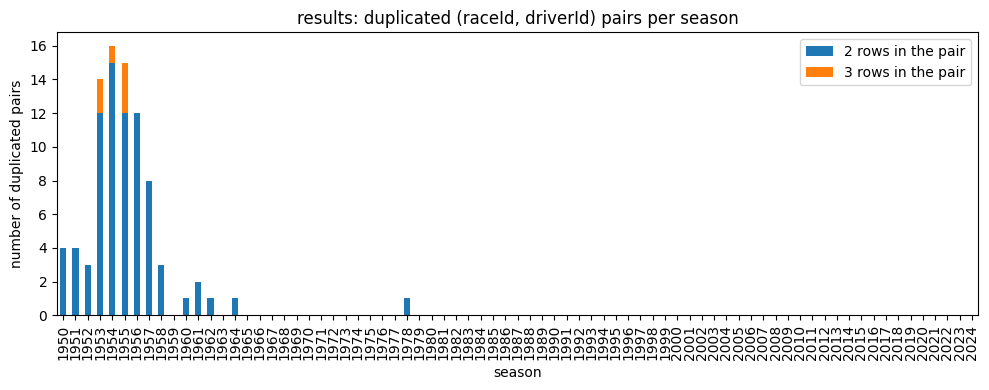

In [29]:
dup_rows = results[results.duplicated(['raceId', 'driverId'], keep=False)].merge(
    raw_before['races'][['raceId', 'year']], on='raceId')

# one line per duplicated pair, with how many rows it has
pair_size = (dup_rows.groupby(['raceId', 'driverId', 'year']).size()
                     .rename('rows_in_pair').reset_index())

# Table: how many pairs have 2 rows, how many have 3
summary = (pair_size.groupby('rows_in_pair').size().rename('duplicated pairs').to_frame()
           .assign(**{'rows involved': lambda d: d['duplicated pairs'] * d.index}))
summary.index = [f'{i} rows for the same driver in one race' for i in summary.index]
summary.loc['Total'] = summary.sum()
display(summary)

# Chart: duplicated pairs per season, split by 2 or 3 rows
per_year = pair_size.groupby(['year', 'rows_in_pair']).size().unstack(fill_value=0)
all_years = raw_before['races'].year
per_year = per_year.reindex(range(all_years.min(), all_years.max() + 1), fill_value=0)
per_year.columns = [f'{c} rows in the pair' for c in per_year.columns]

ax = per_year.plot.bar(stacked=True, figsize=(10, 4))
plt.xlabel('season')
plt.ylabel('number of duplicated pairs')
plt.title('results: duplicated (raceId, driverId) pairs per season')
plt.tight_layout()
plt.show()

In [30]:
pairs = (results[results.duplicated(['raceId', 'driverId'], keep=False)]
         .merge(raw_before['races'][['raceId', 'year']], on='raceId')
         .groupby(['raceId', 'driverId', 'year']).size()
         .rename('rows').reset_index())

print('duplicated pairs:', len(pairs), '| rows involved:', pairs.rows.sum())
print(pairs.rows.value_counts().sort_index().rename('pairs').rename_axis('rows in the pair'))

per_year = pairs.groupby('year').size()
print('pairs from 1950 to 1957:', (pairs.year <= 1957).sum())
print('pairs after 1957:       ', (pairs.year > 1957).sum())
print('peak season:', per_year.idxmax(), 'with', per_year.max(), 'pairs')

print('\npairs after 1957, per season:')
print(pairs[pairs.year > 1957].groupby('year').size().to_string())

duplicated pairs: 85 | rows involved: 176
rows in the pair
2    79
3     6
Name: pairs, dtype: int64
pairs from 1950 to 1957: 76
pairs after 1957:        9
peak season: 1954 with 16 pairs

pairs after 1957, per season:
year
1958    3
1960    1
1961    2
1962    1
1964    1
1978    1


**Result:** (`raceId`, `driverId`) is not unique in `results`: 85 pairs (176 rows) appear more than once. 79 pairs have 2 rows and 6 pairs have 3 rows (all from 1953 to 1955). 76 of the 85 pairs are from 1950 to 1957, with the peak in 1954 (16 pairs), as the course material says. The other 9 pairs are from 1958 to 1978 and are examined separately below.

**Next questions:**
1. What does a duplicated pair look like in the data (grid, laps, position, points)?
2. What are the 9 pairs after 1957, and why do they exist?

In [31]:
look = (dup_rows.merge(raw_before['drivers'][['driverId', 'surname']], on='driverId')
                .merge(raw_before['races'][['raceId', 'name']].rename(columns={'name': 'race'}), on='raceId')
                .merge(raw_before['constructors'][['constructorId', 'name']].rename(columns={'name': 'team'}), on='constructorId')
                .merge(raw_before['status'], on='statusId')
                .sort_values(['year', 'raceId', 'driverId']))

cols = ['year', 'race', 'surname', 'team', 'grid', 'laps', 'positionText', 'positionOrder', 'points', 'status']

look[cols].head(12)

,year,race,surname,team,grid,laps,positionText,positionOrder,points,status
84,1950,Indianapolis 500,Bettenhausen,Deidt,8,30,R,31,0.0,Wheel bearing
88,1950,Indianapolis 500,Bettenhausen,Kurtis Kraft,9,136,5,5,1.0,+2 Laps
85,1950,French Grand Prix,Rosier,Talbot-Lago,6,10,R,12,0.0,Overheating
89,1950,French Grand Prix,Rosier,Talbot-Lago,15,56,6,6,0.0,+8 Laps
86,1950,Italian Grand Prix,Fangio,Alfa Romeo,1,23,R,15,1.0,Gearbox
91,1950,Italian Grand Prix,Fangio,Alfa Romeo,7,34,R,13,0.0,Engine
87,1950,Italian Grand Prix,Ascari,Ferrari,2,21,R,17,0.0,Engine
90,1950,Italian Grand Prix,Ascari,Ferrari,6,80,2,2,3.0,Finished
81,1951,French Grand Prix,Fangio,Alfa Romeo,1,55,11,11,0.0,+22 Laps
92,1951,French Grand Prix,Fangio,Alfa Romeo,7,77,1,1,5.0,Finished


**What a duplicated pair looks like:** we looked at the first 12 rows (6 pairs, from 1950 and 1951). In each pair the same driver appears twice in the same race, with different `grid` slots, different `laps`, and different results. In 5 of the 6 pairs, one row has far fewer laps and a retirement or a poor finish, while the other row has many more laps and a better finish. For example, Fangio (1951 French GP) has one row with 55 laps (11th) and another with 77 laps (1st, 5 points), and Ascari (1950 Italian GP) has a retirement after 21 laps and a 2nd place after 80 laps. In the sixth pair (Fangio, 1950 Italian GP) both rows are retirements, with 23 and 34 laps.

This is consistent with the shared drives described in the course's F1 introduction, where a driver's own car stops, and he continues the race in another car, getting a better result. The data does not state this directly, so it is our reading of the pattern. It also shows that the two rows of a pair are results of two different cars, so each row has its own `grid`, `laps` and `positionOrder`, and we have to choose which one stands for the driver in that race.

**Limit:** this reading is based on 6 of the 85 pairs. The next cell checks one part of it on all 85 pairs: whether the row with the best finish is also the row with the most laps.

In [32]:
d = dup_rows.copy()
g = d.groupby(['raceId', 'driverId'])

d['best_finish'] = d.positionOrder == g.positionOrder.transform('min')
d['most_laps']   = d.laps == g.laps.transform('max')

# per pair: does the best-finish row also have the most laps?
agree = d[d.best_finish].groupby(['raceId', 'driverId', 'year']).most_laps.any().rename('same_row').reset_index()

print(agree.same_row.value_counts().rename({True: 'best finish = most laps', False: 'different rows'}))

same_row
best finish = most laps    85
Name: count, dtype: int64


**Result:** in all 85 duplicated pairs, the row with the best `positionOrder` is also the row with the most laps. The rules "keep the best finish" and "keep the most laps" therefore choose the same row in every case.

**Consequence:** the choice between these two rules does not change the table. We can use either one, and we pick the one that is easier to justify.

In [33]:
print('pairs after 1957:', (pair_size.year > 1957).sum())
look[look.year > 1957][cols]

pairs after 1957: 9


,year,race,surname,team,grid,laps,positionText,positionOrder,points,status
9,1958,Monaco Grand Prix,Flockhart,Cooper,0,0,F,17,0.0,Did not qualify
10,1958,Monaco Grand Prix,Flockhart,BRM,0,0,F,27,0.0,Did not qualify
11,1958,French Grand Prix,Brooks,Vanwall,5,16,R,18,0.0,Engine
171,1958,French Grand Prix,Brooks,Vanwall,10,35,R,14,0.0,Engine
12,1958,Italian Grand Prix,Shelby,Maserati,17,1,R,18,0.0,Handling
172,1958,Italian Grand Prix,Shelby,Maserati,11,69,4,4,0.0,+1 Lap
8,1960,Argentine Grand Prix,Moss,Cooper-Climax,1,40,R,17,0.0,Suspension
173,1960,Argentine Grand Prix,Moss,Cooper-Climax,8,80,3,3,0.0,Finished
5,1961,British Grand Prix,Moss,Ferguson,20,56,D,19,0.0,Disqualified
6,1961,British Grand Prix,Moss,Lotus-Climax,5,44,R,21,0.0,Brakes


### The 9 duplicated pairs after 1957

The course's F1 introduction says shared drives were possible until 1957, but 9 duplicated pairs fall after that. Three in 1958, one in 1960, two in 1961, one in 1962, one in 1964 and one in 1978. We read all 18 rows. They fall into two groups.

**Group 1: both rows have laps (6 pairs)**
Brooks (1958 French GP), Shelby (1958 Italian GP), Moss (1960 Argentine GP), Moss (1961 British GP), Gregory (1961 United States GP) and Clark (1964 United States GP).
- Each row has its own `grid` slot, `laps` and result, so each is the result of one car.
- In every pair, the row with more laps also has the better `positionOrder`. For example, Moss (1960) has one row with 40 laps (retired) and one with 80 laps (3rd), and Shelby (1958) has one with 1 lap (retired) and one with 69 laps (4th).
- In 5 of the 6 pairs both rows belong to the same team. The exception is Moss (1961 British GP), with one row for Ferguson and one for Lotus-Climax.
- This is the same pattern as the 1950s pairs, so these are probably shared drives that happened after 1957. The data does not state that, so it is our reading.
- Two pairs are worth a note. Moss (1961) has a row with 56 laps and the status Disqualified (`grid` 20), and a row with 44 laps and a retirement (`grid` 5). The data does not say whether the disqualification came during or after the race. Clark (1964) has `grid` 1 in both rows (102 laps, 7th, Out of fuel; 54 laps, retired, Injection). One driver cannot start from the same slot in two cars, so at least one of the two grid values is unreliable, and the data does not say which. The starting slot therefore cannot tell the two rows apart.

**Group 2: `grid` = 0 and 0 laps in both rows (3 pairs)**
Flockhart (1958 Monaco GP), Greene (1962 British GP) and Ertl (1978 Italian GP).
- Each driver appears twice with a different team: Cooper and BRM, Lotus-Climax and Gilby, ATS and Ensign.
- The statuses are Did not qualify (Flockhart, both rows), Withdrew (Greene, both rows) and Did not qualify and Did not prequalify (Ertl).
- These drivers were entered with two cars and did not start in either. They are not shared drives. This explains the 1978 pair.

**Consequence for the keep rule:** the 3 pairs in group 2 cannot be separated by laps, since both rows have 0, and they do not belong in the modelling table anyway if non-starters are dropped. So the duplicate rule and the non-starter rule interact, and the order in which we apply them has to be stated.

In [34]:
print('pairs with equal positionOrder:', (results[results.duplicated(['raceId', 'driverId'], keep=False)]
      .groupby(['raceId', 'driverId']).positionOrder.nunique() == 1).sum())

pairs with equal positionOrder: 0


### Keep rule for duplicated pairs

**Rule:** for each (`raceId`, `driverId`), keep the row with the best `positionOrder` (the lowest number).

**Why:**
- In all 85 duplicated pairs, the row with the best `positionOrder` is also the row with the most laps, so "best finish" and "most laps" give the same table.
- Within the 85 pairs, no two rows share the same `positionOrder` (checked), so the rule always selects exactly one row and needs no tie-breaker.
- It does not use `grid`, which is unreliable inside a pair (Clark, 1964, has `grid` 1 in both rows).
- It does not change the model or Q1 and Q3. All 85 pairs are from 1950 to 1978, so none is in the seasons the model uses (2003–2024), in Q1 (from 1980) or in Q3 (from 2014).

**Order:** the rule is applied first, before any history features are built, because a driver with two rows in one race would otherwise be counted twice. The raw `results` table is left unchanged, and the rule is applied to a copy, `results_unique`.

**The 3 non-starter pairs:** Flockhart (1958), Greene (1962) and Ertl (1978) have `grid` = 0 and 0 laps in both rows, so the rule picks one of the two rows by `positionOrder` alone, and the choice does not matter. The row that is kept is still a `grid` = 0 row, so it is handled in the next section, together with the other `grid` = 0 rows.

In [35]:
results_unique = (results
    .sort_values(['raceId', 'driverId', 'positionOrder'])
    .drop_duplicates(['raceId', 'driverId'], keep='first')
    .sort_values('resultId')
    .reset_index(drop=True))

print('rows before:', len(results))
print('rows after: ', len(results_unique))
print('removed:    ', len(results) - len(results_unique))
print('(raceId, driverId) unique?', not results_unique.duplicated(['raceId', 'driverId']).any())

rows before: 26759
rows after:  26668
removed:     91
(raceId, driverId) unique? True


**Applied:** the rule removed 91 rows (176 rows in 85 pairs became 85 rows), leaving 26,668 rows in `results_unique`, and (`raceId`, `driverId`) is now unique. From here on, the analysis uses `results_unique`.

### results: key checks

**Primary key:** `resultId` should identify each row, so it must be unique and non-null.

**Foreign keys:** `results` points to four other tables: `raceId` to `races`, `driverId` to `drivers`, `constructorId` to `constructors` and `statusId` to `status`. Each foreign key must be non-null, and every value must exist in the parent table (no orphans). The parent keys must also be unique.

**Method:** count nulls and duplicates for `resultId`, and for each foreign key count the nulls and the values missing from the parent table. 

In [36]:
parents = {
    'raceId':        ('races',        raw_before['races'].raceId),
    'driverId':      ('drivers',      raw_before['drivers'].driverId),
    'constructorId': ('constructors', raw_before['constructors'].constructorId),
    'statusId':      ('status',       raw_before['status'].statusId),
}

rows = [{'check': 'primary key', 'column': 'resultId', 'points to': '-',
         'nulls': int(results.resultId.isna().sum()),
         'duplicates': int(results.resultId.duplicated().sum()),
         'orphans': '-', 'parent key unique': '-'}]

for col, (tbl, keys) in parents.items():
    rows.append({'check': 'foreign key', 'column': col, 'points to': f'{tbl}.{col}',
                 'nulls': int(results[col].isna().sum()),
                 'duplicates': '-',
                 'orphans': int((~results[col].dropna().isin(keys)).sum()),
                 'parent key unique': keys.is_unique})

pd.DataFrame(rows)

,check,column,points to,nulls,duplicates,orphans,parent key unique
0,primary key,resultId,-,0,0,-,-
1,foreign key,raceId,races.raceId,0,-,0,True
2,foreign key,driverId,drivers.driverId,0,-,0,True
3,foreign key,constructorId,constructors.constructorId,0,-,0,True
4,foreign key,statusId,status.statusId,0,-,0,True


**Result:** all checks pass for `results`. `resultId` is unique and non-null. `raceId`, `driverId`, `constructorId` and `statusId` have no nulls, no orphans (every value exists in its parent table), and each parent key is unique. Together with the (`raceId`, `driverId`) check on `results_unique`, the table has a valid primary key, valid foreign keys and one row per driver per race.

### results: `grid`

**Question:** what does `grid` contain, and what does the value 0 mean in this data? We also look for other anomalies in the column.

**Method:**
1. Look at the distribution of `grid` values.
2. Split the `grid` = 0 rows by `positionText` and `status`.
3. Look at how they are spread over the decades.
4. Check `grid` for other anomalies.

This section uses `results_unique` (one row per driver per race).

rows: 26668
min grid: 0 | max grid: 34
negative values: 0
grid == 0: 1635


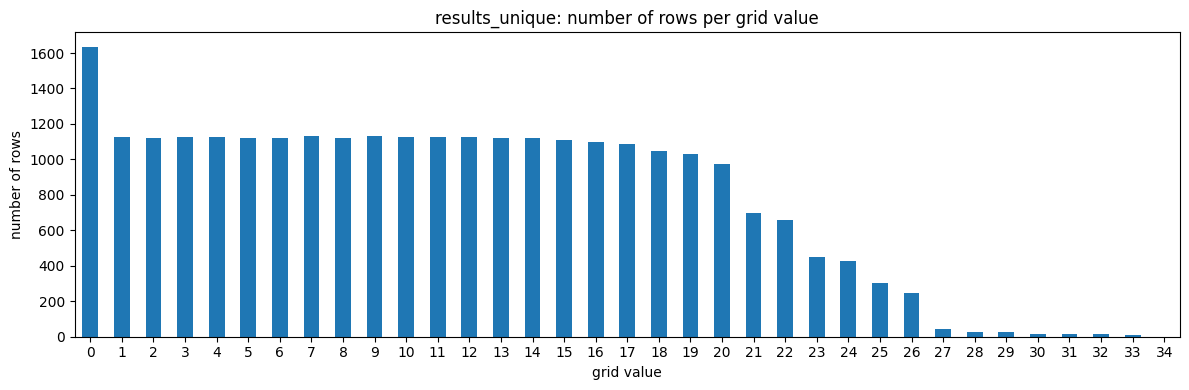

In [37]:
g = results_unique.grid

print('rows:', len(g))
print('min grid:', g.min(), '| max grid:', g.max())
print('negative values:', (g < 0).sum())
print('grid == 0:', (g == 0).sum())

counts = g.value_counts().sort_index()
ax = counts.plot.bar(figsize=(12, 4), rot=0)
plt.xlabel('grid value')
plt.ylabel('number of rows')
plt.title('results_unique: number of rows per grid value')
plt.tight_layout()
plt.show()

In [38]:
races_t   = raw_before['races'][['raceId', 'year', 'round', 'name']].copy()
drivers_t = raw_before['drivers'][['driverId', 'surname']]
constr_t  = raw_before['constructors'][['constructorId', 'name']].rename(columns={'name': 'team'})
status    = raw_before['status']

In [39]:
zero = results_unique[results_unique.grid == 0]

# one race per year: the one with the most grid==0 rows (earliest round on ties)
n_zero = (zero.groupby('raceId').size().rename('n_zero').reset_index()
              .merge(races_t, on='raceId'))
pick = (n_zero.sort_values(['year', 'n_zero', 'round'], ascending=[True, False, True])
              .drop_duplicates('year'))

rows = (zero.merge(pick[['raceId', 'year', 'round', 'name']], on='raceId')
            .merge(drivers_t, on='driverId')
            .merge(constr_t, on='constructorId')
            .merge(status, on='statusId')
            .sort_values(['year', 'positionOrder']))

cols = ['year', 'name', 'surname', 'team', 'positionOrder', 'positionText', 'grid', 'laps', 'status']

print('rows shown:', len(rows), '| years covered:', rows.year.min(), 'to', rows.year.max())
with pd.option_context('display.max_rows', None, 'display.width', 200):
    display(rows[cols])

print('years with no grid==0 at all:', sorted(set(races_t.year) - set(pick.year)))

rows shown: 311 | years covered: 1952 to 2024


,year,name,surname,team,positionOrder,positionText,grid,laps,status
276,1952,Italian Grand Prix,de Tornaco,Ferrari,25,F,0,0,Did not qualify
277,1952,Italian Grand Prix,Crespo,Maserati,26,F,0,0,Did not qualify
278,1952,Italian Grand Prix,de Graffenried,Maserati,27,F,0,0,Did not qualify
279,1952,Italian Grand Prix,Collins,HWM,28,F,0,0,Did not qualify
280,1952,Italian Grand Prix,Whitehead,Ferrari,29,F,0,0,Did not qualify
281,1952,Italian Grand Prix,Gaze,HWM,30,F,0,0,Did not qualify
282,1952,Italian Grand Prix,Aston,Aston Butterworth,31,F,0,0,Did not qualify
283,1952,Italian Grand Prix,Macklin,HWM,32,F,0,0,Did not qualify
284,1952,Italian Grand Prix,von Stuck,Ferrari,33,F,0,0,Did not qualify
285,1952,Italian Grand Prix,Dusio,Cisitalia,34,F,0,0,Did not qualify


years with no grid==0 at all: [1950, 1951, 1953, 1969, 2003, 2004, 2005, 2006, 2007, 2008, 2010, 2013, 2014]


code    D  E    F  R    W  number
decade                           
1950    0  0   48  0   19       0
1960    0  0   74  0  123       0
1970    0  0  329  0   21       0
1980    4  5  544  1   17       0
1990    2  2  342  0   11       0
2000    0  0    5  0    3       0
2010    0  0    4  7    4      13
2020    0  0    0  6    4      47


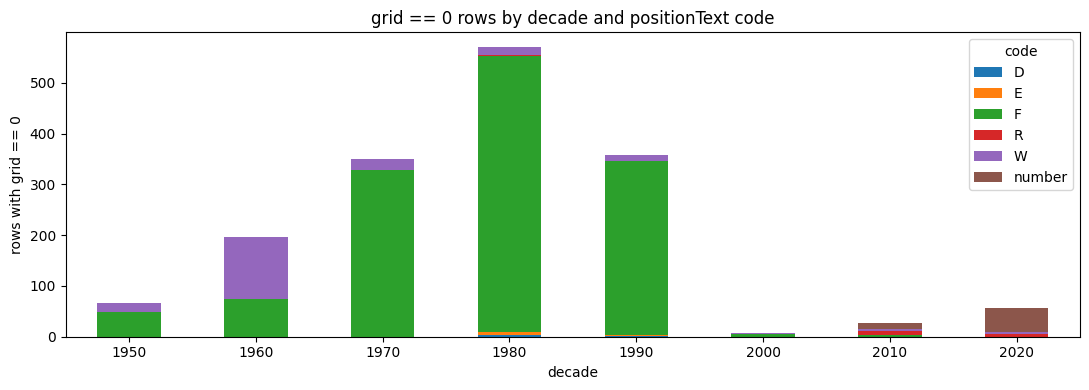

In [40]:
z = results_unique[results_unique.grid == 0].merge(raw_before['races'][['raceId', 'year']], on='raceId')

is_num = pd.to_numeric(z.positionText, errors='coerce').notna()
z['code'] = z.positionText.where(~is_num, 'number')
z['decade'] = (z.year // 10 * 10).astype(int)

ct = z.groupby(['decade', 'code']).size().unstack(fill_value=0)
print(ct)

ct.plot.bar(stacked=True, figsize=(11, 4), rot=0)
plt.xlabel('decade')
plt.ylabel('rows with grid == 0')
plt.title('grid == 0 rows by decade and positionText code')
plt.legend(title='code')
plt.tight_layout()
plt.show()

### What `grid` = 0 means

`grid` has no missing values, but 1,635 rows (about 6% of `results_unique`) have the value 0. The starting grid begins at 1 (pole position), so 0 is not a real starting slot. We looked at these rows through `positionText`, `status` and `laps`. As a sample we printed all `grid` = 0 rows for one race per year (the race with the most such rows in that year), and we counted all of them by decade and `positionText` code in the chart below.

**Observation 1: before 2000, the `grid` = 0 rows are almost all F and W.**
Of the 1,542 rows before 2000, 1,528 carry the codes F (did not qualify / did not prequalify / 107% rule / injury) or W (withdrew). The other 14 are D (disqualified), E (excluded) and one R. Every F, W, D and E row has `laps` = 0. Statuses such as "Engine" or "Accident" on W rows also show 0 laps, so these drivers never ran a lap of the race. The counts drop sharply after 1999 (8 rows in the 2000s).

**Observation 2: in the 2010s and 2020s the `grid` = 0 rows are different.**
All 60 rows with a numeric `positionText` (a classified finishing place) fall in 2010 or later, and so do 13 of the 14 R rows (retired). All 60 numeric rows have `laps` > 0, up to 78, and 12 of the 14 R rows have laps. Examples: Stroll finished 7th at the 2023 US Grand Prix with 56 laps, and Hartley retired on lap 1 at the 2018 British Grand Prix. These drivers raced, so a `grid` of 0 cannot mean "did not start" for them.

**Interpretation (hypothesis, not yet confirmed).**
The course material says a driver can start from the pit lane, which is not one of the numbered grid slots. A driver who raced with `grid` = 0 may therefore have started from the pit lane, which the dataset records as 0. The dataset has no pit-lane flag, so we cannot read this directly from `results`.

**Test: join with `qualifying`.**
`qualifying` records each driver's qualifying position separately from `grid`. If the hypothesis holds, `grid` = 0 drivers with `laps` > 0 should mostly have a qualifying position (they qualified and then started from the pit lane), while `grid` = 0 drivers with `laps` = 0 should mostly have none. `qualifying` only covers the later seasons, so we run the check on the years it covers. Older rows are judged from `laps` and `status` alone.

**Consequence for cleaning.**
Dropping every `grid` = 0 row would remove real race finishers. The rule we are considering separates the rows by whether the driver ran any laps. The final rule comes after the qualifying check.

In [41]:
qual = load('qualifying')
races_t   = load('races')[['raceId', 'year', 'round', 'name']]
drivers_t = load('drivers')[['driverId', 'surname']]
status    = load('status')

# key check on qualifying before joining
print('qualifying rows:', len(qual))
print('duplicate (raceId, driverId):', qual.duplicated(['raceId', 'driverId']).sum())
print('qual position dtype:', qual.position.dtype, '| missing:', qual.position.isna().sum())

# join: qualifying.position renamed so it can't be confused with results.position
q = qual[['raceId', 'driverId', 'position']].rename(columns={'position': 'qual_pos'})
m = (results_unique
     .merge(q, on=['raceId', 'driverId'], how='left', validate='one_to_one')
     .merge(races_t[['raceId', 'year']], on='raceId'))

m['has_qual'] = m.qual_pos.notna()
print('rows after join:', len(m), '(results_unique has', len(results_unique), ')')

# is qualifying complete from a given year? share of results rows with a qualifying row, per year
cov_by_year = m.groupby('year').has_qual.mean()
print('\nshare of results rows with a qualifying row:')
print(cov_by_year[cov_by_year.index >= 1950].round(2).to_string())

qualifying rows: 10494


duplicate (raceId, driverId): 0
qual position dtype: int64 | missing: 0
rows after join: 26668 (results_unique has 26668 )

share of results rows with a qualifying row:
year
1950    0.00
1951    0.00
1952    0.00
1953    0.00
1954    0.00
1955    0.00
1956    0.00
1957    0.00
1958    0.00
1959    0.00
1960    0.00
1961    0.00
1962    0.00
1963    0.00
1964    0.00
1965    0.00
1966    0.00
1967    0.00
1968    0.00
1969    0.00
1970    0.00
1971    0.00
1972    0.00
1973    0.00
1974    0.00
1975    0.00
1976    0.00
1977    0.00
1978    0.00
1979    0.00
1980    0.00
1981    0.00
1982    0.00
1983    0.00
1984    0.00
1985    0.00
1986    0.00
1987    0.00
1988    0.00
1989    0.00
1990    0.00
1991    0.00
1992    0.00
1993    0.00
1994    0.88
1995    1.00
1996    0.44
1997    0.59
1998    0.44
1999    0.18
2000    0.24
2001    0.06
2002    0.12
2003    1.00
2004    1.00
2005    1.00
2006    1.00
2007    1.00
2008    1.00
2009    1.00
2010    1.00
2011    0.99
2012    0.99
2013   

In [42]:
QYEAR = 2003        # first year with complete qualifying coverage (see the table above)
cov = m[m.year >= QYEAR].copy()

is_num = pd.to_numeric(cov.positionText, errors='coerce').notna()
cov['code'] = cov.positionText.where(~is_num, 'number')
cov['group'] = np.select(
    [(cov.grid == 0) & (cov.laps > 0), (cov.grid == 0) & (cov.laps == 0)],
    ['grid0_raced', 'grid0_no_laps'], default='grid>0')

print(f'years {QYEAR}+ only, {len(cov)} rows')
display(cov.groupby('group').agg(rows=('resultId', 'size'),
                                 with_qual=('has_qual', 'sum'),
                                 share_with_qual=('has_qual', 'mean')).round(3))

# the same split by code, grid==0 only
display(cov[cov.grid == 0].groupby(['group', 'code']).agg(rows=('resultId', 'size'),
                                                         with_qual=('has_qual', 'sum')))

# the raced group row by row: did they qualify, and where?
raced0 = (cov[cov.group == 'grid0_raced']
          .merge(races_t[['raceId', 'name']], on='raceId')
          .merge(drivers_t, on='driverId')
          .merge(status, on='statusId')
          .sort_values(['year', 'name', 'positionOrder']))
with pd.option_context('display.max_rows', None, 'display.width', 200):
    display(raced0[['year', 'name', 'surname', 'code', 'positionOrder', 'laps', 'status', 'qual_pos']])

years 2003+ only, 8970 rows


,rows,with_qual,share_with_qual
group,,,
grid0_no_laps,14,12,0.857
grid0_raced,72,71,0.986
grid>0,8884,8863,0.998


rows  with_qual
group         code                   
grid0_no_laps F          4          4
              R          1          1
              W          9          7
grid0_raced   R         12         12
              number    60         59

,year,name,surname,code,positionOrder,laps,status,qual_pos
0,2015,Monaco Grand Prix,Sainz,number,10,78,Finished,8.0
3,2016,Austrian Grand Prix,Massa,number,20,63,Brakes,10.0
4,2016,Austrian Grand Prix,Kvyat,R,22,2,Retired,20.0
1,2016,Monaco Grand Prix,Nasr,R,17,48,Retired,22.0
2,2016,Monaco Grand Prix,Verstappen,R,18,34,Accident,21.0
5,2017,Australian Grand Prix,Ricciardo,R,17,25,Power Unit,10.0
6,2018,British Grand Prix,Hartley,R,20,1,Power Unit,20.0
13,2019,Austrian Grand Prix,Russell,number,18,69,+2 Laps,19.0
8,2019,Azerbaijan Grand Prix,Räikkönen,number,10,50,+1 Lap,19.0
9,2019,Azerbaijan Grand Prix,Kubica,number,16,49,+2 Laps,18.0


In [43]:
z0 = m[(m.grid == 0) & (m.laps == 0)].copy()
print('grid==0 and laps==0:', len(z0))

is_num = pd.to_numeric(z0.positionText, errors='coerce').notna()
z0['code'] = z0.positionText.where(~is_num, 'number')

# signs of having actually raced, even though laps == 0
checks = {
    'points > 0':              (z0.points > 0).sum(),
    'race time filled':        z0.time.notna().sum(),
    'milliseconds filled':     z0.milliseconds.notna().sum(),
    'fastestLap filled':       z0.fastestLap.notna().sum(),
    'numeric positionText':    (z0.code == 'number').sum(),
    'status Finished/+N Lap':  z0.statusId.isin(
        status[status.status.str.contains(r'^Finished$|^\+\d+ Lap', regex=True)].statusId).sum(),
}
display(pd.Series(checks, name='rows'))

# by code, with the years they cover
display(z0.groupby('code').agg(rows=('resultId', 'size'),
                               first_year=('year', 'min'),
                               last_year=('year', 'max')))

# qualified (has a qualifying row) but laps == 0: possible DNS cases, only meaningful from 2003
q0 = z0[(z0.year >= 2003) & z0.has_qual].merge(races_t[['raceId', 'name']], on='raceId') \
       .merge(drivers_t, on='driverId').merge(status, on='statusId')
print('\nlaps == 0 but has a qualifying row (2003+):', len(q0))
display(q0[['year', 'name', 'surname', 'code', 'status', 'qual_pos']])

grid==0 and laps==0: 1563


points > 0                0
race time filled          0
milliseconds filled       0
fastestLap filled         0
numeric positionText      0
status Finished/+N Lap    0
Name: rows, dtype: int64

,rows,first_year,last_year
code,,,
D,6,1984,1990
E,7,1987,1997
F,1346,1952,2012
R,2,1981,2017
W,202,1952,2023



laps == 0 but has a qualifying row (2003+): 12


,year,name,surname,code,status,qual_pos
0,2009,Hungarian Grand Prix,Massa,W,Withdrew,10.0
1,2012,Australian Grand Prix,de la Rosa,F,Did not qualify,23.0
2,2012,Australian Grand Prix,Karthikeyan,F,Did not qualify,24.0
3,2015,Australian Grand Prix,Bottas,W,Withdrew,6.0
4,2011,Australian Grand Prix,Liuzzi,F,Did not qualify,23.0
5,2011,Australian Grand Prix,Karthikeyan,F,Did not qualify,24.0
6,2011,Monaco Grand Prix,Pérez,W,Injury,10.0
7,2017,Malaysian Grand Prix,Räikkönen,R,Battery,2.0
8,2021,Italian Grand Prix,Tsunoda,W,Brakes,17.0
9,2022,Saudi Arabian Grand Prix,Schumacher,W,Withdrew,14.0


### Drivers with a grid slot who did not start

The check above only looks at `grid` = 0. A driver can also get a grid slot and then not take part, for example by withdrawing before the start (F1 history: the 14 cars that pulled out of the 2005 United States Grand Prix after the formation lap, or Leclerc on pole at Monaco in 2021, whose driveshaft broke on the way to the grid). No single column says whether a car started, so we look at every combination of the grid slot, the laps and the result code (`positionText`: a number = classified, R = retired, W = withdrew, F = failed to qualify, D = disqualified, E = excluded, N = not classified).

In [44]:
combo = results_unique.assign(
    slot=np.where(results_unique.grid > 0, 'grid > 0', 'grid 0'),
    ran=np.where(results_unique.laps > 0, 'laps > 0', 'laps 0'),
    code=results_unique.positionText.where(results_unique.positionText.isin(['F', 'W', 'D', 'E', 'R', 'N']), 'number'))
display(pd.crosstab([combo.slot, combo.ran], combo.code))

named = (combo[(combo.grid > 0) & combo.code.isin(['F', 'W', 'D', 'E'])]
         .merge(races_t[['raceId', 'year', 'name']], on='raceId').merge(drivers_t, on='driverId').merge(status, on='statusId'))
cols = ['year', 'name', 'surname', 'grid', 'laps', 'code', 'status']
print('F or W with a grid slot and 0 laps:', int(((named.laps == 0) & named.code.isin(['F', 'W'])).sum()))
print('\nF or W with a grid slot who ran laps:')
display(named[(named.laps > 0) & named.code.isin(['F', 'W'])][cols].sort_values('year'))
print('D or E with a grid slot and 0 laps:')
display(named[(named.laps == 0) & named.code.isin(['D', 'E'])][cols].sort_values('year'))

code                 D  E     F    N     R    W  number
slot     ran                                           
grid 0   laps 0      6  7  1346    0     2  202       0
         laps > 0    0  0     0    0    12    0      60
grid > 0 laps 0      4  1    19    0   814  128       0
         laps > 0  141  1     1  190  7991    5   15738

F or W with a grid slot and 0 laps: 147

F or W with a grid slot who ran laps:


,year,name,surname,grid,laps,code,status
248,1952,Swiss Grand Prix,Macklin,12,24,W,Withdrew
247,1952,Swiss Grand Prix,Moss,9,24,W,Withdrew
209,1970,Spanish Grand Prix,Rodríguez,5,4,W,Withdrew
194,1974,United States Grand Prix,Dolhem,26,25,W,Withdrew
176,1977,German Grand Prix,Heyer,25,9,F,Did not qualify
167,1979,Dutch Grand Prix,Lauda,9,4,W,Withdrew


D or E with a grid slot and 0 laps:


,year,name,surname,grid,laps,code,status
112,1987,British Grand Prix,Ghinzani,19,0,E,Excluded
103,1989,Canadian Grand Prix,Mansell,5,0,D,Disqualified
104,1989,Canadian Grand Prix,Nannini,13,0,D,Disqualified
96,1990,German Grand Prix,Alliot,24,0,D,Disqualified
299,2024,São Paulo Grand Prix,Hülkenberg,17,0,D,Disqualified


**Reading.** Each combination means something different:
- **`grid` = 0 and 0 laps** (any code): no slot and no lap, the drivers who did not qualify, withdrew or were excluded. They did not start (the check above).
- **`grid` = 0 and laps run:** pit-lane starters. They started.
- **A grid slot, code F or W, and 0 laps:** they officially did not take part ("did not qualify" or "withdrew") and ran no lap, so they did not start. Before this check they counted as starts that missed the podium.
- **A grid slot, code F or W, and laps run:** they raced some laps and then left, for example Heyer at the 1977 German Grand Prix, who joined the race without having qualified (F1 history). They started.
- **A grid slot, code R, and 0 laps:** they retired before completing the first lap, mostly in first-lap collisions and accidents. They started, so 0 laps alone does not mean "did not start".
- **A grid slot, code D or E, and 0 laps:** mixed. Some of these drivers did start (F1 history: Mansell and Nannini at the 1989 Canadian Grand Prix pitted at the end of the formation lap, left the pit lane before the start was given, raced, and were then disqualified), so the code does not tell us. These few rows are kept as starts.

In [45]:
# did not start: no grid slot and no laps, or a grid slot but officially did not take part
# (F = did not qualify, W = withdrew) and no laps (see "Drivers with a grid slot who did not start")
no_slot = (results_unique.grid == 0) & (results_unique.laps == 0)
slot_but_no_start = (results_unique.grid > 0) & results_unique.positionText.isin(['F', 'W']) & (results_unique.laps == 0)
results_unique['never_ran'] = no_slot | slot_but_no_start
print('never_ran rows:', results_unique.never_ran.sum(),
      '| no grid slot and no laps:', no_slot.sum(), '| grid slot but did not start:', slot_but_no_start.sum())

never_ran rows: 1710 | no grid slot and no laps: 1563 | grid slot but did not start: 147


### Decision: who did not start (`never_ran`)

**Rule.** A driver who did not start the race is flagged `never_ran`: either `grid` = 0 and `laps` = 0, or a grid slot with the code F (did not qualify) or W (withdrew) and `laps` = 0. Flagged rows are removed from the modelling table after the history features are built. A row with `grid` = 0 and `laps` > 0 is kept (a pit-lane start).

**Evidence.**
- 1,635 rows have `grid` = 0. 1,563 of them have `laps` = 0, and none of those has points, a race time, a fastest lap or a numeric `positionText`. They are almost all F (did not qualify) and W (withdrew), mostly before 2000.
- Two of these 1,563 rows have the code R (retired) although they have `grid` = 0 and 0 laps: Lammers at the 1981 San Marino Grand Prix and Räikkönen at the 2017 Malaysian Grand Prix. We checked both against race reports (F1 history, not something the data shows): neither started. Lammers failed to qualify, and Räikkönen's car lost power on the way to the grid and was pushed back to the garage before the formation lap. The R code is misleading for these two rows, so they stay flagged `never_ran`.
- 147 more drivers had a grid slot but the code F or W and 0 laps (*Drivers with a grid slot who did not start*). They withdrew or were not allowed to start, so they are flagged too, which gives 1,710 `never_ran` rows.
- 72 rows have `grid` = 0 and `laps` > 0. All are from 2015 onward, and 71 of the 72 have a qualifying position. They qualified and raced, so a `grid` of 0 does not mean "did not start". A start from the pit lane is consistent with this, but the dataset has no field that confirms it. (Section 7.1 shows that before 2015 the data records pit-lane starts with a slot at the back of the grid instead of `grid` = 0, so this flag only finds pit-lane starts from 2015 on.)

**Why flag first.** The removed rows still carry history (for example, how often a driver failed to qualify before), so we flag them now and drop them after the features are built.

**Limitation.** `laps` is only known after the race. 58 drivers from 2003 onward qualified but never started, including some from the front row (for example Leclerc, pole at Monaco 2021; Räikkönen, 2nd at Malaysia 2017). No pre-race information could have shown this, so the model is not scored on such cases.

**Next.** We check `results` for other anomalies.

In [46]:
# grid 0 with laps run: kept and flagged as a pit-lane start
results_unique['pit_lane_start'] = (results_unique.grid == 0) & (results_unique.laps > 0)
print('pit_lane_start rows:', results_unique.pit_lane_start.sum())

# grid_clean: the original grid, with pit-lane starters put at the back of the field
# (the highest grid slot in that race + 1); `grid` itself is not changed
back_of_field = results_unique.groupby('raceId').grid.transform('max') + 1
results_unique['grid_clean'] = results_unique.grid.where(~results_unique.pit_lane_start, back_of_field)

assert (results_unique.grid == 0).sum() == (results_unique.never_ran & (results_unique.grid == 0)).sum() + results_unique.pit_lane_start.sum()
assert (results_unique.loc[~results_unique.never_ran, 'grid_clean'] > 0).all(), 'a starter still has grid 0'

pit_lane_start rows: 72


In [47]:
status_t = raw_before['status'][['statusId', 'status']]
r = results_unique.merge(races_t, on='raceId')
g = r.groupby('raceId')

print('=== podium / rank integrity ===')
podium_cnt = g['positionOrder'].apply(lambda s: (s <= 3).sum())
print('races with !=3 podium rows:', (podium_cnt != 3).sum())

dup_rank = g['positionOrder'].apply(lambda s: s.duplicated().any())
print('races with a repeated positionOrder:', dup_rank.sum())
shared = r[r.duplicated(['raceId', 'positionOrder'], keep=False)]
print('shared finishing places:', shared.groupby(['raceId', 'positionOrder']).ngroups,
      '| rows in them:', len(shared), '| seasons:', shared.year.min(), 'to', shared.year.max())

# meaningful replacement for "1..N": are ranks 1,2,3 each present once?
def podium_ok(s):
    top = s[s <= 3]
    return sorted(top) == [1, 2, 3]
podium_shape = g['positionOrder'].apply(podium_ok)
print('races where podium is NOT exactly {1,2,3}:', (~podium_shape).sum())

print('\n=== points sanity ===')
print('rows with points > 0 but positionOrder > 11:', ((r.points > 0) & (r.positionOrder > 11)).sum())

print('\n=== podium but not classified-finished ===')
fin_ids = status_t[status_t.status.str.match(r'Finished|\+\d+ Lap')].statusId
print('podium rows whose status is not Finished/+N Laps:',
      ((r.positionOrder <= 3) & (~r.statusId.isin(fin_ids))).sum())

print('\n=== range checks ===')
print('grid < 0:', (r.grid < 0).sum(), '| positionOrder < 1:', (r.positionOrder < 1).sum())
over_grid = g.apply(lambda d: (d.grid > len(d)).any(), include_groups=False)
print('races with grid greater than field size:', over_grid.sum())

print('\n=== laps vs winner ===')
winner_laps = g.apply(lambda d: d.loc[d.positionOrder == 1, 'laps'].max(), include_groups=False)
r2 = r.merge(winner_laps.rename('win_laps'), on='raceId')
print('rows with more laps than the race winner:', (r2.laps > r2.win_laps).sum())

print('\n=== grain ===')
print('duplicate (raceId, driverId):', results_unique.duplicated(['raceId','driverId']).sum())

=== podium / rank integrity ===


races with !=3 podium rows: 18


races with a repeated positionOrder:

 45
shared finishing places: 87 | rows in them: 184 | seasons: 1950 to 1961


races where podium is NOT exactly {1,2,3}:

 18

=== points sanity ===
rows with points > 0 but positionOrder > 11: 12

=== podium but not classified-finished ===
podium rows whose status is not Finished/+N Laps: 7

=== range checks ===
grid < 0: 0 | positionOrder < 1: 0


races with grid greater than field size:

 12

=== laps vs winner ===


rows with more laps than the race winner: 1

=== grain ===
duplicate (raceId, driverId): 0


In [48]:
races_t = raw_before['races'][['raceId','year','name']]
drivers_t = raw_before['drivers'][['driverId','surname']]
constr_t = raw_before['constructors'][['constructorId','name']].rename(columns={'name':'team'})

pod = results_unique[results_unique.positionOrder <= 3].merge(races_t, on='raceId')

# races with more than 3 podium rows
counts = pod.groupby('raceId').size().rename('n_podium')
bad = counts[counts > 3].reset_index().merge(races_t, on='raceId').sort_values('year')
print('races with >3 podium rows:', len(bad))
print(bad[['year','name','n_podium']].to_string(index=False))

# one race in full, with status joined in
status_t = raw_before['status'][['statusId','status']]
rid = bad.raceId.iloc[1]
one = (results_unique[results_unique.raceId == rid]
       .merge(drivers_t, on='driverId').merge(constr_t, on='constructorId')
       .merge(status_t, on='statusId')
       .sort_values('positionOrder'))
print(races_t[races_t.raceId==rid][['year','name']].to_string(index=False))
display(one[['positionOrder','positionText','grid','surname','team','laps','milliseconds','status']])

races with >3 podium rows: 18
 year                 name  n_podium
 1950   Italian Grand Prix         4
 1951    French Grand Prix         5
 1951   Italian Grand Prix         4
 1951     Indianapolis 500         4
 1953     Dutch Grand Prix         4
 1953     Indianapolis 500         4
 1954   Italian Grand Prix         4
 1954    German Grand Prix         4
 1955     Indianapolis 500         4
 1955    Monaco Grand Prix         4
 1955 Argentine Grand Prix         5
 1956 Argentine Grand Prix         4
 1956    Monaco Grand Prix         4
 1956   British Grand Prix         4
 1956   Italian Grand Prix         4
 1956   Belgian Grand Prix         4
 1957   British Grand Prix         4
 1960 Argentine Grand Prix         4
 year              name
 1951 French Grand Prix


,positionOrder,positionText,grid,surname,team,laps,milliseconds,status
0,1,1,7,Fagioli,Alfa Romeo,77,12131000.0,Finished
21,1,1,7,Fangio,Alfa Romeo,77,12131000.0,Finished
22,2,2,6,González,Ferrari,77,12189200.0,Finished
1,2,2,6,Ascari,Ferrari,77,12189200.0,Finished
2,3,3,4,Villoresi,Ferrari,74,NaN,+3 Laps
3,4,4,9,Parnell,Ferrari,73,NaN,+4 Laps
4,5,5,2,Farina,Alfa Romeo,73,NaN,+4 Laps
5,6,6,8,Chiron,Talbot-Lago,71,NaN,+6 Laps
6,7,7,11,Cabantous,Talbot-Lago,71,NaN,+6 Laps
7,8,8,14,Chaboud,Talbot-Lago,69,NaN,+8 Laps


In [49]:
pod_rows = results_unique[results_unique.positionOrder <= 3].merge(races_t, on='raceId')
flagged = pod_rows[pod_rows.raceId.isin(bad.raceId)]

# for each race, are the >3 podium rows explained by tied (positionOrder, constructorId)?
def shared_drive_ok(g):
    # count distinct cars on the podium = distinct (positionOrder, constructorId)
    cars = g[['positionOrder','constructorId']].drop_duplicates().shape[0]
    return cars <= 3

summary = flagged.groupby(['year','name']).apply(shared_drive_ok, include_groups=False)
print('races explained by shared drives (<=3 distinct cars):', summary.sum(), 'of', len(summary))
print('\nany NOT explained:')
print(summary[~summary].to_string())

races explained by shared drives (<=3 distinct cars): 18 of 18

any NOT explained:
Series([], )


In [50]:
r = results_unique.merge(races_t, on='raceId')
g = r.groupby('raceId')

print('=== 1. points > 0 but positionOrder > 11 ===')
pts = (r[(r.points > 0) & (r.positionOrder > 11)]
       .merge(drivers_t, on='driverId')
       .sort_values(['year','positionOrder']))
print(pts[['year','name','surname','positionOrder','positionText','points','laps']].to_string(index=False))

print('\n=== 2. podium but not Finished/+N Laps ===')
fin_ids = status_t[status_t.status.str.match(r'Finished|\+\d+ Lap')].statusId
pod = (r[(r.positionOrder <= 3) & (~r.statusId.isin(fin_ids))]
       .merge(drivers_t, on='driverId').merge(status_t, on='statusId')
       .sort_values('year'))
print(pod[['year','name','surname','positionOrder','laps','status']].to_string(index=False))

print('\n=== 3. grid greater than field size ===')
field = g.size().rename('field')
over = (r.merge(field, on='raceId'))
over = over[over.grid > over.field].merge(drivers_t, on='driverId').sort_values('year')
print(over[['year','name','surname','grid','field','positionOrder']].to_string(index=False))

print('\n=== 4. laps > winner ===')
winner_laps = g.apply(lambda d: d.loc[d.positionOrder == 1, 'laps'].max(), include_groups=False)
r2 = r.merge(winner_laps.rename('win_laps'), on='raceId')
bad_laps = (r2[r2.laps > r2.win_laps]
            .merge(drivers_t, on='driverId')
            .sort_values('year'))
print(bad_laps[['year','name','surname','positionOrder','laps','win_laps']].to_string(index=False))

=== 1. points > 0 but positionOrder > 11 ===
 year               name  surname  positionOrder positionText  points  laps
 1951 British Grand Prix   Farina             14            R     1.0    75
 1952   Indianapolis 500 Vukovich             17           17     1.0   191
 1953 Belgian Grand Prix González             16            R     1.0    11
 1954  French Grand Prix Herrmann             14            R     1.0    16
 1954 Spanish Grand Prix   Ascari             19            R     1.0    10
 1955 Italian Grand Prix     Moss             14            R     1.0    27
 1955  Monaco Grand Prix   Fangio             15            R     1.0    49
 1955   Indianapolis 500 Vukovich             25            R     1.0    56
 1956 British Grand Prix     Moss             12            R     1.0    94
 1956   Indianapolis 500    Russo             33            R     1.0    21
 1958  German Grand Prix     Moss             21            R     1.0     3
 1959  French Grand Prix     Moss          

 year             name surname  positionOrder  laps  win_laps
 1960 Dutch Grand Prix  Taylor              7    78        75


In [51]:
# 2) how far behind the winner were the non-"Finished" podium rows?
winner_laps = (r.groupby('raceId')
                 .apply(lambda d: d.loc[d.positionOrder == 1, 'laps'].max(), include_groups=False)
                 .rename('win_laps'))
chk = (r[(r.positionOrder <= 3) & (~r.statusId.isin(fin_ids))]
       .merge(winner_laps, on='raceId').merge(drivers_t, on='driverId').merge(status_t, on='statusId'))
chk['laps_behind'] = chk.win_laps - chk.laps
print(chk[['year', 'name', 'surname', 'positionOrder', 'laps', 'win_laps', 'laps_behind', 'status']].to_string(index=False))

# 4) the Dutch GP 1960 in full
t = (r[(r.year == 1960) & (r.name == 'Dutch Grand Prix')]
     .merge(drivers_t, on='driverId').merge(status_t, on='statusId').sort_values('positionOrder'))
print()
print(t[['positionOrder', 'positionText', 'surname', 'laps', 'milliseconds', 'status']].to_string(index=False))

 year                     name    surname  positionOrder  laps  win_laps  laps_behind      status
 1999     Brazilian Grand Prix   Frentzen              3    71        72            1 Out of fuel
 1984    San Marino Grand Prix de Angelis              3    59        60            1 Out of fuel
 1982        Monaco Grand Prix     Pironi              2    75        76            1 Out of fuel
 1982        Monaco Grand Prix de Cesaris              3    75        76            1 Out of fuel
 1975       British Grand Prix       Pace              2    55        56            1    Accident
 1975       British Grand Prix  Scheckter              3    55        56            1    Accident
 1966 United States Grand Prix      Rindt              2   107       108            1 Out of fuel

 positionOrder positionText     surname  laps  milliseconds       status
             1            1     Brabham    75     7307200.0     Finished
             2            2     Ireland    75     7331200.0     Finis

### Summary of anomaly checks on `results`

We tested rules that should never be broken. Four checks came back clean (no `grid` below 0, no `positionOrder` below 1, no duplicate (`raceId`, `driverId`), and every podium has a P1). Seven found rows to inspect:

**Shared drives (18 races, 45 with a repeated `positionOrder`).** In 18 races between 1950 and 1960, more than 3 rows have `positionOrder` <= 3. In all 18, the podium still has only 3 distinct cars (distinct `positionOrder` + `constructorId`), so the extra rows are drivers sharing a car and both being credited with its place, not a data error. A further 27 races have a tie lower down the field, from the same cause. Effect on the target: `podium = positionOrder <= 3` labels more than 3 drivers in these races. Shared drives end after the 1950s, so this does not occur in the modern era the model is trained and tested on. We therefore keep these rows and note the quirk; if an all-years training window is chosen, shared-drive cars would need to be collapsed to one podium per car.

**Points for a driver who finished far back (12 rows).** All 12 are from 1951 to 1959, each with exactly 1 point, and 11 of the 12 are coded R or D (3 are Indianapolis 500 rows). This is consistent with the one point for the fastest lap that existed until 1959, which did not depend on finishing, but our tables cannot confirm it (the fastest-lap columns are empty for those years). `points` is a post-race column and is never a feature, so no action.

**Podium finishers without status "Finished" (7 rows).** All 7 have "Out of fuel" or "Accident" as status (1966 to 1999). A driver can be classified after stopping if enough of the distance was completed, so the podium label is `positionOrder` <= 3 and not the status text.

**`grid` above the number of result rows (15 rows in 12 races, 1952 to 1986).** Seven of the 12 races are the German or Belgian Grand Prix. The grid numbers have gaps, so a slot such as 26 can appear in a race with only 19 result rows. Any replacement value for `grid` = 0 must therefore use the highest `grid` value of that race plus one, not the row count.

**More laps than the winner (1 row).** Taylor, 1960 Dutch Grand Prix: 7th with 78 laps, while the winner has 75 and his own status says "+5 Laps" (about 70 laps). The two drivers ahead of him have 74 laps, so 78 also breaks the rank order. It looks like a typo for 70, but we cannot confirm it. `laps` is a post-race column and the row is not affected by the `grid` = 0 rule, so we document it and leave the value unchanged.

In [52]:
# results_unique: grain and keys
assert results_unique.resultId.is_unique, 'resultId not unique'
assert not results_unique.duplicated(['raceId', 'driverId']).any(), 'duplicate driver per race'
assert results_unique.grid.min() >= 0, 'negative grid'
assert results_unique.laps.min() >= 0, 'negative laps'
assert results_unique.positionOrder.notna().all(), 'positionOrder has nulls'   # it is the target base

# the never_ran flag means what we think: no laps were run
assert (results_unique.loc[results_unique.never_ran, 'laps'] == 0).all(), 'never_ran row has laps'

## `Qualifying Table`

In [53]:
qualifying = load('qualifying')

print(qualifying.shape)
display(qualifying.head())

(10494, 9)


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


In [54]:
print(qualifying.isna().sum())

qualifyId           0
raceId              0
driverId            0
constructorId       0
number              0
position            0
q1                156
q2               4647
q3               6865
dtype: int64


In [55]:
print(qualifying.dtypes)

qualifyId         int64
raceId            int64
driverId          int64
constructorId     int64
number            int64
position          int64
q1               object
q2               object
q3               object
dtype: object


In [56]:
def check_pk(df, col, name):
    print(f'{name}.{col}: nulls = {df[col].isna().sum()}, duplicates = {df[col].duplicated().sum()}')

def check_fk(child, col, parent, pcol, cname, pname):
    nulls = child[col].isna().sum()
    orphans = (~child[col].dropna().isin(parent[pcol])).sum()
    print(f'{cname}.{col} -> {pname}.{pcol}: nulls = {nulls}, orphans = {orphans}, '
          f'parent unique = {parent[pcol].is_unique}')

races_p   = raw_before['races']
drivers_p = raw_before['drivers']
constr_p  = raw_before['constructors']

# primary key
check_pk(qualifying, 'qualifyId', 'qualifying')

# foreign keys
check_fk(qualifying, 'raceId',        races_p,   'raceId',        'qualifying', 'races')
check_fk(qualifying, 'driverId',      drivers_p, 'driverId',      'qualifying', 'drivers')
check_fk(qualifying, 'constructorId', constr_p,  'constructorId', 'qualifying', 'constructors')

# natural key: one row per driver per race
print('\nduplicate (raceId, driverId):', qualifying.duplicated(['raceId', 'driverId']).sum())

qualifying.qualifyId: nulls = 0, duplicates = 0
qualifying.raceId -> races.raceId: nulls = 0, orphans = 0, parent unique = True
qualifying.driverId -> drivers.driverId: nulls = 0, orphans = 0, parent unique = True
qualifying.constructorId -> constructors.constructorId: nulls = 0, orphans = 0, parent unique = True

duplicate (raceId, driverId): 0


### qualifying: key checks

| Check | Column | Result |
|---|---|---|
| Primary key | `qualifyId` | 0 nulls, 0 duplicates ✓ |
| Foreign key | `raceId` → `races` | 0 nulls, 0 orphans, parent unique ✓ |
| Foreign key | `driverId` → `drivers` | 0 nulls, 0 orphans, parent unique ✓ |
| Foreign key | `constructorId` → `constructors` | 0 nulls, 0 orphans, parent unique ✓ |
| Natural key | (`raceId`, `driverId`) | 0 duplicates ✓ |

Every qualifying row can be joined to its race, driver and constructor, and there is one row per driver per race, so joining `qualifying` to `results` on (`raceId`, `driverId`) does not duplicate rows.

In [57]:
# 1) which text formats exist? (digits replaced by 9)
for c in ['q1', 'q2', 'q3']:
    pat = qualifying[c].dropna().str.replace(r'\d', '9', regex=True)
    print(c, pat.value_counts().to_dict())

q1 {'9:99.999': 10337, '99:99.999': 1}
q2 {'9:99.999': 5847}
q3 {'9:99.999': 3629}


In [58]:
def to_seconds(s):
    parts = s.str.split(':', expand=True)
    return parts[0].astype(float) * 60 + parts[1].astype(float)

for c in ['q1', 'q2', 'q3']:
    qualifying[c + '_s'] = to_seconds(qualifying[c])
    print(c, 'before:', qualifying[c].notna().sum(), '| after:', qualifying[c + '_s'].notna().sum(),
          '| min:', qualifying[c + '_s'].min(), '| max:', qualifying[c + '_s'].max())

q1 before: 10338 | after: 10338 | min: 53.904 | max: 1002.64
q2 before: 5847 | after: 5847 | min: 53.647 | max: 132.47
q3 before: 3629 | after: 3629 | min: 53.377 | max: 129.776


In [59]:
print(qualifying.dtypes)

qualifyId          int64
raceId             int64
driverId           int64
constructorId      int64
number             int64
position           int64
q1                object
q2                object
q3                object
q1_s             float64
q2_s             float64
q3_s             float64
dtype: object


,rows,q1,q2,q3
year,,,,
1994,392,0.00,1.00,1.00
1995,418,0.06,1.00,1.00
1996,148,0.02,1.00,1.00
1997,220,0.00,1.00,1.00
1998,153,0.01,1.00,1.00
1999,65,0.02,1.00,1.00
2000,88,0.00,1.00,1.00
2001,22,0.00,1.00,1.00
2002,42,0.00,1.00,1.00


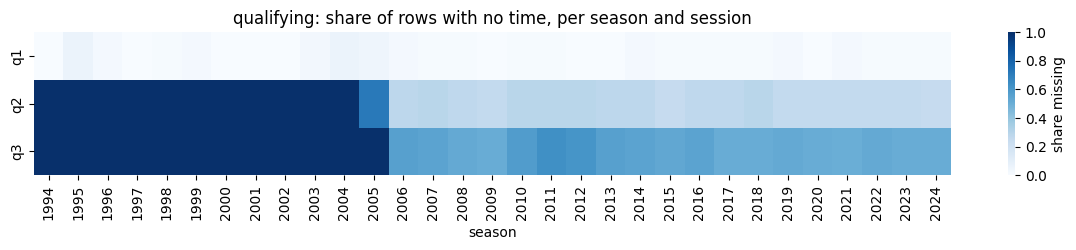

In [60]:
qq = qualifying.merge(raw_before['races'][['raceId', 'year', 'name']], on='raceId')

# share missing per year (0.00 = complete, 1.00 = all empty)
miss = qq.groupby('year')[['q1', 'q2', 'q3']].apply(lambda d: d.isna().mean().round(2))
miss.insert(0, 'rows', qq.groupby('year').size())
with pd.option_context('display.max_rows', None):
    display(miss)

# picture: the same shares as a heatmap (dark = all times missing)
plt.figure(figsize=(12, 2.6))
sns.heatmap(miss[['q1', 'q2', 'q3']].T, cmap='Blues', vmin=0, vmax=1, cbar_kws={'label': 'share missing'})
plt.title('qualifying: share of rows with no time, per season and session')
plt.xlabel('season')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [61]:
# does the missing pattern follow the knockout logic?
#    a q3 time should never exist without a q2 time, and q2 never without q1
print('q3 present but q2 missing:', (qq.q3.notna() & qq.q2.isna()).sum())
print('q2 present but q1 missing:', (qq.q2.notna() & qq.q1.isna()).sum())


q3 present but q2 missing: 0
q2 present but q1 missing: 0


### qualifying: summary of checks

**Coverage.** The table has 10,494 rows and starts in 1994, so races before 1994 have no qualifying data. Features built from it will be empty for those years.

**`position`.** The qualifying position is filled in every row and is already an integer, so it needs no cleaning. It is the one qualifying column we can use directly.

**What `position` does not capture.** It only gives the order. It does not say how far apart the drivers were. A driver in 3rd place could be 0.05 seconds or 1.5 seconds behind pole. For that we need the lap times.

**Lap times `q1`, `q2`, `q3`.** These were stored as text (`object`), not numbers.
- Every non-missing value follows one format, minutes:seconds.milliseconds (for example `1:23.456`), except one `q1` value with a two-digit minute (10 minutes or more), which we check separately.
- Missing values: `q1` 156, `q2` 4,647 and `q3` 6,865 rows. The missing `q2` and `q3` are consistent with the knockout format, where a driver eliminated in Q1 has no Q2 or Q3 time, and a driver eliminated in Q2 has no Q3 time. The heatmap shows this by season: up to 2004 every `q2` and `q3` is empty, so only one session is recorded, and from 2006 about a quarter of the `q2` times and half of the `q3` times are empty every season. We therefore do not fill them in, because an empty value carries information (the driver was eliminated).
- We converted all three columns to seconds (float) in new columns `q1_s`, `q2_s` and `q3_s`, and kept the original text. The non-missing counts are the same before and after the conversion (10,338, 5,847 and 3,629).

**Plan for features.** Instead of using `q1_s`, `q2_s` and `q3_s` directly, we may build features from them, such as each driver's gap to the fastest driver in the same session, as a percentage of the fastest time so that tracks of different lengths are comparable, and the difference between `grid` and qualifying `position`. This is a plan, not yet a decision, and we will test it in the ablation yet to come.

In [62]:
# the 156 rows with no q1 time
no_q1 = qq.merge(raw_before['drivers'][['driverId', 'surname']], on='driverId')
no_q1 = no_q1[no_q1.q1.isna()]
print('\nno q1 by year:', no_q1.year.value_counts().sort_index().to_dict())
print('of those, rows that still have q2 or q3:', (no_q1.q2.notna() | no_q1.q3.notna()).sum())
display(no_q1[['year', 'name', 'surname', 'position', 'q1', 'q2', 'q3']].head(15))


no q1 by year: {1994: 1, 1995: 24, 1996: 3, 1997: 1, 1998: 2, 1999: 1, 2003: 11, 2004: 21, 2005: 17, 2006: 8, 2007: 2, 2008: 2, 2009: 1, 2010: 4, 2011: 5, 2013: 2, 2014: 7, 2015: 3, 2016: 3, 2017: 2, 2018: 6, 2019: 9, 2020: 1, 2021: 7, 2022: 4, 2023: 5, 2024: 4}
of those, rows that still have q2 or q3: 0


,year,name,surname,position,q1,q2,q3
147,2008,Canadian Grand Prix,Vettel,20,NaN,NaN,NaN
307,2008,Singapore Grand Prix,Fisichella,20,NaN,NaN,NaN
455,2007,Spanish Grand Prix,Speed,22,NaN,NaN,NaN
477,2007,Monaco Grand Prix,Albers,22,NaN,NaN,NaN
763,2006,Bahrain Grand Prix,Räikkönen,22,NaN,NaN,NaN
873,2006,Spanish Grand Prix,Coulthard,22,NaN,NaN,NaN
894,2006,Monaco Grand Prix,Massa,21,NaN,NaN,NaN
895,2006,Monaco Grand Prix,Schumacher,22,NaN,NaN,NaN
917,2006,British Grand Prix,Trulli,22,NaN,NaN,NaN
1005,2006,German Grand Prix,Speed,22,NaN,NaN,NaN


In [63]:
# the one odd q1 value with a two-digit minute
display(qq[qq.q1.str.len() > 8])

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3,q1_s,q2_s,q3_s,year,name
2567,2569,255,87,1,7,24,16:42.640,NaN,NaN,1002.64,NaN,NaN,1995,Japanese Grand Prix


In [64]:
rid = qualifying.loc[qualifying.q1.str.len() > 8, 'raceId'].iloc[0]
display(qualifying[qualifying.raceId == rid].sort_values('position')[['position', 'q1', 'q1_s']])

,position,q1,q1_s
2544,1,1:38.023,98.023
2545,2,1:38.888,98.888
2546,3,1:38.954,98.954
2547,4,1:39.032,99.032
2548,5,1:39.040,99.040
2549,6,1:39.155,99.155
2550,7,1:39.621,99.621
2551,8,1:40.010,100.010
2552,9,1:40.349,100.349
2553,10,1:40.381,100.381


In [65]:
# before: count of real q1 times and the max (should show the ~1003s outlier)
print('q1_s non-missing before:', qualifying.q1_s.notna().sum(), '| max:', qualifying.q1_s.max())

# set the one outlier to missing: a real F1 lap is ~55-150s, so anything over 250s is not a real time
qualifying.loc[qualifying.q1_s > 250, 'q1_s'] = np.nan

# after: one fewer non-missing, and the max is now a plausible lap
print('q1_s non-missing after: ', qualifying.q1_s.notna().sum(), '| max:', qualifying.q1_s.max())

q1_s non-missing before: 10338 | max: 1002.64
q1_s non-missing after:  10337 | max: 153.885


**Missing `q1` (no time in any session).** 156 rows (1.5%) have no `q1`, `q2` or `q3` time. What we found:
- They never have a later time either, meaning every one of the 156 is missing all three sessions (0 rows have a `q2` or `q3` time without `q1`). So these are entries with no recorded lap at all, not a gap in one session.
- They span 1994 to 2024, concentrated in 1995 (24), 2004 (21), 2005 (17) and 2003 (11), and in single figures in most other years.
- In the rows inspected, the driver sits at the back of the qualifying order (`position` 19 to 22). So `position` is filled even with no lap time, which means it is not derived from the times alone.
- The data gives no reason for the missing time (no status column in this table). We therefore do not guess a cause.

We keep these rows, because `position` is valid. In the table their `q1_s`, `q2_s` and `q3_s` stay missing. If we build features from the times (such as the gap to the fastest driver), these rows will need to be filled, and a `no_quali_time` flag (1 where the time was missing, 0 otherwise) may help the model separate a filled-in value from a real one. The fill value, and whether to add the flag, are decided at the feature step, not here.

**Outlier.** One `q1` value (1995 Japanese Grand Prix) is `16:42.640`, about 1,003 seconds, roughly ten times a normal lap. We keep the original text and set its `q1_s` to missing, which puts it in the same group as the rows above, where if the times are used, it will be filled (and possibly flagged) at the feature step.

In [66]:
# the entries with no Q1 time: did they race, and how did they finish?
nt = (qq[qq.q1.isna()]
      .merge(results_unique[['raceId', 'driverId', 'grid', 'positionOrder', 'never_ran']],
             on=['raceId', 'driverId'], how='left', validate='1:1')
      .merge(raw_before['drivers'][['driverId', 'surname']], on='driverId'))
started = nt[~nt.never_ran]
print('entries with no Q1 time:', len(nt), '| started the race:', len(started), '| did not start:', int(nt.never_ran.sum()))
print('of those who started: podiums', int((started.positionOrder <= 3).sum()), '| best finish', int(started.positionOrder.min()),
      '| qualifying position: median', int(started.position.median()), ', range', int(started.position.min()), 'to', int(started.position.max()))
print('1995 entries with no Q1 time:', int((nt.year == 1995).sum()), '| their qualifying positions:',
      int(nt[nt.year == 1995].position.min()), 'to', int(nt[nt.year == 1995].position.max()))
display(started[started.positionOrder <= 3].sort_values('year')[['year', 'name', 'surname', 'position', 'grid', 'positionOrder']]
        .rename(columns={'position': 'qualifying position', 'positionOrder': 'finished'}))

entries with no Q1 time: 156 | started the race: 151 | did not start: 5
of those who started: podiums 10 | best finish 1 | qualifying position: median 20 , range 1 to 24
1995 entries with no Q1 time: 24 | their qualifying positions: 1 to 24


,year,name,surname,qualifying position,grid,finished
32,1995,Australian Grand Prix,Hill,1,1,1
43,1995,Australian Grand Prix,Panis,12,12,2
44,1995,Australian Grand Prix,Morbidelli,13,13,3
12,2005,Canadian Grand Prix,Barrichello,20,20,3
14,2005,German Grand Prix,Pablo Montoya,19,20,2
4,2006,Bahrain Grand Prix,Räikkönen,22,22,3
108,2014,Hungarian Grand Prix,Hamilton,21,22,3
127,2019,German Grand Prix,Vettel,20,20,2
133,2019,Brazilian Grand Prix,Sainz,20,20,3
141,2021,Russian Grand Prix,Verstappen,20,20,2


**What happened to them in the race.** Joining these entries with `results` shows they are not all slow drivers at the back:
- 151 of the 156 started the race and 5 did not. The drivers who started usually started near the back (median qualifying position 20), but their qualifying positions run from 1 to 24.
- 10 of them reached the podium, for example Montoya at the 2005 German Grand Prix (qualified 19th, finished 2nd), Vettel at the 2019 German Grand Prix (20th, 2nd) and Verstappen at the 2021 Russian Grand Prix (20th, 2nd).
- 24 of the 156 are the whole field of the 1995 Australian Grand Prix: every driver has a qualifying position, from 1 (Hill, who also won the race) to 24, but none has a time. For this race the times are missing from the table, while the order is recorded.

**Consequence for features.** A missing Q1 time does not mean a slow car. A feature built from the times (such as the gap to the fastest lap) must not treat a missing time as a slow one; the qualifying position, which is never missing, still places these drivers.

In [67]:
# qualifying: keys and converted times
assert qualifying.qualifyId.is_unique, 'qualifyId not unique'
assert not qualifying.duplicated(['raceId', 'driverId']).any(), 'duplicate driver per race in qualifying'
assert qualifying.position.notna().all(), 'qualifying position has nulls'

## `Seasons Table`

In [68]:
seasons = load('seasons')
print('shape:', seasons.shape)

shape: (75, 2)


In [69]:
display(seasons.head())

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


In [70]:
print(seasons.dtypes)

year     int64
url     object
dtype: object


In [71]:
print('\nmissing per column:')
print(seasons.isna().sum())


missing per column:
year    0
url     0
dtype: int64


In [72]:
races = load('races')

# primary key
print('year: nulls =', seasons.year.isna().sum(), '| duplicates =', seasons.year.duplicated().sum())

# coverage: every year 1950-2024, no gaps
print('years 1950-2024 all present:', sorted(seasons.year) == list(range(1950, 2025)))
print('min / max year:', seasons.year.min(), '/', seasons.year.max())

# foreign key both ways with races
print('race years missing from seasons:', set(races.year) - set(seasons.year))
print('seasons without any race:', set(seasons.year) - set(races.year))

# races per season
per = races.groupby('year').size()
print('races per season: min', per.min(), '| max', per.max())

# url: unique, and what the links look like
print('url unique:', seasons.url.is_unique)
print('url all wikipedia:', seasons.url.str.contains('wikipedia').all())
print('url all follow the pattern .../<year>_Formula_One_season:',
      seasons.apply(lambda r: str(r.year) in r.url, axis=1).all())

year: nulls = 0 | duplicates = 0
years 1950-2024 all present: True
min / max year: 1950 / 2024
race years missing from seasons: set()
seasons without any race: set()
races per season: min 7 | max 24
url unique: True
url all wikipedia: True
url all follow the pattern .../<year>_Formula_One_season: True


### seasons: summary of checks

**What it is.** A reference list with one row per championship season. It has 75 rows and 2 columns: `year` and `url` (the Wikipedia page of that season). It holds no race results or points, so it is not a source of features. Its role is to be the parent table that `races` points to.

**Types and missing values.** Loaded with `na_values=['\\N']`, `year` is already an integer (`int64`) and `url` is text. Neither column has a missing value (0 and 0), so there is nothing to clean or fill.

**Order.** In the rows inspected, the table runs from 2009 downward, so it is not in chronological order. We never rely on row order and sort by `year` when order matters.

**Key checks.**

| Check | Result |
|---|---|
| Primary key `year` | 0 nulls, 0 duplicates ✓ |
| Coverage | every year from 1950 to 2024 is present, no gaps ✓ |
| Foreign key `races.year` → `seasons.year` | 0 race years missing from `seasons` ✓ |
| Reverse check | 0 seasons without a race ✓ |
| `url` | unique, every link is a Wikipedia page, and each link contains its own year ✓ |

**Season length.** Seasons have between 7 and 24 races. Raw counts per season (races, points, wins) are therefore not comparable across years, so any season-level feature must be a rate or a share, not a total.

**Cleaning decision.** None needed. We keep the table as loaded. `url` is a label only and is not used as a feature.

## `Races Table`

In [73]:
races = load('races')

print('shape:', races.shape)

shape: (1125, 18)


In [74]:
display(races.head())

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [75]:
print('\nmissing per column:')
print(races.isna().sum())


missing per column:
raceId            0
year              0
round             0
circuitId         0
name              0
date              0
time            731
url               0
fp1_date       1035
fp1_time       1057
fp2_date       1035
fp2_time       1057
fp3_date       1053
fp3_time       1072
quali_date     1035
quali_time     1057
sprint_date    1107
sprint_time    1110
dtype: int64


In [76]:
print(races.dtypes)

raceId          int64
year            int64
round           int64
circuitId       int64
name           object
date           object
time           object
url            object
fp1_date       object
fp1_time       object
fp2_date       object
fp2_time       object
fp3_date       object
fp3_time       object
quali_date     object
quali_time     object
sprint_date    object
sprint_time    object
dtype: object


In [77]:
date_cols = ['date'] + [c for c in races.columns if c.endswith('_date')]
time_cols = ['time'] + [c for c in races.columns if c.endswith('_time')]

for c in date_cols + time_cols:
    pat = races[c].dropna().str.replace(r'\d', '9', regex=True)
    print(c, pat.value_counts().to_dict())

date {'9999-99-99': 1125}
fp1_date {'9999-99-99': 90}
fp2_date {'9999-99-99': 90}
fp3_date {'9999-99-99': 72}
quali_date {'9999-99-99': 90}
sprint_date {'9999-99-99': 18}
time {'99:99:99': 394}
fp1_time {'99:99:99': 68}
fp2_time {'99:99:99': 68}
fp3_time {'99:99:99': 53}
quali_time {'99:99:99': 68}
sprint_time {'99:99:99': 15}


,dtype_before,dtype_after,filled_before,filled_after,same_count
date,object,datetime64[ns],1125,1125,True
fp1_date,object,datetime64[ns],90,90,True
fp2_date,object,datetime64[ns],90,90,True
fp3_date,object,datetime64[ns],72,72,True
quali_date,object,datetime64[ns],90,90,True
sprint_date,object,datetime64[ns],18,18,True


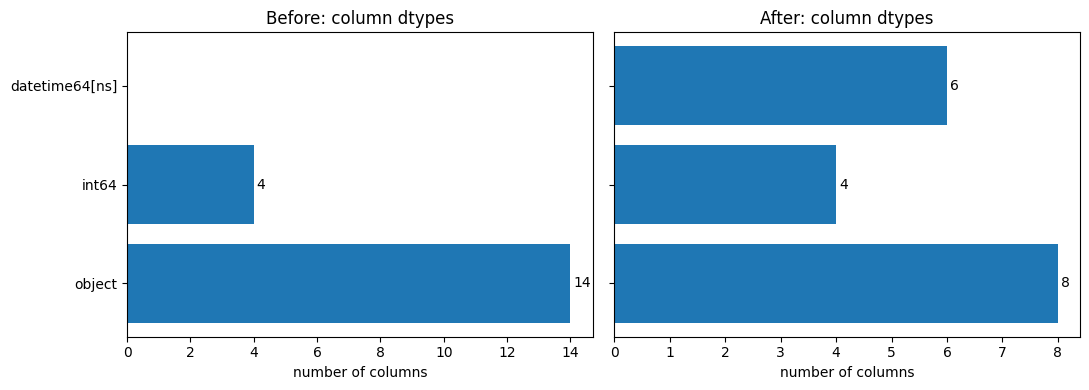

                   min        max
date        1950-05-13 2024-12-08
fp1_date    2021-03-26 2024-12-06
fp2_date    2021-03-26 2024-12-06
fp3_date    2021-03-27 2024-12-07
quali_date  2021-03-27 2024-12-07
sprint_date 2021-07-17 2024-11-30


In [78]:
races_raw = races.copy()   # before: text dates

date_cols = ['date', 'fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date']
for c in date_cols:
    races[c] = pd.to_datetime(races[c], format='%Y-%m-%d')

# before vs after: dtype and non-missing count must not change
cmp = pd.DataFrame({
    'dtype_before':  races_raw[date_cols].dtypes.astype(str),
    'dtype_after':   races[date_cols].dtypes.astype(str),
    'filled_before': races_raw[date_cols].notna().sum(),
    'filled_after':  races[date_cols].notna().sum(),
})
cmp['same_count'] = cmp.filled_before == cmp.filled_after
display(cmp)

# visual: dtype per column, before vs after
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, df, title in [(axes[0], races_raw, 'Before'), (axes[1], races, 'After')]:
    counts = df.dtypes.astype(str).value_counts()
    bars = ax.barh(counts.index, counts.values)
    ax.bar_label(bars, padding=2)
    ax.set_title(f'{title}: column dtypes')
    ax.set_xlabel('number of columns')
plt.tight_layout()
plt.show()

print(races[date_cols].agg(['min', 'max']).T)

In [79]:
# primary key: raceId
print('raceId nulls:      ', races.raceId.isna().sum())
print('raceId duplicates: ', races.raceId.duplicated().sum())

# natural key: (year, round)
print('(year, round) duplicates:', races.duplicated(['year', 'round']).sum())

print('date duplicates:', races.duplicated(['date']).sum())

# does each date fall in its season?
print('date.year != year:       ', (races.date.dt.year != races.year).sum())

# does (year, round) order match date order?
by_round = races.sort_values(['year', 'round'])
print('dates in (year, round) order are increasing:', by_round.date.is_monotonic_increasing)

# and does raceId order match date order?
by_id = races.sort_values('raceId')
print('dates in raceId order are increasing:       ', by_id.date.is_monotonic_increasing)

# rounds run 1..n in every season with no gaps
g = races.groupby('year')['round'].agg(['min', 'max', 'count'])
print('seasons where rounds are not 1..n:', ((g['min'] != 1) | (g['max'] != g['count'])).sum())

# foreign keys and links to other tables
res_raw = raw_before['results']
sprint_raw = raw_before['sprint_results']
seasons_raw = raw_before['seasons']
circuits_raw = raw_before['circuits']

print('circuitId nulls:                      ', races.circuitId.isna().sum())
print('circuitId not found in circuits:      ', (~races.circuitId.isin(circuits_raw.circuitId)).sum())
print('races with no result rows:            ', (~races.raceId.isin(res_raw.raceId)).sum())
print('result rows with unknown raceId:      ', (~res_raw.raceId.isin(races.raceId)).sum())
print('season years differing (set() = none):', set(races.year) ^ set(seasons_raw.year))

sprint_ids = set(races.loc[races.sprint_date.notna(), 'raceId'])
print('races in sprint_results:              ', sprint_raw.raceId.nunique())
print('matches the sprint weekends:          ', set(sprint_raw.raceId) == sprint_ids)

raceId nulls:      

 0
raceId duplicates:  0
(year, round) duplicates: 0
date duplicates: 0
date.year != year:        0
dates in (year, round) order are increasing: True
dates in raceId order are increasing:        False
seasons where rounds are not 1..n: 0
circuitId nulls:                       0
circuitId not found in circuits:       0
races with no result rows:             0
result rows with unknown raceId:       0
season years differing (set() = none): set()
races in sprint_results:               18
matches the sprint weekends:           True


### races: data types and keys

**Format check.** Every date column has one pattern (`YYYY-MM-DD`) and every time column has one pattern (`HH:MM:SS`). No stray formats, so nothing needs cleaning in the text itself.

**What was fixed.** Six columns were stored as text (`object`) and are now real dates (`datetime64[ns]`): `date`, `fp1_date`, `fp2_date`, `fp3_date`, `quali_date`, `sprint_date`. The IDs (`raceId`, `year`, `round`, `circuitId`) were already `int64`. `name` and `url` are text, which is correct.

**Check.** Non-missing counts are identical before and after for all six columns, so the conversion lost nothing. The format was given explicitly, so a bad value would have raised an error and not turned silently into a missing value.

**Time columns left as text.** A time of day alone has no date. We combine them with the date into a timestamp only if a feature needs it.

**Date ranges after conversion.**
- `date`: 1950-05-13 to 2024-12-08, the full range of the dataset.
- All session dates start in 2021 and end in 2024. Nothing before 2021 has session dates.
- The first sprint date is 2021-07-17, in line with the sprint format being introduced in 2021.

**Primary key.** `raceId` has 0 nulls and 0 duplicates, so it is a valid primary key.

**Natural keys.** `(year, round)` is unique, and `date` is unique too (0 duplicates), so every race has its own date and either one gives a tie-free ordering. Rounds run 1 to n in every season with no gaps.

**Date vs season.** Every `date` falls in the season given by `year`, and sorting by `(year, round)` gives increasing dates, so the two orderings agree.

**Do not order by `raceId`.** In `raceId` order the dates do not increase (the first rows are 2009 races), so `raceId` is an identifier and not a timeline.

**How we use them.** We can use `date` for ordering races (it is unique and always increasing), and `year` and `round` for season structure (which season, which race of it). They both give the same order and are valid. Never use `raceId` for ordering.

**Foreign keys and links to other tables.** `circuitId` has 0 nulls and 0 orphans against `circuits`. Every race has result rows and every result row points to a known race, so the link in both directions is complete. Every season year in `races` exists in `seasons` and the other way round. The 18 races with a sprint date are exactly the races in `sprint_results`, so the sprint table lines up with the schedule.

**Why this matters.** Real dates allow date arithmetic (days since a driver's last race, month of the race), and the ordering rule above is what keeps rolling features from looking at the future.

**Next.** Why the session and time columns are missing, and what each gap means.

In [80]:
mask = races.isna()

coverage = pd.DataFrame({
    'n_missing': mask.sum(),
    'pct_missing': (mask.mean() * 100).round(1),
    'first_year_with_value': {c: races.loc[~mask[c], 'year'].min() for c in races.columns},
    'last_year_missing': {c: races.loc[mask[c], 'year'].max() for c in races.columns},
})
coverage

,n_missing,pct_missing,first_year_with_value,last_year_missing
raceId,0,0.0,1950,NaN
year,0,0.0,1950,NaN
round,0,0.0,1950,NaN
circuitId,0,0.0,1950,NaN
name,0,0.0,1950,NaN
date,0,0.0,1950,NaN
time,731,65.0,2005,2004.0
url,0,0.0,1950,NaN
fp1_date,1035,92.0,2021,2020.0
fp1_time,1057,94.0,2022,2021.0


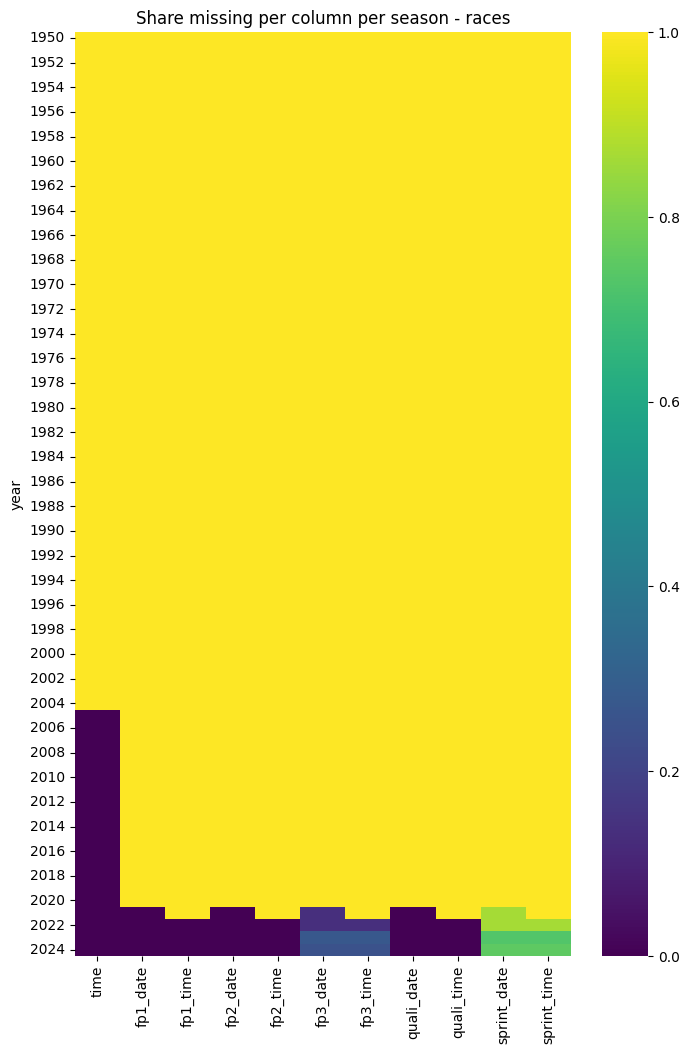

In [81]:
gap_cols = [c for c in races.columns if mask[c].any()]
share = mask[gap_cols].groupby(races.year).mean()
plt.figure(figsize=(8, 12))
sns.heatmap(share, cmap='viridis')
plt.title('Share missing per column per season - races')
plt.show()

In [82]:
# why 2021 has dates but no times
pairs = [('fp1_date', 'fp1_time'), ('quali_date', 'quali_time'),
         ('fp3_date', 'fp3_time'), ('sprint_date', 'sprint_time')]

for d, t in pairs:
    m = races[d].notna() & races[t].isna()
    print(d, '| date filled, time missing:', m.sum(), '| years:', sorted(races.loc[m, 'year'].unique()))

fp1_date | date filled, time missing: 22 | years: [np.int64(2021)]
quali_date | date filled, time missing: 22 | years: [np.int64(2021)]
fp3_date | date filled, time missing: 19 | years: [np.int64(2021)]
sprint_date | date filled, time missing: 3 | years: [np.int64(2021)]


In [83]:
# why fp3_* is still partly empty after 2021
recent = races[races.year >= 2021]
print(pd.crosstab(recent.fp3_date.isna().rename('fp3_missing'),
                  recent.sprint_date.notna().rename('has_sprint')))

has_sprint   False  True 
fp3_missing              
False           72      0
True             0     18


In [84]:
q = races[races.quali_date.notna()].copy()
q['gap'] = (q.date - q.quali_date).dt.days
q['sprint'] = q.sprint_date.notna()

print(q.gap.value_counts().sort_index())
print(pd.crosstab(q.gap, q.sprint, rownames=['days quali -> race'], colnames=['sprint weekend']))

# the exceptions: sprint with 1-day gap, or normal weekend with 2-day gap
display(q[(q.sprint & (q.gap == 1)) | (~q.sprint & (q.gap == 2))]
        [['year', 'round', 'name', 'quali_date', 'sprint_date', 'date', 'gap']])

display(races.loc[(races.year == 2023) & races.name.str.contains('Las Vegas'),
                  ['name', 'quali_date', 'quali_time', 'date', 'time']])

gap
1    77
2    13
Name: count, dtype: int64
sprint weekend      False  True 
days quali -> race              
1                      71      6
2                       1     12


,year,round,name,quali_date,sprint_date,date,gap
1099,2023,21,Las Vegas Grand Prix,2023-11-17,NaT,2023-11-19,2
1105,2024,5,Chinese Grand Prix,2024-04-20,2024-04-20,2024-04-21,1
1106,2024,6,Miami Grand Prix,2024-05-04,2024-05-04,2024-05-05,1
1111,2024,11,Austrian Grand Prix,2024-06-29,2024-06-29,2024-06-30,1
1119,2024,19,United States Grand Prix,2024-10-19,2024-10-19,2024-10-20,1
1121,2024,21,São Paulo Grand Prix,2024-11-02,2024-11-02,2024-11-03,1
1123,2024,23,Qatar Grand Prix,2024-11-30,2024-11-30,2024-12-01,1


,name,quali_date,quali_time,date,time
1099,Las Vegas Grand Prix,2023-11-17,08:00:00,2023-11-19,06:00:00


### races: missing values

**Complete columns.** `raceId`, `year`, `round`, `circuitId`, `name`, `date`, `url` have no missing values.

**Missingness follows eras, not chance.**
- `time` (race start time) is missing for 731 of 1,125 races (65%): empty up to 2004, recorded from 2005.
- Practice and qualifying dates are recorded from 2021 (1,035 missing, 92%). Their times are recorded from 2022 (1,057 missing, 94%), so 2021 has dates but no times.
- `fp3_*` and `sprint_*` stay partly empty after 2021: FP3 is missing on exactly the 18 sprint weekends and nowhere else, and sprint columns exist only on those 18 weekends.
- Every other column has a clean cut-off: its last missing season comes right before its first recorded season.

**Two meanings of missing.** *Not recorded* (sessions before 2021, race start times before 2005) is genuinely missing data. *Did not exist* (no FP3 on a sprint weekend, no sprint on a normal weekend) is a real answer and must not be imputed.

**What the columns hold.** The `fp*`, `quali_*` and `sprint_*` columns only record when each session was scheduled. Practice results are not in the dataset, and qualifying results are in the `qualifying` table. Where a qualifying date exists, it is always 1 or 2 days before the race, so using qualifying information at prediction time is allowed.

**Decision.** These columns only exist from 2021, so any training window that ends before 2021 sees them completely empty, and a model cannot learn from an empty column. They are not used as features. Columns that could be carried into the modelling table are `raceId`, `year`, `round`, `circuitId`, `name`, `date`. `time` and `url` are kept for reference only.

**One caveat.** In 2021-2022 the sprint result set the Sunday grid (per the F1 background document), so on those weekends `grid` differs from qualifying position for a reason other than penalties. This only matters if the training window reaches 2021.

count    75.000000
mean     15.000000
std       4.197812
min       7.000000
25%      11.000000
50%      16.000000
75%      17.000000
max      24.000000
dtype: float64

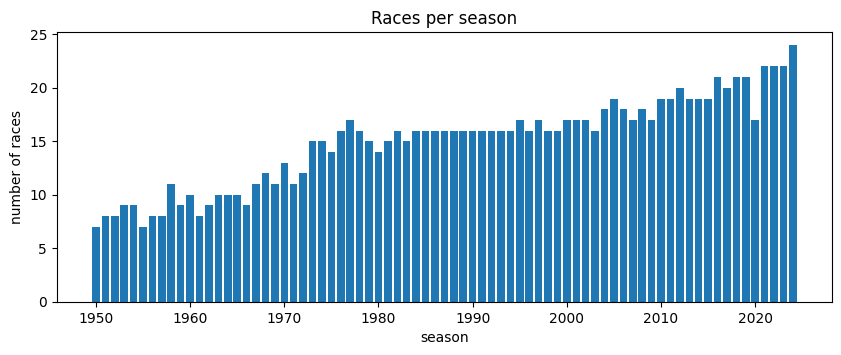

In [85]:
per_season = races.groupby('year').size()
display(per_season.describe())

plt.figure(figsize=(10, 3.5))
plt.bar(per_season.index, per_season.values)
plt.xlabel('season')
plt.ylabel('number of races')
plt.title('Races per season')
plt.show()

In [86]:
per_season = races.groupby('year').size()
by_decade = per_season.groupby(per_season.index // 10 * 10).agg(['min', 'max', 'mean'])
print(by_decade.round(1))
print('fewest races in a season:', per_season.idxmin(), per_season.min())
print('most races in a season:  ', per_season.idxmax(), per_season.max())


      min  max  mean
year                
1950    7   11   8.4
1960    8   12  10.0
1970   11   17  14.4
1980   14   16  15.6
1990   16   17  16.2
2000   16   19  17.4
2010   19   21  19.8
2020   17   24  21.4
fewest races in a season: 1950 7
most races in a season:   2024 24


### races: the calendar over the eras

**Races per season.** The calendar grew steadily. The average was 8.4 races per season in the 1950s, 14 to 16 in the 1970s and 1980s, 17 in the 2000s, 20 in the 2010s and 21 in the 2020s. The shortest season has 7 races (1950) and the longest has 24 (2024).

**Consequence for features.** Season totals are not comparable across eras, so we convert them to rates, such as points per race or share of the points available. Rolling features over the last N races are not affected.


### Indianapolis 500: what the data shows

In [87]:
indy = races[races.name.str.contains('Indianapolis', case=False)]
display(indy[['raceId', 'year', 'round', 'circuitId', 'name']])

print('races at the Indianapolis circuit:', (races.circuitId == indy.circuitId.mode()[0]).sum())
print('of those, named Indianapolis 500:  ', len(indy))


,raceId,year,round,circuitId,name
747,748,1960,3,19,Indianapolis 500
756,757,1959,2,19,Indianapolis 500
767,768,1958,4,19,Indianapolis 500
777,778,1957,3,19,Indianapolis 500
785,786,1956,3,19,Indianapolis 500
793,794,1955,3,19,Indianapolis 500
799,800,1954,2,19,Indianapolis 500
808,809,1953,2,19,Indianapolis 500
817,818,1952,2,19,Indianapolis 500
825,826,1951,2,19,Indianapolis 500


races at the Indianapolis circuit: 19
of those, named Indianapolis 500:   11


In [88]:
indy_ids = indy.raceId
print('races on circuitId 19:', (races.circuitId == 19).sum(), '| named Indianapolis 500:', len(indy))
print(races.loc[races.circuitId == 19, ['year', 'name']].query('name != "Indianapolis 500"'))

r = results_unique[results_unique.raceId.isin(indy_ids)].merge(races[['raceId', 'year']], on='raceId')

# how many drivers raced there, and how many of them raced anywhere else in F1
indy_drivers = set(r.driverId)
other = results_unique[~results_unique.raceId.isin(indy_ids)]
only_indy = indy_drivers - set(other.driverId)
print('drivers in Indy 500:', len(indy_drivers), '| who never raced a non-Indy F1 race:', len(only_indy))

# share of Indy rows held by drivers who only ever raced there
print('share of Indy result rows from Indy-only drivers:', round(r.driverId.isin(only_indy).mean(), 2))

# field size per race and statuses, to compare with normal races of the same years
print(r.groupby('year').size().rename('Indy field size'))
print(r.merge(raw_before['status'], on='statusId').status.value_counts().head(8))


races on circuitId 19: 19 | named Indianapolis 500: 11
     year                      name
41   2007  United States Grand Prix
61   2006  United States Grand Prix
78   2005  United States Grand Prix
97   2004  United States Grand Prix
121  2003  United States Grand Prix
138  2002  United States Grand Prix
155  2001  United States Grand Prix
171  2000  United States Grand Prix
drivers in Indy 500: 107 | who never raced a non-Indy F1 race: 103
share of Indy result rows from Indy-only drivers: 0.95
year
1950    34
1951    34
1952    33
1953    37
1954    42
1955    35
1956    34
1957    33
1958    33
1959    33
1960    33
Name: Indy field size, dtype: int64
status
Finished        124
Accident         43
Engine           23
Magneto          14
Spun off         12
+4 Laps          11
Oil leak         11
Transmission     10
Name: count, dtype: int64


### Indianapolis 500: decision

**What it is.** Eleven races in the table are named "Indianapolis 500", one per season from 1950 to 1960. The race counted for the world championship in those years but was run to different rules from the rest of the calendar.

**How to identify it.** We identify it by race name and not by circuit. The same circuit (`circuitId` 19) also hosted 8 races named "United States Grand Prix" between 2000 and 2007, which are normal Formula 1 races and must stay in.

**How it differs.** 107 drivers started the Indianapolis 500, and 103 of them never started any other Formula 1 race, so 95% of its result rows belong to drivers who appear nowhere else. The field was 33 to 42 cars, which is a different grid structure from the other races of the time.

**Effect on the questions.** It would distort the home-country question, because American drivers racing at Indianapolis would count as home races. For the circuit question it would add a circuit with 11 races in the old era only. The 2014 to 2024 mechanical-retirement question does not touch it.

**Decision.** We keep the 11 rows in the cleaned table and flag them, and we exclude them from the modelling table and from the home-country question. Every answer states whether it kept or excluded them.


In [89]:
indy_500_ids = races.loc[races.name == 'Indianapolis 500', 'raceId']
results_unique['is_indy500'] = results_unique.raceId.isin(indy_500_ids)
print(results_unique.is_indy500.sum(), 'result rows flagged')

381 result rows flagged


**Why we exclude them from the modelling table.** The Indianapolis 500 races follow different rules from the rest of the championship, and the data shows it. 103 of the 107 drivers who started them never started any other Formula 1 race, so 95% of their result rows come from drivers with no history anywhere else, and the history features we plan to build would be empty or meaningless for them. The fields were also much larger, 33 to 42 cars, so a grid position does not mean the same thing as in a normal race. All 11 races are from 1950 to 1960, which is far from the races we want to predict.

**Effect on the modelling table.** Excluding them removes 381 rows, about 1.4% of the 26,668 rows, and 11 of the 1,125 races. The 8 United States Grand Prix races held at the same circuit between 2000 and 2007 stay in, because we filter by race name and not by circuit. The rows are flagged with `is_indy500` in the cleaned table and removed only when the modelling table is built, after the history features, so no other driver's features are affected.


## `Circuits Table`

In [90]:
circuits = load('circuits')

print('shape:', circuits.shape)

shape: (77, 9)


In [91]:
display(circuits.head())

,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


In [92]:
print(circuits.dtypes)

circuitId       int64
circuitRef     object
name           object
location       object
country        object
lat           float64
lng           float64
alt             int64
url            object
dtype: object


In [93]:
print('\nmissing per column:')
print(circuits.isna().sum())


missing per column:
circuitId     0
circuitRef    0
name          0
location      0
country       0
lat           0
lng           0
alt           0
url           0
dtype: int64


In [94]:
# primary key
print('circuitId nulls:     ', circuits.circuitId.isna().sum())
print('circuitId duplicates:', circuits.circuitId.duplicated().sum())

# other columns that should also be unique
print('circuitRef duplicates:', circuits.circuitRef.duplicated().sum())
print('name duplicates:      ', circuits.name.duplicated().sum())

# value ranges
print(circuits[['lat', 'lng', 'alt']].describe())
print('lat outside -90..90:  ', (~circuits.lat.between(-90, 90)).sum())
print('lng outside -180..180:', (~circuits.lng.between(-180, 180)).sum())
print('alt <= 0:             ', (circuits.alt <= 0).sum())

# countries
print(circuits.country.value_counts())

# does every circuit get used?
print('circuits with no race:', (~circuits.circuitId.isin(races.circuitId)).sum())

circuitId nulls:      0
circuitId duplicates: 0
circuitRef duplicates: 0
name duplicates:       0
             lat         lng          alt
count  77.000000   77.000000    77.000000
mean   33.442925    1.076683   247.012987
std    22.808866   65.516951   362.738469
min   -37.849700 -118.189000    -7.000000
25%    32.777400   -9.394170    18.000000
50%    40.951700    3.930830   129.000000
75%    46.958900   19.248600   332.000000
max    57.265300  144.968000  2227.000000
lat outside -90..90:   0
lng outside -180..180: 0
alt <= 0:              3
country
USA              11
France            7
Spain             6
Italy             4
Portugal          4
UK                4
Germany           3
Belgium           3
Canada            3
Japan             3
Australia         2
Austria           2
Brazil            2
South Africa      2
Malaysia          1
Bahrain           1
Hungary           1
Turkey            1
Monaco            1
United States     1
China             1
Singapore         1
A

In [95]:
print(circuits.loc[circuits.alt <= 0, ['circuitRef', 'country', 'alt']])
print(circuits.loc[circuits.country == 'United States', ['circuitRef', 'name', 'location', 'country']])

   circuitRef     country  alt
34    yeongam       Korea    0
71       baku  Azerbaijan   -7
76      miami         USA    0
   circuitRef                            name   location        country
22      vegas  Las Vegas Strip Street Circuit  Las Vegas  United States


### circuits: keys and checks

**Grain.** One row is one physical track, 77 rows and 9 columns. `circuitId` is the identifier, `circuitRef` is a short text code, and `country` and `location` say where the track is.

**Types and missing values.** The IDs and `alt` are integers, the coordinates are floats and the rest is text, so nothing needed converting. No column has missing values, and loading with `\N` as missing found none to convert.

**Primary key.** `circuitId` has 0 nulls and 0 duplicates, so it is a valid primary key. `circuitRef` and `name` are also unique.

**Foreign keys.** The table has no foreign keys of its own, because other tables point to it. The link from `races.circuitId` was checked in the races section with 0 orphans, and all 77 circuits are used by at least one race.

**Ranges.** Latitude and longitude are inside their valid ranges. Altitude runs from -7 m to 2,227 m. Three circuits are at or below 0 m, which are Baku at -7 m, which is real since the track is below sea level, and Yeongam and Miami at 0 m, which are plausible for coastal tracks. Altitude is not used as a feature.

**Country spelling.** `country` writes the United States two ways, `USA` for 11 circuits and `United States` for the Las Vegas Strip Street Circuit. Short forms such as `UK`, `UAE` and `Korea` also won't match driver nationalities directly. We make the spelling consistent on the cleaned copy in *circuits and drivers: countries and nationalities* (`United States` becomes `USA`); the CSV is not changed. The short forms are kept, and the nationality-to-country map in Q2 matches them to driver nationalities.

,circuitId,name,country,n_races,first,last
0,14,Autodromo Nazionale di Monza,Italy,74,1950,2024
1,6,Circuit de Monaco,Monaco,70,1950,2024
2,9,Silverstone Circuit,UK,59,1950,2024
3,13,Circuit de Spa-Francorchamps,Belgium,57,1950,2024
4,7,Circuit Gilles Villeneuve,Canada,43,1978,2024
5,18,Autódromo José Carlos Pace,Brazil,41,1973,2024
6,20,Nürburgring,Germany,41,1951,2020
7,11,Hungaroring,Hungary,39,1986,2024
8,70,Red Bull Ring,Austria,38,1970,2024
9,10,Hockenheimring,Germany,37,1970,2019


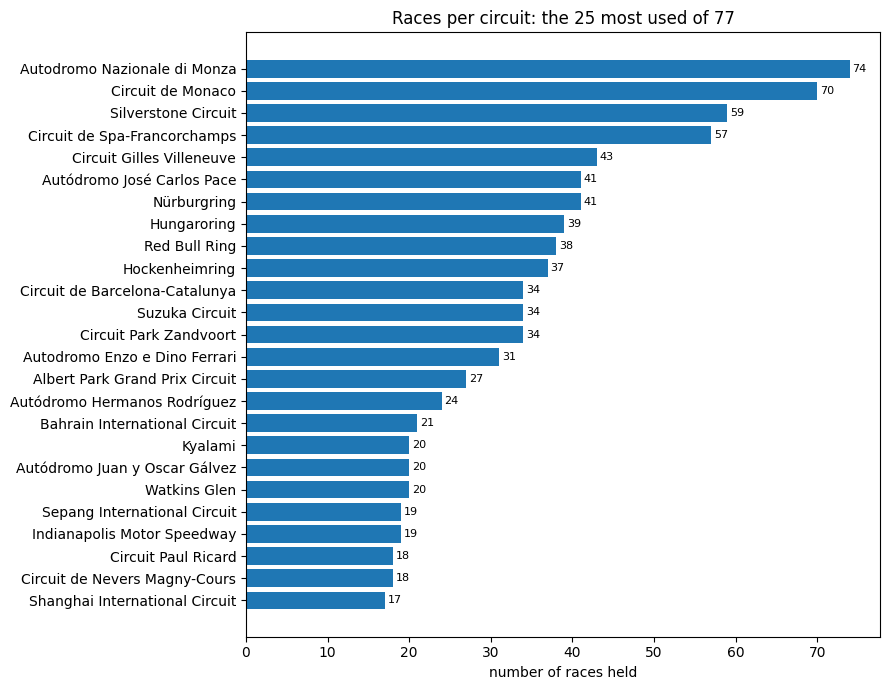

In [96]:
usage = (races.groupby('circuitId')
         .agg(n_races=('raceId', 'size'), first=('year', 'min'), last=('year', 'max')))
cu = (circuits.merge(usage, left_on='circuitId', right_index=True)
      .sort_values('n_races', ascending=False)
      [['circuitId', 'name', 'country', 'n_races', 'first', 'last']]
      .reset_index(drop=True))

with pd.option_context('display.max_rows', None):
    display(cu)

# picture: the 25 most used circuits (the full list is the table above)
top_cu = cu.head(25)[::-1]
plt.figure(figsize=(9, 7))
bars = plt.barh(top_cu.name, top_cu.n_races)
plt.bar_label(bars, padding=2, fontsize=8)
plt.xlabel('number of races held')
plt.title('Races per circuit: the 25 most used of 77')
plt.tight_layout()
plt.show()

In [97]:
# trap 1: a circuit hosting two races in one season
per_year_circuit = races.groupby(['year', 'circuitId']).size().reset_index(name='n_races')
twice = per_year_circuit[per_year_circuit.n_races > 1].merge(circuits[['circuitId', 'name']], on='circuitId')
print('circuit-seasons with more than one race:', len(twice))
display(twice)

# trap 2: a circuit with more than one Grand Prix name
names = (races.groupby('circuitId').name
         .agg(n_names='nunique', gp_names=lambda s: sorted(s.unique())))
multi = names[names.n_names > 1].merge(circuits[['circuitId', 'name']], left_index=True, right_on='circuitId')
print('circuits with more than one GP name:', len(multi))
display(multi.sort_values('n_names', ascending=False)[['name', 'n_names', 'gp_names']])


circuit-seasons with more than one race: 4


,year,circuitId,n_races,name
0,2020,3,2,Bahrain International Circuit
1,2020,9,2,Silverstone Circuit
2,2020,70,2,Red Bull Ring
3,2021,70,2,Red Bull Ring


circuits with more than one GP name: 12


,name,n_names,gp_names
19,Nürburgring,4,"[Eifel Grand Prix, European Grand Prix, German..."
20,Autodromo Enzo e Dino Ferrari,3,"[Emilia Romagna Grand Prix, Italian Grand Prix..."
2,Bahrain International Circuit,2,"[Bahrain Grand Prix, Sakhir Grand Prix]"
8,Silverstone Circuit,2,"[70th Anniversary Grand Prix, British Grand Prix]"
18,Indianapolis Motor Speedway,2,"[Indianapolis 500, United States Grand Prix]"
17,Autódromo José Carlos Pace,2,"[Brazilian Grand Prix, São Paulo Grand Prix]"
25,Circuito de Jerez,2,"[European Grand Prix, Spanish Grand Prix]"
31,Autódromo Hermanos Rodríguez,2,"[Mexican Grand Prix, Mexico City Grand Prix]"
37,Brands Hatch,2,"[British Grand Prix, European Grand Prix]"
40,Dijon-Prenois,2,"[French Grand Prix, Swiss Grand Prix]"


### circuits: usage over time

**How often each circuit was used.** The 77 circuits are very uneven. Half of them hosted 8 races or fewer, a quarter hosted 3 or fewer, and 11 hosted exactly one race. At the other end, Monza hosted 74 races, Monaco 70, Silverstone 59, Spa 57 and Gilles Villeneuve 43, and all but the last of these have been used since 1950.

**Circuits still in use.** Only 24 of the 77 circuits were used in 2024, so about two thirds of the circuits no longer appear on the calendar. The set of tracks therefore changes a lot over the decades, and a circuit-level statistic is only meaningful for tracks with enough races in the period being studied.

**Two traps for later joins.** A circuit can host two races in the same season, which happened in 2020 and 2021, so a circuit and a year do not identify a race and `raceId` should be used instead. A circuit can also host Grands Prix under several names, for example the Nürburgring under four, so grouping by race name would split one track into several groups. We identify a track by `circuitId`, never by race name.


## `Drivers Table`

In [98]:
drivers = load('drivers')
print('shape:', drivers.shape)

shape: (861, 9)


In [99]:
display(drivers.head())

,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44.0,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,NaN,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6.0,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14.0,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,NaN,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen


In [100]:
print(drivers.dtypes)

driverId         int64
driverRef       object
number         float64
code            object
forename        object
surname         object
dob             object
nationality     object
url             object
dtype: object


In [101]:
print('\nmissing per column:')
print(drivers.isna().sum())


missing per column:
driverId         0
driverRef        0
number         802
code           757
forename         0
surname          0
dob              0
nationality      0
url              0
dtype: int64


In [102]:
# format of dob (digits replaced by 9)
print(drivers.dob.str.replace(r'\d', '9', regex=True).value_counts())

# code should always be 3 letters, number should be whole
print(drivers.code.dropna().str.len().value_counts())
print('non-whole numbers:', (drivers.number.dropna() % 1 != 0).sum())

# first and last season each driver raced
yrs = (results_unique.merge(races[['raceId', 'year']], on='raceId')
       .groupby('driverId').year.agg(first='min', last='max'))
d = drivers.merge(yrs, left_on='driverId', right_index=True, how='left')

print('drivers with no result rows:', d['first'].isna().sum())
print('\nwith a number:');    print(d.loc[d.number.notna(), ['first', 'last']].describe().loc[['min', 'max']])
print('\nwith a code:');      print(d.loc[d.code.notna(), ['first', 'last']].describe().loc[['min', 'max']])

dob
9999-99-99    861
Name: count, dtype: int64
code
3    104
Name: count, dtype: int64
non-whole numbers: 0
drivers with no result rows: 0

with a number:
      first    last
min  2000.0  2014.0
max  2024.0  2024.0

with a code:
      first    last
min  1959.0  1968.0
max  2024.0  2024.0


,drivers,with_number,with_code,number_missing_pct,code_missing_pct
debut_decade,,,,,
1950,332,0,1,100.0,99.7
1960,145,0,0,100.0,100.0
1970,135,0,0,100.0,100.0
1980,79,0,0,100.0,100.0
1990,66,0,12,100.0,81.8
2000,49,11,36,77.6,26.5
2010,41,34,41,17.1,0.0
2020,14,14,14,0.0,0.0


Drivers who debuted from 2014: 38 | with a number: 38 | with a code: 38

Debut before 1990 but with a code:
    driverRef code  debut_year
375   bianchi  BIA        1959


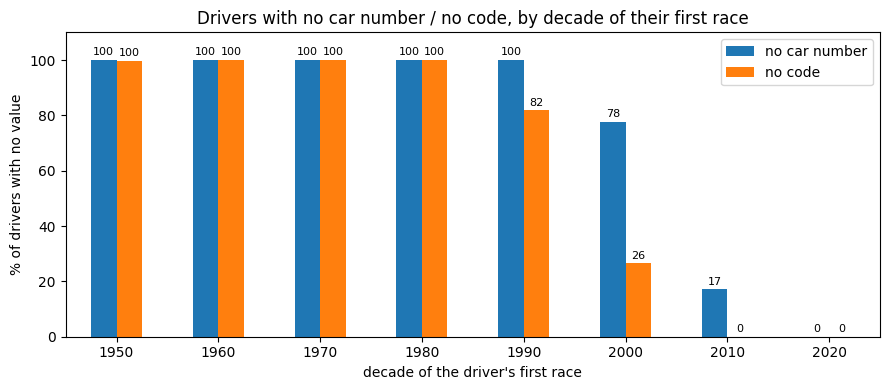

In [103]:
# first season of each driver, from the deduplicated results
debut = (results_unique.merge(races[['raceId', 'year']], on='raceId')
         .groupby('driverId').year.min())

d = drivers.assign(debut_year=drivers.driverId.map(debut))
d['debut_decade'] = d.debut_year // 10 * 10

# exact counts and percentages per decade of debut
by_decade = d.groupby('debut_decade').agg(
    drivers=('driverId', 'size'),
    with_number=('number', lambda s: int(s.notna().sum())),
    with_code=('code', lambda s: int(s.notna().sum())))
by_decade['number_missing_pct'] = ((1 - by_decade.with_number / by_decade.drivers) * 100).round(1)
by_decade['code_missing_pct'] = ((1 - by_decade.with_code / by_decade.drivers) * 100).round(1)
display(by_decade)

# drivers who debuted from 2014
recent = d[d.debut_year >= 2014]
print('Drivers who debuted from 2014:', len(recent),
      '| with a number:', int(recent.number.notna().sum()),
      '| with a code:', int(recent.code.notna().sum()))

# old drivers (debut before 1990) that do have a code
print('\nDebut before 1990 but with a code:')
print(d.loc[(d.debut_year < 1990) & d.code.notna(),
            ['driverRef', 'code', 'debut_year']].sort_values('debut_year'))

# bar chart: % of drivers with no number / no code, by decade of first race
ax = by_decade[['number_missing_pct', 'code_missing_pct']].plot.bar(
    figsize=(9, 4), rot=0,
    title="Drivers with no car number / no code, by decade of their first race")
ax.set_xlabel("decade of the driver's first race")
ax.set_ylabel('% of drivers with no value')
ax.set_ylim(0, 110)
ax.legend(['no car number', 'no code'])

# print the exact percent on each bar so rounding can't hide the exceptions
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', fontsize=8, padding=2)

plt.tight_layout()
plt.show()


### drivers: structure and missing values

**Grain.** One row is one driver, 861 rows and 9 columns. `driverId` is the identifier, `driverRef` is a text code, `forename` and `surname` give the name, `dob` is the date of birth, and `nationality` is the country adjective such as British or German. Every driver appears in the results table, so there are no unused drivers.

**Format check.** `dob` has a single pattern (`YYYY-MM-DD`) in all 861 rows. Every `code` is exactly 3 letters, and every `number` is a whole number, so `number` is stored as a float only because it has missing values.

**Missing values.** Only two columns have gaps, and in both cases the gaps follow the era of the driver's first season and are not random.
- `number` is missing for 802 of 861 drivers, so only 59 have one. All 59 debuted in 2000 or later and were still racing in 2014 or later, so nobody who retired before 2014 has one.
- `code` is missing for 757 drivers, so 104 have one. Among drivers who debuted before 1990, only one has a code, Lucien Bianchi (debut 1959), so this is a single exception and not a pattern.
- All 38 drivers who debuted from 2014 have both a number and a code, so nothing is missing for the modern era.

**What missing means here.** A missing `number` or `code` means it did not exist for that driver in that era, and it does not mean the value was lost. The data shows the pattern. The likely reason, that permanent car numbers were introduced in 2014, is general Formula 1 knowledge that the data does not show.

**Decision.** `number` and `code` are labels and not performance information, so they are not used as features. We keep the missing cells as they are and do not fill them. `nationality` is complete, which matters for the home-country question.

**Next.** Convert `dob` to a real date, check the ages for impossible values, and then check the primary key and the links to other tables.

In [104]:
drivers_raw = drivers.copy()
drivers['dob'] = pd.to_datetime(drivers['dob'], format='%Y-%m-%d')

# before vs after
print('dob dtype before / after:', drivers_raw.dob.dtype, '/', drivers.dob.dtype)
print('dob filled before / after:', drivers_raw.dob.notna().sum(), '/', drivers.dob.notna().sum())
print('dob range:', drivers.dob.min().date(), 'to', drivers.dob.max().date())

# age in the first season each driver raced
yrs = (results_unique.merge(races[['raceId', 'year']], on='raceId')
       .groupby('driverId').year.agg(first='min', last='max'))
d = drivers.merge(yrs, left_on='driverId', right_index=True)
d['age_at_first_season'] = d['first'] - d.dob.dt.year
print(d.age_at_first_season.describe())

# the extremes, to look at by eye
cols = ['driverRef', 'dob', 'first', 'age_at_first_season']
print('\nyoungest at first season:'); print(d.nsmallest(5, 'age_at_first_season')[cols])
print('\noldest at first season:');   print(d.nlargest(5, 'age_at_first_season')[cols])

dob dtype before / after: object / datetime64[ns]
dob filled before / after: 861 / 861
dob range: 1896-12-28 to 2005-05-08
count    861.000000
mean      29.959350
std        6.647571
min       18.000000
25%       25.000000
50%       29.000000
75%       34.000000
max       54.000000
Name: age_at_first_season, dtype: float64

youngest at first season:
             driverRef        dob  first  age_at_first_season
451            monarch 1945-09-03   1963                   18
829     max_verstappen 1997-09-30   2015                   18
152        alguersuari 1990-03-23   2009                   19
190          thackwell 1961-03-30   1980                   19
454  ricardo_rodriguez 1942-02-14   1961                   19

oldest at first season:
     driverRef        dob  first  age_at_first_season
703      legat 1898-11-01   1952                   54
741  etancelin 1896-12-28   1950                   54
750     brudes 1899-10-15   1952                   53
760      dusio 1899-10-13   1952   

In [105]:
drivers.dtypes

driverId                int64
driverRef              object
number                float64
code                   object
forename               object
surname                object
dob            datetime64[ns]
nationality            object
url                    object
dtype: object

In [106]:
# primary key
print('driverId nulls:       ', drivers.driverId.isna().sum())
print('driverId duplicates:  ', drivers.driverId.duplicated().sum())

# other columns that look like identifiers
print('driverRef duplicates: ', drivers.driverRef.duplicated().sum())
print('code duplicates:      ', drivers.code.dropna().duplicated().sum())
print('number duplicates:    ', drivers.number.dropna().duplicated().sum())

# same person twice? (name + date of birth)
print('(forename, surname, dob) duplicates:', drivers.duplicated(['forename', 'surname', 'dob']).sum())

# links to other tables
res_raw = raw_before['results']
print('driverIds in results not found in drivers:', (~res_raw.driverId.isin(drivers.driverId)).sum())
print('drivers with no result rows:              ', (~drivers.driverId.isin(res_raw.driverId)).sum())
print('driverIds in qualifying not in drivers:   ', (~qualifying.driverId.isin(drivers.driverId)).sum())

driverId nulls:       

 0
driverId duplicates:   0
driverRef duplicates:  0
code duplicates:       7
number duplicates:     11
(forename, surname, dob) duplicates: 0
driverIds in results not found in drivers: 0
drivers with no result rows:               0
driverIds in qualifying not in drivers:    0


In [107]:
shared_code = drivers[drivers.code.notna() & drivers.code.duplicated(keep=False)].sort_values('code')
print(shared_code[['code', 'forename', 'surname', 'dob']])

shared_num = drivers[drivers.number.notna() & drivers.number.duplicated(keep=False)].sort_values('number')
print(shared_num[['number', 'forename', 'surname', 'dob']])


    code    forename     surname        dob
26   ALB  Christijan      Albers 1979-04-16
846  ALB   Alexander       Albon 1996-03-23
375  BIA      Lucien     Bianchi 1934-11-10
823  BIA       Jules     Bianchi 1989-08-03
37   DOO      Robert    Doornbos 1981-09-23
860  DOO        Jack      Doohan 2003-01-20
836  HAR         Rio    Haryanto 1993-01-22
841  HAR     Brendon     Hartley 1989-11-10
75   MAG         Jan   Magnussen 1973-07-04
824  MAG       Kevin   Magnussen 1992-10-05
29   MSC     Michael  Schumacher 1969-01-03
852  MSC        Mick  Schumacher 1999-03-22
817  VER   Jean-Éric      Vergne 1990-04-25
829  VER         Max  Verstappen 1997-09-30
     number  forename     surname        dob
837     2.0   Stoffel   Vandoorne 1992-03-26
856     2.0     Logan    Sargeant 2000-12-31
844     4.0     Lando      Norris 1999-11-13
819     4.0       Max     Chilton 1991-04-21
847     6.0  Nicholas      Latifi 1995-06-29
2       6.0      Nico     Rosberg 1985-06-27
827     9.0    Marcus    

### drivers: codes and numbers are not identifiers

**What we checked.** `driverId` is the only column that identifies a driver. We tested `code` and `number` to see whether they could do the same job, and neither can, because both are reused by different drivers.

**Shared codes.** 7 codes are used by two drivers each, so 14 drivers share a code. The code is built from the first letters of the surname, so drivers with the same or similar surnames collide. The pairs are Albers and Albon (ALB), Lucien and Jules Bianchi (BIA), Doornbos and Doohan (DOO), Haryanto and Hartley (HAR), Jan and Kevin Magnussen (MAG), Michael and Mick Schumacher (MSC), and Vergne and Verstappen (VER). These are different people, not duplicate rows.

**Shared numbers.** 11 numbers are used by two drivers each, so 22 drivers share a number. Examples are Kubica and Haryanto on 88, Button and Tsunoda on 22, and Rosberg and Latifi on 6. They look like the same number used by different drivers in different years, but we did not test whether any pair raced in the same season.

**Why it matters.** A join on `code` would merge Michael and Mick Schumacher into one driver, and a join on `number` would merge unrelated drivers. We use `driverId` for every join.

**No duplicate people.** `driverId` and `driverRef` have 0 duplicates, and no driver appears twice under the same forename, surname and date of birth.


In [108]:
# (a) how circuit countries are written
races_per_country = (races.merge(circuits[['circuitId', 'country']], on='circuitId')
                     .groupby('country').size().rename('races'))
country_table = (circuits.groupby('country').size().rename('circuits')
                 .to_frame().join(races_per_country))

abbreviations = [c for c in country_table.index if c.isupper() and len(c) <= 3]
print('Different country spellings:', len(country_table), '| abbreviations:', abbreviations)
display(country_table.loc[['USA', 'United States']])

usa_merged = circuits.country.replace({'United States': 'USA'})   # a copy, raw stays untouched
print("After merging 'United States' into 'USA':", usa_merged.nunique(), 'countries')

# (b) can circuit countries be matched to driver nationalities as written?
same_words = sorted(set(circuits.country) & set(drivers.nationality))
print('Circuit countries spelled exactly like a nationality:', len(same_words),
      'of', circuits.country.nunique(), '|', same_words)

# (c) the nationality column itself
print('Different nationality values:', drivers.nationality.nunique())
print('Values with stray spaces:',
      list(drivers.nationality[drivers.nationality != drivers.nationality.str.strip()].unique()))
print('Combined or historical values:',
      sorted(n for n in drivers.nationality.unique() if '-' in n or n in {'East German', 'Rhodesian'}))


Different country spellings: 35 | abbreviations: ['UAE', 'UK', 'USA']


,circuits,races
country,,
USA,11,77
United States,1,2


After merging 'United States' into 'USA': 34 countries
Circuit countries spelled exactly like a nationality: 0 of 35 | []
Different nationality values: 43
Values with stray spaces: ['Argentinian ']
Combined or historical values: ['American-Italian', 'Argentine-Italian', 'East German', 'Rhodesian']


### circuits and drivers: countries and nationalities

**What we checked.** The home-country question, and a possible home-race feature, need to match the country of a circuit with the nationality of a driver. We checked whether the two columns can be matched as they are written.

**Circuit countries.** `country` has 35 different spellings. The United States is written two ways, `USA` for 11 circuits (77 races) and `United States` for the Las Vegas circuit (2 races), and after merging them there are 34 countries. `UK`, `UAE` and `USA` are abbreviations, and `Korea` is a short form. The merge is done on the cleaned copy below; the CSV is not changed.

**They cannot be matched directly.** Circuits store a country name such as `UK` or `Germany`, while drivers store an adjective such as `British` or `German`. None of the 35 circuit countries is spelled exactly like a driver nationality, so a direct join would find no home race at all.

**Nationality values.** `nationality` has 43 different values and no missing values. One value, `Argentinian ` (one driver), has a trailing space and is the same nationality as `Argentine` (24 drivers), written another way. Four values do not map to one country, which are `American-Italian`, `Argentine-Italian`, `East German` and `Rhodesian`, because the driver has two nationalities or the country no longer exists.

**Decision.** We make the two spellings consistent on the cleaned copies (the cell below); the CSVs are not changed:
- `United States` becomes `USA` in circuits;
- `Argentinian ` becomes `Argentine` in drivers, which also removes the trailing space.

Countries and nationalities still cannot be joined directly, so Q2 builds one explicit nationality-to-country map, and the `is_home` feature must use the same map, so the two always define a home race in the same way. A driver with two nationalities (`American-Italian`, `Argentine-Italian`) is at home in both countries. `East German` and `Rhodesian` are never at home, because those countries no longer exist. The Indianapolis 500 rows are excluded from both, as described above.


In [109]:
# make the two spellings consistent on the cleaned copies (the CSVs are not changed)
country_before, nationality_before = circuits.country.copy(), drivers.nationality.copy()
circuits['country'] = circuits.country.replace({'United States': 'USA'})
drivers['nationality'] = drivers.nationality.str.strip().replace({'Argentinian': 'Argentine'})

print('circuits changed:', (circuits.country != country_before).sum(),
      '| countries:', country_before.nunique(), '->', circuits.country.nunique())
print('drivers changed:', (drivers.nationality != nationality_before).sum(),
      '| nationalities:', nationality_before.nunique(), '->', drivers.nationality.nunique())
assert 'United States' not in set(circuits.country)
assert (drivers.nationality == drivers.nationality.str.strip()).all() and 'Argentinian' not in set(drivers.nationality)

circuits changed: 1 | countries: 35 -> 34
drivers changed: 1 | nationalities: 43 -> 42


## `Constructors Table`

In [110]:
constructors = load('constructors')

print('shape:', constructors.shape)
display(constructors.head())
print(constructors.dtypes)
print('\nmissing per column:')
print(constructors.isna().sum())

shape: (212, 5)


,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


constructorId      int64
constructorRef    object
name              object
nationality       object
url               object
dtype: object

missing per column:
constructorId     0
constructorRef    0
name              0
nationality       0
url               0
dtype: int64


In [111]:
# primary key and other identifier-like columns
print('constructorId nulls:      ', constructors.constructorId.isna().sum())
print('constructorId duplicates: ', constructors.constructorId.duplicated().sum())
print('constructorRef duplicates:', constructors.constructorRef.duplicated().sum())
print('name duplicates:          ', constructors.name.duplicated().sum())

# nationality values
print('\ndifferent nationality values:', constructors.nationality.nunique())
print('values with stray spaces:', list(constructors.nationality[constructors.nationality != constructors.nationality.str.strip()].unique()))
print(constructors.nationality.value_counts())

# links to other tables
res_raw = raw_before['results']
print('\nconstructorIds in results not found in constructors:', (~res_raw.constructorId.isin(constructors.constructorId)).sum())
print('constructors with no result rows:                   ', (~constructors.constructorId.isin(res_raw.constructorId)).sum())
print('constructorIds in qualifying not in constructors:   ', (~qualifying.constructorId.isin(constructors.constructorId)).sum())


constructorId nulls:       0
constructorId duplicates:  0
constructorRef duplicates: 0
name duplicates:           0

different nationality values: 24
values with stray spaces: []
nationality
British          86
American         39
Italian          30
French           13
German           10
Japanese          5
Swiss             5
Dutch             3
South African     3
Russian           2
Malaysian         2
Canadian          2
Indian            1
Austrian          1
Hong Kong         1
Irish             1
Mexican           1
Brazilian         1
New Zealander     1
Australian        1
Rhodesian         1
Belgian           1
East German       1
Spanish           1
Name: count, dtype: int64

constructorIds in results not found in constructors: 0
constructors with no result rows:                    1
constructorIds in qualifying not in constructors:    0


### constructors: structure, keys and missing values

**Grain.** One row is one constructor, meaning a team entry. The table has 212 rows and 5 columns. `constructorId` is the identifier, `constructorRef` is a text code, `name` is the team name, `nationality` is the country adjective of the team, and `url` is the Wikipedia page.

**Types and missing values.** The ID is an integer and the other four columns are text, so nothing needed converting. No column has missing values, and loading with `\N` as missing found none to convert.

**Primary key.** `constructorId` has 0 nulls and 0 duplicates, so it is a valid primary key. `constructorRef` and `name` are also unique.

**Foreign keys.** The table has no foreign keys of its own. Every `constructorId` in `results` and in `qualifying` exists in `constructors`, so there are no orphans. One constructor has no result rows, which is a fact to note and not an error.

**Nationality.** `nationality` has 24 different values, no missing values and no stray spaces. `East German` and `Rhodesian` refer to countries that no longer exist, and `Hong Kong` is not a country in the circuits table, so these would need a rule if constructor nationality were ever matched to a circuit country. We do not plan to use it as a feature.

**Decision.** We keep `constructors` unchanged and use `constructorId` for every join, never `name` or `constructorRef`.

**Next.** Whether one `constructorId` is one continuous team, which matters for the mechanical-retirement question and for any team-form feature.


In [112]:
cars = (results_unique[['raceId', 'constructorId']]
        .merge(races[['raceId', 'year', 'name']].rename(columns={'name': 'race_name'}), on='raceId'))

# (a) activity per constructor
activity = cars.groupby('constructorId').agg(entries=('raceId', 'size'),
                                             first=('year', 'min'), last=('year', 'max'))
teams = constructors.merge(activity, left_on='constructorId', right_index=True, how='left')
print('constructors:', len(teams),
      '| with no result row:', int(teams.entries.isna().sum()), teams[teams.entries.isna()].name.tolist(),
      '| raced a single season only:', int((teams['first'] == teams['last']).sum()),
      '| with 100 or more entries:', int((teams.entries >= 100).sum()))


constructors: 212 | with no result row: 2 ['Eagle', 'Del Roy'] | raced a single season only: 69 | with 100 or more entries: 56


In [113]:
# (b) same Wikipedia page for several constructorIds
same_page = (constructors[constructors.url.duplicated(keep=False)]
             .groupby('url').agg(ids=('constructorId', 'size'),
                                 names=('name', lambda s: ', '.join(sorted(s)[:4]))))
print('constructors sharing a page with another:', int(constructors.url.duplicated(keep=False).sum()),
      'in', len(same_page), 'groups')
display(same_page.sort_values('ids', ascending=False).head(4))


constructors sharing a page with another: 50 in 13 groups


,ids,names
url,,
http://en.wikipedia.org/wiki/Cooper_Car_Company,11,"Cooper, Cooper-ATS, Cooper-Alfa Romeo, Cooper-BRM"
http://en.wikipedia.org/wiki/Team_Lotus,7,"Lotus-BRM, Lotus-Borgward, Lotus-Climax, Lotus..."
http://en.wikipedia.org/wiki/Brabham,6,"Brabham, Brabham-Alfa Romeo, Brabham-BRM, Brab..."
http://en.wikipedia.org/wiki/De_Tomaso,4,"De Tomaso, De Tomaso-Alfa Romeo, De Tomaso-Fer..."


In [114]:
# (c) one id covering separate periods
def longest_break(years):
    years = sorted(years)
    return max([b - a - 1 for a, b in zip(years, years[1:])], default=0)

teams['longest_break_seasons'] = teams.constructorId.map(
    cars.groupby('constructorId').year.apply(lambda s: longest_break(set(s))))
display(teams[(teams.longest_break_seasons >= 5) & (teams.entries >= 50)]
        .sort_values('entries', ascending=False)
        [['name', 'first', 'last', 'entries', 'longest_break_seasons']])

,name,first,last,entries,longest_break_seasons
31,Team Lotus,1958.0,1994.0,871.0,6.0
14,Sauber,1993.0,2024.0,837.0,5.0
3,Renault,1977.0,2020.0,787.0,16.0
33,Brabham,1962.0,1992.0,662.0,6.0
129,Mercedes,1954.0,2024.0,650.0,54.0
20,Arrows,1978.0,2002.0,590.0,6.0
49,Alfa Romeo,1950.0,2023.0,447.0,33.0
115,Aston Martin,1959.0,2024.0,191.0,60.0
25,Lola,1962.0,1997.0,165.0,9.0
52,ATS,1963.0,1984.0,162.0,14.0


In [115]:
# (d) constructors that only ever raced the Indianapolis 500
indy = cars.race_name == 'Indianapolis 500'
only_indy = set(cars[indy].constructorId) - set(cars[~indy].constructorId)
print('constructors that only raced the Indianapolis 500:', len(only_indy),
      '| their entries:', int(cars.constructorId.isin(only_indy).sum()))

constructors that only raced the Indianapolis 500: 30 | their entries: 166


### constructors: is one constructorId one continuous team

**Teams split over several ids.** 50 constructors share a Wikipedia page with another constructor, in 13 groups. The largest groups are Cooper with 11 ids, Team Lotus with 7, Brabham with 6 and De Tomaso with 4. The names, such as Cooper-ATS and Cooper-BRM, suggest that the same car maker was given a new id for each engine pairing, although the data only shows the shared page and not the reason. A team's history is therefore cut into several pieces, and this mostly affects the early decades.

**Ids covering separate periods.** Several large constructors have a long gap between two periods of racing under the same id. Mercedes raced in 1954 and 1955 and then again from 2010 to 2024, with a gap of 54 seasons in between. Aston Martin has a gap of 60 seasons, Honda 37, Alfa Romeo 33 and Renault 16. The data shows the gaps, and it is general Formula 1 knowledge, not something the table shows, that the later period is a different team under the same name.

**How active the constructors were.** Of the 212 constructors, 69 raced a single season only and 56 have 100 or more entries, so the table is made of a few long-lived teams and a long tail of short-lived ones. Team form is only meaningful for the long-lived teams.

**Consequence for features.** A rolling team-form feature that looks back over the last few races of one id would, for Mercedes' first race in 2010, reach back to 1955 and treat those results as recent form. Team form must therefore be limited to recent seasons or restarted after a long gap, and we also need to decide whether to link the ids that are split over several engine pairings.

**Constructors that only raced the Indianapolis 500.** 30 constructors raced only the Indianapolis 500, with 166 entries in total, so they disappear from the modelling table when those rows are excluded.

**Constructors with no results.** In the raw results table one constructor has no rows at all. After the duplicate rule there are two, Eagle and Del Roy. The second one had a single raw row, a 32nd place in race 809 (the 1953 Indianapolis 500), which the rule removed because the same driver has a better-placed row in that race. Removing rows can only leave more constructors empty, so the change from one to two is expected, and neither constructor affects the model.

**Decision.** We keep `constructors` unchanged and join on `constructorId`, never on `name`. The handling of long gaps and split ids is decided when the team-form feature is built.


## `Status Table`

In [116]:
status = load('status')

print('shape:', status.shape)
display(status.head(10))
print(status.dtypes)
print('\nmissing per column:')
print(status.isna().sum())

shape: (139, 2)


,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine
5,6,Gearbox
6,7,Transmission
7,8,Clutch
8,9,Hydraulics
9,10,Electrical


statusId     int64
status      object
dtype: object

missing per column:
statusId    0
status      0
dtype: int64


In [117]:
# primary key and label uniqueness
print('statusId nulls:       ', status.statusId.isna().sum())
print('statusId duplicates:  ', status.statusId.duplicated().sum())
print('status duplicates:    ', status.status.duplicated().sum())
print('labels with stray spaces:', list(status.status[status.status != status.status.str.strip()]))

# links to results
res_raw = raw_before['results']
print('statusIds in results not found in status:', (~res_raw.statusId.isin(status.statusId)).sum())
print('statuses never used in results:          ', (~status.statusId.isin(res_raw.statusId)).sum())


statusId nulls:        0
statusId duplicates:   0
status duplicates:     0
labels with stray spaces: []
statusIds in results not found in status: 0
statuses never used in results:           2


In [118]:
# how often each status is used (deduplicated results)
counts = (results_unique.merge(status, on='statusId')
          .groupby('status').size().sort_values(ascending=False)
          .rename('rows').to_frame())
counts['share_%'] = (counts.rows / counts.rows.sum() * 100).round(1)

with pd.option_context('display.max_rows', None):
    display(counts)

,rows,share_%
status,,
Finished,7674,28.8
+1 Lap,4036,15.1
Engine,2006,7.5
+2 Laps,1611,6.0
Accident,1053,3.9
Did not qualify,1024,3.8
Collision,854,3.2
Gearbox,804,3.0
Spun off,790,3.0


### status: structure, keys and how often each label is used

**Grain.** One row is one way a driver's race can end, 139 rows and 2 columns. `statusId` is the identifier and `status` is the label, such as `Finished`, `Engine` or `Accident`. It is a lookup table, so nothing is missing and the types need no conversion.

**Primary key.** `statusId` has 0 nulls and 0 duplicates, so it is a valid primary key, and `status` is also unique with no stray spaces.

**Foreign keys.** The table has no foreign keys of its own. Every `statusId` in `results` exists in `status`, and 2 of the 139 statuses are never used.

**What the column mixes.** The labels describe several different things in one column. Some mean the driver finished (`Finished` and the `+N Laps` labels, which are classified but lapped), some are mechanical failures, some are crashes, and some are not retirements at all, such as `Did not qualify` and `Withdrew`. The usage is a long tail. A few labels cover most rows, `Finished` alone is 28.8% and `+1 Lap` is 15.1%, while about 60 labels are used fewer than 10 times.

**Unclear labels.** `Retired`, `Not classified`, `Mechanical` and `Technical` do not say what kind of retirement it was, so they need an explicit rule before any mechanical-retirement rate is computed.

**Decision.** We keep `status` unchanged and group its labels into categories in a separate step, because the grouping is a modelling choice and not a cleaning fix.


lapped statuses: 33 | never used: ['+49 Laps', '+38 Laps'] | used 5 times or fewer: 54


,statuses,entries
group,,
finished,1,7674
"finished, laps down",33,7478
mechanical (clear),58,6217
accident or collision,5,2760
did not start,4,1610
grey zone,29,708
disqualified or excluded,3,156
driver health,6,65


period,2014-2021,2022-2024
mechanical (clear only),8.8,5.4
mechanical + grey zone,11.0,6.8
accident or collision,6.7,6.6


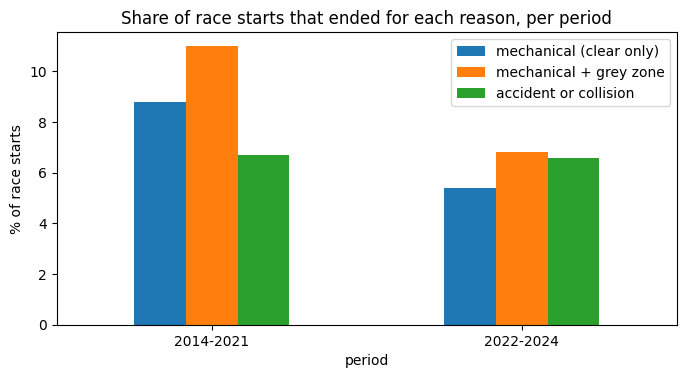

podium finishers with status finished or laps down: 99.8 %


In [119]:
res = results_unique.merge(races[['raceId', 'year']], on='raceId')

status['times_used'] = status.statusId.map(res.statusId.value_counts()).fillna(0).astype(int)
lapped = status.status.str.match(r'^\+\d+ Laps?$')
print('lapped statuses:', int(lapped.sum()),
      '| never used:', status[status.times_used == 0].status.tolist(),
      '| used 5 times or fewer:', int((status.times_used <= 5).sum()))

GROUPS = {
    'did not start': ['Did not qualify', 'Did not prequalify', '107% Rule', 'Withdrew'],
    'disqualified or excluded': ['Disqualified', 'Excluded', 'Underweight'],
    'accident or collision': ['Accident', 'Collision', 'Collision damage', 'Spun off', 'Fatal accident'],
    'driver health': ['Injury', 'Injured', 'Eye injury', 'Illness', 'Driver unwell', 'Physical'],
    'mechanical (clear)': ['Engine', 'Gearbox', 'Suspension', 'Transmission', 'Electrical', 'Brakes', 'Clutch',
        'Fuel system', 'Turbo', 'Hydraulics', 'Overheating', 'Ignition', 'Oil leak', 'Throttle', 'Halfshaft',
        'Oil pressure', 'Fuel pump', 'Differential', 'Fuel leak', 'Steering', 'Radiator', 'Power Unit',
        'Wheel bearing', 'Injection', 'Fuel pressure', 'Water leak', 'Alternator', 'Exhaust', 'Chassis',
        'Mechanical', 'Magneto', 'Driveshaft', 'Axle', 'Battery', 'Power loss', 'Oil pump', 'Distributor',
        'Oil pipe', 'Electronics', 'Water pressure', 'Water pump', 'ERS', 'Supercharger', 'Technical',
        'Pneumatics', 'Fuel pipe', 'Spark plugs', 'Water pipe', 'Drivetrain', 'Track rod', 'Oil line',
        'Engine fire', 'Engine misfire', 'Crankshaft', 'CV joint', 'Cooling system', 'Launch control', 'Brake duct'],
    'grey zone': ['Retired', 'Not classified', 'Out of fuel', 'Wheel', 'Wheel nut', 'Wheel rim', 'Tyre', 'Puncture',
        'Tyre puncture', 'Handling', 'Heat shield fire', 'Fire', 'Vibrations', 'Broken wing', 'Rear wing',
        'Front wing', 'Undertray', 'Damage', 'Debris', 'Fuel', 'Fuel rig', 'Refuelling', 'Stalled', 'Seat',
        'Driver Seat', 'Safety belt', 'Safety', 'Safety concerns', 'Not restarted']}
group_of = {s: g for g, members in GROUPS.items() for s in members}

status['group'] = [('finished' if s == 'Finished' else 'finished, laps down' if lapped[i] else group_of.get(s))
                   for i, s in zip(status.index, status.status)]
assert status.group.notna().all(), 'some status is not placed in a group'
display(status.groupby('group').agg(statuses=('status', 'size'), entries=('times_used', 'sum'))
        .sort_values('entries', ascending=False))

# share of race starts per Q3 period (everyone who did not start is left out: the 'did not start' group and never_ran)
res['period'] = pd.cut(res.year, [2013, 2021, 2024], labels=['2014-2021', '2022-2024'])
starts = res.merge(status[['statusId', 'group']], on='statusId')
starts = starts[(starts.group != 'did not start') & ~starts.never_ran & starts.period.notna()]
share = (starts.groupby('period', observed=True).group.value_counts(normalize=True).unstack(0) * 100).round(1)
rates = pd.DataFrame({'mechanical (clear only)': share.loc['mechanical (clear)'],
                      'mechanical + grey zone': share.loc['mechanical (clear)'] + share.loc['grey zone'],
                      'accident or collision': share.loc['accident or collision']})
display(rates.T)

rates.plot.bar(figsize=(8, 3.8), rot=0, title='Share of race starts that ended for each reason, per period')
plt.xlabel('period')
plt.ylabel('% of race starts')
plt.show()

# leakage check: how much of the podium does status give away?
podium = res[res.positionOrder <= 3]
podium_group = podium.statusId.map(status.set_index('statusId').group)
print('podium finishers with status finished or laps down:',
      round(podium_group.isin(['finished', 'finished, laps down']).mean() * 100, 1), '%')


### status: grouping the labels for the mechanical-retirement question

**Why a grouping is needed.** The `status` column mixes finishes, mechanical failures, crashes, driver problems and rule decisions in one list of 139 labels. The brief defines a mechanical retirement as a start that ended early because a component of the car failed, and it excludes crashes, driver causes and regulation decisions, so the labels have to be grouped before a rate can be computed.

**The draft grouping.** Every label is placed in exactly one of eight groups, and the code stops if one is missed. The groups are finished (1 label), finished but laps down (33 labels, the `+N Laps` family), clear mechanical failure (58), accident or collision (5), did not start (4), disqualified or excluded (3), driver health (6) and a grey zone (29). The grey zone holds labels that could be a failure or something else, such as `Retired`, `Not classified`, `Out of fuel`, the tyre and wheel labels and the wing labels. Two labels, `+49 Laps` and `+38 Laps`, are never used.

**How much the grey zone matters.** Counting race starts, and leaving out everyone who did not start, clear mechanical failures end 8.8% of starts in 2014 to 2021 and 5.4% in 2022 to 2024. Adding the whole grey zone gives 11.0% and 6.8%. The fall between the two periods is about the same either way, so the choices about individual grey labels do not change the comparison. Accidents and collisions stay at about 6.6% in both periods.

**Decision.** The grouping is a draft and not a cleaning fix, so `status` itself is unchanged. The question that uses it reports the clear-only rate and states the grey zone as a range.

**Not a feature.** The status of a race is only known after it ends, and 99.8% of podium finishers have a status of finished or finished laps down, so using it would give away the answer. It cannot be used as a model input.

## `Driver Standings Table`

In [120]:
driver_standings = load('driver_standings')

print('shape:', driver_standings.shape)
display(driver_standings.head())
print(driver_standings.dtypes)
print('\nmissing per column:')
print(driver_standings.isna().sum())

shape: (34863, 7)


,driverStandingsId,raceId,driverId,points,position,positionText,wins
0,1,18,1,10.0,1,1,1
1,2,18,2,8.0,2,2,0
2,3,18,3,6.0,3,3,0
3,4,18,4,5.0,4,4,0
4,5,18,5,4.0,5,5,0


driverStandingsId      int64
raceId                 int64
driverId               int64
points               float64
position               int64
positionText          object
wins                   int64
dtype: object

missing per column:
driverStandingsId    0
raceId               0
driverId             0
points               0
position             0
positionText         0
wins                 0
dtype: int64


In [121]:
ds_raw = driver_standings.copy()

# keys
print('driverStandingsId nulls:     ', ds_raw.driverStandingsId.isna().sum())
print('driverStandingsId duplicates:', ds_raw.driverStandingsId.duplicated().sum())
print('(raceId, driverId) duplicates:', ds_raw.duplicated(['raceId', 'driverId']).sum())

# links to other tables
print('raceIds not in races:   ', (~ds_raw.raceId.isin(races.raceId)).sum())
print('driverIds not in drivers:', (~ds_raw.driverId.isin(drivers.driverId)).sum())
print('races without any standings:', (~races.raceId.isin(ds_raw.raceId)).sum(), 'of', len(races))


driverStandingsId nulls:      0
driverStandingsId duplicates: 0
(raceId, driverId) duplicates: 0
raceIds not in races:    0
driverIds not in drivers: 0
races without any standings: 0 of 1125


In [122]:
# the rows, in season order
ds = (ds_raw.merge(races[['raceId', 'year', 'round', 'name']], on='raceId')
      .sort_values(['year', 'driverId', 'round']))

# is it a running total? points and wins should never go down inside a season
ds['added'] = ds.groupby(['year', 'driverId']).points.diff().fillna(ds.points)
ds['wins_added'] = ds.groupby(['year', 'driverId']).wins.diff().fillna(ds.wins)
print('points ever go down in a season:', int((ds.added < 0).sum()),
      '| wins ever go down:', int((ds.wins_added < 0).sum()))

points ever go down in a season: 0 | wins ever go down: 0


### driver_standings: structure, keys and what a row means

**Grain.** The table has 34,863 rows and 7 columns. One row is a driver's championship standing right after one race. `points` and `wins` are running totals for that season, and `position` is the championship rank at that moment, not the finishing position in the race. Points restart at 0 every season, so a driver's season is grouped by year and driver.

**Types and missing values.** `driverStandingsId`, `raceId`, `driverId`, `position` and `wins` are integers, `points` is a float because half points exist in some old seasons, and `positionText` is text. No column has missing values, so nothing needed converting.

**Primary key.** `driverStandingsId` has 0 nulls and 0 duplicates, so it is a valid primary key. The natural key `(raceId, driverId)` also has 0 duplicates, so a driver has at most one standing per race.

**Foreign keys.** Every `raceId` exists in `races` and every `driverId` exists in `drivers`, so there are no orphans. Every one of the 1,125 races has standings.

**Running total check.** Inside a season, points never go down and wins never go down, which confirms that each row is a running total and not a per-race score.

**Leakage.** A row is the standing after the race, so it already contains that race's result. For a feature on a given race, we use the standing from the previous round of the same season, ordered by `(year, round)`. In round 1 there is no previous row, so the values start at 0 and are marked with a flag.

**Next.** Which race starters have no standings row, how the decimal points arise, and how points differ between seasons.


In [123]:
# starters (from deduplicated results) vs standings rows
st = (results_unique[['raceId', 'driverId', 'points']]
      .merge(races[['raceId', 'year']], on='raceId'))
has = ds[['raceId', 'driverId']].assign(has_row=1)
st = st.merge(has, on=['raceId', 'driverId'], how='left')
st['has_row'] = st.has_row.fillna(0).astype(bool)

# standings rows for a driver who has no result row in that race
rows_no_result = ds[['raceId', 'driverId']].merge(
    results_unique[['raceId', 'driverId']].assign(r=1), on=['raceId', 'driverId'], how='left')
print('standings rows with no result row in that race:', int(rows_no_result.r.isna().sum()))

# result rows with no standings row
no_row = st[~st.has_row]
print('result rows with no standings row:', len(no_row), 'of', len(st))
print('by decade (%):', ((1 - st.groupby(st.year // 10 * 10).has_row.mean()) * 100).round(1).to_dict())
print('rows that scored points but have no standings row:',
      int((~st.has_row & (st.points > 0)).sum()), 'of', int((st.points > 0).sum()))

# champion's final points per season (row of the last round, position 1)
last_round = ds.sort_values('round').groupby('year').raceId.last()
champion = ds[ds.raceId.isin(last_round) & (ds.position == 1)].set_index('year').points
print("champion's final points: 1950 =", champion[1950], '| 2009 =', champion[2009],
      '| 2010 =', champion[2010], '| 2023 =', champion[2023])


standings rows with no result row in that race: 8664
result rows with no standings row: 469 of 26668
by decade (%): {1950: 0.1, 1960: 0.1, 1970: 0.1, 1980: 0.2, 1990: 7.0, 2000: 4.1, 2010: 0.1, 2020: 0.0}
rows that scored points but have no standings row: 0 of 8165
champion's final points: 1950 = 30.0 | 2009 = 95.0 | 2010 = 256.0 | 2023 = 575.0


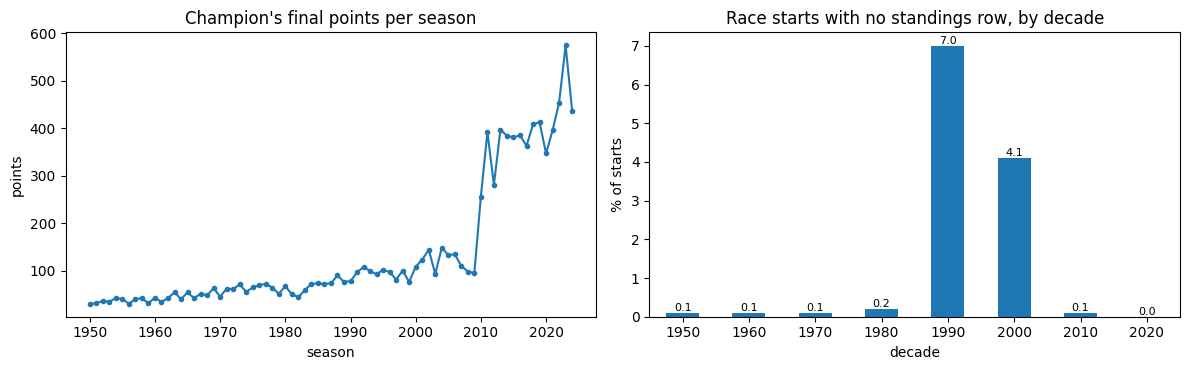

In [124]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

champion.plot(ax=axes[0], marker='o', markersize=3)
axes[0].set_title("Champion's final points per season")
axes[0].set_xlabel('season')
axes[0].set_ylabel('points')

miss = ((1 - st.groupby(st.year // 10 * 10).has_row.mean()) * 100).round(1)
miss.plot.bar(ax=axes[1], rot=0)
axes[1].set_title('Race starts with no standings row, by decade')
axes[1].set_xlabel('decade')
axes[1].set_ylabel('% of starts')
for c in axes[1].containers:
    axes[1].bar_label(c, fmt='%.1f', fontsize=8)

plt.tight_layout()
plt.show()


### driver_standings: who has a standings row

**Standings rows for drivers who did not race.** 8,664 of the 34,863 rows belong to a driver with no result row in that race.

**Starts without a standings row.** 469 of the 26,668 result rows (1.8%) have no standings row. They are concentrated in the 1990s (7.0%) and 2000s (4.1%) and are below 0.3% in every other decade. None of them scored points, so the missing rows belong to drivers with zero points. For these starts the previous-round standing is missing and gets the same fallback as round 1.

**Points are not comparable between seasons.** The champion's final total is 30 in 1950, 95 in 2009, 256 in 2010 and 575 in 2023, because of scoring changes and a longer calendar. Standings points must be turned into rates, such as points per race or share of the points available, before they are used as features.

**Next.** We now check what these 8,664 standings rows are, meaning which drivers they belong to and why they have no result row in that race.


In [125]:
no_result = ds.merge(
    results_unique[['raceId', 'driverId']].assign(r=1),
    on=['raceId', 'driverId'], how='left')
no_result = no_result[no_result.r.isna()].copy()

# did this driver have a result row in an EARLIER round of the same season?
res_year = (results_unique[['raceId', 'driverId']]
            .merge(races[['raceId', 'year', 'round']], on='raceId'))
first_round = res_year.groupby(['year', 'driverId'])['round'].min().rename('first_round')
last_round_d = res_year.groupby(['year', 'driverId'])['round'].max().rename('last_round')

no_result = (no_result.merge(first_round, on=['year', 'driverId'], how='left')
                      .merge(last_round_d, on=['year', 'driverId'], how='left'))

print('total rows with no result row:                         ', len(no_result))
print('no result row, and the driver never raced that season: ', int(no_result.first_round.isna().sum()))
print('raced earlier in the season, absent this round:        ', int((no_result['round'] > no_result.first_round).sum()))
print('raced only later in the season:                        ', int((no_result['round'] < no_result.first_round).sum()))
print('absent after their last race of the season:            ', int((no_result['round'] > no_result.last_round).sum()))


total rows with no result row:                          8664
no result row, and the driver never raced that season:  0
raced earlier in the season, absent this round:         8664
raced only later in the season:                         0
absent after their last race of the season:             6959


**What the 8,664 rows are.** All 8,664 rows belong to drivers who had a result row in an earlier round of the same season, so no row belongs to a driver who never raced that season, and none appears before the driver's first race. Of these, 6,959 (80%) come after the driver's last race of the season, so a driver stays in the table until the season ends. The other 1,705 (20%) are rounds a driver missed and then raced again later in the season. The standings therefore list every driver who has raced so far in the season, and not only the starters of that round.

In [126]:
sprint_raw = raw_before['sprint_results']

# points each driver scored per race weekend: Sunday race + Saturday sprint
scored = (results_unique[['raceId', 'driverId', 'positionOrder', 'points']]
          .rename(columns={'points': 'race_points'})
          .merge(races[['raceId', 'year', 'round']], on='raceId'))
scored = scored.merge(sprint_raw[['raceId', 'driverId', 'points']]
                      .rename(columns={'points': 'sprint_points'}),
                      on=['raceId', 'driverId'], how='left')
scored['sprint_points'] = scored.sprint_points.fillna(0)
scored['scored'] = scored.race_points + scored.sprint_points

# (a) is a row written AFTER its race?
m = ds.merge(scored[['raceId', 'driverId', 'race_points', 'sprint_points', 'scored', 'positionOrder']],
             on=['raceId', 'driverId'], how='left')
m[['race_points', 'sprint_points', 'scored']] = m[['race_points', 'sprint_points', 'scored']].fillna(0)
m['same_as_sunday'] = (m.added - m.race_points).abs() < 1e-6
m['same_as_weekend'] = (m.added - m.scored).abs() < 1e-6

print('standings rows:', len(m),
      '| points added = points scored that weekend:', int(m.same_as_weekend.sum()),
      f'({m.same_as_weekend.mean() * 100:.1f}%)')
print('drivers with no result row that add 0 points:',
      int((m.positionOrder.isna() & (m.added == 0)).sum()), 'of', int(m.positionOrder.isna().sum()))
print('agreement by decade (%):',
      (m.groupby(m.year // 10 * 10).same_as_weekend.mean() * 100).round(1).to_dict())

since_2021 = m[m.year >= 2021]
print('2021-2024: added = Sunday points only:', round(since_2021.same_as_sunday.mean() * 100, 1),
      '% | = Sunday + sprint:', round(since_2021.same_as_weekend.mean() * 100, 1), '%')
bad = m[~m.same_as_weekend]
print('rows that disagree: between', int(bad.year.min()), 'and', int(bad.year.max()), '| count:', len(bad))

# (b) the SAFE version: standings before the race = row of the previous round, same season
by_id = races.sort_values('raceId')
print('\nraceId order equals date order:',
      bool((by_id.raceId.values == races.sort_values('date').raceId.values).all()),
      '| raceIds whose date is earlier than the previous raceId:',
      int((by_id.date < by_id.date.shift(1)).sum()))

after = ds[['year', 'driverId', 'round', 'points']].rename(columns={'points': 'points_after'})
before = after.assign(round=after['round'] + 1).rename(columns={'points_after': 'points_before'})

x = scored.sort_values(['year', 'driverId', 'round']).copy()
x['scored_before'] = x.groupby(['year', 'driverId']).scored.cumsum() - x.scored
x = (x.merge(after, on=['year', 'driverId', 'round'], how='left')
      .merge(before, on=['year', 'driverId', 'round'], how='left'))
x[['points_after', 'points_before']] = x[['points_after', 'points_before']].fillna(0)

later = x[x['round'] > 1].copy()
print('race starts in round 1 (no standings before them):', int((x['round'] == 1).sum()), 'of', len(x))
print('after round 1: standings-before equals points scored in earlier races:',
      round(((later.points_before - later.scored_before).abs() < 1e-6).mean() * 100, 2), '%')


standings rows: 34863 | points added = points scored that weekend: 34778 (99.8%)
drivers with no result row that add 0 points: 8664 of 8664
agreement by decade (%): {1950: 99.3, 1960: 99.5, 1970: 99.8, 1980: 99.7, 1990: 100.0, 2000: 100.0, 2010: 100.0, 2020: 100.0}
2021-2024: added = Sunday points only: 93.2 % | = Sunday + sprint: 100.0 %
rows that disagree: between 1950 and 1990 | count: 85

raceId order equals date order: False | raceIds whose date is earlier than the previous raceId: 61
race starts in round 1 (no standings before them): 1721 of 26668
after round 1: standings-before equals points scored in earlier races: 99.7 %


### driver_standings: is a row written before or after its race

**A row is the standing after the race.** For 99.8% of the 34,863 rows, the points added since the driver's previous row equal what the driver scored that weekend, the Sunday race plus the Saturday sprint. The 85 rows that disagree are all between 1950 and 1990, and from 1990 on the agreement is 100%. Drivers with no result row in a round add 0 points in all 8,664 cases. From 2021 to 2024 the standings include sprint points, since Sunday plus sprint matches in 100% of rows while Sunday alone matches in 93.2%.

**Consequence.** Using the standing of the race being predicted would hand the model that race's result. This is a leak, and it applies to every race.

**The safe version.** The standing before a race is the driver's row from the previous round of the same season. We order by season and round, never by `raceId`, because `raceId` is not in date order (61 raceIds have a date earlier than the previous one). After round 1, the previous-round row equals the points the driver scored in earlier races in 99.7% of cases. Round 1 has no earlier row, which affects 1,721 of the 26,668 race starts, and these get 0 points with a flag.


,1950,1960,1970,1980,1990,2000,2010,2020
before the race,0.35,0.33,0.36,0.40,0.42,0.48,0.61,0.60
after the race (leak),0.55,0.53,0.49,0.51,0.51,0.57,0.67,0.66


average rank correlation over all races: {'before the race': 0.46, 'after the race (leak)': 0.57}
winner leads the standings AFTER the race in 48.4 % of races, but led them BEFORE the race in 32.8 % (round 2 onward)


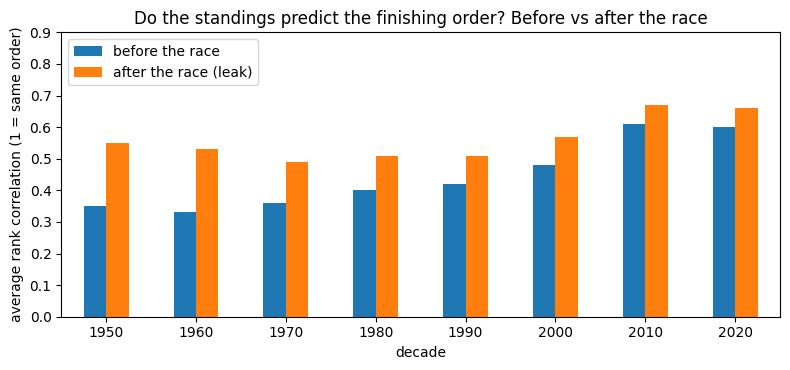

In [127]:
def rank_corr(a, b):
    return np.nan if a.nunique() < 2 or b.nunique() < 2 else a.corr(b)

# rank by points before the race, rank by points after the race, and the real finishing order
later['rank_before'] = later.groupby('raceId').points_before.rank(ascending=False)
later['rank_after'] = later.groupby('raceId').points_after.rank(ascending=False)
later['finish'] = later.groupby('raceId').positionOrder.rank()

leak = pd.DataFrame({
    'before the race': {r: rank_corr(g.rank_before, g['finish']) for r, g in later.groupby('raceId')},
    'after the race (leak)': {r: rank_corr(g.rank_after, g['finish']) for r, g in later.groupby('raceId')}
}).dropna()

year_of = races.set_index('raceId').year
by_decade = leak.groupby(leak.index.map(year_of) // 10 * 10).mean().round(2)
display(by_decade.T)
print('average rank correlation over all races:', leak.mean().round(2).to_dict())

# does the race winner lead the standings after the race, versus before it?
leader_after = ds[ds.position == 1].drop_duplicates('raceId').set_index('raceId').driverId
prev_race = (races.sort_values(['year', 'round'])
             .assign(prev=lambda t: t.groupby('year').raceId.shift(1))
             .set_index('raceId').prev)
winners = results_unique[results_unique.positionOrder == 1].groupby('raceId').driverId.agg(set)

after_ok = [leader_after[r] in winners[r] for r in winners.index if r in leader_after.index]
before_ok = [leader_after[prev_race[r]] in winners[r] for r in winners.index
             if pd.notna(prev_race[r]) and prev_race[r] in leader_after.index]
print('winner leads the standings AFTER the race in', round(np.mean(after_ok) * 100, 1),
      '% of races, but led them BEFORE the race in', round(np.mean(before_ok) * 100, 1), '% (round 2 onward)')

# figure
by_decade.plot.bar(figsize=(8, 3.8), rot=0,
                   title='Do the standings predict the finishing order? Before vs after the race')
plt.xlabel('decade')
plt.ylabel('average rank correlation (1 = same order)')
plt.ylim(0, 0.9)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


### driver_standings: how much the same-race standings would leak

**Rank correlation.** For each race we compared the ranking by championship points with the real finishing order. Averaged over all races, the correlation is 0.46 using the standings before the race and 0.57 using the standings after it. The gap is widest in the 1950s (0.35 against 0.55) and narrows to 0.06 in the 2010s (0.61 against 0.67) and in the 2020s (0.60 against 0.66).

**Winners and the standings.** The race winner leads the championship after the race in 48.4% of races, but was already leading it before the race in 32.8% of races from round 2 onward.

**Decision.** The same-race standing carries that race's result, so it is never used as a feature. The standing from the previous round of the same season is safe, and in the modern era it already tracks the finishing order closely (correlation about 0.6), so it is a useful feature.

In [128]:
season_total = scored.groupby(['year', 'driverId']).scored.sum()      # all points scored in the season
final_row = (ds.sort_values('round').groupby(['year', 'driverId']).tail(1)
             .set_index(['year', 'driverId']).points)                  # final standing points
gap = final_row - season_total.reindex(final_row.index).fillna(0)

lower = gap[gap < -1e-6]
higher = gap[gap > 1e-6]
print('driver-seasons whose final standing is LOWER than points scored:', len(lower),
      '| seasons', int(lower.index.get_level_values(0).min()), 'to', int(lower.index.get_level_values(0).max()))
print('driver-seasons whose final standing is HIGHER:', len(higher))

worst = gap.nsmallest(5).index
big = (pd.DataFrame({'points scored': season_total.reindex(worst),
                     'final standing': final_row.reindex(worst)})
       .reset_index().merge(drivers[['driverId', 'surname']], on='driverId'))
display(big[['surname', 'year', 'points scored', 'final standing']])
print('seasons with a LOWER gap:', sorted(lower.index.get_level_values(0).unique().tolist()))


driver-seasons whose final standing is LOWER than points scored: 50 | seasons 1950 to 1990
driver-seasons whose final standing is HIGHER: 3


,surname,year,points scored,final standing
0,Clark,1963,73.00,54.0
1,Prost,1988,105.00,87.0
2,Ascari,1952,53.50,36.0
3,Fangio,1954,57.14,42.0
4,Ascari,1953,45.50,34.5


seasons with a LOWER gap: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967, 1979, 1980, 1985, 1986, 1987, 1988, 1989, 1990]


In [129]:
print(gap[gap > 1e-6].rename('standing minus scored').reset_index()
      .merge(drivers[['driverId', 'surname']], on='driverId')
      [['surname', 'year', 'standing minus scored']])

       surname  year  standing minus scored
0       Farina  1955                   1.33
1       Fangio  1950                   1.00
2  Trintignant  1955                   1.33


In [130]:
res_raw = raw_before['results']

targets = [('Farina', 1955), ('Trintignant', 1955), ('Fangio', 1950)]
for surname, yr in targets:
    did = drivers.loc[drivers.surname == surname, 'driverId'].tolist()
    rid = races.loc[races.year == yr, ['raceId', 'round', 'name']]

    raw = (res_raw[res_raw.driverId.isin(did)]
           .merge(rid, on='raceId')
           .sort_values('round'))
    kept = set(results_unique.resultId)
    raw['kept_by_dedup'] = raw.resultId.isin(kept)

    print(f'\n{surname} {yr}')
    display(raw[['round', 'name', 'constructorId', 'positionOrder', 'points', 'kept_by_dedup']])
    print('points in raw rows:   ', raw.points.sum())
    print('points in kept rows:  ', raw.loc[raw.kept_by_dedup, 'points'].sum())



Farina 1955


,round,name,constructorId,positionOrder,points,kept_by_dedup
0,1,Argentine Grand Prix,6,3,1.33,False
4,1,Argentine Grand Prix,6,2,2.00,True
1,2,Monaco Grand Prix,6,4,3.00,True
2,4,Belgian Grand Prix,6,3,4.00,True
3,7,Italian Grand Prix,6,21,0.00,True


points in raw rows:    10.33
points in kept rows:   9.0

Trintignant 1955


,round,name,constructorId,positionOrder,points,kept_by_dedup
0,1,Argentine Grand Prix,6,11,0.00,False
7,1,Argentine Grand Prix,6,3,1.33,False
6,1,Argentine Grand Prix,6,2,2.00,True
1,2,Monaco Grand Prix,6,1,8.00,True
2,4,Belgian Grand Prix,6,6,0.00,True
3,5,Dutch Grand Prix,6,12,0.00,True
4,6,British Grand Prix,6,10,0.00,True
5,7,Italian Grand Prix,6,8,0.00,True


points in raw rows:    11.33
points in kept rows:   10.0

Fangio 1950


,round,name,constructorId,positionOrder,points,kept_by_dedup
0,1,British Grand Prix,51,12,0.0,True
1,2,Monaco Grand Prix,51,1,9.0,True
2,4,Swiss Grand Prix,51,12,0.0,True
3,5,Belgian Grand Prix,51,1,8.0,True
4,6,French Grand Prix,51,1,9.0,True
5,7,Italian Grand Prix,51,15,1.0,False
6,7,Italian Grand Prix,51,13,0.0,True


points in raw rows:    27.0
points in kept rows:   26.0


**Final standings can be lower than the points scored.** For 50 driver-seasons, all between 1950 and 1990, the final standing is lower than the sum of the points the driver scored. The biggest gaps are Clark in 1963 (73 points scored, 54 in the standings), Prost in 1988 (105 and 87), and Ascari in 1952 (53.5 and 36). This fits seasons in which only a driver's best results counted toward the championship, which is general Formula 1 knowledge and not something the table shows. From 1991 on the two always agree. Three driver-seasons go the other way, with a final standing higher than the points scored, Farina and Trintignant in 1955 (1.33 points each) and Fangio in 1950 (1 point). In each case the standing counts points from a shared drive, a second row for the same driver and race, that our duplicate rule removed. The removed points match the gaps exactly, so the standings are correct and the difference comes from keeping only the row with the best finishing position.

**Points in the two tables.** `results.points` is what a driver scored in one race, and `driver_standings.points` is the running total for the season, so the standings points are the cumulative sum of the race points except in the seasons above. For this reason, features use the standings only through the previous round and never the same-race row.

**Decimal points.** `points` has decimals in some old seasons. The shared drives we checked (Farina and Trintignant in 1955, Fangio in 1950) show that a car shared between drivers split its points, which gives values such as 1.33. We may not use these seasons for modelling.


## `Constructor Standings Table`

In [131]:
constructor_standings = load('constructor_standings')

print('shape:', constructor_standings.shape)
display(constructor_standings.head())
print(constructor_standings.dtypes)
print('\nmissing per column:')
print(constructor_standings.isna().sum())

shape: (13391, 7)


,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1
1,2,18,2,8.0,3,3,0
2,3,18,3,9.0,2,2,0
3,4,18,4,5.0,4,4,0
4,5,18,5,2.0,5,5,0


constructorStandingsId      int64
raceId                      int64
constructorId               int64
points                    float64
position                    int64
positionText               object
wins                        int64
dtype: object

missing per column:
constructorStandingsId    0
raceId                    0
constructorId             0
points                    0
position                  0
positionText              0
wins                      0
dtype: int64


In [132]:
cs_raw = constructor_standings.copy()

# keys
print('constructorStandingsId nulls:      ', cs_raw.constructorStandingsId.isna().sum())
print('constructorStandingsId duplicates: ', cs_raw.constructorStandingsId.duplicated().sum())
print('(raceId, constructorId) duplicates:', cs_raw.duplicated(['raceId', 'constructorId']).sum())

# links to other tables
print('raceIds not in races:              ', (~cs_raw.raceId.isin(races.raceId)).sum())
print('constructorIds not in constructors:', (~cs_raw.constructorId.isin(constructors.constructorId)).sum())
print('races without any standings:       ', (~races.raceId.isin(cs_raw.raceId)).sum(), 'of', len(races))

# one row per race and constructor, in season order
cs = (cs_raw.merge(races[['raceId', 'year', 'round', 'name']], on='raceId')
      .sort_values(['year', 'constructorId', 'round']))

# which years have standings at all?
print('first season with standings:', cs.year.min(), '| last:', cs.year.max())
no_cs = races[~races.raceId.isin(cs_raw.raceId)]
print('seasons of the races without standings:', sorted(no_cs.year.unique().tolist()))

# is it a running total inside a season?
cs['added'] = cs.groupby(['year', 'constructorId']).points.diff().fillna(cs.points)
cs['wins_added'] = cs.groupby(['year', 'constructorId']).wins.diff().fillna(cs.wins)
print('points ever go down in a season:', int((cs.added < 0).sum()),
      '| wins ever go down:', int((cs.wins_added < 0).sum()))

constructorStandingsId nulls:       0
constructorStandingsId duplicates:  0
(raceId, constructorId) duplicates: 0
raceIds not in races:               0
constructorIds not in constructors: 0
races without any standings:        64 of 1125
first season with standings: 1958 | last: 2024
seasons of the races without standings: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957]
points ever go down in a season: 2 | wins ever go down: 0


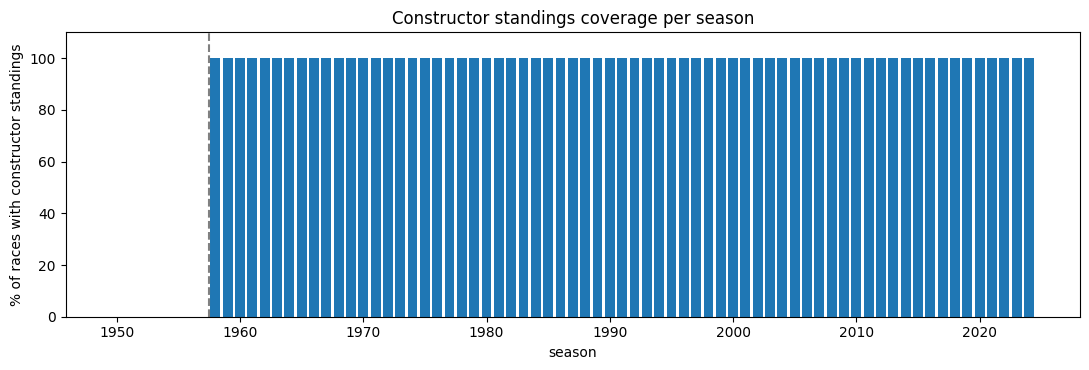

seasons with no standings: 1950 to 1957
seasons with partial coverage: []


In [133]:
cov = (races.assign(has_cs=races.raceId.isin(constructor_standings.raceId))
       .groupby('year').has_cs.mean() * 100)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(cov.index, cov.values, color=['tab:red' if y < 1958 else 'tab:blue' for y in cov.index])
ax.axvline(1957.5, linestyle='--', color='gray')
ax.set_ylim(0, 110)
ax.set_xlabel('season')
ax.set_ylabel('% of races with constructor standings')
ax.set_title('Constructor standings coverage per season')
plt.tight_layout()
plt.show()

print('seasons with no standings:', cov[cov == 0].index.min(), 'to', cov[cov == 0].index.max())
print('seasons with partial coverage:', cov[(cov > 0) & (cov < 100)].index.tolist())


In [134]:
down = cs[cs.added < 0].merge(constructors[['constructorId', 'name']], on='constructorId', suffixes=('', '_constructor'))
print(down[['year', 'round', 'name_constructor', 'points', 'added']])

# the rows around them, to see what happened
for _, r in down.iterrows():
    print(cs[(cs.constructorId == r.constructorId) & (cs.year == r.year)]
          [['round', 'points', 'position', 'wins']].to_string(index=False))


   year  round name_constructor  points  added
0  2018     13      Force India    18.0  -41.0
1  2020      5     Racing Point    41.0   -1.0
 round  points  position  wins
     1     0.0         6     0
     2     1.0         9     0
     3     1.0         9     0
     4    16.0         6     0
     5    18.0         7     0
     6    26.0         6     0
     7    28.0         6     0
     8    28.0         6     0
     9    42.0         7     0
    10    49.0         6     0
    11    59.0         5     0
    12    59.0         6     0
    13    18.0         9     0
    14    32.0         7     0
    15    32.0         7     0
    16    35.0         7     0
    17    43.0         7     0
    18    47.0         7     0
    19    47.0         7     0
    20    48.0         7     0
    21    52.0         7     0
 round  points  position  wins
     1     8.0         4     0
     2    22.0         4     0
     3    40.0         4     0
     4    42.0         5     0
     5    41.0        

### constructor_standings: structure, keys and coverage

**Grain.** The table has 13,391 rows and 7 columns. One row is a constructor's championship standing right after one race. `points` and `wins` are running totals for the season, and `position` is the championship rank at that moment, not a finishing place. It has the same structure as `driver_standings`, with `constructorId` in place of `driverId`.

**Types and missing values.** The IDs, `position` and `wins` are integers, `points` is a float and `positionText` is text. No column has missing values, so nothing needed converting.

**Primary key.** `constructorStandingsId` has 0 nulls and 0 duplicates, so it is a valid primary key. The natural key `(raceId, constructorId)` also has 0 duplicates.

**Foreign keys.** Every `raceId` exists in `races` and every `constructorId` exists in `constructors`, so there are no orphans.

**Coverage.** Standings start in 1958. The 64 races without any constructor standings are exactly the seasons 1950 to 1957, and every race from 1958 on has standings. Features built from this table are therefore missing for those early seasons, which only matters if the training window starts before 1958.

**Running total.** Wins never go down inside a season, and points go down in only two rows (Force India 2018 and Racing Point 2020). The next section explains both.

**Leakage.** As in `driver_standings`, a row is the standing after the race. For a feature on a given race we use the row from the previous round of the same season, ordered by `(year, round)`, and never the same-race row.

**Next.** Investigate the two points drops, and check that constructor points match the sum of both cars' race points.


In [135]:
cr = raw_before['constructor_results'][['raceId', 'constructorId', 'points']].rename(columns={'points': 'race_points'})

# (b) is a row written AFTER its race? points added vs the team's points in constructor_results
m = cs.merge(cr, on=['raceId', 'constructorId'], how='left')
raced = m[m.race_points.notna()]
same = (raced.added - raced.race_points).abs() < 1e-6
print('rows of teams with a result in that race:', len(raced),
      '| points added = the team points of that race:', int(same.sum()), f'({same.mean() * 100:.1f}%)')
print('rows that disagree:', int((~same).sum()),
      '| before 1980:', int((raced[~same].year < 1980).sum()),
      '| other seasons:', sorted(raced[~same & (raced.year >= 1980)].year.unique().tolist()))

# the two points drops, next to what the team scored that race
drops = cs[cs.added < 0].merge(constructors[['constructorId', 'name']], on='constructorId', suffixes=('', '_team'))
display(drops.merge(cr, on=['raceId', 'constructorId'], how='left')
        [['year', 'round', 'name_team', 'points', 'added', 'race_points']])

# (d) the safe version: standing before the race = previous round's row
x = (cr.merge(races[['raceId', 'year', 'round']], on='raceId')
       .query('year >= 1958').sort_values(['year', 'constructorId', 'round']))
x['scored_before'] = x.groupby(['year', 'constructorId']).race_points.cumsum() - x.race_points
previous = (cs[['year', 'constructorId', 'round', 'points']]
            .assign(round=lambda t: t['round'] + 1).rename(columns={'points': 'points_before'}))
x = x.merge(previous, on=['year', 'constructorId', 'round'], how='left')
later = x[x['round'] > 1].fillna({'points_before': 0})
agree = (later.points_before - later.scored_before).abs() < 1e-6
print('team starts after round 1:', len(later),
      '| standing-before = points scored earlier:', round(agree.mean() * 100, 1), '%')
print('by decade (%):', (agree.groupby(later.year // 10 * 10).mean() * 100).round(1).to_dict())


rows of teams with a result in that race: 12497 | points added = the team points of that race: 12412 (99.3%)


rows that disagree: 85 | before 1980: 81 | other seasons: [2007, 2018, 2020]


,year,round,name_team,points,added,race_points
0,2018,13,Force India,18.0,-41.0,18.0
1,2020,5,Racing Point,41.0,-1.0,14.0


team starts after round 1: 11847 | standing-before = points scored earlier: 98.8 %
by decade (%): {1950: 94.2, 1960: 93.1, 1970: 96.5, 1980: 100.0, 1990: 100.0, 2000: 99.8, 2010: 99.6, 2020: 98.8}


In [136]:
bad = raced[~same & (raced.year >= 1980)].merge(constructors[['constructorId', 'name']], on='constructorId', suffixes=('', '_team'))
print(bad[['year', 'round', 'name_team', 'points', 'added', 'race_points']])

   year  round     name_team  points  added  race_points
0  2007     11       McLaren   138.0    0.0         15.0
1  2007     14       McLaren   192.0   26.0         11.0
2  2018     13   Force India    18.0  -41.0         18.0
3  2020      5  Racing Point    41.0   -1.0         14.0


### constructor_standings: the points drops and the check against constructor_results

**Running total.** Wins never go down inside a season. Points go down in two rows only. Force India in 2018 drops from 59 points after round 12 to 18 after round 13, and Racing Point in 2020 drops from 42 to 41 at round 5. After each drop the totals grow normally again, but from the lower number. In `constructor_results`, Force India scored 18 points in that race, which equals its new total, so the earlier points disappeared from the table, and Racing Point scored 14 points yet the total fell by 1, so about 15 points are missing. The table does not show the cause. These drops match two known events, which are general Formula 1 knowledge and not shown by the table, the change of ownership of Force India in 2018, after which the team's constructors' points were removed, and a points penalty given to Racing Point in 2020. We keep both rows, because they record what the championship table showed. Features read the previous-round points directly and do not use differences between rounds, so these rows cannot produce a negative value.

**Written after the race.** Of 12,497 standing rows with a result in that race, 12,412 (99.3%) add exactly the points the team scored, so a row is the standing after the race. The 85 that disagree are mostly before 1980 (81), where best-results rules and shared drives apply and which we do not investigate further, and the rest are in 2007, 2018 and 2020. The 2007 rows are McLaren in rounds 11 and 14. In round 11 the team scored 15 points in the race but the standing added 0, and in round 14 it scored 11 but the standing added 26, which is 15 plus 11. The points of round 11 therefore appear in the table three rounds late. The table does not show why, and we keep the rows as they are. The previous-round standing equals the points scored in earlier races in 98.8% of cases, and 100% in the 1980s and 1990s, so it is a safe pre-race value.

**What we check next.** We compare every team that started a race from 1958 on with the rows in the standings, in both directions. This is the team version of the 8,664 rows we looked at for drivers. First, standings rows for a team that did not start that race. Second, team starts with no standings row, and whether any of those teams scored points, because a missing row for a team that scored would leave a gap in the previous-round feature.

**Sprint points.** For 2021 to 2024 we also test whether the constructor standings include sprint points, by comparing the points added in each row with `constructor_results` alone, and with `constructor_results` plus the sprint points of the same weekend. For drivers the sum of Sunday and sprint matched 100% of rows, and we check whether the team table behaves the same way.



In [137]:
# team starts (1958 on) vs standings rows
team_starts = (results_unique.merge(races[['raceId', 'year']], on='raceId')
               .query('year >= 1958')[['raceId', 'constructorId']].drop_duplicates())
cmp = cs[['raceId', 'constructorId']].merge(team_starts.assign(started=1),
                                            on=['raceId', 'constructorId'], how='outer', indicator=True)
cmp = cmp[cmp.raceId.isin(races[races.year >= 1958].raceId)]
print('standings rows for a team that did not start:', int((cmp._merge == 'left_only').sum()),
      '| team starts with no standings row:', int((cmp._merge == 'right_only').sum()))

# which of those missing rows scored points?
tp = (results_unique.groupby(['raceId', 'constructorId']).points.sum().reset_index()
      .merge(races[['raceId', 'year', 'name']], on='raceId').query('year >= 1958')
      .merge(cs[['raceId', 'constructorId']].assign(has_row=1), on=['raceId', 'constructorId'], how='left'))
no_row = tp[tp.has_row.isna()]
scoring = no_row[no_row.points > 0].merge(constructors[['constructorId', 'name']], on='constructorId', suffixes=('', '_team'))
print('team starts with no standings row:', len(no_row), '| that scored points:', len(scoring))
print(scoring[['year', 'name', 'name_team', 'points']].head(10))

# sprint points, 2021-2024
sprint_team = (raw_before['sprint_results'].groupby(['raceId', 'constructorId']).points.sum()
               .rename('sprint_points').reset_index())
recent = (cs.merge(cr, on=['raceId', 'constructorId'], how='left')
            .query('year >= 2021').merge(sprint_team, on=['raceId', 'constructorId'], how='left')
            .fillna({'sprint_points': 0, 'race_points': 0}))
print('2021-2024: added = constructor_results:', round(((recent.added - recent.race_points).abs() < 1e-6).mean() * 100, 1),
      '% | = constructor_results + sprint:', round(((recent.added - recent.race_points - recent.sprint_points).abs() < 1e-6).mean() * 100, 1), '%')


standings rows for a team that did not start: 893 | team starts with no standings row: 129
team starts with no standings row: 129 | that scored points: 10
   year              name     name_team  points
0  1960  Indianapolis 500        Watson    14.0
1  1960  Indianapolis 500       Epperly     4.0
2  1960  Indianapolis 500      Phillips     3.0
3  1960  Indianapolis 500      Lesovsky     2.0
4  1960  Indianapolis 500        Trevis     1.0
5  1959  Indianapolis 500        Watson    14.0
6  1959  Indianapolis 500       Epperly     5.0
7  1959  Indianapolis 500      Lesovsky     5.0
8  1958  Indianapolis 500       Epperly    20.0
9  1958  Indianapolis 500  Kurtis Kraft     4.0
2021-2024: added = constructor_results: 100.0 % | = constructor_results + sprint: 90.9 %


### constructor_standings: who has a standings row, and sprint points

**Result.** 893 standings rows belong to a team that did not start that race, so the table keeps teams that skipped a round, as it does for drivers. 129 team starts from 1958 on have no standings row, and only 10 of them scored points. All 10 are Indianapolis 500 races from 1958 to 1960, by teams that raced nowhere else, so their points never reached the constructor standings. The Indianapolis 500 rows are excluded from the modelling table, so these gaps do not matter, and the other 119 missing rows scored no points. For 2021 to 2024, the points added match `constructor_results` in 100% of rows, and adding sprint points on top lowers the match to 90.9%. The reason is that `constructor_results` already includes the sprint points, which we confirmed in the next section, where the 82 team-races with sprint points differ from the drivers' summed race points and agree once the sprint is added. The constructor standings therefore include sprint points, in the same way as the driver standings.

## `Constructor Results Table`

In [138]:
constructor_results = load('constructor_results')

print('shape:', constructor_results.shape)
display(constructor_results.head())
print(constructor_results.dtypes)
print('\nmissing per column:')
print(constructor_results.isna().sum())

shape: (12625, 5)


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN


constructorResultsId      int64
raceId                    int64
constructorId             int64
points                  float64
status                   object
dtype: object

missing per column:
constructorResultsId        0
raceId                      0
constructorId               0
points                      0
status                  12608
dtype: int64


In [139]:
cr_raw = constructor_results.copy()

# keys
print('constructorResultsId nulls:      ', cr_raw.constructorResultsId.isna().sum())
print('constructorResultsId duplicates: ', cr_raw.constructorResultsId.duplicated().sum())
print('(raceId, constructorId) duplicates:', cr_raw.duplicated(['raceId', 'constructorId']).sum())

# links
print('raceIds not in races:              ', (~cr_raw.raceId.isin(races.raceId)).sum())
print('constructorIds not in constructors:', (~cr_raw.constructorId.isin(constructors.constructorId)).sum())

# coverage by year
crr = cr_raw.merge(races[['raceId', 'year', 'round', 'name']], on='raceId')
no_rows = races[~races.raceId.isin(cr_raw.raceId)]
print('seasons with rows:', crr.year.min(), 'to', crr.year.max(),
      '| races with rows:', cr_raw.raceId.nunique(), 'of', len(races))
print('races with no rows: before 1958 =', int((no_rows.year < 1958).sum()),
      '| from 1958 on =', no_rows[no_rows.year >= 1958][['year', 'name']].values.tolist())

# the status column
print('\nstatus values:', cr_raw.status.value_counts(dropna=False).to_dict())
flagged = crr[crr.status.notna()].merge(constructors[['constructorId', 'name']],
                                         on='constructorId', suffixes=('', '_team'))
print(flagged[['year', 'round', 'name_team', 'points', 'status']])


constructorResultsId nulls:       0
constructorResultsId duplicates:  0
(raceId, constructorId) duplicates: 0
raceIds not in races:               0
constructorIds not in constructors: 0
seasons with rows: 1958 to 2024 | races with rows: 1060 of 1125
races with no rows: before 1958 = 64 | from 1958 on = [[1958, 'Indianapolis 500']]

status values: {nan: 12608, 'D': 17}
    year  round name_team  points status
0   2007      1   McLaren    14.0      D
1   2007      2   McLaren    18.0      D
2   2007      3   McLaren    12.0      D
3   2007      4   McLaren    14.0      D
4   2007      5   McLaren    18.0      D
5   2007      6   McLaren    12.0      D
6   2007      7   McLaren    18.0      D
7   2007      8   McLaren     8.0      D
8   2007      9   McLaren    14.0      D
9   2007     10   McLaren    10.0      D
10  2007     11   McLaren    15.0      D
11  2007     12   McLaren    10.0      D
12  2007     13   McLaren    18.0      D
13  2007     14   McLaren    11.0      D
14  2007     1

In [140]:
mc_id = flagged.constructorId.iloc[0]

res_mc = (results_unique[results_unique.constructorId == mc_id]
          .merge(races[['raceId', 'year']], on='raceId').query('year == 2007'))
print('McLaren 2007 result rows:', len(res_mc))
print(res_mc.positionText.value_counts().to_dict())

cs_mc = cs[(cs.constructorId == mc_id) & (cs.year == 2007)]
print('constructor_standings positionText in 2007:', cs_mc.positionText.value_counts().to_dict())
print('constructor_standings positionText "E" rows overall:', int((cs.positionText == 'E').sum()))

McLaren 2007 result rows: 34
{'2': 9, '1': 8, '3': 7, '7': 3, '5': 2, '4': 2, 'R': 2, '9': 1}
constructor_standings positionText in 2007: {'E': 17}
constructor_standings positionText "E" rows overall: 17


### constructor_results: structure, keys, coverage and the status column

**Grain.** The table has 12,625 rows and 5 columns. One row is one team's score in one race, so `points` is what the team scored in that race and not a running total.

**Types and missing values.** The IDs are integers, `points` is a float and `status` is text. Only `status` has missing values, 12,608 of 12,625 rows, so the column is blank except for 17 rows.

**Primary key.** `constructorResultsId` has 0 nulls and 0 duplicates, so it is a valid primary key. The natural key `(raceId, constructorId)` also has 0 duplicates.

**Foreign keys.** Every `raceId` exists in `races` and every `constructorId` exists in `constructors`, so there are no orphans.

**Coverage.** Rows exist from 1958 to 2024 for 1,060 of the 1,125 races. The 65 races without rows are the 64 races of 1950 to 1957 and the 1958 Indianapolis 500.

**The status column.** The only value is `D`, in 17 rows, and all 17 belong to McLaren in 2007, one for each of its 17 races. The table does not say what `D` means. It is general Formula 1 knowledge, not shown by the table, that McLaren was removed from the 2007 constructors' championship, which fits a flag on every race of that team and season. In `results`, McLaren's 2007 rows are normal (8 wins, 9 second places, 7 third places), so the flag does not affect the drivers' race results. In `constructor_standings` the same 17 team-races carry `positionText` `E`, a value that appears nowhere else in that table, so `D` and `E` appear to mark the same team-season. McLaren's points still appear in both tables, so the flag, and not the points, marks the exclusion.

**Decision.** We keep the rows and do not use `status` as a feature, because it is blank apart from one team and one season. The drivers' race results of McLaren in 2007 stay in the modelling table. How team-form features treat that team-season is decided at the feature step.

team-races compared:

 12617 | team score = drivers sum: 12233 (96.96%) | = drivers sum + sprint: 12315 (97.61%)


from 1979 on, not equal (with sprint): 0 of 9911
2021-2024: differences from drivers sum: 82 | team-races with sprint points: 82 | equal once sprint is added: 82
differences left: 302 | seasons 1958 to 1978 | team scored less than its drivers: 302
reasons: {'only the best car counted': 292, 'best car minus 1 point': 9, 'something else': 1}


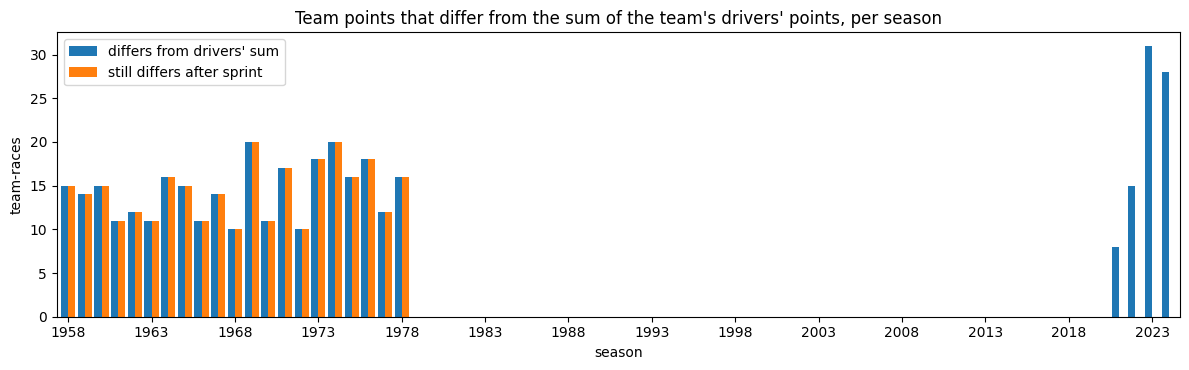

In [141]:
# drivers' side: points per team per race from the deduplicated results
drivers_side = (results_unique.groupby(['raceId', 'constructorId'])
                .agg(drivers_sum=('points', 'sum'), best_car=('points', 'max'), cars=('points', 'size'))
                .reset_index())

# sprint points per team per race
sprint_team = (raw_before['sprint_results'].groupby(['raceId', 'constructorId']).points.sum()
               .rename('sprint_points').reset_index())

j = (crr.merge(drivers_side, on=['raceId', 'constructorId'])
        .merge(sprint_team, on=['raceId', 'constructorId'], how='left')
        .fillna({'sprint_points': 0}))
j['same_as_drivers'] = (j.points - j.drivers_sum).abs() < 1e-6
j['same_with_sprint'] = (j.points - j.drivers_sum - j.sprint_points).abs() < 1e-6

print('team-races compared:', len(j),
      '| team score = drivers sum:', int(j.same_as_drivers.sum()), f'({j.same_as_drivers.mean() * 100:.2f}%)',
      '| = drivers sum + sprint:', int(j.same_with_sprint.sum()), f'({j.same_with_sprint.mean() * 100:.2f}%)')

late = j[j.year >= 1979]
print('from 1979 on, not equal (with sprint):', int((~late.same_with_sprint).sum()), 'of', len(late))

rec = j[j.year >= 2021]
print('2021-2024: differences from drivers sum:', int((~rec.same_as_drivers).sum()),
      '| team-races with sprint points:', int((rec.sprint_points > 0).sum()),
      '| equal once sprint is added:', int(rec[rec.sprint_points > 0].same_with_sprint.sum()))

# the differences that are left, and a first guess at why (old seasons)
old = j[~j.same_with_sprint]
reason = np.select([(old.points - old.best_car).abs() < 1e-6,
                    (old.points - (old.best_car - 1)).abs() < 1e-6],
                   ['only the best car counted', 'best car minus 1 point'], 'something else')
print('differences left:', len(old), '| seasons', int(old.year.min()), 'to', int(old.year.max()),
      '| team scored less than its drivers:', int((old.points < old.drivers_sum).sum()))
print('reasons:', pd.Series(reason).value_counts().to_dict())

# per-season picture
by_season = pd.DataFrame({
    "differs from drivers' sum": j[~j.same_as_drivers].groupby('year').size(),
    'still differs after sprint': j[~j.same_with_sprint].groupby('year').size()
}).reindex(range(1958, 2025), fill_value=0).fillna(0)
ax = by_season.plot.bar(figsize=(12, 3.8), width=0.85,
                        title="Team points that differ from the sum of the team's drivers' points, per season")
ax.set_xticks(range(0, len(by_season), 5))
ax.set_xticklabels(by_season.index[::5], rotation=0)
plt.xlabel('season')
plt.ylabel('team-races')
plt.tight_layout()
plt.show()


**Team score against the drivers' points.** For 12,617 team-races, the team's points in `constructor_results` equal the sum of its drivers' points in `results` in 96.96% of cases, and 97.61% once sprint points are added. From 1979 on, all 9,911 team-races agree. In 2021 to 2024, 82 team-races differ from the drivers' sum, which are exactly the 82 with sprint points, and all 82 agree once the sprint is added, so `constructor_results` already includes sprint points. The 302 remaining differences are all between 1958 and 1978, and in every one the team scored less than its drivers. In 292 of them the team score equals its best car's points, in 9 it equals the best car minus one point, and 1 is unexplained. This fits seasons in which only the best car counted for the team, which is general Formula 1 knowledge and not shown by the table.

## `Sprint Results Table`

In [142]:
sprint_results = load('sprint_results')

print('shape:', sprint_results.shape)
display(sprint_results.head())
print(sprint_results.dtypes)
print('\nmissing per column:')
print(sprint_results.isna().sum())

shape: (360, 16)


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1.0,1,1,3,17,25:38.426,1538426.0,14.0,1:30.013,1
1,2,1061,1,131,44,1,2.0,2,2,2,17,+1.430,1539856.0,17.0,1:29.937,1
2,3,1061,822,131,77,3,3.0,3,3,1,17,+7.502,1545928.0,17.0,1:29.958,1
3,4,1061,844,6,16,4,4.0,4,4,0,17,+11.278,1549704.0,16.0,1:30.163,1
4,5,1061,846,1,4,6,5.0,5,5,0,17,+24.111,1562537.0,16.0,1:30.566,1


resultId            int64
raceId              int64
driverId            int64
constructorId       int64
number              int64
grid                int64
position          float64
positionText       object
positionOrder       int64
points              int64
laps                int64
time               object
milliseconds      float64
fastestLap        float64
fastestLapTime     object
statusId            int64
dtype: object

missing per column:
resultId           0
raceId             0
driverId           0
constructorId      0
number             0
grid               0
position          15
positionText       0
positionOrder      0
points             0
laps               0
time              20
milliseconds      20
fastestLap         9
fastestLapTime     9
statusId           0
dtype: int64


In [143]:
sp = sprint_results

print('resultId nulls:', sp.resultId.isna().sum(), '| duplicates:', sp.resultId.duplicated().sum())
print('(raceId, driverId) duplicates:', sp.duplicated(['raceId', 'driverId']).sum())

print('raceIds not in races:              ', (~sp.raceId.isin(races.raceId)).sum())
print('driverIds not in drivers:          ', (~sp.driverId.isin(drivers.driverId)).sum())
print('constructorIds not in constructors:', (~sp.constructorId.isin(constructors.constructorId)).sum())
print('statusIds not in status:           ', (~sp.statusId.isin(status.statusId)).sum())

resultId nulls: 0 | duplicates: 0
(raceId, driverId) duplicates: 0
raceIds not in races:               0
driverIds not in drivers:           0
constructorIds not in constructors: 0
statusIds not in status:            0


In [144]:
spr = sp.merge(races[['raceId', 'year', 'round', 'name']], on='raceId')
per_sprint = sp.groupby('raceId').size()
print('rows:', len(sp), '| sprints:', len(per_sprint), '| rows per sprint:', per_sprint.value_counts().to_dict())
print('same sprints as races.sprint_date:', set(sp.raceId) == set(races[races.sprint_date.notna()].raceId))

cov = pd.DataFrame({'races': races[races.year >= 2021].groupby('year').size(),
                    'with a sprint': spr.groupby('year').raceId.nunique()}).fillna(0).astype(int)
cov['share %'] = (cov['with a sprint'] / cov['races'] * 100).round(0)
display(cov)

rows: 360 | sprints: 18 | rows per sprint: {20: 18}
same sprints as races.sprint_date: True


,races,with a sprint,share %
year,,,
2021,22,3,14.0
2022,22,3,14.0
2023,22,6,27.0
2024,24,6,25.0


In [145]:
order = sp.groupby('raceId').positionOrder.agg(['min', 'max', 'nunique', 'size'])
print('finishing order is exactly 1..n:',
      bool(((order['min'] == 1) & (order['max'] == order['size']) & (order['nunique'] == order['size'])).all()))

finishing order is exactly 1..n: True


In [146]:
outcome = sp.statusId.map(status.set_index('statusId').status)
empty = pd.DataFrame({c: [int(sp[c].isna().sum()), int((sp[c].isna() & (outcome == 'Finished')).sum())]
                      for c in ['position', 'time', 'milliseconds', 'fastestLap', 'fastestLapTime']},
                     index=['empty cells', 'of them for a driver who Finished']).T
display(empty)
print('time empty together with milliseconds:', bool((sp.time.isna() == sp.milliseconds.isna()).all()))
print('fastestLap empty together with fastestLapTime:', bool((sp.fastestLap.isna() == sp.fastestLapTime.isna()).all()))

,empty cells,of them for a driver who Finished
position,15,0
time,20,0
milliseconds,20,0
fastestLap,9,0
fastestLapTime,9,0


time empty together with milliseconds: True
fastestLap empty together with fastestLapTime: True


In [147]:
sd = races[races.sprint_date.notna()].assign(days_before=lambda t: (t.date - t.sprint_date).dt.days)
print('days between sprint and Sunday race:', sd.days_before.value_counts().to_dict())

days between sprint and Sunday race: {1: 18}


In [148]:
print('fastestLapTime patterns:')
print(sp.fastestLapTime.dropna().str.replace(r'\d', '9', regex=True).value_counts().to_dict())

print('\ntime patterns:')
print(sp.time.dropna().str.replace(r'\d', '9', regex=True).value_counts().to_dict())


fastestLapTime patterns:
{'9:99.999': 351}

time patterns:
{'+99.999': 259, '+9.999': 38, '+9:99.999': 25, '99:99.999': 18}


In [149]:
sp = sprint_results.copy()

parts = sp.fastestLapTime.str.split(':', expand=True)
sp['fastestLapTime_s'] = parts[0].astype(float) * 60 + parts[1].astype(float)

print('filled before / after:', sp.fastestLapTime.notna().sum(), '/', sp.fastestLapTime_s.notna().sum())
print('range (s):', sp.fastestLapTime_s.min(), 'to', sp.fastestLapTime_s.max())
display(sp[['fastestLapTime', 'fastestLapTime_s']].dropna().head())

filled before / after: 351 / 351
range (s): 68.321 to 124.76


,fastestLapTime,fastestLapTime_s
0,1:30.013,90.013
1,1:29.937,89.937
2,1:29.958,89.958
3,1:30.163,90.163
4,1:30.566,90.566


### sprint_results: structure, keys, coverage and missing values

**Grain.** The table has 360 rows and 16 columns, with the same columns as `results`. One row is one driver's result in one sprint. It covers 18 sprints with exactly 20 rows each, 3 in 2021, 3 in 2022, 6 in 2023 and 6 in 2024, which is 14% to 27% of each season's races. They are exactly the 18 races that have a `sprint_date` in `races`.

**Types.** `points` is an integer here, because sprint points are whole numbers. `position`, `milliseconds` and `fastestLap` are floats only because they have missing values. The `fastestLapTime` column is stored as text in a single `m:ss.mmm` pattern, so we converted it to seconds in a new column called `fastestLapTime_s`. All 351 filled values converted with none lost, and the values range from 68.3 to 124.8 seconds, which is realistic for a sprint lap. The original text column was kept. The `time` column is also text, and it mixes the winner's full time with gaps to the winner, so we leave it unchanged and use `milliseconds` as the numeric version of the race time instead.

**Primary key.** `resultId` has 0 nulls and 0 duplicates, so it is a valid primary key. The natural key `(raceId, driverId)` also has 0 duplicates.

**Foreign keys.** Every `raceId`, `driverId`, `constructorId` and `statusId` exists in its parent table, so there are no orphans.

**Finishing order.** `positionOrder` runs exactly from 1 to 20 in every sprint, with no repeats and no gaps.

**Timing.** All 18 sprints took place exactly 1 day before their Sunday race, so a sprint result is always known before the race starts.

**Missing values.** `position` is empty in 15 rows, `time` and `milliseconds` in 20 rows, and `fastestLap` and `fastestLapTime` in 9 rows. Each pair is empty in the same rows, and none of the empty cells belongs to a driver who finished, so they mean the driver did not finish or set no lap time and not that data was lost. `positionOrder` is always filled, as in `results`.

**Decision.** A sprint feature would be empty for about 98% of all races, and it would be constant in any training window that ends before 2021, since sprints only exist from 2021 onward. In 2021 and 2022 the sprint result also set the Sunday starting grid, so it is largely redundant with the grid position we already use. We therefore propose not to use it in the main model, and at most to test a has_sprint flag as an optional experiment.

## `Lap Times Table`

In [150]:
lap_times = load('lap_times')
lt = lap_times.copy()
print(lt.shape)
print(lt.dtypes)
display(lt.head())
print(lt.isna().sum())

(589081, 6)
raceId           int64
driverId         int64
lap              int64
position         int64
time            object
milliseconds     int64
dtype: object


,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342


raceId          0
driverId        0
lap             0
position        0
time            0
milliseconds    0
dtype: int64


In [151]:
print('duplicate (raceId, driverId, lap):', lt.duplicated(['raceId', 'driverId', 'lap']).sum())
print('races covered:', lt.raceId.nunique())
print('drivers:', lt.driverId.nunique())
print('lap range:', lt.lap.min(), 'to', lt.lap.max())
print('position range:', lt.position.min(), 'to', lt.position.max())

duplicate (raceId, driverId, lap): 0
races covered: 544
drivers: 143
lap range: 1 to 87
position range: 1 to 24


first season: 1996
last season: 2024
races with lap data: 544 of 1125
races from 1996 on: 544
of them with lap data: 544
races before 1996 with lap data: 0


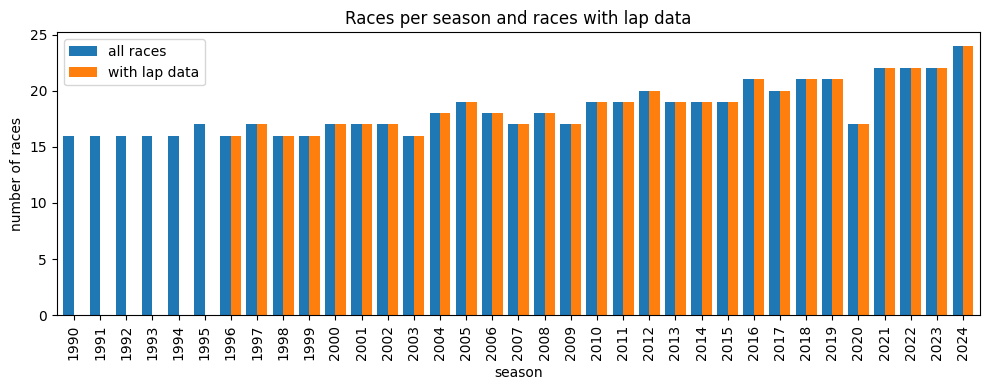

In [152]:
laps = lap_times.merge(races[['raceId', 'year']], on='raceId')
print('first season:', laps.year.min())
print('last season:', laps.year.max())
print('races with lap data:', laps.raceId.nunique(), 'of', len(races))

since_1996 = races[races.year >= 1996]
print('races from 1996 on:', len(since_1996))
print('of them with lap data:', since_1996.raceId.isin(laps.raceId).sum())
print('races before 1996 with lap data:', laps[laps.year < 1996].raceId.nunique())

per_year = races.groupby('year').size().rename('all races').to_frame()
per_year['with lap data'] = laps.groupby('year').raceId.nunique()
per_year = per_year.fillna(0)

per_year.loc[1990:].plot.bar(figsize=(10, 4), width=0.8,
    title='Races per season and races with lap data')
plt.xlabel('season')
plt.ylabel('number of races')
plt.tight_layout()
plt.show()


In [153]:
per_driver = laps.groupby(['raceId', 'driverId']).lap.agg(['min', 'max', 'nunique', 'size'])
no_gap = (per_driver['min'] == 1) & (per_driver['max'] == per_driver['nunique']) & (per_driver['nunique'] == per_driver['size'])
print('driver-races:', len(per_driver), '| laps run 1..n with no gap:', int(no_gap.sum()))

per_lap = laps.groupby(['raceId', 'lap']).position.agg(['nunique', 'size', 'max'])
print('race-laps:', len(per_lap))
print('all positions different within a lap:', int((per_lap['nunique'] == per_lap['size']).sum()))
print('positions run exactly 1..n:', int((per_lap['max'] == per_lap['size']).sum()))

driver-races: 11041 | laps run 1..n with no gap: 11041
race-laps: 33196
all positions different within a lap: 33196
positions run exactly 1..n: 33196


In [154]:
normal = laps.time.str.match(r'^\d+:\d{2}\.\d{3}$')
with_hours = laps.time.str.match(r'^\d+:\d{2}:\d{2}\.\d{3}$')
print('time looks like m:ss.mmm:', int(normal.sum()))
print('time looks like h:mm:ss.mmm:', int(with_hours.sum()))
print('any other format:', int((~normal & ~with_hours).sum()))

def lap_text_to_ms(s):
    parts = s.split(':')
    seconds, minutes = float(parts[-1]), float(parts[-2])
    hours = float(parts[-3]) if len(parts) > 2 else 0.0
    return round(((hours * 60 + minutes) * 60 + seconds) * 1000)

print('time text agrees with milliseconds:', int((laps.time.map(lap_text_to_ms) == laps.milliseconds).sum()), 'of', len(laps))

time looks like m:ss.mmm: 589038
time looks like h:mm:ss.mmm: 43
any other format: 0


time text agrees with milliseconds: 589081 of 589081


In [155]:
long_laps = laps[laps.time.str.match(r'^\d+:\d{2}:\d{2}\.\d{3}$')].merge(races[['raceId', 'name']], on='raceId')
display(long_laps.groupby(['year', 'name']).agg(rows=('lap', 'size'), first_lap=('lap', 'min'), last_lap=('lap', 'max'), shortest=('time', 'min'), longest=('time', 'max')))

,,rows,first_lap,last_lap,shortest,longest
year,name,,,,,
2011,Canadian Grand Prix,23,25,25,2:04:29.869,2:05:07.547
2014,British Grand Prix,20,1,2,1:01:07.384,1:03:23.459


In [156]:
with_names = laps.merge(races[['raceId', 'name']], on='raceId')
print('median lap (ms):', int(laps.milliseconds.median()))
print('fastest lap (ms):', laps.milliseconds.min())
print('slowest lap (ms):', laps.milliseconds.max(), '=', round(laps.milliseconds.max() / 60000, 1), 'minutes')
display(pd.concat([with_names.nsmallest(1, 'milliseconds'), with_names.nlargest(1, 'milliseconds')])[['year', 'name', 'lap', 'milliseconds']])


median lap (ms): 90608
fastest lap (ms): 55404
slowest lap (ms): 7507547 = 125.1 minutes


,year,name,lap,milliseconds
488409,2020,Sakhir Grand Prix,80,55404
8372,2011,Canadian Grand Prix,25,7507547


### lap_times: structure, keys, coverage and trust in the time column

**Grain.** The table has 589,081 rows and 6 columns. One row is one completed lap of one driver in one race, and `position` is the driver's running position at the end of that lap, not the final result.

**Types and missing values.** No column has missing values. `raceId`, `driverId`, `lap`, `position` and `milliseconds` are integers. The `time` column is text, and it is the same lap time as `milliseconds` written in another form. All 589,081 `time` values follow one of two patterns, `m:ss.mmm` in 589,038 rows and `h:mm:ss.mmm` in 43 rows, with none in any other format. Converting the text to milliseconds gives exactly the `milliseconds` column in all 589,081 rows. We therefore use `milliseconds` as the numeric lap time and leave `time` unchanged.

**Primary key.** The table has no ID column, and `(raceId, driverId, lap)` has 0 duplicates, so it is a valid natural key.

**Coverage.** Lap data covers 544 races from 1996 to 2024 and 143 drivers. All 544 races from 1996 on have lap data, and no race before 1996 has any, so the coverage is a clean cut at 1996. This is 544 of 1,125 races, which is about 48% of all races.

**Completeness.** In all 11,041 driver-races the laps run exactly 1 to n with no gap. In all 33,196 race-laps no two drivers share a position, and the positions run exactly from 1 to the number of cars. So every lap gives a proper running order. Positions go up to 24 and lap numbers up to 87.

**Long laps.** The 43 laps in `h:mm:ss.mmm` form come from two races, 23 from lap 25 of the 2011 Canadian Grand Prix (about 2 hours) and 20 from laps 1 and 2 of the 2014 British Grand Prix (about 1 hour). They are consistent with red-flag stoppages included in the lap time. They are real values and not errors, but they are extreme, since the slowest lap is 125.1 minutes while the median lap is 90.6 seconds.


In [157]:
race_median = laps.groupby('raceId').milliseconds.median() / 1000
low, middle, high = race_median.quantile([0.01, 0.5, 0.99])
print('typical lap of a race (seconds):')
print('fastest race:', round(race_median.min(), 1))
print('1% of races below:', round(low, 1))
print('median:', round(middle, 1))
print('99% of races below:', round(high, 1))
print('slowest race:', round(race_median.max(), 1))
slowest = race_median.idxmax()
print('slowest race is', races.loc[races.raceId == slowest, ['year', 'name']].values.tolist()[0],
      '| laps in lap_times:', laps[laps.raceId == slowest].lap.max())


typical lap of a race (seconds):
fastest race: 58.7
1% of races below: 70.3
median: 91.1
99% of races below: 122.2
slowest race: 225.4
slowest race is [2021, 'Belgian Grand Prix'] | laps in lap_times: 1


In [158]:
laps['relative'] = laps.milliseconds / laps.groupby('raceId').milliseconds.transform('median')
print('relative lap: median', round(laps.relative.median(), 3))
print('smallest', round(laps.relative.min(), 3), '| largest', round(laps.relative.max(), 1))
print('lap 1 (standing start) median:', round(laps[laps.lap == 1].relative.median(), 3))

slow = pd.DataFrame({'laps': {f'slower than {k} x typical': int((laps.relative > k).sum()) for k in [1.2, 1.5, 2, 3]}})
slow['% of all laps'] = (slow['laps'] / len(laps) * 100).round(2)
display(slow)

relative lap: median 1.0


smallest 0.745 | largest 72.7
lap 1 (standing start) median: 1.131


,laps,% of all laps
slower than 1.2 x typical,38875,6.60
slower than 1.5 x typical,11709,1.99
slower than 2 x typical,1092,0.19
slower than 3 x typical,723,0.12


### lap_times: extreme laps and why circuits cannot be compared

**Typical and extreme laps.** The median lap is 90,608 ms, which is about 90.6 seconds. The fastest lap is 55,404 ms, from lap 80 of the 2020 Sakhir Grand Prix, which is consistent with the short outer layout used for that race. The slowest lap is 7,507,547 ms, which is 125.1 minutes, from lap 25 of the 2011 Canadian Grand Prix, where the red-flag stoppage is included in the lap time. The slowest lap is more than 80 times the median, so a single stoppage lap would distort any plain average of lap times.

**Circuits cannot be compared on raw lap times.** Every circuit has its own length, so a lap of the same duration means something different in each race. The typical (median) lap of a race is 58.7 seconds in the fastest race and 91.1 seconds in the median race. 1% of races are below 70.3 seconds and 99% of races are below 122.2 seconds. The slowest race has a typical lap of 225.4 seconds, far outside the rest. It is the 2021 Belgian Grand Prix, which has only 1 lap in the table: the race was run behind the safety car in heavy rain (F1 history), so its one lap is very slow. The same race has no pit stops (pit_stops section). A model fed raw lap times would mostly learn which circuit it was looking at and not how fast the driver was.

**Relative lap time.** To put all races on one scale, we divide each lap by the median lap of its own race, so 1.0 is a typical lap of that race. The median relative lap is 1.0 by construction. The smallest value is 0.745 and the largest is 72.7, which is the 2011 Canadian Grand Prix stoppage lap. Lap 1 has a median of 1.131, so a first lap is about 13% slower than a typical lap, which fits the standing start.

**How common are slow laps.** Most laps are close to typical, and extreme laps are rare.

| Slower than | Laps | Share of all laps |
|---|---|---|
| 1.2 x typical | 38,875 | 6.60% |
| 1.5 x typical | 11,709 | 1.99% |
| 2 x typical | 1,092 | 0.19% |
| 3 x typical | 723 | 0.12% |

About 93% of laps are within 20% of the typical lap of their race. The reasons for the slow laps (pit stops, lap 1, safety cars, red flags) have not been checked yet, because that needs the pit_stops table.

**Decision.** Raw lap times are not used. Any pace feature built from laps uses the relative lap time, and because a few stoppage laps are extreme, it takes a median or caps the values instead of using a plain average.

In [159]:
one_row = results_unique.drop_duplicates(['raceId', 'driverId'])
count = (laps.groupby(['raceId', 'driverId']).size().rename('lap_rows').reset_index()
         .merge(one_row[['raceId', 'driverId', 'laps']], on=['raceId', 'driverId']))
count['difference'] = count.lap_rows - count.laps
different = count[count.difference != 0]
print('driver-races:', len(count))
print('lap rows = laps in results:', int((count.difference == 0).sum()))
print('different:', len(different), 'in', different.raceId.nunique(), 'of', count.raceId.nunique(), 'races')
print('differ by 1 or 2 laps:', int((different.difference.abs() <= 2).sum()))
print('differ by 10 laps or more:', int((different.difference.abs() >= 10).sum()))

driver-races: 11041
lap rows = laps in results: 10951
different: 90 in 35 of 544 races
differ by 1 or 2 laps: 71
differ by 10 laps or more: 10


In [160]:
# driver-races where lap_times and results differ by 10 laps or more
big = different[different.difference.abs() >= 10].merge(races[['raceId', 'year', 'name']], on='raceId')

cols = ['raceId', 'driverId', 'grid', 'positionOrder', 'laps', 'statusId']
check = big.merge(one_row[cols], on=['raceId', 'driverId', 'laps'])
display(check[['year', 'name', 'driverId', 'lap_rows', 'laps', 'grid', 'positionOrder', 'statusId']].sort_values(['year', 'name']))

,year,name,driverId,lap_rows,laps,grid,positionOrder,statusId
4,2001,Hungarian Grand Prix,15,75,53,5,17,9
5,2001,Hungarian Grand Prix,55,53,75,12,10,12
6,2001,Italian Grand Prix,15,52,0,5,22,4
7,2001,Japanese Grand Prix,15,5,52,8,8,11
8,2001,Japanese Grand Prix,55,52,5,11,22,4
3,2006,French Grand Prix,22,18,28,13,20,5
2,2008,British Grand Prix,21,26,16,19,17,20
0,2009,Italian Grand Prix,17,52,0,10,20,4
1,2009,Italian Grand Prix,67,19,52,19,13,11
9,2024,São Paulo Grand Prix,807,30,0,17,20,2


In [161]:
d = (different
     .merge(one_row[['raceId', 'driverId', 'grid', 'positionOrder', 'statusId']], on=['raceId', 'driverId'])
     .merge(races[['raceId', 'year', 'name']], on='raceId')
     .merge(status[['statusId', 'status']], on='statusId')
     .merge(drivers[['driverId', 'surname']], on='driverId'))

print('rows:', len(d))
print('lap_times has MORE laps than results:', int((d.difference > 0).sum()))
print('lap_times has FEWER laps than results:', int((d.difference < 0).sum()))
print('grid == 0:', int((d.grid == 0).sum()))
print(d.status.value_counts().head(8))

with pd.option_context('display.max_rows', 100):
    display(d[['year', 'name', 'surname', 'lap_rows', 'laps', 'difference', 'grid', 'positionOrder', 'status']]
            .sort_values(['year', 'name']))

rows: 90
lap_times has MORE laps than results: 37
lap_times has FEWER laps than results: 53
grid == 0: 0
status
+1 Lap        20
Accident      11
Finished      11
Collision      8
+2 Laps        5
Spun off       4
Engine         4
Hydraulics     4
Name: count, dtype: int64


,year,name,surname,lap_rows,laps,difference,grid,positionOrder,status
39,1998,Monaco Grand Prix,Frentzen,9,5,4,5,20,Collision
31,2001,Belgian Grand Prix,Trulli,36,31,5,16,14,Engine
32,2001,Belgian Grand Prix,Alesi,31,36,-5,13,6,Finished
33,2001,Belgian Grand Prix,Marques,32,31,1,22,13,+5 Laps
29,2001,Hungarian Grand Prix,Trulli,75,53,22,5,17,Hydraulics
30,2001,Hungarian Grand Prix,Alesi,53,75,-22,12,10,+2 Laps
34,2001,Italian Grand Prix,Trulli,52,0,52,5,22,Collision
37,2001,Japanese Grand Prix,Trulli,5,52,-47,8,8,+1 Lap
38,2001,Japanese Grand Prix,Alesi,52,5,47,11,22,Collision
35,2001,United States Grand Prix,Trulli,72,73,-1,8,4,Finished


In [162]:
print(d.groupby('status').difference.agg(['size', 'min', 'median', 'max']).sort_values('size', ascending=False).head(10))

            size  min  median  max
status                            
+1 Lap        20  -47     1.0    2
Accident      11   -2    -1.0   -1
Finished      11   -5     2.0    2
Collision      8   -3     1.5   52
+2 Laps        5  -22    -1.0    2
Engine         4  -10     1.0    5
Hydraulics     4   -2     1.0   22
Spun off       4   -1     0.5   10
+4 Laps        3   -2    -1.0    2
Brakes         3   -5    -4.0   -1


In [163]:
small = d[d.difference.abs() <= 2]
by_race = (small.groupby(['year', 'name']).size()
           .rename('small differences').sort_values(ascending=False))
print('rows with a 1 or 2 lap difference:', len(small))
print('races involved:', len(by_race))
print('share in the top race:', round(by_race.iloc[0] / len(small) * 100, 1), '%')
display(by_race.head(10))

rows with a 1 or 2 lap difference: 71
races involved: 24
share in the top race: 28.2 %


year  name                    
2014  Chinese Grand Prix          20
2003  Brazilian Grand Prix         9
2010  Belgian Grand Prix           7
      Monaco Grand Prix            6
2014  Hungarian Grand Prix         6
2001  United States Grand Prix     2
2005  Chinese Grand Prix           2
2012  Indian Grand Prix            2
2010  Canadian Grand Prix          2
2004  French Grand Prix            1
Name: small differences, dtype: int64

In [164]:
cn = d[(d.year == 2014) & (d.name == 'Chinese Grand Prix')]
print('drivers in that race with a difference:', len(cn))
print(cn.difference.value_counts().to_dict())
display(cn[['surname', 'lap_rows', 'laps', 'difference', 'positionOrder', 'status']].sort_values('positionOrder'))

drivers in that race with a difference: 20
{2: 20}


,surname,lap_rows,laps,difference,positionOrder,status
63,Hamilton,56,54,2,1,Finished
64,Rosberg,56,54,2,2,Finished
65,Alonso,56,54,2,3,Finished
74,Ricciardo,56,54,2,4,Finished
69,Vettel,56,54,2,5,Finished
71,Hülkenberg,56,54,2,6,Finished
78,Bottas,56,54,2,7,Finished
66,Räikkönen,56,54,2,8,Finished
73,Pérez,56,54,2,9,Finished
81,Kvyat,55,53,2,10,+1 Lap


In [165]:
cn_all = (laps[laps.raceId == cn.raceId.iloc[0]].groupby('driverId').size().rename('lap_rows').reset_index()
          .merge(one_row[['raceId', 'driverId', 'laps', 'positionOrder']], on='driverId')
          .query('raceId == @cn.raceId.iloc[0]'))
print('max laps in lap_times:', laps[laps.raceId == cn.raceId.iloc[0]].lap.max())
print('max laps in results:', cn_all.laps.max())
display(cn_all.sort_values('positionOrder').head(5))

max laps in lap_times: 56
max laps in results: 54


,driverId,lap_rows,raceId,laps,positionOrder
132,1,56,903,54,1
506,3,56,903,54,2
782,4,56,903,54,3
3245,817,56,903,54,4
2149,20,56,903,54,5


In [166]:
d['abs_diff'] = d.difference.abs()
print('differ by 3 to 9 laps:', int(d.abs_diff.between(3, 9).sum()))
display(d[(d.abs_diff >= 3) | (d.status == 'Finished')]
        [['year', 'name', 'surname', 'lap_rows', 'laps', 'difference', 'positionOrder', 'status']]
        .sort_values(['year', 'name']))

differ by 3 to 9 laps: 9


,year,name,surname,lap_rows,laps,difference,positionOrder,status
39,1998,Monaco Grand Prix,Frentzen,9,5,4,20,Collision
31,2001,Belgian Grand Prix,Trulli,36,31,5,14,Engine
32,2001,Belgian Grand Prix,Alesi,31,36,-5,6,Finished
29,2001,Hungarian Grand Prix,Trulli,75,53,22,17,Hydraulics
30,2001,Hungarian Grand Prix,Alesi,53,75,-22,10,+2 Laps
34,2001,Italian Grand Prix,Trulli,52,0,52,22,Collision
37,2001,Japanese Grand Prix,Trulli,5,52,-47,8,+1 Lap
38,2001,Japanese Grand Prix,Alesi,52,5,47,22,Collision
35,2001,United States Grand Prix,Trulli,72,73,-1,4,Finished
15,2004,United States Grand Prix,Heidfeld,43,40,3,12,Engine


In [167]:
for rid_year, rid_name in [(2003, 'Brazilian Grand Prix'), (2010, 'Belgian Grand Prix'), (2010, 'Monaco Grand Prix'), (2014, 'Hungarian Grand Prix')]:
    sub = d[(d.year == rid_year) & (d.name == rid_name)]
    print(rid_year, rid_name, '| rows:', len(sub), '| differences:', sub.difference.value_counts().to_dict())

2003 Brazilian Grand Prix | rows: 9 | differences: {-1: 9}
2010 Belgian Grand Prix | rows: 7 | differences: {-1: 5, -2: 2}
2010 Monaco Grand Prix | rows: 6 | differences: {-2: 4, -1: 2}
2014 Hungarian Grand Prix | rows: 6 | differences: {-1: 4, -2: 2}


In [168]:
fl = one_row[['raceId', 'driverId', 'fastestLapTime']].dropna(subset=['fastestLapTime']).copy()
fl = fl[fl.raceId.isin(laps.raceId)]
fl['results_ms'] = fl.fastestLapTime.map(
    lambda s: round((float(s.split(':')[0]) * 60 + float(s.split(':')[1])) * 1000))
best = laps.groupby(['raceId', 'driverId']).milliseconds.min().rename('lap_times_ms').reset_index()
fl = fl.merge(best, on=['raceId', 'driverId'])

same = fl.lap_times_ms == fl.results_ms
print('driver-races with a fastest lap in results (and lap data):', len(fl))
print('same fastest lap in both tables:', int(same.sum()), f'({same.mean() * 100:.1f}%)')
print('different:', int((~same).sum()))

driver-races with a fastest lap in results (and lap data): 8249
same fastest lap in both tables: 8039 (97.5%)
different: 210


In [169]:
bad = fl[~same].copy()
bad['gap_ms'] = bad.lap_times_ms - bad.results_ms
bad['abs_gap'] = bad.gap_ms.abs()
print('gap = lap_times minus results (ms)')
print('lap_times faster (negative):', int((bad.gap_ms < 0).sum()), '| slower (positive):', int((bad.gap_ms > 0).sum()))
print('within 10 ms:', int((bad.abs_gap <= 10).sum()), '| within 1 second:', int((bad.abs_gap <= 1000).sum()), '| over 1 second:', int((bad.abs_gap > 1000).sum()))
print(bad.abs_gap.describe().round(0))

bad = bad.merge(races[['raceId', 'year']], on='raceId')
print(bad.year.value_counts().sort_index().to_dict())

gap = lap_times minus results (ms)
lap_times faster (negative): 150 | slower (positive): 60
within 10 ms: 3 | within 1 second: 133 | over 1 second: 77
count      210.0
mean      3855.0
std       9593.0
min          1.0
25%        266.0
50%        639.0
75%       1550.0
max      71585.0
Name: abs_gap, dtype: float64
{2006: 3, 2007: 7, 2008: 3, 2009: 1, 2010: 6, 2011: 21, 2012: 17, 2013: 8, 2014: 20, 2015: 11, 2016: 5, 2017: 4, 2018: 30, 2019: 12, 2020: 13, 2021: 13, 2022: 23, 2023: 8, 2024: 5}


In [170]:
bad = bad.merge(races[['raceId', 'name']], on='raceId')
print('races involved:', bad.raceId.nunique())
print(bad.groupby(['year', 'name']).size().sort_values(ascending=False).head(8))
display(bad.sort_values('abs_gap', ascending=False).head(8)[['year', 'name', 'driverId', 'lap_times_ms', 'results_ms', 'gap_ms']])

races involved: 72
year  name                    
2011  British Grand Prix          20
2014  Australian Grand Prix       18
2018  Italian Grand Prix          13
      United States Grand Prix    11
2022  United States Grand Prix     9
2012  British Grand Prix           9
2013  British Grand Prix           8
2019  German Grand Prix            7
dtype: int64


,year,name,driverId,lap_times_ms,results_ms,gap_ms
7,2007,European Grand Prix,24,130715,202300,-71585
6,2007,European Grand Prix,26,129078,181900,-52822
17,2010,German Grand Prix,15,95768,134452,-38684
5,2007,European Grand Prix,3,133966,170950,-36984
15,2010,Monaco Grand Prix,18,98509,134285,-35776
19,2010,Japanese Grand Prix,9,127363,161378,-34015
9,2007,Brazilian Grand Prix,21,89298,122680,-33382
135,2018,United States Grand Prix,4,133811,100933,32878


In [171]:
mismatch = (count.assign(laps_mismatch=count.difference.abs() >= 3)
                 [['raceId', 'driverId', 'laps_mismatch']])

before = len(laps)
laps = laps.drop(columns='laps_mismatch', errors='ignore').merge(mismatch, on=['raceId', 'driverId'], how='left')
laps['laps_mismatch'] = laps.laps_mismatch.fillna(False).astype(bool)

print('rows unchanged:', len(laps) == before)
n_flagged = laps[laps.laps_mismatch].groupby(['raceId', 'driverId']).ngroups
assert n_flagged == int((count.difference.abs() >= 3).sum()), 'a flagged driver-race was lost in the merge'
print('flagged driver-races:', n_flagged)
print('flagged lap rows:', int(laps.laps_mismatch.sum()))

rows unchanged: True
flagged driver-races: 19
flagged lap rows: 671


### lap_times, agreement with results

**Lap counts.** We compared the number of lap rows of every driver in every race with the `laps` column in `results`. Of 11,041 driver-races, 10,951 (99.2%) have the same count in both tables. The other 90 differ and they are spread over 35 of the 544 races. Of these, 71 differ by 1 or 2 laps, 9 by 3 to 9 laps and 10 by 10 laps or more. Lap_times has more laps in 37 cases and fewer in 53, and none of the 90 drivers started from the pit lane.

**Differences of 1 or 2 laps.** These are mostly small and fall into two kinds. In the 2014 Chinese GP all 20 drivers differ by exactly +2, because lap_times runs to 56 laps and results stops at 54. The race was scheduled for 56 laps (this comes from F1 knowledge and not from the tables), so the error looks like it is in results and not in lap_times. We have not tested why. The other cases are scattered and mostly negative. All 11 Accident rows are -1 or -2, and the 2003 Brazilian, 2010 Belgian, 2010 Monaco and 2014 Hungarian races only have negative differences of 1 or 2 laps. This looks like a small counting difference at the end of a driver's race, but we have not tested it.

**Differences of 3 laps or more.** There are 19 driver-races in 14 races. Six of them come from three swaps between Trulli and Alesi in the 2001 Belgian, Hungarian and Japanese Grands Prix, where the two drivers have opposite lap counts in the two tables. They were teammates, which is F1 knowledge and makes a mix-up between the two cars plausible. A similar pair appears in the 2009 Italian GP with Webber and Buemi. In these cases the results row fits the finishing position and status, so lap_times looks like the table that is wrong. Three drivers have 30 to 52 lap rows but 0 laps in results (Trulli in the 2001 Italian GP, Webber in the 2009 Italian GP and Hülkenberg in the 2024 São Paulo GP, where the status is Disqualified). The remaining cases are single differences of 3 to 10 laps, mostly retirements, without a clear pattern. We have not confirmed any of this with an outside source.

**Fastest laps.** We compared each driver's quickest lap in lap_times with `fastestLapTime` in results, for the 8,249 driver-races that have both. The two tables agree in 8,039 cases (97.5%) and differ in 210 cases, spread over 72 races between 2006 and 2024. These differences are not rounding, since only 3 are within 10 ms, the median gap is 639 ms, 77 are over a second and the largest is about 71.6 seconds. In 150 cases lap_times has the faster lap and in 60 it has the slower one. The differences cluster partly in a few races, with eight races holding 95 of the 210. In the 2011 British Grand Prix, 20 of 24 drivers differ and in every case lap_times is faster by 0.3 to 3.3 seconds, which looks like a shift affecting the whole race. In the 2014 Australian Grand Prix, 18 of 20 drivers differ in both directions with a median gap of only 62 ms, so the two tables seem to report different laps for each driver. The largest single gaps include three drivers in the 2007 European Grand Prix whose fastest lap in results is 37 to 72 seconds slower than in lap_times. We have not confirmed which table is wrong. Because `fastestLapTime` in results is only known after the race and is not planned as a feature, this affects only possible lap-based pace features and not the target.

**Decision.** We keep all rows in lap_times. We add a flag `laps_mismatch` to the 19 driver-races that differ by 3 laps or more, and lap-based features skip them. Differences of 1 or 2 laps are not flagged, and the 210 fastest-lap differences are not flagged either, since their lap counts agree and the doubt is only about one lap. The 2014 Chinese GP is noted as a likely error in `results.laps`, which we do not use as a feature.

## `Pit Stops Table`

In [172]:
pit_stops = load('pit_stops')

ps = pit_stops.copy()
print(ps.shape)
print(ps.dtypes)
display(ps.head())
print(ps.isna().sum())
print('duplicate (raceId, driverId, stop):', ps.duplicated(['raceId', 'driverId', 'stop']).sum())
print('races:', ps.raceId.nunique(), '| drivers:', ps.driverId.nunique())
ps = ps.merge(races[['raceId', 'year']], on='raceId')
print('first season:', ps.year.min(), '| last season:', ps.year.max())

(11371, 7)
raceId           int64
driverId         int64
stop             int64
lap              int64
time            object
duration        object
milliseconds     int64
dtype: object


,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842


raceId          0
driverId        0
stop            0
lap             0
time            0
duration        0
milliseconds    0
dtype: int64
duplicate (raceId, driverId, stop): 0
races: 285 | drivers: 76
first season: 2011 | last season: 2024


In [173]:
since_2011 = races[races.year >= 2011]
print('races from 2011 on:', len(since_2011), '| with pit stop data:', since_2011.raceId.isin(ps.raceId).sum())
print('races before 2011 with pit stops:', int((ps.year < 2011).sum()))

print('duration formats:', ps.duration.str.match(r'^\d+\.\d{3}$').sum(), 'plain seconds |',
      ps.duration.str.match(r'^\d+:\d{2}\.\d{3}$').sum(), 'm:ss.mmm |',
      (~ps.duration.str.match(r'^\d+(:\d{2})?\.\d{3}$')).sum(), 'other')

def dur_to_ms(s):
    parts = s.split(':')
    return round((float(parts[-1]) + (float(parts[-2]) * 60 if len(parts) > 1 else 0)) * 1000)

print('duration agrees with milliseconds:', int((ps.duration.map(dur_to_ms) == ps.milliseconds).sum()), 'of', len(ps))
print('milliseconds: min', ps.milliseconds.min(), '| median', int(ps.milliseconds.median()), '| max', ps.milliseconds.max())

races from 2011 on: 286 | with pit stop data: 285
races before 2011 with pit stops: 0
duration formats: 10854 plain seconds | 517 m:ss.mmm | 0 other
duration agrees with milliseconds: 11371 of 11371
milliseconds: min 12897 | median 23606 | max 3069017


In [174]:
print('duration:')
print(ps.duration.str.len().value_counts().to_dict())
print(ps.duration.head(5).tolist())
print(ps[ps.duration.str.contains(':')].duration.head(5).tolist())

print('time:')
print(ps.time.str.len().value_counts().to_dict())
print(ps.time.head(5).tolist())

duration:
{6: 10854, 9: 460, 8: 57}
['26.898', '25.021', '23.426', '23.251', '23.842']
['16:44.718', '2:03.124', '1:29.401', '1:44.833', '1:14.026']
time:
{8: 11371}
['17:05:23', '17:05:52', '17:20:48', '17:22:34', '17:24:10']


In [175]:
before_types = pit_stops.dtypes.astype(str)

def dur_to_s(s):
    parts = s.split(':')
    return float(parts[-1]) + (float(parts[-2]) * 60 if len(parts) > 1 else 0)

before_dur = ps.duration.notna().sum()
ps['duration_s'] = ps.duration.map(dur_to_s)

print('duration filled before / after:', before_dur, '/', ps.duration_s.notna().sum())
print('duration matches milliseconds:', int((ps.duration_s.round(3) == (ps.milliseconds / 1000).round(3)).sum()), 'of', len(ps))
print('duration range (s):', ps.duration_s.min(), 'to', ps.duration_s.max())
display(ps[['duration', 'duration_s']].head())

after_types = pd.Series({
    'raceId': 'int64', 'driverId': 'int64', 'stop': 'int64', 'lap': 'int64',
    'time': 'object (kept, time of day)',
    'duration': 'object (kept)', 'duration_s': 'float64', 'milliseconds': 'int64'})

comparison = pd.DataFrame({'before': before_types, 'after': after_types}).fillna('new column')
display(comparison)

duration filled before / after: 11371 / 11371
duration matches milliseconds: 11371 of 11371
duration range (s): 12.897 to 3069.017


,duration,duration_s
0,26.898,26.898
1,25.021,25.021
2,23.426,23.426
3,23.251,23.251
4,23.842,23.842


,before,after
driverId,int64,int64
duration,object,object (kept)
duration_s,new column,float64
lap,int64,int64
milliseconds,int64,int64
raceId,int64,int64
stop,int64,int64
time,object,"object (kept, time of day)"


In [176]:
missing = races[(races.year >= 2011) & ~races.raceId.isin(ps.raceId)]
print(missing[['year', 'name', 'date']].values.tolist())

[[2021, 'Belgian Grand Prix', Timestamp('2021-08-29 00:00:00')]]


In [177]:
ru = results_unique.merge(races[['raceId', 'year']], on='raceId')
ru = ru[ru.raceId.isin(ps.raceId)].merge(status[['statusId', 'status']], on='statusId')
stops = ps.groupby(['raceId', 'driverId']).size().rename('stops').reset_index()
ru = ru.merge(stops, on=['raceId', 'driverId'], how='left').fillna({'stops': 0})
fin = ru[ru.status.eq('Finished') | ru.status.str.match(r'^\+\d+ Laps?$')]

print('race starts in races with pit data:', len(ru), '| with at least one stop:', int((ru.stops > 0).sum()))
print('finishers:', len(fin), '| finishers with NO stop:', int((fin.stops == 0).sum()))

race starts in races with pit data: 5960 | with at least one stop: 5575
finishers: 4922 | finishers with NO stop: 3


In [178]:
odd = fin[fin.stops == 0].merge(races[['raceId', 'name']], on='raceId').merge(drivers[['driverId', 'surname']], on='driverId')
display(odd[['year', 'name', 'surname', 'laps', 'positionOrder', 'status']])

,year,name,surname,laps,positionOrder,status
0,2011,Malaysian Grand Prix,Karthikeyan,14,23,+42 Laps
1,2019,Abu Dhabi Grand Prix,Gasly,53,18,+2 Laps
2,2021,Turkish Grand Prix,Ocon,57,10,+1 Lap


In [179]:
num = ps.groupby(['raceId', 'driverId']).stop.agg(['min', 'max', 'nunique', 'size'])
ok = (num['min'] == 1) & (num['max'] == num['size']) & (num['nunique'] == num['size'])
print('stops numbered exactly 1..n:', int(ok.sum()), 'of', len(num))
print('highest stop number:', ps.stop.max(), '| highest lap:', ps.lap.max())

stops numbered exactly 1..n: 5567 of 5575
highest stop number: 70 | highest lap: 78


In [180]:
bad_num = num[~ok].reset_index()
detail = (ps.merge(bad_num[['raceId', 'driverId']], on=['raceId', 'driverId'])
            .merge(races[['raceId', 'name']], on='raceId'))
display(detail[['year', 'name', 'driverId', 'stop', 'lap', 'duration']]
        .sort_values(['year', 'name', 'driverId', 'lap']))

,year,name,driverId,stop,lap,duration
0,2014,British Grand Prix,820,2,2,23.154
1,2014,British Grand Prix,820,3,29,29.737
2,2019,Singapore Grand Prix,832,2,35,30.623
4,2024,Monaco Grand Prix,1,1,1,39:35.369
12,2024,Monaco Grand Prix,1,51,2,24.232
7,2024,Monaco Grand Prix,822,1,1,39:54.053
9,2024,Monaco Grand Prix,822,15,2,24.239
3,2024,Monaco Grand Prix,830,1,1,39:32.670
13,2024,Monaco Grand Prix,830,52,2,23.813
5,2024,Monaco Grand Prix,840,1,1,39:43.588


In [181]:
start = races.set_index('raceId').time
first_stop = ps.groupby('raceId').time.min()
offset = ((pd.to_timedelta(first_stop) - pd.to_timedelta(start.reindex(first_stop.index))).dt.total_seconds() / 3600).round()
print('first stop minus race start, in whole hours:', offset.dropna().astype(int).value_counts().head(6).to_dict())
print('races compared:', int(offset.notna().sum()), 'of', len(first_stop))

first stop minus race start, in whole hours: {2: 101, 3: 32, 8: 28, 4: 24, 1: 18, 9: 16}
races compared: 285 of 285


duration (s): min 12.9 | median 23.6 | 90% 31.6 | 99% 1848.2 | max 3069.0


,stops,races
longer than 30 s,1664,235
longer than 60 s,517,50
longer than 120 s,481,29
longer than 180 s,478,26
longer than 300 s,478,26


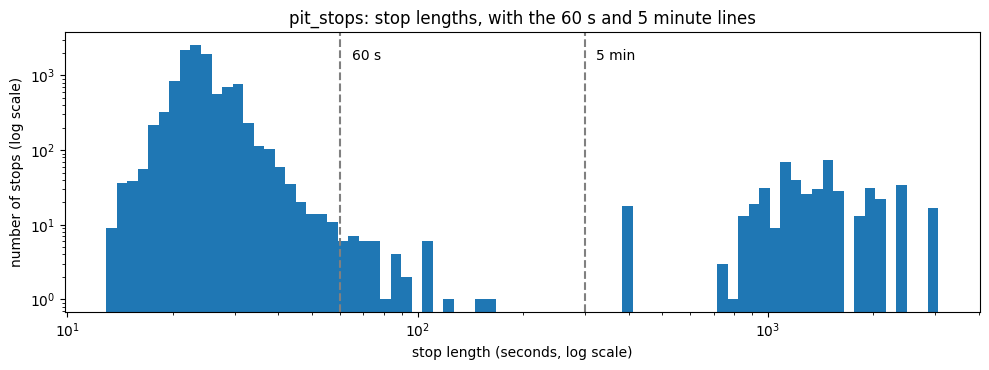

stops by kind: {'normal': 10854, 'red-flag pause': 478, 'very slow stop': 39}


,stops,median_drivers_together,with_4_or_more_others
kind,,,
red-flag pause,478,17.0,461
very slow stop,39,1.0,10


driver-races where the count changes: 404 | left with 0 stops: 41


In [182]:
sec = ps.milliseconds / 1000
print('duration (s): min', round(sec.min(), 1), '| median', round(sec.median(), 1),
      '| 90%', round(sec.quantile(0.90), 1), '| 99%', round(sec.quantile(0.99), 1), '| max', round(sec.max(), 1))

cut = pd.DataFrame({'stops': {f'longer than {k} s': int((sec > k).sum()) for k in [30, 60, 120, 180, 300]},
                    'races': {f'longer than {k} s': ps[sec > k].raceId.nunique() for k in [30, 60, 120, 180, 300]}})
display(cut)

# picture: every stop length on a log scale, with the 60 s and 5 minute lines
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(sec, bins=np.logspace(np.log10(sec.min()), np.log10(sec.max()), 80))
ax.set_xscale('log')
ax.set_yscale('log')
for x, label in [(60, '60 s'), (300, '5 min')]:
    ax.axvline(x, linestyle='--', color='gray')
    ax.text(x * 1.08, 0.9, label, transform=ax.get_xaxis_transform())
ax.set_xlabel('stop length (seconds, log scale)')
ax.set_ylabel('number of stops (log scale)')
ax.set_title('pit_stops: stop lengths, with the 60 s and 5 minute lines')
plt.tight_layout()
plt.show()

ps['kind'] = np.select([sec > 300, sec > 60], ['red-flag pause', 'very slow stop'], 'normal')
print('stops by kind:', ps.kind.value_counts().to_dict())

long = ps[sec > 60].assign(together=lambda t: t.groupby(['raceId', 'lap']).driverId.transform('nunique'))
display(long.groupby('kind').together.agg(stops='size', median_drivers_together='median',
                                          with_4_or_more_others=lambda s: int((s >= 5).sum())))

raw = ps.groupby(['raceId', 'driverId']).size()
clean = ps[ps.kind != 'red-flag pause'].groupby(['raceId', 'driverId']).size().reindex(raw.index).fillna(0).astype(int)
print('driver-races where the count changes:', int((raw != clean).sum()), '| left with 0 stops:', int((clean == 0).sum()))

### pit_stops, structure, keys, coverage, types and long stops

**Grain.** The table has 11,371 rows and 7 columns. One row is one pit stop of one driver in one race, where `stop` is the number of that stop within the race and `lap` is the lap it happened on.

**Primary key.** The table has no ID column, and `(raceId, driverId, stop)` has 0 duplicates, so it is a valid natural key.

**Missing values.** No column has any missing value.

**Coverage.** Pit stop data covers 2011 to 2024, with 285 races and 76 drivers, which is about 25% of all 1,125 races. No race before 2011 has any data, so the coverage is a clean cut at 2011. Of the 286 races from 2011 on, only the 2021 Belgian Grand Prix has no rows, which is consistent with a race that was abandoned without any racing.

**Completeness.** Of 5,960 race starts in races with pit data, 5,575 have at least one stop. The missing ones are mostly retirements that ended before a stop was needed, and of 4,922 classified finishers only 3 have no stop recorded. One of them, Karthikeyan in the 2011 Malaysian GP, was classified after only 14 laps, so a race without a stop is plausible. The other two, Gasly in the 2019 Abu Dhabi GP and Ocon in the 2021 Turkish GP, ran nearly the full distance, so at most two rows are missing in the whole table.

**Types.** Following the rule that durations become numbers, we converted one text column and kept the original. The `duration` column holds a stop length in two written forms, plain seconds such as 26.898 in 10,854 rows and minutes with seconds such as 1:29.401 in 517 rows, with none in any other form. We converted it to seconds in a new column `duration_s`, and all 11,371 values converted with none lost. It matches the `milliseconds` column in all 11,371 rows, so the two columns carry the same information. The `time` column is the clock time of the stop, always written as hh:mm:ss. Like the start times in `races`, it is kept as text, because a time of day alone has no date. This clock does not agree with the race start time in `races`, and the difference varies from race to race between 1 and 9 whole hours, so the stop times are probably local while the race start is stored in UTC. We do not use either column. The remaining five columns are already integers.

**Stop numbering.** In 5,567 of the 5,575 driver-races the stops are numbered exactly 1 to n, and 8 are not. Six of them are at the 2024 Monaco GP, where each driver has a stop of about 39 minutes on lap 1 and then a normal stop of about 24 seconds on lap 2 numbered 15, 42, 51, 52, 57 or 70. These numbers are labels gone wrong and not real stop counts, since no driver has more than 7 stop rows in a race. In the 2014 British GP and the 2019 Singapore GP one driver each starts at stop 2, so their first stop is missing. We therefore do not trust `stop` as a count and recount stops by sorting on `lap`.

**Long stops.** A real stop is fast, with a median of 23.6 seconds and 90% under 31.6 seconds, but the longest is 3,069 seconds, which is about 51 minutes. 517 stops are longer than 60 seconds, spread over 50 races. Of these, 478 are longer than 5 minutes and 39 are between 1 and 5 minutes. The 5 minute line is supported by the data, because only 3 stops last between 2 and 5 minutes and none between 3 and 5 minutes (see the histogram), so any cutoff in that range gives the same 478 rows. These 478 are made together by the whole field, with a median of 17 drivers stopping on the same lap of the same race and 461 of them alongside at least 4 other drivers, which is what a stoppage of the whole race looks like. The 39 slower stops have a median of 1 driver, so they are single slow stops.

**Decision.** A stop up to 60 seconds is a real pit stop. The 478 rows longer than 5 minutes are red-flag pauses, so they are removed from stop counts and from any duration figure, which changes the count in 404 of 5,575 driver-races and leaves 41 with no stops. The 39 very slow stops are kept as stops and flagged, and stop durations are summarised with medians rather than averages.

## Key checks for all 14 tables

The keys were checked table by table above. This cell repeats the check for all 14 tables in one place: is each table's key unique and never empty, and does every id point to a row that exists in its parent table (no orphans)? `lap_times` and `pit_stops` have no id column, so their key is a combination of columns.

In [183]:
# every table: is its key unique and complete, and does every id point to an existing row?
keys = {'results': (results_unique, ['resultId']), 'qualifying': (qualifying, ['qualifyId']),
        'seasons': (seasons, ['year']), 'races': (races, ['raceId']), 'circuits': (circuits, ['circuitId']),
        'drivers': (drivers, ['driverId']), 'constructors': (constructors, ['constructorId']),
        'status': (status, ['statusId']), 'driver_standings': (driver_standings, ['driverStandingsId']),
        'constructor_standings': (constructor_standings, ['constructorStandingsId']),
        'constructor_results': (constructor_results, ['constructorResultsId']),
        'sprint_results': (sprint_results, ['resultId']),
        'lap_times': (lap_times, ['raceId', 'driverId', 'lap']), 'pit_stops': (pit_stops, ['raceId', 'driverId', 'stop'])}
parents = {'raceId': races.raceId, 'driverId': drivers.driverId, 'constructorId': constructors.constructorId,
           'circuitId': circuits.circuitId, 'statusId': status.statusId, 'year': seasons.year}

rows = []
for name, (df, key) in keys.items():
    fks = [c for c in parents if c in df.columns and [c] != key]
    rows.append({'table': name, 'rows': len(df), 'key': ', '.join(key),
                 'key nulls': int(df[key].isna().any(axis=1).sum()), 'key duplicates': int(df.duplicated(key).sum()),
                 'foreign keys': ', '.join(fks),
                 'orphans': int(sum((~df[c].dropna().isin(parents[c])).sum() for c in fks))})
key_checks = pd.DataFrame(rows)
display(key_checks)
assert (key_checks[['key nulls', 'key duplicates', 'orphans']] == 0).all().all(), 'a key check failed'

,table,rows,key,key nulls,key duplicates,foreign keys,orphans
0,results,26668,resultId,0,0,"raceId, driverId, constructorId, statusId",0
1,qualifying,10494,qualifyId,0,0,"raceId, driverId, constructorId",0
2,seasons,75,year,0,0,,0
3,races,1125,raceId,0,0,"circuitId, year",0
4,circuits,77,circuitId,0,0,,0
5,drivers,861,driverId,0,0,,0
6,constructors,212,constructorId,0,0,,0
7,status,139,statusId,0,0,,0
8,driver_standings,34863,driverStandingsId,0,0,"raceId, driverId",0
9,constructor_standings,13391,constructorStandingsId,0,0,"raceId, constructorId",0


**Result:** all 14 tables pass. Every key is unique and never empty, and no foreign key has an orphan. This includes `lap_times` and `pit_stops`, whose links to `races` and `drivers` were not checked in their own sections.

# 3. Cleaning summary: decisions and findings

This section gathers the decisions taken across all 14 tables, grouped by the kind of decision rather than by table, because the same finding often appears in several tables and leads to one rule.

## 1. What the modelling table is

One row is one driver in one race, and the target is whether the finishing position (`positionOrder`) is 3 or less. The base table is `results` after deduplication, and every other table is joined onto it on `raceId` and `driverId`, or through `raceId` for race-level and circuit-level information, or on `constructorId` for team information.

Two tables hold many rows per driver-race, so they cannot be joined directly: `lap_times` (one row per lap) and `pit_stops` (one row per stop). `lap_times` is summarised to one value per driver and race before it is used (the pace feature, 7.8). `pit_stops` is cleaned but not used as a feature.

## 2. Rows we remove or mark

Several tables pointed to the same small set of rows that do not belong in the modelling table.

| Rows | Where it came from | What we do |
|---|---|---|
| 91 extra rows in 85 duplicate driver-races | results has repeated rows, mostly from shared drives (1950 to 1964), plus 3 drivers entered in two cars who started in neither | Keep the lowest `positionOrder` per driver and race |
| 87 shared finishing places in 45 races, 1950 to 1961 | results, two drivers of the same team credited with one car's `positionOrder` (shared drives); in 18 of these races more than 3 rows have a podium place | Keep, because it does not happen after 1961 and the model uses recent seasons; if older seasons are used, count one podium per car (Q2 leaves these cars out, because their result is two drivers' effort) |
| 1,710 rows of drivers who did not start (grid 0 and 0 laps, or did not qualify / withdrew with 0 laps) | results | Flag as `never_ran`, build history features first, then drop |
| 381 rows from 11 Indianapolis 500 races | results, races, constructors and constructor_standings all treat it differently | Flag as `is_indy500` and exclude from the modelling table |
| 72 pit lane starts (grid 0 with laps run) | results | Keep, flag as `pit_lane_start`, and put them at the back of the field in `grid_clean` (`grid` itself is unchanged) |

The Indianapolis races are identified by race name and not by `circuitId`, because the same circuit also hosted the United States Grand Prix from 2000 to 2007. They are excluded because 103 of their 107 drivers never raced another Formula One race, because the fields of 33 to 42 cars make grid position mean something different, because 30 constructors entered only this race, and because the constructor tables record it inconsistently.

## 3. Features that must look backwards only

Several tables record a race after it has been run, so using the row of the race itself would leak the result into the features. The same rule solves all of them.

- The driver and constructor standings rows of a race are written after that race, confirmed by 99.8% (drivers) and 99.3% (constructors) of rows matching the points scored that weekend. We therefore use the previous round, ordered by year and round and not by `raceId`. Round 1 has no previous round, so the previous season's final position is used instead (decided in 7.4).
- The status of a driver is only known after the race, and 99.8% of podium finishers are either Finished or classified laps down, so status is never used as a feature.
- The fastest lap and the finishing time in results are only known afterwards and are not used.
- Lap times and pit stops belong to the race itself, so they can only feed history features built from earlier races.

## 4. Numbers that are not comparable across eras

The rules of the sport changed often, so several raw numbers mean different things in different seasons. In every case the answer is to use a rate or a relative value rather than a raw total.

- Points are not comparable, since a champion scored 30 points in 1950, 95 in 2009, 256 in 2010 and 575 in 2023. Season totals become points per race or a share of the points available.
- The calendar grew from 7 races in 1950 to 24 in 2024, so any season total becomes a rate.
- Raw lap times cannot be compared between races, because the typical lap of a race ranges from 58.7 to 225.4 seconds. Each lap is divided by the median lap of its own race.
- Before 1979 a team's points often equal only its best car's points, and before 1991 some final standings are lower than the points scored. This fits the old rules that counted only the best car and only a driver's best results (F1 history; the tables show the gaps, not the rules). So standings and constructor points of those eras do not equal the sum of the race points.

## 5. Columns converted to proper types

The project requires dates and durations to be stored as real objects rather than text, so the same conversion was applied wherever a column held a date or a duration written as a string. In each case the original column was kept and the converted value was added beside it.

| Column | Table | Converted to |
|---|---|---|
| `date` and the five session date columns | races | datetime |
| `dob` | drivers | datetime |
| `q1`, `q2`, `q3` | qualifying | seconds |
| `fastestLapTime` | results and sprint_results | seconds |
| `duration` | pit_stops | seconds |

Clock times of day (the race start times in races and the stop times in pit_stops) stay as text, because a time of day alone has no date.

Where a numeric version of a column already existed, the text version was left alone rather than converted twice. This applies to `time` and `milliseconds` in results, sprint_results and lap_times, where `milliseconds` is used and the text column is kept unchanged.

**Spellings made consistent.** Two values were written two ways and are fixed on the cleaned copies: `United States` becomes `USA` in circuits (1 circuit), and `Argentinian ` becomes `Argentine` in drivers (1 driver; the value also had a trailing space).

## 6. Missing values: what we fill, what we leave, and when

Cleaning turns every `\N` into a proper missing value and fills nothing. Each kind of missing value is handled where its decision belongs:

| Kind of missing value | Example | Decision | Reason |
|---|---|---|---|
| **The value does not exist** | `time` for a driver who retired, `q2` and `q3` for a driver knocked out earlier, FP3 on a sprint weekend | **Never filled** | The missing value *is* the answer. Any number put there would be invented. |
| **Known only after the race** | `time`, `milliseconds`, `fastestLap`, `fastestLapTime`, `points`, `laps`, `status` | **Not filled** | These describe the race itself, so they cannot be model inputs at the prediction cutoff (leakage). |
| **Not recorded in older seasons** | qualifying times before 2003, session times before 2021 | **Filled later, in preprocessing, only if used as a feature** | Filled **after the train/validation/test split, using the training data only** (for example the training median), so nothing from the test seasons leaks into training. Each feature has its own fill rule (9.2), and the order of the steps is tested in the preprocessing-order experiments (9.6). |

Each table's section explains its own missing values (for example results, *remaining missing values*; qualifying, *summary of checks*; races, *missing values*).

## 7. Data quality flags

Three checks found a small number of rows that are real but unreliable, and in every case the row is kept and marked rather than deleted, so the table still matches the source and the decision stays visible.

- `laps_mismatch` marks 19 driver-races in lap_times whose lap count differs from results by 3 laps or more, including three swaps between teammates. Any lap-based feature skips them.
- `kind` marks the 478 pit stop rows longer than 5 minutes as red-flag pauses and the 39 rows between 1 and 5 minutes as very slow stops. The pauses are removed from stop counts and durations.
- The `stop` number in pit_stops is not trusted as a count, because 8 driver-races are numbered wrongly, so stops are recounted by sorting on lap.

## 8. Keys, joins and two more fixes

- **Keys.** Every table's key is unique and never empty, and no foreign key has an orphan (*Key checks for all 14 tables*, at the end of section 2).
- **Join only on ids.** Drivers are joined on `driverId`, never on `code` or `number`, which other drivers reuse. Teams are joined on `constructorId`, never on the name. Circuits are found by `circuitId`, never by the race name, because one circuit can host races under several names. Races are found by `raceId`, never by circuit and year, because a circuit hosted two races in one season in 2020 and 2021.
- **One impossible qualifying time.** A Q1 time of 1,002.6 seconds (1995 Japanese Grand Prix) is set to missing in `q1_s`. The text is kept.
- **Team history.** Some teams have several ids (Cooper has 11), and some ids cover separate periods (Mercedes in 1954–1955 and again from 2010). Team features follow `constructorId` and restart after a break of five seasons or more (decided in 7.5).

# 4. EDA after cleaning

This section compares the cleaned tables with `raw_before`, to show what the cleaning changed and to check that it did not change anything it should not have.

## 4.1 Rows at each step

How many rows of `results` are left after each cleaning step. This shows how much each step removes.

,rows,removed
raw results,26759,0
one row per driver per race,26668,91
without never_ran,24958,1710
without never_ran and Indy 500 (modelling rows),24577,381


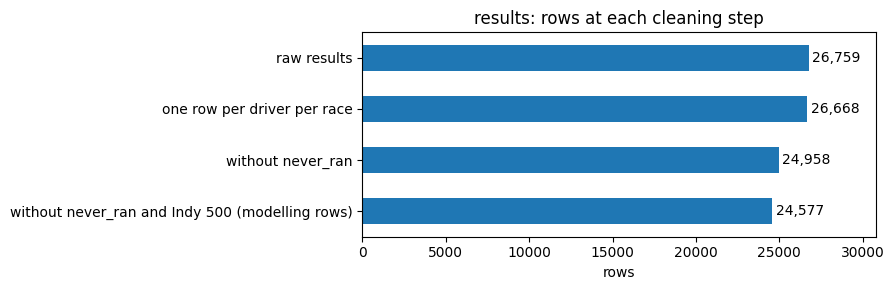

In [184]:
# rows of results at each step, down to the rows of the modelling table
post_model = results_unique[~results_unique.never_ran & ~results_unique.is_indy500]

post_steps = pd.Series({
    'raw results': len(raw_before['results']),
    'one row per driver per race': len(results_unique),
    'without never_ran': int((~results_unique.never_ran).sum()),
    'without never_ran and Indy 500 (modelling rows)': len(post_model),
})
display(post_steps.to_frame('rows').assign(removed=lambda d: -d.rows.diff().fillna(0).astype(int)))

ax = post_steps[::-1].plot.barh(figsize=(9, 3))
for i, v in enumerate(post_steps[::-1]):
    ax.text(v + 200, i, f'{v:,}', va='center')
ax.set_xlim(0, post_steps.max() * 1.15)
plt.xlabel('rows')
plt.title('results: rows at each cleaning step')
plt.tight_layout()
plt.show()

## 4.2 Missing values

The missing values before and after cleaning, first for all 14 tables, then column by column for `results`. Cleaning fills nothing, so after cleaning a table should have as many missing values as it had `\N` cells (plus the empty cells pandas already saw).

,missing seen by pandas (raw),\N in the raw file,missing after cleaning
results,0,122887,122260
qualifying,68,11600,11668
seasons,0,0,0
races,0,11349,11349
circuits,0,0,0
drivers,0,1559,1559
constructors,0,0,0
status,0,0,0
driver_standings,0,0,0
constructor_standings,0,0,0


,missing seen by pandas (raw),\N in the raw file,missing after cleaning
number,0,6,6
position,0,10953,10872
rank,0,18249,18158
fastestLap,0,18507,18416
fastestLapTime,0,18507,18416
fastestLapSpeed,0,18507,18416
milliseconds,0,19079,18988
time,0,19079,18988


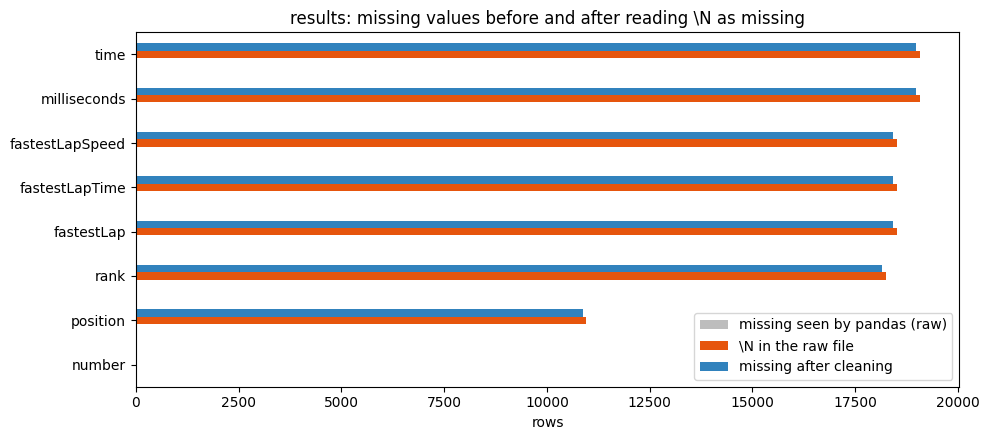

In [185]:
# the cleaned version of every table, next to raw_before
post_clean = {'results': results_unique, 'qualifying': qualifying, 'seasons': seasons, 'races': races,
              'circuits': circuits, 'drivers': drivers, 'constructors': constructors, 'status': status,
              'driver_standings': driver_standings, 'constructor_standings': constructor_standings,
              'constructor_results': constructor_results, 'sprint_results': sp,
              'lap_times': lap_times, 'pit_stops': ps}

# every table: missing values as pandas saw them in the raw file, the \N cells, and after cleaning
post_all = pd.DataFrame({
    'missing seen by pandas (raw)': {n: int(raw_before[n].isna().sum().sum()) for n in post_clean},
    '\\N in the raw file': {n: int((raw_before[n] == '\\N').sum().sum()) for n in post_clean},
    'missing after cleaning': {n: int(df[raw_before[n].columns].isna().sum().sum()) for n, df in post_clean.items()},
})
display(post_all)

# results: missing values as pandas saw them in the raw file, the real ones (\N), and after cleaning
post_raw = raw_before['results']
post_miss = pd.DataFrame({
    'missing seen by pandas (raw)': post_raw.isna().sum(),
    '\\N in the raw file': (post_raw == '\\N').sum(),
    'missing after cleaning': results_unique[post_raw.columns].isna().sum(),
})
post_miss = post_miss[post_miss.sum(axis=1) > 0].sort_values('\\N in the raw file')
display(post_miss)

post_miss.plot.barh(figsize=(10, 4.5), color=['#bdbdbd', '#e6550d', '#3182bd'])
plt.xlabel('rows')
plt.title('results: missing values before and after reading \\N as missing')
plt.tight_layout()
plt.show()

## 4.3 Column types

The number of text columns in each table before and after cleaning, and which columns changed type or were added. This shows the text that became numbers and dates.

,text before,text after,retyped,added
table,,,,
results,9,3,"number, position, milliseconds, fastestLap, rank, fastestLapSpeed","fastestLapTime_s, never_ran, pit_lane_start, grid_clean, is_indy500"
qualifying,3,3,,"q1_s, q2_s, q3_s"
seasons,1,1,,
races,14,8,"date, fp1_date, fp2_date, fp3_date, quali_date, sprint_date",
circuits,5,5,,
drivers,8,6,"number, dob",
constructors,4,4,,
status,1,1,,"times_used, group"
driver_standings,1,1,,


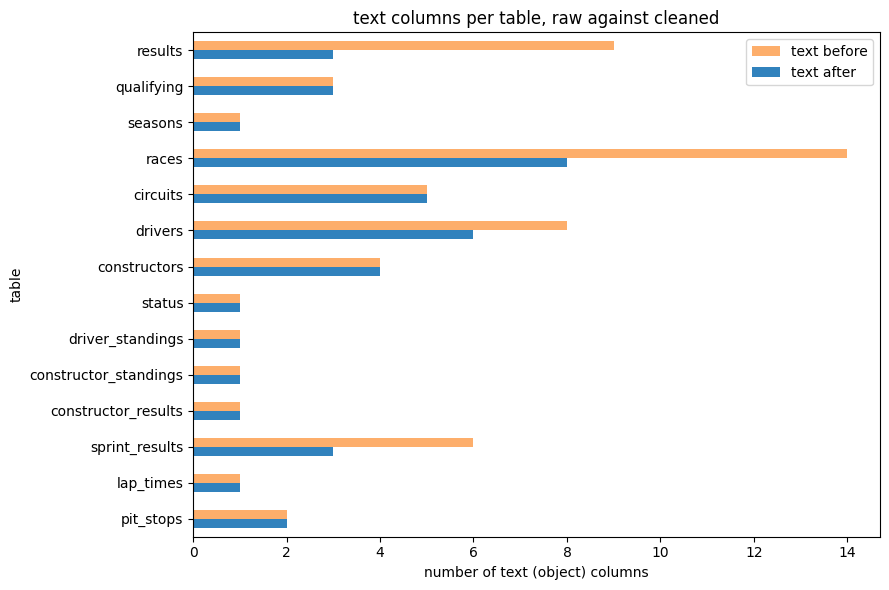

In [186]:
# column types of every table, raw against cleaned (columns added in cleaning are listed separately)

def kind(dtype):
    if pd.api.types.is_datetime64_any_dtype(dtype):
        return 'date'
    if pd.api.types.is_numeric_dtype(dtype) or pd.api.types.is_bool_dtype(dtype):
        return 'number'
    return 'text'


post_rows = []
for name, clean in post_clean.items():
    raw = raw_before[name]
    before = raw.dtypes.map(kind)
    after = clean[raw.columns].dtypes.map(kind)
    post_rows.append({'table': name,
                      'text before': int((before == 'text').sum()),
                      'text after': int((after == 'text').sum()),
                      'retyped': ', '.join(c for c in raw.columns if before[c] != after[c]),
                      'added': ', '.join(c for c in clean.columns if c not in raw.columns and c != 'year')})
post_types = pd.DataFrame(post_rows).set_index('table')
with pd.option_context('display.max_colwidth', None):
    display(post_types)

post_types[['text before', 'text after']].plot.barh(figsize=(9, 6), color=['#fdae6b', '#3182bd'])
plt.gca().invert_yaxis()
plt.xlabel('number of text (object) columns')
plt.title('text columns per table, raw against cleaned')
plt.tight_layout()
plt.show()

## 4.4 The target and the grid

The podium rate and the grid, before and after cleaning. They show what removing rows did to the target, and how `grid` = 0 was handled.

raw results                    12.69
one row per driver per race    12.73
modelling rows                 13.67


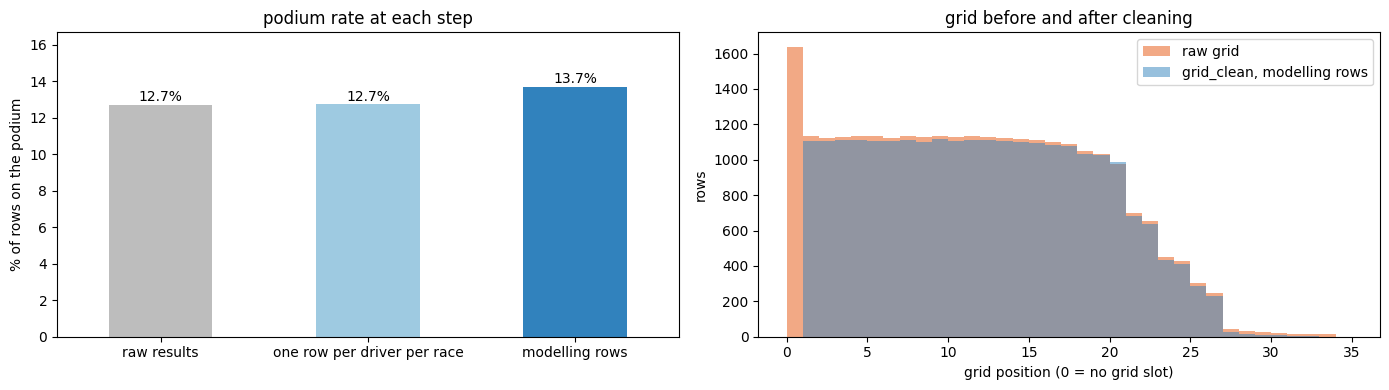

rows with grid 0, raw: 1638 | modelling rows with grid_clean 0: 0
podiums among never_ran rows: 0 | among Indy 500 rows: 36


In [187]:
# the target and the grid, raw against the modelling rows
post_rate = pd.Series({
    'raw results': (raw_before['results'].positionOrder <= 3).mean() * 100,
    'one row per driver per race': (results_unique.positionOrder <= 3).mean() * 100,
    'modelling rows': (post_model.positionOrder <= 3).mean() * 100,
})
print(post_rate.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

post_rate.plot.bar(ax=axes[0], rot=0, color=['#bdbdbd', '#9ecae1', '#3182bd'])
for i, v in enumerate(post_rate):
    axes[0].text(i, v + 0.2, f'{v:.1f}%', ha='center')
axes[0].set_ylim(0, post_rate.max() + 3)
axes[0].set_ylabel('% of rows on the podium')
axes[0].set_title('podium rate at each step')

bins = range(0, int(raw_before['results'].grid.max()) + 2)
axes[1].hist(raw_before['results'].grid, bins=bins, alpha=0.5, label='raw grid', color='#e6550d')
axes[1].hist(post_model.grid_clean, bins=bins, alpha=0.5, label='grid_clean, modelling rows', color='#3182bd')
axes[1].set_xlabel('grid position (0 = no grid slot)')
axes[1].set_ylabel('rows')
axes[1].set_title('grid before and after cleaning')
axes[1].legend()

plt.tight_layout()
plt.show()

print('rows with grid 0, raw:', int((raw_before['results'].grid == 0).sum()),
      '| modelling rows with grid_clean 0:', int((post_model.grid_clean == 0).sum()))
print('podiums among never_ran rows:', int((results_unique.never_ran & (results_unique.positionOrder <= 3)).sum()),
      '| among Indy 500 rows:', int((results_unique.is_indy500 & (results_unique.positionOrder <= 3)).sum()))

## 4.5 What the cleaning changed

**Rows.** `results` goes from 26,759 rows to 26,668 after keeping one row per driver per race (91 duplicate rows removed), and to 24,577 modelling rows once the 1,710 `never_ran` rows and the 381 Indianapolis 500 rows are left out. Those two groups are only flagged so far, and they are removed in section 5, after the history features.

**Missing values.** In the raw file pandas saw no missing value in `results` (the grey bars are all 0), while 122,887 cells held `\N`. After cleaning, each column's missing count is its `\N` count, lower by at most 91 because of the duplicate rows removed. All of these columns except `number` describe the race outcome, so they are not features (section 2, results). In the other 13 tables nothing changes: the missing values after cleaning are exactly the `\N` cells, plus the 68 cells `qualifying` already had empty.

**Types.** Text columns fall from 9 to 3 in `results`, 14 to 8 in `races`, 8 to 6 in `drivers` and 6 to 3 in `sprint_results`. The columns that were text only because of `\N` are numbers again, the six race dates and `dob` are dates, and the duration strings have numeric versions beside them (`fastestLapTime_s`, `q1_s` to `q3_s`, `duration_s`). `qualifying` and `pit_stops` keep the same number of text columns because the converted values are added next to the original text. The text columns left are names, codes, URLs and the time columns kept as text on purpose (section 2).

**Target.** The podium rate rises from 12.7% in the raw results to 13.7% in the modelling rows. None of the 1,710 `never_ran` rows is a podium and the Indianapolis 500 rows hold 36, so 2,091 rows are removed but only 36 podiums.

**Grid.** The raw results have 1,638 rows with `grid` = 0 and the modelling rows have none. The `never_ran` rows are left out, and the 72 pit-lane starters have `grid_clean` set to the back of the field (the highest grid slot in that race + 1), which shows as the small extra bar around grid 20.

# 5. Modelling table, phase 1: the base table

The cleaned tables are joined onto the deduplicated results: one row per driver per race, with the target and the flags. This is the first phase of the modelling table, and section 7 takes the columns it needs from it. The next phases are:
1. **Feature engineering** (section 7): add the feature columns, built from earlier races only. The flagged rows (`never_ran`, `is_indy500`) are still here, so a driver's history counts every race.
2. **Drop rows and pick columns** (9.1 and 9.7): remove the `never_ran` and Indianapolis 500 rows, keep the seasons 2003–2024, and keep only the features and the target (the flags are helpers, not model inputs).
3. **Split** (section 8) into training, validation and test seasons.
4. **Preprocessing** (section 9): fill missing feature values and scale, learned on the training data only (cleaning summary, *Missing values*).

In [188]:
# all the cleaned tables in one table: one row per driver per race, with the target and the flags
print('start:', len(results_unique))

base = (results_unique
        .merge(races[['raceId', 'year', 'round', 'circuitId', 'date', 'name']], on='raceId', how='left')
        .merge(circuits[['circuitId', 'country', 'alt']], on='circuitId', how='left')
        .merge(drivers[['driverId', 'surname', 'dob', 'nationality']].rename(columns={'nationality': 'driver_nat'}), on='driverId', how='left')
        .merge(constructors[['constructorId', 'name', 'nationality']].rename(columns={'name': 'team', 'nationality': 'team_nat'}), on='constructorId', how='left')
        .merge(status[['statusId', 'status']], on='statusId', how='left'))
base['podium'] = (base.positionOrder <= 3).astype(int)    # the target, never a feature

print('after merges:', len(base), '| row count unchanged:', len(base) == len(results_unique))
print('duplicate (raceId, driverId):', base.duplicated(['raceId', 'driverId']).sum())
print('missing after merge:', base[['year', 'country', 'surname', 'team', 'status']].isna().sum().to_dict())
print(base.shape)

start: 26668
after merges: 26668 | row count unchanged: True
duplicate (raceId, driverId): 0
missing after merge: {'year': 0, 'country': 0, 'surname': 0, 'team': 0, 'status': 0}
(26668, 37)


# 6. Data-engineering questions

The three data-engineering questions of the brief. Each one starts from the cleaned tables built above (sections 2 to 5): `results_unique` with its flags (`never_ran`, `pit_lane_start`, `grid_clean`, `is_indy500`), `races`, `circuits`, `drivers`, `constructors`, `status` (with its `group` column) and `qualifying`. No question loads or cleans the data again, and no question changes these tables.

Run the notebook from the top: some settings (for example `K_VALUES`) are defined again by each question.

## Q1: Which circuits turn a front-row start into a podium, and did that change after 2014?

A **front-row start** is starting the race from position 1 or 2. **Converting** it means finishing on the podium (1st, 2nd or 3rd). So for each circuit we ask: *when a driver starts on the front row here, how often do they finish on the podium?*

The question has three parts, answered in this order:
1. **Qualifying or grid?** Which number decides who started on the front row.
2. **Which circuits convert most often?**
3. **Did that change after 2014**, when Formula 1 moved to hybrid engines?

**Grain:** one front-row starter in one race (two rows per race). **Pre-race cutoff:** the grid is fixed before the race starts, so a front-row start is known at prediction time, and the podium is the outcome we count. **Missingness:** every race should have one car in slot 1 and one in slot 2, checked in 1.

### 0. Setup

Settings and small helper functions. The helpers (`table`, `md`, `savefig`, `wilson`, `bayes_avg`, `pct_range`) are also used by Q2 and Q3.

In [189]:
PRE_START = 1980        # first season of the earlier period (explained in 2.3)
HYBRID_START = 2014     # first season of the hybrid era
LAST_SEASON = 2024      # the brief covers seasons up to 2024
QUALI_START = QYEAR     # first season with complete qualifying records, set in the results section
K_MAIN = 10             # pretend front-row starts added to every circuit (2.2)
K_VALUES = [5, 10, 20]  # other numbers of pretend starts we try (2.5)
MIN_N = 10              # a circuit needs at least this many front-row starts to be ranked (about 5 races)
MIN_N_VALUES = [6, 10, 14]
TOP = 5                 # size of the top group
N_RESAMPLES = 2000      # pretend worlds in the luck test (3.3)
SEED = 42

ERA_PRE, ERA_POST = f"{PRE_START}–{HYBRID_START - 1}", f"{HYBRID_START}–{LAST_SEASON}"
ERAS = [ERA_PRE, ERA_POST]
ERA_COLORS = {ERA_PRE: "#4C72B0", ERA_POST: "#DD8452"}
GREY = "#8C8C8C"
FIG_DIR = os.path.join("report", "figures", "q1")
os.makedirs(FIG_DIR, exist_ok=True)

In [190]:
from scipy import stats                          # not imported in section 0
from IPython.display import display, Markdown

def table(df, pct=(), pct1=(), dec1=(), dec2=(), caption=None):
    """Show a DataFrame as a formatted table (pct: whole percent, pct1: one decimal)."""
    fmt = {c: "{:.0%}" for c in pct}
    fmt.update({c: "{:.1%}" for c in pct1})
    fmt.update({c: "{:.1f}" for c in dec1})
    fmt.update({c: "{:.2f}" for c in dec2})
    s = df.style.format(fmt, na_rep="–").hide(axis="index")
    if caption:
        s = s.set_caption(caption).set_table_styles([{"selector": "caption", "props": [
            ("caption-side", "top"), ("font-weight", "bold"), ("text-align", "left"), ("font-size", "110%")]}])
    display(s)

def md(text):
    """Show a result as formatted text."""
    display(Markdown(text))

def savefig(name):
    """Save the current figure (into this question's FIG_DIR) so it can be reused in the report."""
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")

def wilson(successes, n, z=1.96):
    """95% Wilson range for a rate of `successes` out of `n` (stays inside 0–100% for small samples)."""
    k, n = np.asarray(successes, dtype=float), np.asarray(n, dtype=float)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return np.minimum(centre - half, p), np.maximum(centre + half, p)   # min/max only removes rounding errors

def bayes_avg(events, starts, prior_rate, k):
    """Bayesian average: k pretend starts at `prior_rate`, plus the real results."""
    return (events + k * prior_rate) / (starts + k)

def pct_range(lo, hi, digits=0):
    """Format two arrays of rates as '57% – 90%' strings."""
    return [f"{a:.{digits}%} – {b:.{digits}%}" for a, b in zip(lo, hi)]

def short(name):
    """Shorter circuit names for figures."""
    if name == "Circuit of the Americas":
        return "Americas (COTA)"
    for w in ["Autodromo Nazionale di ", "Autodromo Internazionale ", "Autódromo ", "Autodromo ",
              "Circuit de ", "Circuito de ", "Circuit ", " Circuit", " International", " Internacional"]:
        name = name.replace(w, "")
    return name.strip()

def pct_axis(axis):
    """Show an axis in percent."""
    axis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

### 1. The data

We start from the **modelling rows** (notebook section 5): `results_unique` without the drivers who never started (`never_ran`) and without the Indianapolis 500. From the earlier sections:
- **Duplicates** (shared drives) end in 1978 and the **Indianapolis 500** in 1960, both before our seasons.
- **Drivers who did not start** (`never_ran`: no grid slot and no laps, or a grid slot but withdrew or did not qualify without running a lap) are left out, so a front-row slot whose car never started is not counted. Pit-lane starters (`grid` = 0 with laps) can never be slot 1 or 2.
- A circuit is identified by `circuitId`, so a track keeps one record under all its Grand Prix names.
- `qualifying` has one row per driver per race, so joining it adds no rows.

**Missing data check:** every race should have exactly one car in slot 1 and one in slot 2.

In [191]:
starters = results_unique[~results_unique.never_ran & ~results_unique.is_indy500]
q1_base = (starters[["raceId", "driverId", "grid", "positionOrder"]]
           .merge(races[["raceId", "year", "circuitId"]], on="raceId", how="left", validate="m:1")
           .merge(circuits[["circuitId", "name"]].rename(columns={"name": "circuit_name"}),
                  on="circuitId", how="left", validate="m:1")
           .merge(qualifying[["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"}),
                  on=["raceId", "driverId"], how="left", validate="1:1"))
q1_base = q1_base[q1_base.year.between(PRE_START, LAST_SEASON)].copy()
assert q1_base[["year", "circuit_name"]].notna().all().all()
q1_base["podium"] = (q1_base.positionOrder <= 3).astype(int)
q1_base["era"] = np.where(q1_base.year < HYBRID_START, ERA_PRE, ERA_POST)

fr = q1_base[q1_base.grid.isin([1, 2])].copy()   # one row per front-row start

race_era = q1_base.groupby("raceId").era.first()
fr_slots = (fr.groupby(["raceId", "grid"]).size().unstack(fill_value=0)
              .reindex(index=race_era.index, columns=[1, 2], fill_value=0))
table(pd.DataFrame({
    "races": race_era.value_counts(),
    "both front-row slots recorded": ((fr_slots[1] == 1) & (fr_slots[2] == 1)).groupby(race_era).mean(),
    "races with a slot held twice": ((fr_slots[1] > 1) | (fr_slots[2] > 1)).groupby(race_era).sum(),
    "front-row starts": fr.era.value_counts(),
    "share on the podium": fr.groupby("era").podium.mean(),
}).reindex(ERAS).rename_axis("period").reset_index(), pct=["both front-row slots recorded", "share on the podium"],
      caption="Front-row starts per period")

period,races,both front-row slots recorded,races with a slot held twice,front-row starts,share on the podium
1980–2013,569,99%,0,1133,60%
2014–2024,228,99%,0,453,76%


**Reading:** no slot is ever held twice. The few races without both slots are races where a front-row car did not start (it failed, crashed or withdrew before the start, for example Leclerc on pole at Monaco 2021). Those races count fewer front-row starts.

### Part 1: Qualifying or grid?

Two numbers could say who was on the front row:
- the **qualifying position**: where the driver qualified on Saturday;
- the **grid slot** (`grid`): where the car **actually started** on Sunday.

They are usually the same, but not always: a driver can qualify 1st, get a penalty (for example for changing an engine) and start 10th. In 2021 and 2022 a sprint race also set the grid.

**What we check:** from 2003 (the first season with complete qualifying records, see the results section), how often do front-row drivers finish on the podium in each case? The bars have an **error bar** (a "95% Wilson range"): the range the true rate is probably in. It is wide when there are few cases, narrow when there are many.

case,starts,podiums,podium rate,95% Wilson range
Qualified and started on the front row,815,594,73%,70% – 76%
Started on the front row without qualifying there,36,23,64%,48% – 78%
"Qualified on the front row, started further back",36,11,31%,18% – 47%


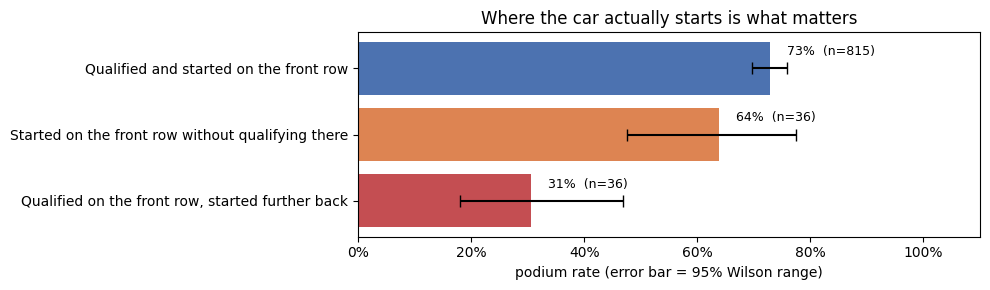

In [192]:
qa = q1_base[q1_base.year >= QUALI_START].copy()
fr_quali, fr_grid = qa.quali_pos.isin([1, 2]), qa.grid.isin([1, 2])
CASES = ["Qualified and started on the front row",
         "Started on the front row without qualifying there",
         "Qualified on the front row, started further back"]
qa["case"] = np.select([fr_quali & fr_grid, ~fr_quali & fr_grid, fr_quali & ~fr_grid], CASES, default="")

cases = (qa[qa.case != ""].groupby("case").agg(starts=("podium", "size"), podiums=("podium", "sum"))
           .reindex(CASES).reset_index())
cases["podium rate"] = cases.podiums / cases.starts
cases["ci_lo"], cases["ci_hi"] = wilson(cases.podiums, cases.starts)
table(cases.assign(**{"95% Wilson range": pct_range(cases.ci_lo, cases.ci_hi)}).drop(columns=["ci_lo", "ci_hi"]),
      pct=["podium rate"], caption=f"Podium rate by front-row case, {QUALI_START}–{LAST_SEASON}")

fig, ax = plt.subplots(figsize=(10, 3))
c = cases.iloc[::-1]
ax.barh(c.case, c["podium rate"], color=["#C44E52", "#DD8452", "#4C72B0"],
        xerr=[c["podium rate"] - c.ci_lo, c.ci_hi - c["podium rate"]], capsize=4)
for i, (rate, n) in enumerate(zip(c["podium rate"], c.starts)):
    ax.text(rate + 0.03, i + 0.25, f"{rate:.0%}  (n={n})", va="center", fontsize=9)
ax.set(xlim=(0, 1.1), xlabel="podium rate (error bar = 95% Wilson range)",
       title="Where the car actually starts is what matters")
pct_axis(ax.xaxis)
plt.tight_layout(); savefig("q1_01_quali_vs_grid"); plt.show()

In [193]:
kept, promoted, pushed = (cases.set_index("case").loc[x] for x in CASES)
md(f"""**Part 1 answer:**
- The two numbers agree in **{kept.starts / fr_grid.sum():.0%}** of front-row starts.
- When they disagree, it matters: drivers who qualified on the front row but **started further back** reached the podium
  only **{pushed['podium rate']:.0%}** of the time (n = {int(pushed.starts)}), against **{kept['podium rate']:.0%}** for drivers
  who kept their slot. Drivers moved **up** onto the front row converted **{promoted['podium rate']:.0%}** (n = {int(promoted.starts)}).
- **So we use the grid slot:** a front-row start means `grid` = 1 or 2. Using the qualifying position would count
  penalised drivers as front-row starters although they never started there.""")

**Part 1 answer:**
- The two numbers agree in **96%** of front-row starts.
- When they disagree, it matters: drivers who qualified on the front row but **started further back** reached the podium
  only **31%** of the time (n = 36), against **73%** for drivers
  who kept their slot. Drivers moved **up** onto the front row converted **64%** (n = 36).
- **So we use the grid slot:** a front-row start means `grid` = 1 or 2. Using the qualifying position would count
  penalised drivers as front-row starters although they never started there.

### Part 2: Which circuits convert a front-row start most often?

#### 2.1 The basic count

For each circuit: **podiums ÷ front-row starts**. For example, if a circuit had 18 front-row starts and 16 of them finished on the podium, its rate is 16 ÷ 18 = 89%. The table shows the highest rates since 2014, counting every circuit.

In [194]:
raw = (fr[fr.era == ERA_POST].groupby("circuit_name")
         .agg(races=("raceId", "nunique"), **{"front-row starts": ("podium", "size"), "podiums": ("podium", "sum")})
         .reset_index().rename(columns={"circuit_name": "circuit"}))
raw["rate"] = raw.podiums / raw["front-row starts"]
table(raw.sort_values(["rate", "front-row starts"], ascending=False).head(8), pct=["rate"],
      caption=f"The basic count, {ERA_POST}: highest rates")

circuit,races,front-row starts,podiums,rate
Miami International Autodrome,3,6,6,100%
Autódromo Internacional do Algarve,2,4,4,100%
Las Vegas Strip Street Circuit,2,4,4,100%
Autodromo Internazionale del Mugello,1,2,2,100%
Circuit de Monaco,10,19,17,89%
Suzuka Circuit,9,18,16,89%
Circuit Park Zandvoort,4,8,7,88%
Jeddah Corniche Circuit,4,8,7,88%


**Reading:** the top of the list is full of circuits that hosted only one to three races. A circuit with one race where both front-row cars reached the podium gets 100%. Ranking by this number has **two problems**, fixed in 2.2 and 2.3.

#### 2.2 Problem 1: a few races can be luck

Mugello hosted **one** race (2020). Both front-row cars reached the podium, so its rate is 2 ÷ 2 = 100%. Suzuka had 16 out of 18. That does not show Mugello is the better circuit because one race proves very little.

**The fix: pretend starts.** Every circuit gets **10 pretend front-row starts at the normal rate**, and then its real results are added:

> adjusted rate = (podiums + 10 × normal rate) ÷ (front-row starts + 10)

A circuit with many real races barely moves, because its real data outweighs the 10 pretend starts. A circuit with one race is pulled most of the way back to normal. Since 2014 the normal rate is about 76%:

In [195]:
normal_post = fr[fr.era == ERA_POST].podium.mean()
ex = raw[raw.circuit.isin(["Autodromo Internazionale del Mugello", "Suzuka Circuit"])].copy()
ex["normal rate"] = normal_post
ex[f"adjusted rate ({K_MAIN} pretend starts)"] = bayes_avg(ex.podiums, ex["front-row starts"], normal_post, K_MAIN)
table(ex, pct=["rate", "normal rate", f"adjusted rate ({K_MAIN} pretend starts)"],
      caption="Pretend starts: one race against nine")

circuit,races,front-row starts,podiums,rate,normal rate,adjusted rate (10 pretend starts)
Autodromo Internazionale del Mugello,1,2,2,100%,76%,80%
Suzuka Circuit,9,18,16,89%,76%,84%


**Reading:** Mugello drops from 100% to about 80%, Suzuka only from 89% to about 84%, so Suzuka now ranks above Mugello. On top of this, a circuit needs at least **10 front-row starts** (about 5 races) to appear in the ranking at all. Review sites use the same idea, so that a film with one perfect review cannot beat one with a thousand good reviews.

#### 2.3 Problem 2: some circuits raced in "easy" years

In the 1980s cars broke down very often, so even drivers starting first often did not finish. Later, cars became reliable. The chart shows the share of front-row starters who reached the podium in every season.

**Why 1980:** from the 1980 season the staggered two-wide grid was standard in every race, so grid 1–2 is always the front row. Earlier grids were often three or four cars wide (for example 4-3-4 or 3-2-3 in the 1950s and 1960s), so "grid 1–2" would not mean "the front row". This comes from F1 history, not from the data: Ergast does not store how many cars stood in each row.

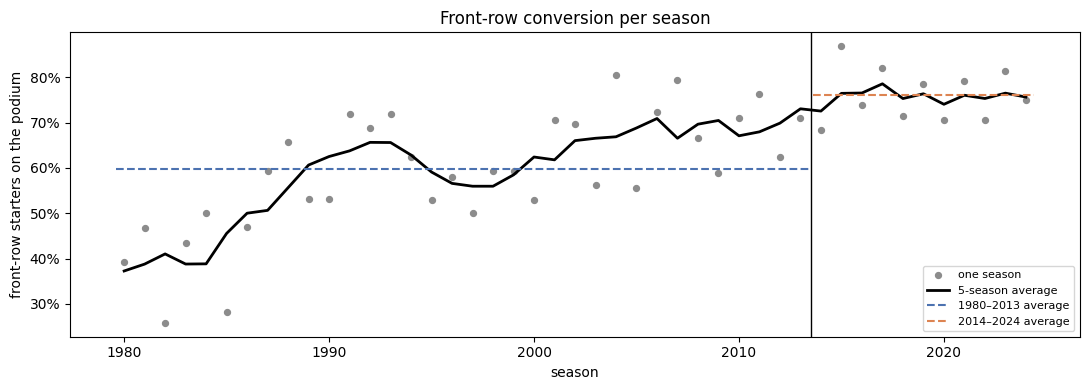

**Reading:**
- Before 2014 conversion rises from about **41%** in
  1980–1984 to about **68%** in
  2009–2013. The rise is not smooth (it dips in the late 1990s), and there is no single year
  where it jumps.
- After 2014 it is nearly flat: the 5-season average stays between **73%** and
  **79%**.
- So a circuit used mostly in later seasons looks better **just because of its years**. Across the 1980–2013 circuits,
  the correlation between the middle year a circuit was used and its rate is **0.54**.

In [196]:
season = fr.groupby("year").podium.agg(starts="size", rate="mean")
season["5-season average"] = season.rate.rolling(5, center=True, min_periods=3).mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.scatter(season.index, season.rate, color=GREY, s=18, label="one season")
ax.plot(season.index, season["5-season average"], color="black", lw=2, label="5-season average")
for e, (a, b) in {ERA_PRE: (PRE_START, HYBRID_START - 1), ERA_POST: (HYBRID_START, LAST_SEASON)}.items():
    ax.hlines(fr[fr.era == e].podium.mean(), a - 0.4, b + 0.4, color=ERA_COLORS[e], ls="--", label=f"{e} average")
ax.axvline(HYBRID_START - 0.5, color="black", lw=1)
ax.set(xlabel="season", ylabel="front-row starters on the podium", title="Front-row conversion per season")
pct_axis(ax.yaxis); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); savefig("q1_02_conversion_by_season"); plt.show()

pre = fr[fr.era == ERA_PRE].groupby("circuitId").agg(mid_year=("year", "median"), rate=("podium", "mean"),
                                                      n=("podium", "size"))
pre = pre[pre.n >= MIN_N]
r_year = np.corrcoef(pre.mid_year, pre.rate)[0, 1]
roll = season["5-season average"]
md(f"""**Reading:**
- Before 2014 conversion rises from about **{season.loc[PRE_START:PRE_START + 4].rate.mean():.0%}** in
  {PRE_START}–{PRE_START + 4} to about **{season.loc[HYBRID_START - 5:HYBRID_START - 1].rate.mean():.0%}** in
  {HYBRID_START - 5}–{HYBRID_START - 1}. The rise is not smooth (it dips in the late 1990s), and there is no single year
  where it jumps.
- After 2014 it is nearly flat: the 5-season average stays between **{roll.loc[HYBRID_START:].min():.0%}** and
  **{roll.loc[HYBRID_START:].max():.0%}**.
- So a circuit used mostly in later seasons looks better **just because of its years**. Across the 1980–2013 circuits,
  the correlation between the middle year a circuit was used and its rate is **{r_year:.2f}**.""")

**The fix: compare each circuit with what was normal in its own years.**

**How the normal rate is calculated**, in two steps:
1. **For every season**, take all front-row starters of that season, at every circuit, and compute the share who reached the podium. These are the grey dots in the chart above. For example, in 2005 there were 36 front-row starts and 20 podiums, so 2005's rate is 56%.
2. **For a circuit**, look up the rate of each season it was used in and take the average (each season counts once for every front-row start the circuit had in it).

Istanbul Park, worked out:

In [197]:
season_rate = fr.groupby("year").podium.agg(**{"front-row starts (all circuits)": "size",
                                               "podiums (all circuits)": "sum", "season rate": "mean"})
ist_years = fr[(fr.circuit_name == "Istanbul Park") & (fr.era == ERA_PRE)].groupby("year").size().rename("Istanbul front-row starts")
ist_table = season_rate.loc[ist_years.index].join(ist_years).reset_index()
ist_normal = np.average(ist_table["season rate"], weights=ist_table["Istanbul front-row starts"])
table(ist_table, pct=["season rate"], caption=f"Istanbul Park's normal rate: the average of its seasons = {ist_normal:.0%}")

year,front-row starts (all circuits),podiums (all circuits),season rate,Istanbul front-row starts
2005,36,20,56%,2
2006,36,26,72%,2
2007,34,27,79%,2
2008,36,24,67%,2
2009,34,20,59%,2
2010,38,27,71%,2
2011,38,29,76%,2


**Then:**
- the pretend starts from 2.2 are given at this normal rate, and
- the circuit's **score = adjusted rate − normal rate for its years**, in percentage points: *how much better than normal the front row does at this circuit.*

**Circuits are ranked by this score.** The table shows four circuits: Mugello and Suzuka from 2.2, and two circuits from the earlier period that raced in very different years.

In [198]:
def circuit_table(starts, min_n=MIN_N, k_values=K_VALUES):
    """One row per circuit and period: raw rate, Wilson range, normal rate for its years, scores and ranks.

    `starts` has one row per front-row start, with columns era, year, circuitId, circuit_name, raceId, podium.
    Each season's rate is computed over ALL front-row starts of the season, before the minimum-sample filter.
    """
    season_rate = starts.groupby("year")["podium"].mean()
    t = (starts.assign(expected=starts.year.map(season_rate))
               .groupby(["era", "circuitId"])
               .agg(circuit=("circuit_name", "first"), first=("year", "min"), last=("year", "max"),
                    races=("raceId", "nunique"), starts=("podium", "size"), podiums=("podium", "sum"),
                    expected=("expected", "mean"))
               .reset_index())
    t["raw rate"] = t.podiums / t.starts
    t["ci_lo"], t["ci_hi"] = wilson(t.podiums, t.starts)
    for k in k_values:
        t[f"score_k{k}"] = bayes_avg(t.podiums, t.starts, t.expected, k) - t.expected
    t = t[t.starts >= min_n].copy()
    for k in k_values:
        t[f"rank_k{k}"] = t.groupby("era")[f"score_k{k}"].rank(ascending=False, method="min").astype(int)
    sort_k = K_MAIN if K_MAIN in k_values else k_values[0]
    return t.sort_values(["era", f"rank_k{sort_k}"]).reset_index(drop=True)

RANK_COLS = [f"rank_k{k}" for k in K_VALUES]

def top_group(t, top=TOP):
    """Circuits that are in the top `top` under every value of k."""
    return t[(t[RANK_COLS] <= top).all(axis=1)]

def circuit_rows(t):
    """The circuit table in readable form (k = K_MAIN)."""
    return pd.DataFrame({
        "circuit": t.circuit,
        "seasons": [f"{a}" if a == b else f"{a}–{b}" for a, b in zip(t["first"], t["last"])],
        "front-row starts": t.starts, "podiums": t.podiums, "raw rate": t["raw rate"],
        "95% Wilson range": pct_range(t.ci_lo, t.ci_hi), "normal for its years": t.expected,
        f"adjusted rate (+{K_MAIN} pretend starts)": t.expected + t[f"score_k{K_MAIN}"],
        "score: adjusted − normal (points)": t[f"score_k{K_MAIN}"] * 100})

examples = circuit_table(fr, min_n=1, k_values=[K_MAIN])
EXAMPLES = [(ERA_POST, "Autodromo Internazionale del Mugello"), (ERA_POST, "Suzuka Circuit"),
            (ERA_PRE, "Istanbul Park"), (ERA_PRE, "Brands Hatch")]
examples = examples.set_index(["era", "circuit"]).loc[EXAMPLES].reset_index()
table(circuit_rows(examples).assign(period=examples.era.values),
      pct=["raw rate", "normal for its years", f"adjusted rate (+{K_MAIN} pretend starts)"], dec1=["score: adjusted − normal (points)"],
      caption="The score on four circuits")

circuit,seasons,front-row starts,podiums,raw rate,95% Wilson range,normal for its years,adjusted rate (+10 pretend starts),score: adjusted − normal (points),period
Autodromo Internazionale del Mugello,2020,2,2,100%,34% – 100%,71%,75%,4.9,2014–2024
Suzuka Circuit,2014–2024,18,16,89%,67% – 97%,76%,84%,8.0,2014–2024
Istanbul Park,2005–2011,14,11,79%,52% – 92%,69%,74%,5.8,1980–2013
Brands Hatch,1980–1986,12,3,25%,9% – 53%,39%,31%,-7.6,1980–2013


In [199]:
mug, suz, ist, bra = (examples.iloc[i] for i in range(4))
md(f"""**Reading:**
- **Istanbul Park** ({ist['first']}–{ist['last']}) raced in reliable years, where normal was {ist.expected:.0%}. It got
  {ist['raw rate']:.0%}, a score of {ist[f'score_k{K_MAIN}'] * 100:+.1f} points.
- **Brands Hatch** ({bra['first']}–{bra['last']}) raced when cars broke down often, where normal was {bra.expected:.0%}.
  It got {bra['raw rate']:.0%}, a score of {bra[f'score_k{K_MAIN}'] * 100:+.1f} points.
- Both are judged against their own years, not one average for 1980–2013.
- **Mugello** ({mug[f'score_k{K_MAIN}'] * 100:+.1f}) stays below **Suzuka** ({suz[f'score_k{K_MAIN}'] * 100:+.1f}), as in 2.2.""")

**Reading:**
- **Istanbul Park** (2005–2011) raced in reliable years, where normal was 69%. It got
  79%, a score of +5.8 points.
- **Brands Hatch** (1980–1986) raced when cars broke down often, where normal was 39%.
  It got 25%, a score of -7.6 points.
- Both are judged against their own years, not one average for 1980–2013.
- **Mugello** (+4.9) stays below **Suzuka** (+8.0), as in 2.2.

#### 2.4 The ranking

The top 10 circuits of each period by score (at least 10 front-row starts). The figure shows the 12 best. For each circuit, the **grey dot** is the normal rate for its years and the **coloured dot** is its adjusted rate; the line between them is the score, written on the right. The longer the line, the more the front row beats normal at that circuit.

rank,circuit,seasons,front-row starts,podiums,raw rate,95% Wilson range,normal for its years,adjusted rate (+10 pretend starts),score: adjusted − normal (points)
1,Circuit de Nevers Magny-Cours,1991–2008,35,29,83%,67% – 92%,65%,79%,14.2
2,Circuit Paul Ricard,1980–1990,18,12,67%,44% – 84%,46%,59%,13.2
3,Autódromo Hermanos Rodríguez,1986–1992,14,10,71%,45% – 88%,60%,67%,6.8
4,Kyalami,1980–1993,14,8,57%,33% – 79%,47%,53%,6.1
5,Autódromo do Estoril,1984–1996,26,17,65%,46% – 81%,57%,63%,6.0
6,Istanbul Park,2005–2011,14,11,79%,52% – 92%,69%,74%,5.8
7,Indianapolis Motor Speedway,2000–2007,14,11,79%,52% – 92%,69%,75%,5.7
8,Suzuka Circuit,1987–2013,50,35,70%,56% – 81%,63%,69%,5.5
9,Circuito de Jerez,1986–1997,14,9,64%,39% – 84%,56%,61%,4.9
10,Autódromo Juan y Oscar Gálvez,1980–1998,12,7,58%,32% – 81%,51%,55%,4.0


rank,circuit,seasons,front-row starts,podiums,raw rate,95% Wilson range,normal for its years,adjusted rate (+10 pretend starts),score: adjusted − normal (points)
1,Circuit de Monaco,2014–2024,19,17,89%,69% – 97%,77%,85%,8.4
2,Suzuka Circuit,2014–2024,18,16,89%,67% – 97%,76%,84%,8.0
3,Yas Marina Circuit,2014–2024,22,19,86%,67% – 95%,76%,83%,7.0
4,Circuit de Barcelona-Catalunya,2014–2024,22,18,82%,61% – 93%,76%,80%,3.9
4,Circuit de Spa-Francorchamps,2014–2024,22,18,82%,61% – 93%,76%,80%,3.9
6,Sochi Autodrom,2014–2021,16,13,81%,57% – 93%,76%,79%,3.0
7,Circuit of the Americas,2014–2024,20,16,80%,58% – 92%,77%,79%,2.2
8,Autódromo José Carlos Pace,2014–2024,19,15,79%,57% – 91%,76%,78%,1.6
9,Shanghai International Circuit,2014–2024,14,11,79%,52% – 92%,77%,78%,1.2
10,Circuit Gilles Villeneuve,2014–2024,18,14,78%,55% – 91%,76%,77%,0.9


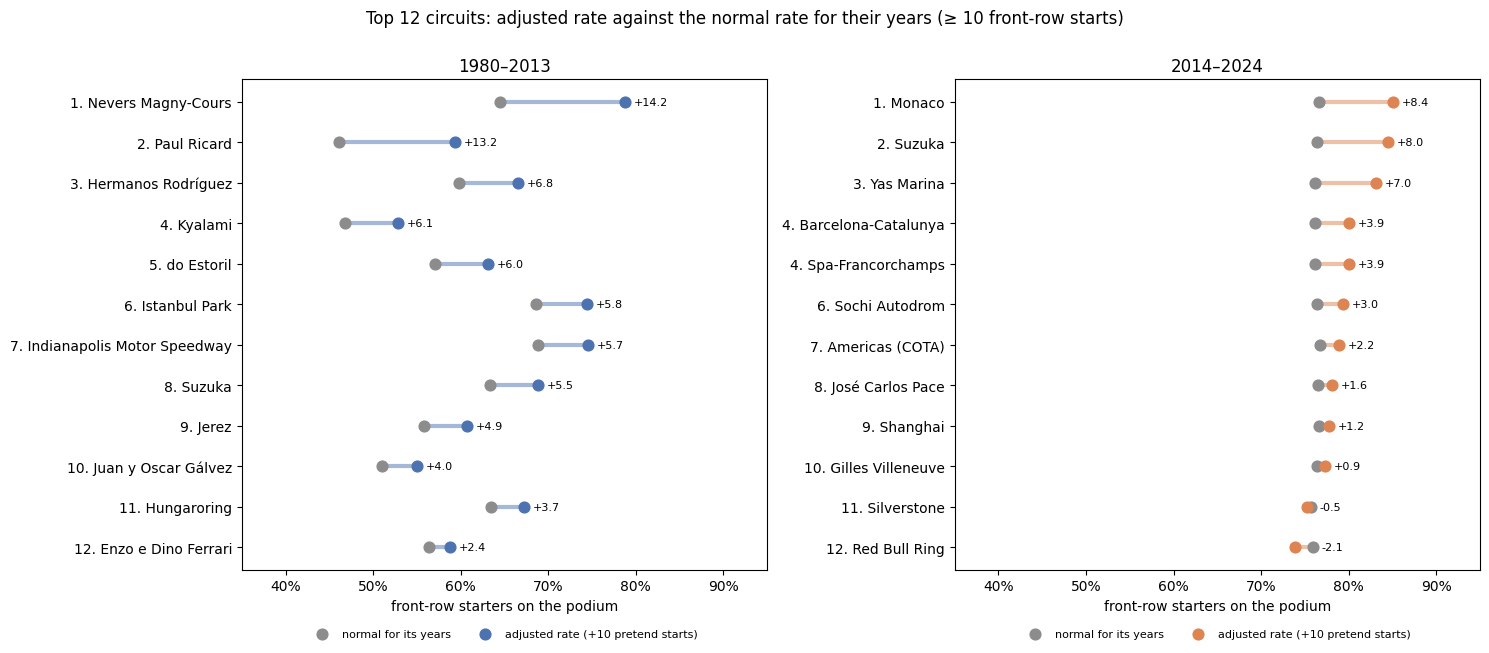

In [200]:
ct = circuit_table(fr)
for e in ERAS:
    t = ct[ct.era == e]
    top10 = circuit_rows(t.head(10))
    top10.insert(0, "rank", t.head(10)[f"rank_k{K_MAIN}"].values)
    table(top10, pct=["raw rate", "normal for its years", f"adjusted rate (+{K_MAIN} pretend starts)"], dec1=["score: adjusted − normal (points)"],
          caption=f"{e}: top 10 of {len(t)} ranked circuits")

TOP_FIG = 12
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, e in zip(axes, ERAS):
    t = ct[ct.era == e].head(TOP_FIG).iloc[::-1]
    y = np.arange(len(t))
    adjusted = t.expected + t[f"score_k{K_MAIN}"]
    ax.hlines(y, t.expected, adjusted, color=ERA_COLORS[e], lw=3, alpha=0.5)
    ax.scatter(t.expected, y, color=GREY, s=60, zorder=3, label="normal for its years")
    ax.scatter(adjusted, y, color=ERA_COLORS[e], s=60, zorder=4, label=f"adjusted rate (+{K_MAIN} pretend starts)")
    for yi, a, x, sc in zip(y, adjusted, t.expected, t[f"score_k{K_MAIN}"]):
        ax.text(max(a, x) + 0.01, yi, f"{sc * 100:+.1f}", va="center", fontsize=8)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{r}. {short(n)}" for r, n in zip(t[f"rank_k{K_MAIN}"], t.circuit)])
    ax.set(title=e, xlabel="front-row starters on the podium", xlim=(0.35, 0.95))
    pct_axis(ax.xaxis)
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
fig.suptitle(f"Top {TOP_FIG} circuits: adjusted rate against the normal rate for their years (≥ {MIN_N} front-row starts)", y=1.0)
plt.tight_layout(); savefig("q1_03_top_circuits"); plt.show()

#### 2.5 Does the answer depend on our choices?

We chose **10** pretend starts and a minimum of **10** front-row starts. Neither number is "correct", so we also tried **5 and 20** pretend starts and a minimum of **6 and 14**. Because neighbouring circuits are very close, we do not trust exact ranks; we report the **top group**: circuits in the top 5 with 5, 10 **and** 20 pretend starts.

In [201]:
rob_rows, groups = [], {}
for m in MIN_N_VALUES:
    t_m = circuit_table(fr, min_n=m)
    for e in ERAS:
        g = top_group(t_m[t_m.era == e])
        groups[(e, m)] = set(g.circuitId)
        rob_rows.append({"period": e, "minimum front-row starts": m, "circuits ranked": int((t_m.era == e).sum()),
                         f"top group (top {TOP} with 5, 10 and 20 pretend starts)": ", ".join(g.circuit) or "none"})
table(pd.DataFrame(rob_rows).sort_values(["period", "minimum front-row starts"]), caption="The top group under each choice")

period,minimum front-row starts,circuits ranked,"top group (top 5 with 5, 10 and 20 pretend starts)"
1980–2013,6,40,"Circuit de Nevers Magny-Cours, Circuit Paul Ricard, Zolder, Autódromo Hermanos Rodríguez"
1980–2013,10,34,"Circuit de Nevers Magny-Cours, Circuit Paul Ricard, Autódromo Hermanos Rodríguez"
1980–2013,14,28,"Circuit de Nevers Magny-Cours, Circuit Paul Ricard, Autódromo Hermanos Rodríguez"
2014–2024,6,27,"Miami International Autodrome, Circuit de Monaco, Suzuka Circuit, Yas Marina Circuit, Circuit Park Zandvoort, Jeddah Corniche Circuit"
2014–2024,10,19,"Circuit de Monaco, Suzuka Circuit, Yas Marina Circuit, Circuit de Barcelona-Catalunya, Circuit de Spa-Francorchamps"
2014–2024,14,19,"Circuit de Monaco, Suzuka Circuit, Yas Marina Circuit, Circuit de Barcelona-Catalunya, Circuit de Spa-Francorchamps"


#### 2.6 Part 2 answer

In [202]:
robust_ids = {e: set.intersection(*(groups[(e, m)] for m in MIN_N_VALUES)) for e in ERAS}
lines = []
for e in ERAS:
    t = top_group(ct[ct.era == e])
    desc = "; ".join(f"**{c}**{' ✓' if cid in robust_ids[e] else ''} ({p}/{n}, normal {x:.0%}, {s * 100:+.0f} points)"
                     for cid, c, p, n, x, s in zip(t.circuitId, t.circuit, t.podiums, t.starts, t.expected,
                                                   t[f"score_k{K_MAIN}"])) or "none"
    lines.append(f"- **{e}:** {desc}.")
md("**The circuits that convert a front-row start most often** (podiums/front-row starts, normal rate for its years, "
   "score):\n" + "\n".join(lines) +
   f"\n\n✓ = in the top group under every choice we tried, so it does not depend on our choices. The others drop out "
   f"only when the minimum is lowered to {MIN_N_VALUES[0]} and circuits with three or four races enter.")

**The circuits that convert a front-row start most often** (podiums/front-row starts, normal rate for its years, score):
- **1980–2013:** **Circuit de Nevers Magny-Cours** ✓ (29/35, normal 65%, +14 points); **Circuit Paul Ricard** ✓ (12/18, normal 46%, +13 points); **Autódromo Hermanos Rodríguez** ✓ (10/14, normal 60%, +7 points).
- **2014–2024:** **Circuit de Monaco** ✓ (17/19, normal 77%, +8 points); **Suzuka Circuit** ✓ (16/18, normal 76%, +8 points); **Yas Marina Circuit** ✓ (19/22, normal 76%, +7 points); **Circuit de Barcelona-Catalunya** (18/22, normal 76%, +4 points); **Circuit de Spa-Francorchamps** (18/22, normal 76%, +4 points).

✓ = in the top group under every choice we tried, so it does not depend on our choices. The others drop out only when the minimum is lowered to 6 and circuits with three or four races enter.

### Part 3: Did the ranking change after 2014?

**The hybrid era.** In 2014 Formula 1 replaced its engines: the fuel-only V8s were replaced by smaller 1.6-litre V6 turbo engines with electric motors and batteries that store and reuse energy (called power units). The cars behaved very differently, and some teams adapted much better than others. The question asks whether this change also changed **which circuits** the front row converts best at.

#### 3.1 Which circuits can be compared?

**Why only circuits used in both periods.** The two top lists in Part 2 are completely different, but mostly because **the calendar changed**: Magny-Cours stopped hosting F1 in 2008, so it cannot appear after 2014, and Yas Marina started in 2009, so it had few races before. Comparing those two lists would show the calendar change, not the effect of the hybrid era. To see whether the hybrid era changed the ranking, we compare **the same circuits** before and after 2014, so that only the period differs.

A circuit is compared if it has at least 10 front-row starts before 2014 **and** after.

In [203]:
counts = (fr.groupby(["circuitId", "era"]).size().unstack(fill_value=0)
            .reindex(columns=ERAS, fill_value=0))
names = fr.groupby("circuitId").circuit_name.first()
STATUSES = ["compared", f"raced in both periods, but fewer than {MIN_N} front-row starts in one",
            f"only raced in {ERA_PRE}", f"only raced in {ERA_POST}"]

def comparison_status(row):
    pre, post = row[ERA_PRE], row[ERA_POST]
    if pre >= MIN_N and post >= MIN_N: return STATUSES[0]
    if pre > 0 and post > 0: return STATUSES[1]
    return STATUSES[2] if post == 0 else STATUSES[3]

counts["status"] = counts.apply(comparison_status, axis=1)

def compared_ids(m):
    return list(counts.index[(counts[ERA_PRE] >= m) & (counts[ERA_POST] >= m)])

comp_ids = compared_ids(MIN_N)
table(pd.DataFrame([{"status": s, "circuits": int((counts.status == s).sum()),
                     "which (front-row starts before / after 2014)":
                         ", ".join(f"{names[c]} ({counts.loc[c, ERA_PRE]} / {counts.loc[c, ERA_POST]})"
                                   for c in counts.index[counts.status == s])}
                    for s in STATUSES]),
      caption="Which circuits enter the before/after comparison")

status,circuits,which (front-row starts before / after 2014)
compared,16,"Albert Park Grand Prix Circuit (36 / 18), Bahrain International Circuit (18 / 24), Circuit de Barcelona-Catalunya (45 / 22), Circuit de Monaco (68 / 19), Circuit Gilles Villeneuve (64 / 18), Silverstone Circuit (60 / 24), Hungaroring (56 / 22), Circuit de Spa-Francorchamps (56 / 22), Autodromo Nazionale di Monza (66 / 22), Marina Bay Street Circuit (12 / 18), Shanghai International Circuit (20 / 14), Autódromo José Carlos Pace (50 / 19), Suzuka Circuit (50 / 18), Yas Marina Circuit (10 / 22), Autódromo Hermanos Rodríguez (14 / 18), Red Bull Ring (30 / 26)"
"raced in both periods, but fewer than 10 front-row starts in one",8,"Sepang International Circuit (30 / 7), Istanbul Park (14 / 4), Hockenheimring (57 / 8), Nürburgring (36 / 2), Autodromo Enzo e Dino Ferrari (54 / 8), Circuit Paul Ricard (18 / 8), Circuit Park Zandvoort (12 / 8), Circuit of the Americas (4 / 20)"
only raced in 1980–2013,24,"Circuit de Nevers Magny-Cours (35 / 0), Valencia Street Circuit (10 / 0), Fuji Speedway (4 / 0), Indianapolis Motor Speedway (14 / 0), Autódromo Juan y Oscar Gálvez (12 / 0), Circuito de Jerez (14 / 0), Autódromo do Estoril (26 / 0), Okayama International Circuit (4 / 0), Adelaide Street Circuit (22 / 0), Kyalami (14 / 0), Donington Park (2 / 0), Phoenix street circuit (6 / 0), Korean International Circuit (8 / 0), Autódromo Internacional Nelson Piquet (18 / 0), Detroit Street Circuit (14 / 0), Brands Hatch (12 / 0), Zolder (8 / 0), Dijon-Prenois (6 / 0), Fair Park (2 / 0), Long Beach (8 / 0), Las Vegas Street Circuit (4 / 0), Jarama (2 / 0), Watkins Glen (2 / 0), Buddh International Circuit (6 / 0)"
only raced in 2014–2024,8,"Sochi Autodrom (0 / 16), Baku City Circuit (0 / 16), Autódromo Internacional do Algarve (0 / 4), Autodromo Internazionale del Mugello (0 / 2), Jeddah Corniche Circuit (0 / 8), Losail International Circuit (0 / 6), Miami International Autodrome (0 / 6), Las Vegas Strip Street Circuit (0 / 4)"


#### 3.2 The two rankings side by side

The compared circuits are ranked among themselves by their score, before and after 2014. The score already compares each circuit with what was normal in its own years, so the general rise in conversion after 2014 does not move circuits around; only circuit-specific changes do.

To measure how similar the two rankings are we use one number, the **similarity score ρ** (Spearman rank correlation): **1** means exactly the same order, **0** means the two orders are unrelated.

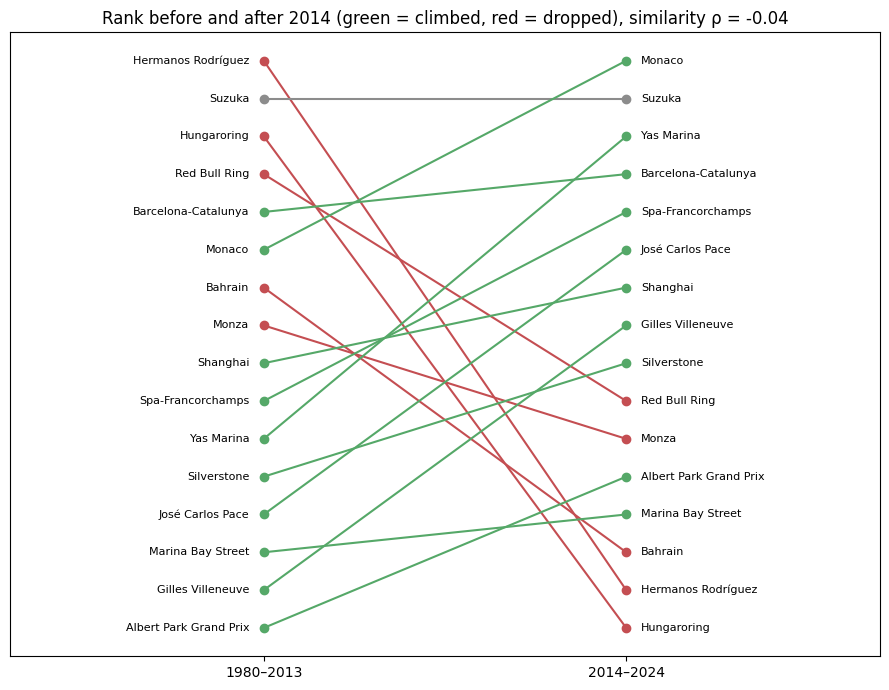

**Reading:** the two rankings look very different. The similarity score is **ρ = -0.04**, close to 0.
Biggest climbers: Yas Marina (11→3), Gilles Villeneuve (15→8), José Carlos Pace (13→6). Biggest fallers: Hermanos Rodríguez (1→15), Hungaroring (3→16), Bahrain (7→14).

In [204]:
def era_compare(k, ids):
    """Scores of the compared circuits in both periods, ranked among themselves."""
    t = circuit_table(fr, min_n=1, k_values=[k])
    w = t[t.circuitId.isin(ids)].pivot(index="circuitId", columns="era", values=f"score_k{k}")[ERAS]
    w["rank before"] = w[ERA_PRE].rank(ascending=False, method="min").astype(int)
    w["rank after"] = w[ERA_POST].rank(ascending=False, method="min").astype(int)
    w["change"] = w["rank before"] - w["rank after"]          # positive = climbed after 2014
    w["circuit"] = names.reindex(w.index).map(short)
    return w

w = era_compare(K_MAIN, comp_ids)
rho_main = stats.spearmanr(w[ERA_PRE], w[ERA_POST])[0]

s = w.assign(y0=w[ERA_PRE].rank(ascending=False, method="first"),      # tie-free positions so labels do not overlap
             y1=w[ERA_POST].rank(ascending=False, method="first")).sort_values("y0")
fig, ax = plt.subplots(figsize=(9, 7))
for name, r0, r1 in zip(s.circuit, s.y0, s.y1):
    col = "#55A868" if r1 < r0 else ("#C44E52" if r1 > r0 else GREY)
    ax.plot([0, 1], [r0, r1], color=col, marker="o")
    ax.text(-0.04, r0, name, ha="right", va="center", fontsize=8)
    ax.text(1.04, r1, name, ha="left", va="center", fontsize=8)
ax.invert_yaxis(); ax.set_xticks([0, 1]); ax.set_xticklabels(ERAS); ax.set_xlim(-0.7, 1.7)
ax.set_yticks([]); ax.grid(False)
ax.set_title(f"Rank before and after 2014 (green = climbed, red = dropped), similarity ρ = {rho_main:.2f}")
plt.tight_layout(); savefig("q1_04_before_after_ranks"); plt.show()

up, down = w.sort_values("change", ascending=False).head(3), w.sort_values("change").head(3)
fmt_moves = lambda d: ", ".join(f"{c} ({a}→{b})" for c, a, b in zip(d.circuit, d["rank before"], d["rank after"]))
md(f"""**Reading:** the two rankings look very different. The similarity score is **ρ = {rho_main:.2f}**, close to 0.
Biggest climbers: {fmt_moves(up)}. Biggest fallers: {fmt_moves(down)}.""")

#### 3.3 Could this change be luck?

**The idea, with a coin.** Flip a normal coin 10 times and you may get 7 heads; flip it again and you may get 4. The coin did not change: with only 10 flips, luck moves the result a lot. Our circuits are like that coin: each has only about 10 races per period. So a circuit can move up or down the ranking **even if nothing about it changed**.

**The experiment.** We build a **pretend world where no circuit changed** after 2014 and let the computer play it many times:
1. **Each circuit gets one fixed quality**: its score before and after 2014 averaged together (weighted by front-row starts). In the pretend world the circuit is exactly this good in both periods.
2. **The chance of a podium** in each period = the normal rate for that period's seasons, plus the circuit's fixed quality.
3. **The computer "flips a coin"** for every front-row start, with that chance, using the real number of front-row starts per circuit and period.
4. It **scores and ranks** the pretend results exactly like the real ones and computes the similarity score ρ.
5. Steps 3–4 are **repeated 2,000 times**.

This gives 2,000 similarity scores from a world where nothing changed. If our real ρ is lower than almost all of them (fewer than 5%), luck cannot explain the change. If it is lower than many of them, luck can.

**One circuit, step by step:** Hungaroring, with its real numbers and five pretend runs.

In [205]:
def logit(p):
    return np.log(p / (1 - p))

def expit(x):
    return 1 / (1 + np.exp(-x))

def no_change_chances(ids, k):
    """Each circuit's podium chance per period in the pretend world (same quality in both periods)."""
    t = circuit_table(fr, min_n=1, k_values=[k])
    t = t[t.circuitId.isin(ids)].copy()
    t["gap"] = logit(t.expected + t[f"score_k{k}"]) - logit(t.expected)     # quality in each period (odds scale)
    quality = (t.gap * t.starts).groupby(t.circuitId).sum() / t.starts.groupby(t.circuitId).sum()
    t["chance"] = expit(logit(t.expected) + t.circuitId.map(quality))         # same quality in both periods
    return t

hung = no_change_chances(comp_ids, K_MAIN)
hung = hung[hung.circuit == "Hungaroring"].set_index("era").loc[ERAS]
rng = np.random.default_rng(SEED)
fake = {e: rng.binomial(hung.loc[e, "starts"], hung.loc[e, "chance"], size=5) for e in ERAS}
table(pd.DataFrame({
    "period": ERAS, "front-row starts": hung.starts.values, "real podiums": hung.podiums.values,
    "normal for its years": hung.expected.values,
    "real: points vs normal": (hung["raw rate"] - hung.expected).values * 100,
    "pretend world: podium chance": hung.chance.values,
    "five pretend runs (podiums)": [", ".join(str(x) for x in fake[e]) for e in ERAS],
}), pct=["normal for its years", "pretend world: podium chance"], dec1=["real: points vs normal"],
    caption="Hungaroring: real result and the pretend world where it did not change")

period,front-row starts,real podiums,normal for its years,real: points vs normal,pretend world: podium chance,five pretend runs (podiums)
1980–2013,56,38,63%,4.4,62%,"32, 36, 31, 33, 40"
2014–2024,22,13,76%,-17.1,75%,"12, 15, 15, 19, 17"


In [206]:
pre_h, post_h = hung.loc[ERA_PRE], hung.loc[ERA_POST]
pick = int(np.argmax(fake[ERA_PRE] / pre_h.starts - fake[ERA_POST] / post_h.starts))   # the run that looks most like a drop
md(f"""**Reading:** in reality Hungaroring did {(pre_h['raw rate'] - pre_h.expected) * 100:+.0f} points vs normal before 2014
and {(post_h['raw rate'] - post_h.expected) * 100:+.0f} after, so it looks like it got worse. In the pretend world it is
exactly as good in both periods: about normal ({pre_h.chance:.0%} before, {post_h.chance:.0%} after, the normal rate of each
period). Still, one pretend run gives {fake[ERA_PRE][pick]} podiums out of {pre_h.starts} before
({(fake[ERA_PRE][pick] / pre_h.starts - pre_h.expected) * 100:+.0f} points vs normal) and {fake[ERA_POST][pick]} out of
{post_h.starts} after ({(fake[ERA_POST][pick] / post_h.starts - post_h.expected) * 100:+.0f} points): a circuit that did not
change can look as if it did, just by luck.""")

**Reading:** in reality Hungaroring did +4 points vs normal before 2014
and -17 after, so it looks like it got worse. In the pretend world it is
exactly as good in both periods: about normal (62% before, 75% after, the normal rate of each
period). Still, one pretend run gives 32 podiums out of 56 before
(-6 points vs normal) and 12 out of
22 after (-22 points): a circuit that did not
change can look as if it did, just by luck.

**All circuits, 2,000 times.** The computer does the same for all compared circuits at once and records the similarity score of each pretend world. We run it with every choice from 2.5 (5, 10 and 20 pretend starts; minimum 6, 10 and 14), so the answer does not depend on them.

**Limitation:** the coin flips treat the two front-row cars of a race as independent, although teammates often share the front row. The real spread of luck is therefore slightly wider, which would make a change even easier to explain by luck.

pretend starts,minimum front-row starts,circuits compared,real ρ,typical ρ in the pretend world,share of pretend worlds as shuffled as reality
5,10,16,-0.06,0.15,21%
10,10,16,-0.04,0.12,29%
20,10,16,-0.06,0.09,31%
10,6,21,-0.11,0.11,17%
10,14,14,-0.10,0.11,23%


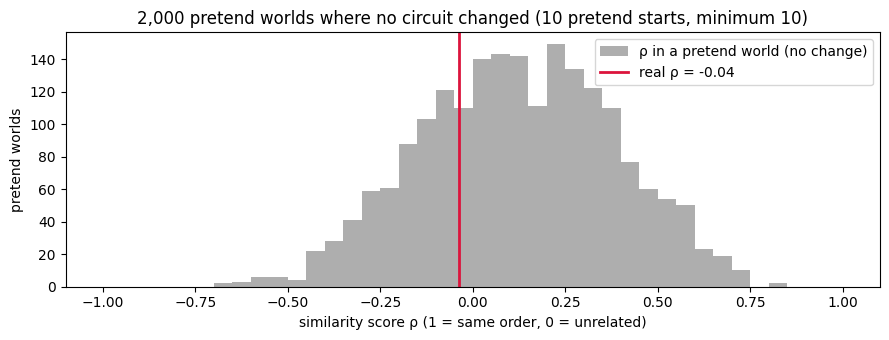

In [207]:
def spearman_rows(a, b):
    """Spearman ρ between matching rows of two (simulations × circuits) arrays."""
    ra, rb = stats.rankdata(a, axis=1), stats.rankdata(b, axis=1)
    ra, rb = ra - ra.mean(axis=1, keepdims=True), rb - rb.mean(axis=1, keepdims=True)
    return (ra * rb).sum(axis=1) / np.sqrt((ra**2).sum(axis=1) * (rb**2).sum(axis=1))

def no_change_rho(ids, k, B=N_RESAMPLES, seed=SEED):
    """Similarity score ρ in B pretend worlds where no circuit changed."""
    rng = np.random.default_rng(seed)
    t = no_change_chances(ids, k)
    sim = {}
    for e in ERAS:
        te = t[t.era == e].set_index("circuitId").loc[ids]
        pods = rng.binomial(te.starts.values, te.chance.values, size=(B, len(ids)))               # the coin flips
        sim[e] = bayes_avg(pods, te.starts.values, te.expected.values, k) - te.expected.values   # scored like the real data
    return spearman_rows(sim[ERA_PRE], sim[ERA_POST])

versions = [(k, MIN_N) for k in K_VALUES] + [(K_MAIN, m) for m in MIN_N_VALUES if m != MIN_N]
luck_rows = []
for k, m in versions:
    ids = compared_ids(m)
    wk = era_compare(k, ids)
    rho = stats.spearmanr(wk[ERA_PRE], wk[ERA_POST])[0]
    null = no_change_rho(ids, k)
    if (k, m) == (K_MAIN, MIN_N):
        null_main = null
    luck_rows.append({"pretend starts": k, "minimum front-row starts": m, "circuits compared": len(ids),
                      "real ρ": rho, "typical ρ in the pretend world": np.median(null),
                      "share of pretend worlds as shuffled as reality": np.mean(null <= rho)})
luck = pd.DataFrame(luck_rows)
table(luck, dec2=["real ρ", "typical ρ in the pretend world"], pct=["share of pretend worlds as shuffled as reality"],
      caption="How often does a world with no change look as shuffled as reality?")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(null_main, bins=np.linspace(-1, 1, 41), color=GREY, alpha=0.7, label="ρ in a pretend world (no change)")
ax.axvline(rho_main, color="crimson", lw=2, label=f"real ρ = {rho_main:.2f}")
ax.set(xlabel="similarity score ρ (1 = same order, 0 = unrelated)", ylabel="pretend worlds",
       title=f"{N_RESAMPLES:,} pretend worlds where no circuit changed ({K_MAIN} pretend starts, minimum {MIN_N})")
ax.legend(); plt.tight_layout(); savefig("q1_05_luck_test"); plt.show()

**How to read the histogram:** the grey bars are the similarity scores of pretend worlds where nothing changed. The red line is reality. If the red line were far to the left of almost all grey bars, luck could not explain the change. If it sits among them, luck can.

#### 3.4 Part 3 answer

In [208]:
main = luck[(luck["pretend starts"] == K_MAIN) & (luck["minimum front-row starts"] == MIN_N)].iloc[0]
share = main["share of pretend worlds as shuffled as reality"]
lo, hi = luck["share of pretend worlds as shuffled as reality"].min(), luck["share of pretend worlds as shuffled as reality"].max()
if share < 0.05:
    verdict = (f"**Yes.** Only {share:.0%} of the pretend worlds where nothing changed are as shuffled as reality, "
               "so luck alone is very unlikely to explain the change.")
else:
    verdict = (f"**On the numbers the ranking changed a lot, but this change could easily happen by luck.** "
               f"In {share:.0%} of the pretend worlds where no circuit changed, the ranking shuffled as much as in "
               f"reality or more (between {lo:.0%} and {hi:.0%} across all our choices). This experiment shows that "
               "the change can be explained by luck; it does not prove that nothing changed. The pretend world is an "
               "assumption we built to compare against, and with about 10 races per circuit and period the data is "
               "simply too small to show a real change.")
md(f"**Part 3 answer ({len(comp_ids)} circuits compared):** {verdict}")

**Part 3 answer (16 circuits compared):** **On the numbers the ranking changed a lot, but this change could easily happen by luck.** In 29% of the pretend worlds where no circuit changed, the ranking shuffled as much as in reality or more (between 17% and 31% across all our choices). This experiment shows that the change can be explained by luck; it does not prove that nothing changed. The pretend world is an assumption we built to compare against, and with about 10 races per circuit and period the data is simply too small to show a real change.

### Summary and limitations

In [209]:
best = {e: ", ".join(f"{c}{' ✓' if cid in robust_ids[e] else ''}" for cid, c in
                     zip(top_group(ct[ct.era == e]).circuitId, top_group(ct[ct.era == e]).circuit)) or "none"
        for e in ERAS}
table(pd.DataFrame([
    {"part": "1. Qualifying or grid?",
     "answer": f"Grid. Drivers pushed back from a front-row qualifying position reached the podium only "
               f"{pushed['podium rate']:.0%} of the time, against {kept['podium rate']:.0%} for those who kept their slot."},
    {"part": f"2. Best circuits {ERA_PRE}", "answer": best[ERA_PRE]},
    {"part": f"2. Best circuits {ERA_POST}", "answer": best[ERA_POST]},
    {"part": "3. Did the ranking change after 2014?",
     "answer": ("Yes, more than luck explains" if share < 0.05 else
                f"It looks very different (ρ = {rho_main:.2f}), but a world with no change looks this shuffled "
                f"{share:.0%} of the time, so it could easily be luck")},
]), caption="Q1 answers (✓ = in the top group under every choice we tried)")

part,answer
1. Qualifying or grid?,"Grid. Drivers pushed back from a front-row qualifying position reached the podium only 31% of the time, against 73% for those who kept their slot."
2. Best circuits 1980–2013,"Circuit de Nevers Magny-Cours ✓, Circuit Paul Ricard ✓, Autódromo Hermanos Rodríguez ✓"
2. Best circuits 2014–2024,"Circuit de Monaco ✓, Suzuka Circuit ✓, Yas Marina Circuit ✓, Circuit de Barcelona-Catalunya, Circuit de Spa-Francorchamps"
3. Did the ranking change after 2014?,"It looks very different (ρ = -0.04), but a world with no change looks this shuffled 29% of the time, so it could easily be luck"


**Limitations:**
- **Teams are mixed into circuit results.** A circuit's rate partly reflects which team held its front row (for example Mercedes 2014–2020, Red Bull 2022–2023). The normal rate removes what was normal in each season, not which team was strong.
- **The periods are unequal:** 34 seasons before 2014 and 11 after, so rates before 2014 are more precise.
- **The two front-row cars are not independent.** Teammates often share the front row, so the error bars and the luck test are slightly too narrow.
- **Layout changes are not separated.** A circuit keeps its `circuitId` when its layout changes (for example Yas Marina in 2021).
- **Sprint weekends (2021–2022)** set the grid with a sprint race. They are included, because the grid is still fixed before the main race.
- **Judgment calls:** the 1980 start (from F1 history, not checkable in Ergast), the 10 pretend starts and the minimum of 10 front-row starts. The last two are tested with other values in 2.5 and 3.3.
- **Descriptive only:** these are associations. Nothing here shows *why* a circuit converts more often.

## Q2: Do drivers podium more often at home, after controlling for starting position?

In plain words: **does racing at home help a driver reach the podium?** For example, does a British driver do better at Silverstone than at other circuits?

A start is a **home start** when the circuit is in the driver's country: Hamilton (British) at Silverstone is at home, Hamilton at Monza is away.

**"After controlling for starting position"** means we only compare drivers who started from the same place on the grid, because where a driver starts decides most of their chance of a podium.

**How we answer it, step by step:**
1. The simple comparison: home vs away podium rate.
2. Why it is misleading: home drivers start further back.
3. Home vs away from the same starting slot.
4. All slots combined into one number.
5. Each driver compared with themselves (the main result).
6. How big a home advantage could still be.
7. Checks with other choices.

**Grain:** one driver entering one race. **Pre-race cutoff:** the starting position and the home flag are both known before the race; the podium is the outcome we count. **Missingness:** drivers who never started have no starting position, so they are left out (1.2); no season, circuit country or nationality is missing (checked in 1.1).

### 0. Setup

Q2 reuses the helper functions from Q1 (`table`, `md`, `savefig`, `wilson`, `pct_range`) and its `LAST_SEASON`, `SEED` and `GREY`.

In [210]:
GRID_BINS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 20, np.inf]          # starting-slot groups (step 3)
GRID_LABELS = ["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "P9", "P10", "P11–12", "P13–15", "P16–20", "P21+"]
SENS_STARTS = [1980, 2000, 2014]   # later first seasons tried in the checks (step 7)
N_BOOT = 1000                      # redraws of drivers for the ranges (also used by Q3)

HOME_COLOR, AWAY_COLOR = "#DD8452", "#4C72B0"
FIG_DIR = os.path.join("report", "figures", "q2")
os.makedirs(FIG_DIR, exist_ok=True)

def or_text(o, lo, hi):
    """Format an odds ratio with its range."""
    return f"{o:.2f} ({lo:.2f} – {hi:.2f})"

def verdict(lo, hi):
    """Plain-language reading of an odds-ratio range."""
    return "home advantage" if lo > 1 else ("home disadvantage" if hi < 1 else "no detectable difference")

### 1. The data

We start from `results_unique` (one row per driver per race) and join the season, the circuit's country and the driver's nationality. From the earlier sections:
- **Drivers who never started** (`never_ran`) are left out: they had no starting position.
- **Pit-lane starters** raced, so they stay, with `grid_clean` placing them at the back of the field.
- **The Indianapolis 500** is left out, as decided in the races section: almost all its drivers never raced another Grand Prix, and it would fill the sample with American "home" starts. Step 7 shows what including it changes.
- **Shared cars (1950–1961):** where two drivers shared one car (one started it, the other took over during the race), both have the same grid slot and result. That result is two drivers' effort, not one driver's, so it cannot tell us how a single driver does at home or away. Both drivers of every shared car are left out.
- **Seasons:** all of 1950–2024, to keep as many home starts as possible. Step 7 checks later first seasons.

In [211]:
q2_base = (results_unique[["resultId", "raceId", "driverId", "constructorId", "grid", "grid_clean", "positionOrder",
                           "never_ran", "is_indy500"]]
           .merge(races[["raceId", "year", "circuitId", "name"]].rename(columns={"name": "race_name"}),
                  on="raceId", how="left", validate="m:1")
           .merge(circuits[["circuitId", "country"]].rename(columns={"country": "circuit_country"}),
                  on="circuitId", how="left", validate="m:1")
           .merge(drivers[["driverId", "forename", "surname", "nationality"]].rename(columns={"nationality": "driver_nationality"}),
                  on="driverId", how="left", validate="m:1"))
q2_base = q2_base[q2_base.year <= LAST_SEASON].copy()
q2_base["podium"] = (q2_base.positionOrder <= 3).astype(int)
q2_base["driver"] = q2_base.forename + " " + q2_base.surname
assert q2_base[["year", "circuit_country", "driver_nationality"]].notna().all().all()

#### 1.1 Which starts are home starts?

Circuits store a **country** (`UK`) and drivers a **nationality** (`British`), so the two cannot be matched directly. The cleaning section (*circuits and drivers: countries and nationalities*) already made the spellings consistent (`United States` → `USA`, `Argentinian ` → `Argentine`) and set the rules used here:
1. **Every nationality is mapped explicitly** to its country; anything without a mapping is shown, not silently dropped.
2. **Two nationalities mean two home countries:** `American-Italian` drivers are at home in the USA and in Italy. This affects only 2 starts, and step 7 shows it changes nothing.
3. **Countries that no longer exist** (`East German`, `Rhodesian`) are never at home.

In [212]:
NATIONALITY_TO_COUNTRY = {
    "American": "USA", "Argentine": "Argentina",
    "Australian": "Australia", "Austrian": "Austria", "Belgian": "Belgium",
    "Brazilian": "Brazil", "British": "UK", "Canadian": "Canada", "Chilean": "Chile", "Chinese": "China",
    "Colombian": "Colombia", "Czech": "Czech Republic", "Danish": "Denmark", "Dutch": "Netherlands",
    "Finnish": "Finland", "French": "France", "German": "Germany",
    "Hungarian": "Hungary", "Indian": "India", "Indonesian": "Indonesia",
    "Irish": "Ireland", "Italian": "Italy", "Japanese": "Japan", "Liechtensteiner": "Liechtenstein",
    "Malaysian": "Malaysia", "Mexican": "Mexico", "Monegasque": "Monaco",
    "New Zealander": "New Zealand", "Polish": "Poland", "Portuguese": "Portugal", "Russian": "Russia", "South African": "South Africa", "Spanish": "Spain", "Swedish": "Sweden",
    "Swiss": "Switzerland", "Thai": "Thailand", "Uruguayan": "Uruguay", "Venezuelan": "Venezuela",
}
DUAL_HOME = {"American-Italian": ["USA", "Italy"], "Argentine-Italian": ["Argentina", "Italy"]}   # rule 2
NOT_HOME = ["East German", "Rhodesian"]                                                          # rule 3

present = set(q2_base.driver_nationality)
unmapped = sorted(present - set(NATIONALITY_TO_COUNTRY) - set(DUAL_HOME) - set(NOT_HOME))
home_countries = set(NATIONALITY_TO_COUNTRY.values()) | {c for cs in DUAL_HOME.values() for c in cs}
table(pd.DataFrame([
    {"check": "missing values in season, circuit country and nationality (should be 0)",
     "result": str(q2_base[["year", "circuit_country", "driver_nationality"]].isna().sum().sum())},
    {"check": "nationalities without a mapping (should be none)", "result": ", ".join(unmapped) or "none"},
    {"check": "two nationalities, at home in both countries", "result": ", ".join(n for n in DUAL_HOME if n in present) or "none"},
    {"check": "countries that no longer exist, never at home", "result": ", ".join(n for n in NOT_HOME if n in present) or "none"},
    {"check": "host countries with no driver of that nationality (no home race possible)",
     "result": ", ".join(sorted(set(q2_base.circuit_country) - home_countries)) or "none"},
]), caption="Nationality-to-country map: checks")

single = q2_base.driver_nationality.map(NATIONALITY_TO_COUNTRY) == q2_base.circuit_country
dual = [isinstance(h, list) and c in h for h, c in zip(q2_base.driver_nationality.map(DUAL_HOME), q2_base.circuit_country)]
q2_base["home"] = (single | np.array(dual)).astype(int)    # the home flag used everywhere in Q2
q2_base["home_without_dual"] = single.astype(int)          # rule 2 switched off: only for the check in step 7

check,result
"missing values in season, circuit country and nationality (should be 0)",0
nationalities without a mapping (should be none),none
"two nationalities, at home in both countries","American-Italian, Argentine-Italian"
"countries that no longer exist, never at home","East German, Rhodesian"
host countries with no driver of that nationality (no home race possible),"Azerbaijan, Bahrain, Korea, Morocco, Qatar, Saudi Arabia, Singapore, Turkey, UAE"


#### 1.2 The sample

In [213]:
SHARED_CAR = ["raceId", "positionOrder", "constructorId"]   # one car's finishing place in one race

def shared_car_rows(d):
    """Index of every driver of a shared car: two or more drivers credited with one car's finishing place."""
    return d.index[d.duplicated(SHARED_CAR, keep=False)]

def q2_frame(df, include_indy=False, year_from=None):
    """The Q2 sample: drivers who started, Indy 500 optional, optional later first season, no shared cars."""
    d = df[~df.never_ran]
    if not include_indy:
        d = d[~d.is_indy500]
    if year_from:
        d = d[d.year >= year_from]
    d = d.drop(index=shared_car_rows(d)).copy()              # both drivers of every shared car
    d["grid"] = d.grid_clean                                     # pit-lane starters at the back of the field
    d["grid_slot"] = pd.cut(d.grid, GRID_BINS, labels=GRID_LABELS)
    d["decade"] = (d.year // 10 * 10).astype(int)
    return d

q2 = q2_frame(q2_base)
steps = [("all driver–race entries 1950–2024", q2_base),
         ("minus drivers who never started", q2_base[~q2_base.never_ran]),
         ("minus the Indianapolis 500", q2_base[~q2_base.never_ran & ~q2_base.is_indy500]),
         ("minus both drivers of every shared car (the Q2 sample)", q2)]
table(pd.DataFrame([{"step": s, "starts": len(d), "home starts": int(d.home.sum()),
                     "share at home": d.home.mean()} for s, d in steps]),
      pct=["share at home"], caption="Building the Q2 sample")

step,starts,home starts,share at home
all driver–race entries 1950–2024,26668,2488,9%
minus drivers who never started,24958,2305,9%
minus the Indianapolis 500,24577,1925,8%
minus both drivers of every shared car (the Q2 sample),24448,1887,8%


### Step 1: The simple comparison

In [214]:
raw_cmp = (q2.groupby("home").agg(starts=("podium", "size"), podiums=("podium", "sum"),
                                  **{"average starting slot": ("grid", "mean")})
             .rename(index={0: "away", 1: "home"}).reset_index().rename(columns={"home": "where"}))
raw_cmp["podium rate"] = raw_cmp.podiums / raw_cmp.starts
table(raw_cmp, pct1=["podium rate"], dec1=["average starting slot"], caption="Home vs away, no control")
raw_home, raw_away = raw_cmp.set_index("where").loc["home"], raw_cmp.set_index("where").loc["away"]
md(f"""**Reading:** home drivers reach the podium **{'less' if raw_home['podium rate'] < raw_away['podium rate'] else 'more'}**
often ({raw_home['podium rate']:.1%} vs {raw_away['podium rate']:.1%}). But they also start further back on average
(slot {raw_home['average starting slot']:.1f} vs {raw_away['average starting slot']:.1f}). Step 2 shows why that matters.""")

where,starts,podiums,average starting slot,podium rate
away,22561,3106,11.7,13.8%
home,1887,220,12.7,11.7%


**Reading:** home drivers reach the podium **less**
often (11.7% vs 13.8%). But they also start further back on average
(slot 12.7 vs 11.7). Step 2 shows why that matters.

### Step 2: Why the simple comparison is misleading

**Left:** the podium rate from each starting slot, for all drivers. **Right:** where home and away drivers start.

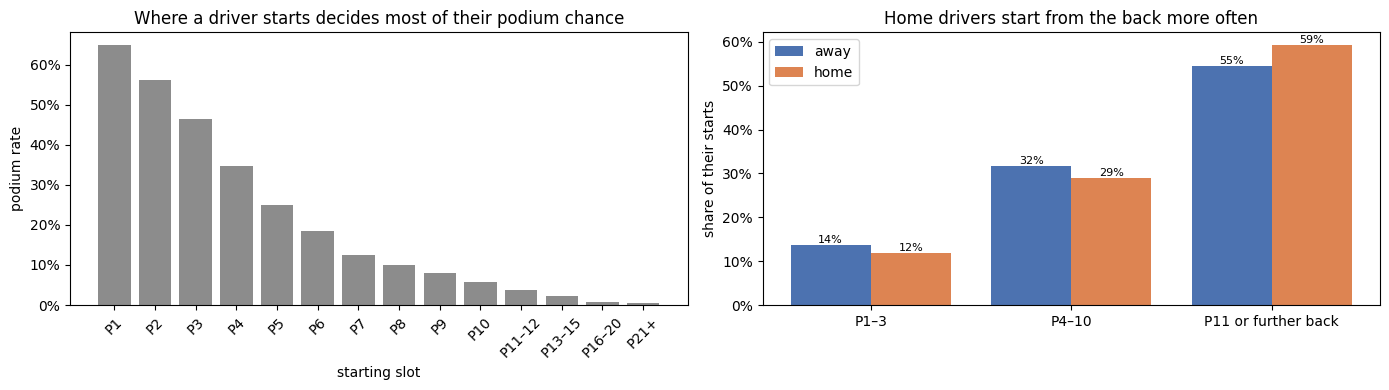

**Reading:** a P1 starter reaches the podium 65% of the time, a P10 starter 6%.
Home drivers start from P1–3 in 12% of their starts, away drivers in 14%, and
home drivers start from P11 or further back more often. So the simple comparison mixes **being at home** with
**starting further back**. One reason: in the early decades many local drivers in slow cars entered only their home
Grand Prix. To be fair, we only compare drivers who started from the same place.

In [215]:
BANDS = ["P1–3", "P4–10", "P11 or further back"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

rate_by_slot = q2.groupby("grid_slot", observed=True).podium.mean().reindex(GRID_LABELS)
axes[0].bar(GRID_LABELS, rate_by_slot.values, color=GREY)
axes[0].set(title="Where a driver starts decides most of their podium chance", xlabel="starting slot",
            ylabel="podium rate")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].tick_params(axis="x", rotation=45)

bands = pd.cut(q2.grid, [0, 3, 10, np.inf], labels=BANDS)
share = pd.crosstab(q2.home, bands, normalize="index").rename(index={0: "away", 1: "home"})
x = np.arange(len(BANDS))
for off, where, col in [(-0.2, "away", AWAY_COLOR), (0.2, "home", HOME_COLOR)]:
    bars = axes[1].bar(x + off, share.loc[where].values, width=0.4, color=col, label=where)
    axes[1].bar_label(bars, labels=[f"{v:.0%}" for v in share.loc[where].values], fontsize=8)
axes[1].set_xticks(x); axes[1].set_xticklabels(BANDS)
axes[1].set(title="Home drivers start from the back more often", ylabel="share of their starts")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend()
plt.tight_layout(); savefig("q2_01_why_control"); plt.show()

md(f"""**Reading:** a P1 starter reaches the podium {rate_by_slot['P1']:.0%} of the time, a P10 starter {rate_by_slot['P10']:.0%}.
Home drivers start from P1–3 in {share.loc['home', 'P1–3']:.0%} of their starts, away drivers in {share.loc['away', 'P1–3']:.0%}, and
home drivers start from P11 or further back more often. So the simple comparison mixes **being at home** with
**starting further back**. One reason: in the early decades many local drivers in slow cars entered only their home
Grand Prix. To be fair, we only compare drivers who started from the same place.""")

### Step 3: Home vs away from the same starting slot

For each starting slot, the podium rate of home starters and of away starters. Slots behind P10 are grouped, because podiums from there are very rare. The error bar is the range the true rate is probably in (95% Wilson range): wide when there are few starts.

starting slot,away starts,away podium rate,home starts,home podium rate,better
P1,1022,65%,79,61%,away
P2,1030,56%,75,56%,same
P3,1036,46%,70,53%,home
P4,1039,35%,71,38%,home
P5,1031,24%,70,33%,home
P6,1021,19%,79,11%,away
P7,1026,12%,75,13%,home
P8,1023,10%,76,7%,away
P9,1015,8%,94,9%,home
P10,1012,6%,81,0%,away


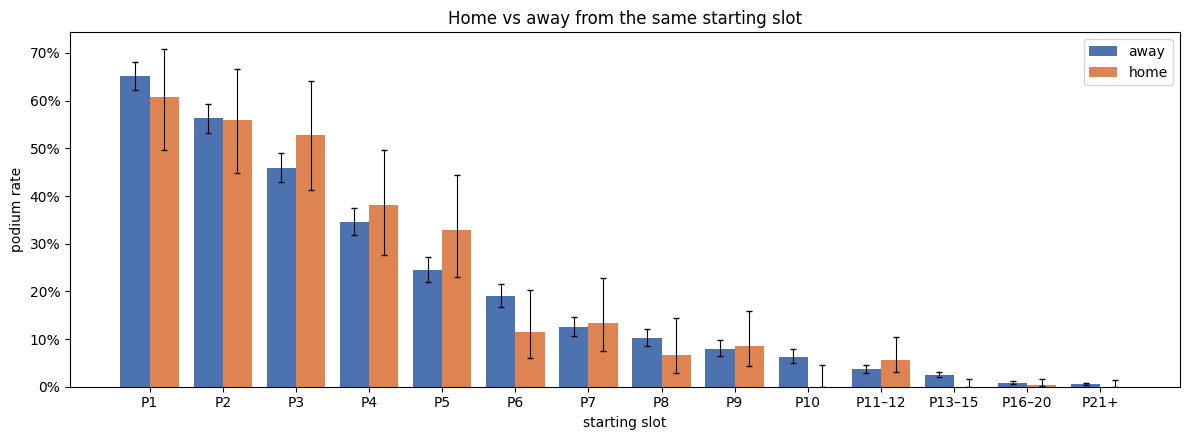

**Reading:** in P1–P10, home is better in 5 slots, away in 4
and they are equal in 1. There is no clear pattern: if being at home helped, home would be better
in almost every slot. Each slot also has only about 75 home starts, so the home bars move a
lot by luck (wide error bars). Step 4 combines all slots into one number.

In [216]:
strat = (q2.groupby(["grid_slot", "home"], observed=True)
           .agg(n=("podium", "size"), podiums=("podium", "sum")).reset_index())
strat["rate"] = strat.podiums / strat.n
strat["ci_lo"], strat["ci_hi"] = wilson(strat.podiums, strat.n)
home_s = strat[strat.home == 1].set_index("grid_slot").reindex(GRID_LABELS)
away_s = strat[strat.home == 0].set_index("grid_slot").reindex(GRID_LABELS)

slot_table = pd.DataFrame({"starting slot": GRID_LABELS,
                           "away starts": away_s.n.astype(int).values, "away podium rate": away_s.rate.values,
                           "home starts": home_s.n.astype(int).values, "home podium rate": home_s.rate.values})
home_pct, away_pct = (slot_table["home podium rate"] * 100).round(), (slot_table["away podium rate"] * 100).round()
slot_table["better"] = np.select([home_pct > away_pct, home_pct < away_pct], ["home", "away"], default="same")   # whole percent
table(slot_table.head(10), pct=["away podium rate", "home podium rate"], caption="Home vs away from the same slot (P1–P10)")

fig, ax = plt.subplots(figsize=(12, 4.5))
xs = np.arange(len(GRID_LABELS))
for off, s, col, lab in [(-0.2, away_s, AWAY_COLOR, "away"), (0.2, home_s, HOME_COLOR, "home")]:
    ax.bar(xs + off, s.rate, width=0.4, color=col, label=lab,
           yerr=[s.rate - s.ci_lo, s.ci_hi - s.rate], capsize=2, error_kw={"lw": 0.8})
ax.set_xticks(xs); ax.set_xticklabels(GRID_LABELS)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(ylabel="podium rate", xlabel="starting slot", title="Home vs away from the same starting slot")
ax.legend(); plt.tight_layout(); savefig("q2_02_by_slot"); plt.show()

top10 = slot_table.head(10)
md(f"""**Reading:** in P1–P10, home is better in {(top10.better == 'home').sum()} slots, away in {(top10.better == 'away').sum()}
and they are equal in {(top10.better == 'same').sum()}. There is no clear pattern: if being at home helped, home would be better
in almost every slot. Each slot also has only about {int(top10['home starts'].median())} home starts, so the home bars move a
lot by luck (wide error bars). Step 4 combines all slots into one number.""")

### Step 4: All slots combined into one number

**How:**
1. Split all starts into groups of the **same starting slot in the same decade**, for example "P3 starters in the 1990s". The decade matters for the same reason as in Q1: in the 1950s cars broke down constantly and a P8 starter often reached the podium by surviving, which rarely happens today.
2. **Inside each group**, compare home with away.
3. **Combine all groups into one number.** Bigger groups count more, and groups where nobody (or everybody) reached the podium carry no information. This standard method is called Mantel–Haenszel.

**The number is an odds ratio:**
- **1** = home and away are the same;
- **above 1** = home is better (1.20 means about 20% better odds of a podium);
- **below 1** = home is worse.

**Its range:** the same driver appears in many starts, with the same skill and often the same car, so their starts are not independent. The range is therefore found by redrawing whole drivers 1,000 times (each time some drivers are drawn twice and some not at all) and keeping the middle 95% of the results. **If the range includes 1, the data cannot tell home and away apart.**

In [217]:
def stratum_counts(d, strata):
    """The four counts for every group: a = home podium, b = home no podium, c = away podium, dd = away no podium."""
    t = d.assign(a=d.home * d.podium, b=d.home * (1 - d.podium),
                 c=(1 - d.home) * d.podium, dd=(1 - d.home) * (1 - d.podium))
    return t.groupby(strata, observed=True)[["a", "b", "c", "dd"]].sum().reset_index()

def mh_or(a, b, c, d):
    """Mantel–Haenszel odds ratio over the last axis (works for one table or many redraws at once)."""
    a, b, c, d = (np.asarray(x, dtype=float) for x in (a, b, c, d))
    n = a + b + c + d
    n = np.where(n == 0, np.nan, n)
    with np.errstate(divide="ignore", invalid="ignore"):     # a redraw with no informative group gives inf/nan
        return np.nansum(a * d / n, axis=-1) / np.nansum(b * c / n, axis=-1)

def driver_resample_range(d, strata, B=N_BOOT, seed=SEED):
    """95% range of the odds ratio when whole drivers (with all their starts) are redrawn B times."""
    rng = np.random.default_rng(seed)
    cnt = stratum_counts(d, ["driverId"] + [s for s in strata if s != "driverId"])   # counts per driver and group
    cnt["group"] = cnt.groupby(strata, observed=True).ngroup()
    ids = pd.Index(cnt.driverId.unique())
    rows, cols = ids.get_indexer(cnt.driverId), cnt.group.values
    mats = []
    for x in ["a", "b", "c", "dd"]:                           # drivers × groups matrix for each count
        m = np.zeros((len(ids), cols.max() + 1))
        np.add.at(m, (rows, cols), cnt[x].values)
        mats.append(m)
    draws = rng.multinomial(len(ids), np.full(len(ids), 1 / len(ids)), size=B)   # times each driver is drawn
    sims = mh_or(*(draws @ m for m in mats))
    return np.nanpercentile(sims, [2.5, 97.5])

def informative_home_starts(cnt):
    """Home starts in groups that have a home and an away start and at least one podium and one non-podium."""
    keep = (cnt.a + cnt.b > 0) & (cnt.c + cnt.dd > 0) & (cnt.a + cnt.c > 0) & (cnt.b + cnt.dd > 0)
    return int((cnt.a + cnt.b)[keep].sum())

def home_effect(d, strata, B=N_BOOT, seed=SEED):
    """Odds ratio, its range (drivers redrawn) and the home starts that carry information."""
    cnt = stratum_counts(d, strata)
    lo, hi = driver_resample_range(d, strata, B=B, seed=seed)
    return {"or": float(mh_or(cnt.a, cnt.b, cnt.c, cnt.dd)), "lo": lo, "hi": hi, "home used": informative_home_starts(cnt)}

between = home_effect(q2, ["grid_slot", "decade"])
md(f"""**Result:** home vs away, same slot and decade: odds ratio **{between['or']:.2f}**, range {between['lo']:.2f} to {between['hi']:.2f}.
The range includes 1, so: **{verdict(between['lo'], between['hi'])}**.""")

**Result:** home vs away, same slot and decade: odds ratio **0.92**, range 0.73 to 1.13.
The range includes 1, so: **no detectable difference**.

### Step 5: Each driver compared with themselves (the main result)

**The hidden unfairness in step 4:** even inside "P3 starters in the 1990s", the home group and the away group can be **different kinds of drivers**. In the early decades many home starts came from local drivers who entered only their home Grand Prix, often in old cars. The table shows how many.

In [218]:
per_driver = (q2.groupby(["driverId", "driver", "driver_nationality", "home"])
                .agg(starts=("podium", "size"), rate=("podium", "mean"), grid=("grid", "mean"))
                .unstack("home"))
per_driver.columns = [f"{a}_{'home' if b else 'away'}" for a, b in per_driver.columns]
per_driver = per_driver.reset_index().fillna({"starts_home": 0, "starts_away": 0})
per_driver["type"] = np.select([(per_driver.starts_home > 0) & (per_driver.starts_away > 0), per_driver.starts_home > 0],
                               ["raced at home and away", "only ever raced at home"], default="never raced at home")
who = (q2.merge(per_driver[["driverId", "type"]], on="driverId")
         .groupby("type").agg(drivers=("driverId", "nunique"), starts=("podium", "size"),
                              **{"home starts": ("home", "sum"), "podium rate": ("podium", "mean"),
                                 "average starting slot": ("grid", "mean")})
         .reindex(["raced at home and away", "only ever raced at home", "never raced at home"], fill_value=0)
         .rename_axis("type").reset_index())
table(who, pct1=["podium rate"], dec1=["average starting slot"], caption="Three kinds of drivers")
only_home = who.set_index("type").loc["only ever raced at home"]
md(f"""**Reading:** **{int(only_home['home starts']):,}** home starts ({only_home['home starts'] / q2.home.sum():.0%} of all home starts)
come from drivers who **never raced anywhere else**. They reached the podium {only_home['podium rate']:.1%} of the time and
started on average from slot {only_home['average starting slot']:.0f}.""")

type,drivers,starts,home starts,podium rate,average starting slot
raced at home and away,388,20172,1743,14.3%,11.5
only ever raced at home,106,144,144,0.0%,19.0
never raced at home,183,4132,0,10.9%,12.8


**Reading:** **144** home starts (8% of all home starts)
come from drivers who **never raced anywhere else**. They reached the podium 0.0% of the time and
started on average from slot 19.

**The fix:** compare **each driver with themselves**: their home starts against their own away starts, from the **same slot in the same decade**. For example, *Alonso starting P3 in Spain* against *Alonso starting P3 elsewhere*. Same driver, so the only difference is home or away. Drivers who only raced at home drop out automatically, because they have nothing to compare with.

It is the same calculation as step 4, but a group is now **one driver, from one slot, in one decade**. The table shows the drivers with the most home starts (raw numbers, not yet matched by slot): some do better at home, some worse.

In [219]:
top = per_driver.sort_values("starts_home", ascending=False).head(10)
table(pd.DataFrame({"driver": top.driver, "nationality": top.driver_nationality,
                    "home starts": top.starts_home.astype(int), "home podium rate": top.rate_home,
                    "away starts": top.starts_away.astype(int), "away podium rate": top.rate_away}),
      pct=["home podium rate", "away podium rate"], caption="Drivers with the most home starts (raw)")

WITHIN = ["driverId", "grid_slot", "decade"]     # main: same driver, same slot, same decade
within = home_effect(q2, WITHIN)

effects = pd.DataFrame([
    {"comparison": "Step 4: home vs other drivers, same slot and decade", "home starts used": between["home used"],
     "odds ratio": between["or"], "lo": between["lo"], "hi": between["hi"]},
    {"comparison": "Step 5: each driver vs themselves, same slot and decade (MAIN)", "home starts used": within["home used"],
     "odds ratio": within["or"], "lo": within["lo"], "hi": within["hi"]}])
table(effects.assign(**{"range": [f"{l:.2f} – {h:.2f}" for l, h in zip(effects.lo, effects.hi)],
                        "verdict": [verdict(l, h) for l, h in zip(effects.lo, effects.hi)]}).drop(columns=["lo", "hi"]),
      dec2=["odds ratio"], caption="Home effect on podium odds")

driver,nationality,home starts,home podium rate,away starts,away podium rate
Riccardo Patrese,Italian,29,14%,227,15%
Michael Schumacher,German,28,54%,279,50%
Andrea de Cesaris,Italian,27,0%,181,3%
Fernando Alonso,Spanish,26,35%,376,26%
Giancarlo Fisichella,Italian,24,4%,205,9%
Jarno Trulli,Italian,24,0%,228,5%
Michele Alboreto,Italian,23,17%,171,11%
Ralf Schumacher,German,20,15%,160,15%
Mario Andretti,American,19,16%,109,15%
Rubens Barrichello,Brazilian,19,5%,303,22%


comparison,home starts used,odds ratio,range,verdict
"Step 4: home vs other drivers, same slot and decade",1727,0.92,0.73 – 1.13,no detectable difference
"Step 5: each driver vs themselves, same slot and decade (MAIN)",558,1.00,0.77 – 1.27,no detectable difference


**How to read the figure:** the dot is the best guess, the line is the range, and the red line is **1 = no difference**. A line that crosses the red line means the data cannot tell home and away apart. Right of the red line would be a home advantage, left a home disadvantage.

"Home starts used" counts only the home starts that carry information: those in a group with a matching away start and at least one podium and one non-podium. Starts from the back of the grid (almost never a podium) drop out.

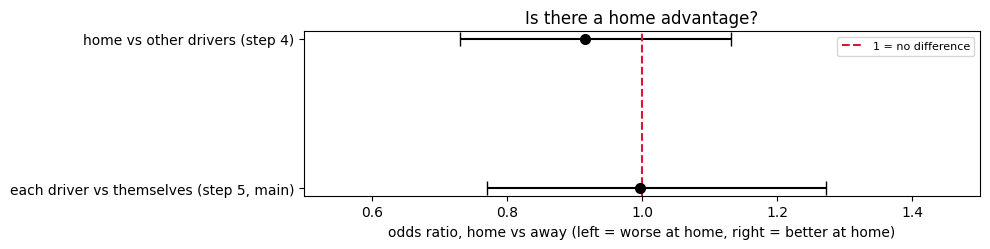

**Reading:** compared with themselves, drivers reach the podium about as often at home as away: odds ratio
**1.00**, range 0.77 to 1.27. The range includes 1: **no detectable difference**.

In [220]:
fig, ax = plt.subplots(figsize=(10, 2.6))
y = np.arange(len(effects))[::-1]
ax.errorbar(effects["odds ratio"], y, xerr=[effects["odds ratio"] - effects.lo, effects.hi - effects["odds ratio"]],
            fmt="o", color="black", capsize=5, ms=7)
ax.axvline(1, color="crimson", ls="--", lw=1.5, label="1 = no difference")
ax.set_yticks(y); ax.set_yticklabels(["home vs other drivers (step 4)", "each driver vs themselves (step 5, main)"])
ax.set(xlim=(0.5, 1.5), xlabel="odds ratio, home vs away (left = worse at home, right = better at home)",
       title="Is there a home advantage?")
ax.legend(loc="upper right", fontsize=8); plt.tight_layout(); savefig("q2_03_home_effect"); plt.show()
md(f"""**Reading:** compared with themselves, drivers reach the podium about as often at home as away: odds ratio
**{within['or']:.2f}**, range {within['lo']:.2f} to {within['hi']:.2f}. The range includes 1: **{verdict(within['lo'], within['hi'])}**.""")

### Step 6: How big could a home advantage still be?

The best guess is "no difference", but the range goes up to its top value, the **largest home advantage the data still allows**. The table turns that value into podium chances: for a driver whose away podium chance from a slot is X%, what would it be at home?

In [221]:
def apply_or(p, o):
    """Podium chance after multiplying the odds of chance p by odds ratio o."""
    odds = p / (1 - p) * o
    return odds / (1 + odds)

away_rate = q2[q2.home == 0].groupby("grid_slot", observed=True).podium.mean()
show_slots = ["P1", "P2", "P3", "P5", "P8"]
rule = pd.DataFrame({"starting slot": show_slots, "away podium chance": away_rate.reindex(show_slots).values})
rule["home, best guess"] = apply_or(rule["away podium chance"], within["or"])
rule["home, largest advantage still possible"] = apply_or(rule["away podium chance"], within["hi"])
rule["largest possible gain (points)"] = (rule["home, largest advantage still possible"] - rule["away podium chance"]) * 100
table(rule, pct=["away podium chance", "home, best guess", "home, largest advantage still possible"],
      dec1=["largest possible gain (points)"], caption="What the main result means in podium chances")

best = rule.loc[rule["largest possible gain (points)"].idxmax()]
md(f"""**Reading:** even if there is a home advantage, it is **small**. In the most generous case the data allows, a
{best['starting slot']} starter would go from {best['away podium chance']:.0%} away to
{best['home, largest advantage still possible']:.0%} at home: at most about **{best['largest possible gain (points)']:.0f} percentage points**.
A large home advantage is ruled out.""")

starting slot,away podium chance,"home, best guess","home, largest advantage still possible",largest possible gain (points)
P1,65%,65%,70%,5.2
P2,56%,56%,62%,5.8
P3,46%,46%,52%,6.0
P5,24%,24%,29%,4.7
P8,10%,10%,13%,2.4


**Reading:** even if there is a home advantage, it is **small**. In the most generous case the data allows, a
P3 starter would go from 46% away to
52% at home: at most about **6 percentage points**.
A large home advantage is ruled out.

### Step 7: Checks with other choices

We repeat the main comparison (each driver vs themselves) with other choices:
- **including the Indianapolis 500**;
- **starting in 1980, 2000 or 2014** instead of 1950;
- **any decade:** the same driver and slot at any point in their career (requiring the same decade can split a career, for example 2008 and 2011);
- **two nationalities never at home:** rule 2 switched off.

The more versions we check, the more likely one of them looks unusual by chance, so a single different version is a hint, not a finding.

version,home starts,odds ratio (range),verdict
main (1950–2024),1887,1.00 (0.77 – 1.27),no detectable difference
including the Indianapolis 500,2212,1.00 (0.78 – 1.26),no detectable difference
from 1980,1043,0.96 (0.70 – 1.32),no detectable difference
from 2000,434,0.71 (0.33 – 1.19),no detectable difference
from 2014,144,0.90 (0.29 – 2.38),no detectable difference
any decade (same driver and slot),1887,1.00 (0.77 – 1.29),no detectable difference
two nationalities never at home,1885,1.00 (0.77 – 1.27),no detectable difference


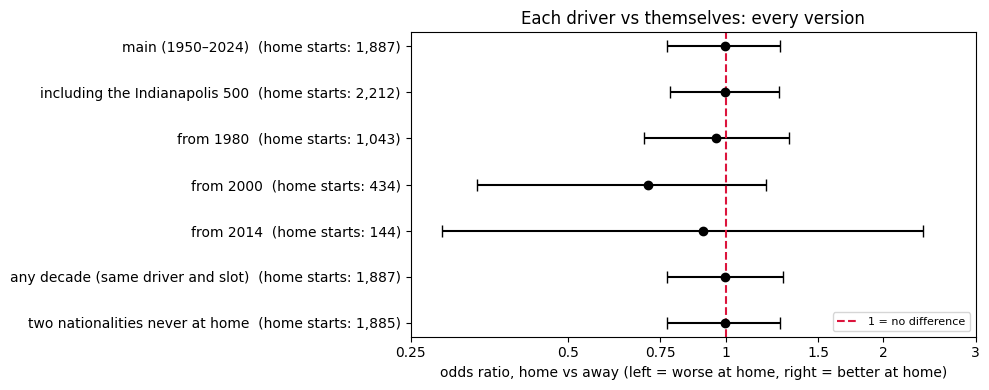

**Reading:** **no detectable difference** in 7 of 7 versions. With fewer seasons there are fewer home starts, so the ranges get wider, but every range still includes 1.

In [222]:
versions = {"main (1950–2024)": (q2, WITHIN),
            "including the Indianapolis 500": (q2_frame(q2_base, include_indy=True), WITHIN)}
for y in SENS_STARTS:
    versions[f"from {y}"] = (q2_frame(q2_base, year_from=y), WITHIN)
versions["any decade (same driver and slot)"] = (q2, ["driverId", "grid_slot"])
versions["two nationalities never at home"] = (q2.assign(home=q2.home_without_dual), WITHIN)

sens = pd.DataFrame([{"version": name, "home starts": int(d.home.sum()), **home_effect(d, strata)}
                     for name, (d, strata) in versions.items()])
sens["verdict"] = [verdict(l, h) for l, h in zip(sens.lo, sens.hi)]
table(pd.DataFrame({"version": sens.version, "home starts": sens["home starts"],
                    "odds ratio (range)": [or_text(o, l, h) for o, l, h in zip(sens["or"], sens.lo, sens.hi)],
                    "verdict": sens.verdict}), caption="Each driver vs themselves under every version")

fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(sens))[::-1]
ax.errorbar(sens["or"], y, xerr=[sens["or"] - sens.lo.clip(lower=0.2), sens.hi.clip(upper=3) - sens["or"]],
            fmt="o", color="black", capsize=4)
ax.axvline(1, color="crimson", ls="--", lw=1.5, label="1 = no difference")
ax.set_yticks(y); ax.set_yticklabels([f"{v}  (home starts: {n:,})" for v, n in zip(sens.version, sens["home starts"])])
ax.set_xscale("log")
ticks = [0.25, 0.5, 0.75, 1, 1.5, 2, 3]
ax.set_xticks(ticks); ax.set_xticklabels([f"{t:g}" for t in ticks]); ax.minorticks_off()
ax.set(xlabel="odds ratio, home vs away (left = worse at home, right = better at home)",
       title="Each driver vs themselves: every version")
ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); savefig("q2_04_checks"); plt.show()

counts = sens.verdict.value_counts()
md("**Reading:** " + ", ".join(f"**{v}** in {n} of {len(sens)} versions" for v, n in counts.items()) +
   ". With fewer seasons there are fewer home starts, so the ranges get wider, but every range still includes 1.")

### Answer and limitations

In [223]:
table(pd.DataFrame([
    {"step": "1. Simple comparison (no control)",
     "result": f"home {raw_home['podium rate']:.1%} vs away {raw_away['podium rate']:.1%}",
     "meaning": "misleading: home drivers start further back"},
    {"step": "4. Home vs other drivers, same slot and decade",
     "result": f"odds ratio {or_text(between['or'], between['lo'], between['hi'])}", "meaning": verdict(between["lo"], between["hi"])},
    {"step": "5. Each driver vs themselves (main)",
     "result": f"odds ratio {or_text(within['or'], within['lo'], within['hi'])}", "meaning": verdict(within["lo"], within["hi"])},
    {"step": "6. Largest home advantage still possible",
     "result": f"about {best['largest possible gain (points)']:.0f} points for a {best['starting slot']} starter", "meaning": "a large advantage is ruled out"},
    {"step": "7. Checks", "result": f"{int((sens.verdict == verdict(within['lo'], within['hi'])).sum())} of {len(sens)} versions agree",
     "meaning": "the answer does not depend on our choices"},
]), caption="Q2: from the simple comparison to the answer")

main_verdict = verdict(within["lo"], within["hi"])
if main_verdict == "no detectable difference":
    answer = (f"**No detectable home advantage.** Compared with themselves, from the same starting slot in the same decade, "
              f"drivers reach the podium about as often at home as elsewhere (odds ratio {or_text(within['or'], within['lo'], within['hi'])}). "
              f"Even if there is a home advantage, it is small: at most about {best['largest possible gain (points)']:.0f} "
              f"percentage points of podium chance for a {best['starting slot']} starter.")
else:
    answer = (f"**A {main_verdict}.** Compared with themselves, from the same starting slot in the same decade, drivers' podium "
              f"odds at home are {or_text(within['or'], within['lo'], within['hi'])} times their odds elsewhere.")
md("**Q2 answer:** " + answer)

step,result,meaning
1. Simple comparison (no control),home 11.7% vs away 13.8%,misleading: home drivers start further back
"4. Home vs other drivers, same slot and decade",odds ratio 0.92 (0.73 – 1.13),no detectable difference
5. Each driver vs themselves (main),odds ratio 1.00 (0.77 – 1.27),no detectable difference
6. Largest home advantage still possible,about 6 points for a P3 starter,a large advantage is ruled out
7. Checks,7 of 7 versions agree,the answer does not depend on our choices


**Q2 answer:** **No detectable home advantage.** Compared with themselves, from the same starting slot in the same decade, drivers reach the podium about as often at home as elsewhere (odds ratio 1.00 (0.77 – 1.27)). Even if there is a home advantage, it is small: at most about 6 percentage points of podium chance for a P3 starter.

**Limitations:**
- **Nationality stands in for "home".** Ergast stores one nationality per driver, so a driver who grew up in another country is mapped to their nationality's country.
- **Several Grands Prix share a country.** All of them count as home (for example Monza and Imola for Italians), although a driver may feel at home at only one.
- **A home advantage could work through qualifying.** The question asks about podiums *after* controlling for the starting slot, so any advantage that shows up as a better grid slot at home is deliberately not counted.
- **The evidence comes mostly from the top 10.** Podiums from P11 and further back are so rare that those starts carry almost no information.
- **Comparing each driver with themselves uses fewer starts:** only home starts with a matching away start by the same driver, slot and decade count. This is the price of a fairer comparison.
- **Shared cars (1950–1961) are left out:** their result is two drivers' effort, not one driver's. This removes 129 starts from 1950–1961.
- **Descriptive only:** these are associations, not causes.

## Q3: Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

In plain words: **which teams' cars broke down most often**, in two periods: **2014–2021** (the first hybrid-engine period) and **2022–2024** (after the 2022 rule change).

- **Constructor** = the team, as entered in the data (Ferrari, Mercedes, Toro Rosso, ...).
- **Mechanical retirement** = a race **start** that ended early because **a part of the car failed**. Following the brief, it does not include crashes, driver causes (for example illness) or decisions by the stewards.

**How we answer it, step by step:**
1. Which race endings count as a mechanical failure.
2. The rate: mechanical retirements ÷ starts.
3. The ranking per period (Part A), made fair in the same two ways as Q1.
4. Extra context: did cars become more reliable, and was it because of the 2022 rules? (Part B)
5. Extra context: did the same team break down less after 2022? (Part C)

**Grain:** one car (one driver) entering one race, 2014–2024. **Timing:** the reason a race ended is only known after the race, so it is never a model input; here it is the answer to a descriptive question. **Missingness:** no season, status, status group or constructor is missing (checked in 1); cars that never started are not counted as starts (step 1).

### 0. Setup

Q3 reuses the helpers from Q1 (`table`, `md`, `savefig`, `wilson`, `bayes_avg`, `pct_range`) and `N_BOOT` from Q2.

In [224]:
FIRST_SEASON, SPLIT = 2014, 2022    # the two periods: 2014–2021 and 2022–2024
K_VALUES = [10, 20, 40]             # pretend starts: a quarter, half and one season of a two-car team
K_MAIN = 20
MIN_STARTS = 20                     # a team needs this many starts in a period to be ranked (about half a season)
MIN_STARTS_VALUES = [10, 20, 40]
TOP = 3                             # size of the top group
LATE_PRE = 2019                     # 2019–2021: the three seasons just before the 2022 rules (Part B)

P1, P2 = f"{FIRST_SEASON}–{SPLIT - 1}", f"{SPLIT}–{LAST_SEASON}"
PERIODS = [P1, P2]
P_COLORS = {P1: "#C44E52", P2: "#DD8452"}
FIG_DIR = os.path.join("report", "figures", "q3")
os.makedirs(FIG_DIR, exist_ok=True)

### 1. The data

Q3 starts from `results_unique` for 2014–2024 and joins the season, the status with its group, the constructor and the driver's surname. From the earlier sections:
- **Shared drives and the Indianapolis 500** end long before 2014, so they do not touch Q3.
- **Status groups:** every status label already sits in one of eight groups (status section, *grouping the labels for the mechanical-retirement question*). Q3 uses them as they are.
- **Constructors:** Q3 joins on `constructorId`. Inside 2014–2024 each id is one continuous entry; renamed teams have separate ids, which Part C handles.

In [225]:
q3_base = (results_unique[["raceId", "driverId", "constructorId", "statusId", "never_ran"]]
           .merge(races[["raceId", "year", "name"]].rename(columns={"name": "race_name"}), on="raceId", how="left", validate="m:1")
           .merge(status[["statusId", "status", "group"]], on="statusId", how="left", validate="m:1")
           .merge(constructors[["constructorId", "constructorRef", "name"]].rename(columns={"name": "constructor"}),
                  on="constructorId", how="left", validate="m:1")
           .merge(drivers[["driverId", "surname"]], on="driverId", how="left", validate="m:1"))
q3_base = q3_base[q3_base.year.between(FIRST_SEASON, LAST_SEASON)].copy()
q3_base["period"] = np.where(q3_base.year < SPLIT, P1, P2)
assert q3_base[["year", "status", "group", "constructor"]].notna().all().all()

table(q3_base.groupby("period").agg(seasons=("year", "nunique"), races=("raceId", "nunique"),
                                    constructors=("constructorId", "nunique"), entries=("driverId", "size")).reset_index(),
      caption="The data by period")
md(f"**Missing values** in season, status, status group and constructor: "
   f"{q3_base[['year', 'status', 'group', 'constructor']].isna().sum().sum()}.")

period,seasons,races,constructors,entries
2014–2021,8,160,19,3267
2022–2024,3,68,12,1359


**Missing values** in season, status, status group and constructor: 0.

### Step 1: Which race endings count as a mechanical failure?

Every result has a **status**: the reason the race ended for that car (`Finished`, `+1 Lap`, `Engine`, `Accident`, ...). The status section sorted all 139 labels into groups. Q3 uses them like this:

| Group (status section) | Examples | Counts as a mechanical retirement? |
|---|---|---|
| `mechanical (clear)` | `Engine`, `Gearbox`, `Hydraulics` | **yes**: the main answer |
| `grey zone` | `Retired` (no reason given), `Puncture`, `Wheel nut` | **only in the upper bound** ("at most this much") |
| `finished` | `Finished` | no |
| `finished, laps down` | `+1 Lap`, `+2 Laps` | no |
| `accident or collision` | `Accident`, `Collision` | no: a crash |
| `driver health` | `Driver unwell`, `Injury` | no: the driver |
| `disqualified or excluded` | `Disqualified` | no: a stewards' decision |
| `did not start` | `Did not qualify`, `Withdrew` | not a start: left out |

**A start** = not in the `did not start` group **and** not `never_ran`, the cleaning section's flag for drivers who did not start (no grid slot and no laps, or a grid slot but withdrew or did not qualify without running a lap). The second condition matters for the cars below: their status names a failure or another reason, but they never started the race, so they cannot retire from it. The evidence is in the data (no laps, and no grid slot or the code W); for several of them F1 race reports confirm it, for example Leclerc on pole at Monaco 2021 (driveshaft failure on the way to the grid) and Vettel at Bahrain 2016 (engine failure on the formation lap).

In [226]:
ns = q3_base[q3_base.never_ran & (q3_base.group != "did not start")].sort_values("year")
table(ns[["year", "race_name", "surname", "constructor", "status"]].rename(columns={"race_name": "race"}),
      caption="Did not start, although the status is not 'did not start': left out of the starts")

q3_base["started"] = ((q3_base.group != "did not start") & ~q3_base.never_ran).astype(int)
q3_base["mech"] = (q3_base.group == "mechanical (clear)").astype(int)
q3_base["mech_upper"] = q3_base.group.isin(["mechanical (clear)", "grey zone"]).astype(int)   # upper bound
starts = q3_base[q3_base.started == 1].copy()                                                # one row per start

year,race,surname,constructor,status
2014,Singapore Grand Prix,Kobayashi,Caterham,Power Unit
2015,Malaysian Grand Prix,Stevens,Manor Marussia,Fuel system
2015,Bahrain Grand Prix,Button,McLaren,ERS
2015,British Grand Prix,Nasr,Sauber,Gearbox
2015,Belgian Grand Prix,Hülkenberg,Force India,Power loss
2016,Australian Grand Prix,Kvyat,Red Bull,Retired
2016,Bahrain Grand Prix,Vettel,Ferrari,Engine
2016,Bahrain Grand Prix,Palmer,Renault,Hydraulics
2017,Russian Grand Prix,Alonso,McLaren,Power Unit
2017,Malaysian Grand Prix,Räikkönen,Ferrari,Battery


**The unclear labels.** Some placements are judgment calls. The table lists those that occur in 2014–2024, the group they are in and why; the upper bound shows how much they could matter.

In [227]:
EDGE_CASES = [
    ("Retired", "No reason given: could be a failure, damage or a strategic retirement to save parts."),
    ("Wheel nut", "Usually a pit-stop error by the crew, not a failed part."),
    ("Wheel", "A wheel coming loose can be a failed part or a pit-stop error."),
    ("Puncture", "Usually debris or contact, sometimes a tyre failure."),
    ("Withdrew", "Can be a car failure before the start, but the car never started, so it cannot retire."),
    ("Disqualified", "The car started (and often finished); a stewards' decision, not a failure."),
    ("Brakes", "Counted as a failed part, although overheated brakes can come from how the car is driven."),
    ("Overheating", "Counted as a failed part, although debris in a radiator can cause it."),
    ("Undertray", "Could be a failed part or damage from kerbs."),
    ("Vibrations", "Could be a failing part or worn tyres."),
    ("Seat", "A failed part, though not a powertrain one."),
]
edge = pd.DataFrame(EDGE_CASES, columns=["status", "why it is a judgment call"])
edge.insert(1, "group", edge.status.map(status.set_index("status").group))
edge["entries 2014–2024"] = edge.status.map(q3_base.status.value_counts()).fillna(0).astype(int)
table(edge[edge["entries 2014–2024"] > 0], caption="Judgment calls that occur in 2014–2024")

status,group,why it is a judgment call,entries 2014–2024
Retired,grey zone,"No reason given: could be a failure, damage or a strategic retirement to save parts.",50
Wheel nut,grey zone,"Usually a pit-stop error by the crew, not a failed part.",3
Wheel,grey zone,A wheel coming loose can be a failed part or a pit-stop error.,11
Puncture,grey zone,"Usually debris or contact, sometimes a tyre failure.",7
Withdrew,did not start,"Can be a car failure before the start, but the car never started, so it cannot retire.",14
Disqualified,disqualified or excluded,"The car started (and often finished); a stewards' decision, not a failure.",11
Brakes,mechanical (clear),"Counted as a failed part, although overheated brakes can come from how the car is driven.",49
Overheating,mechanical (clear),"Counted as a failed part, although debris in a radiator can cause it.",8
Undertray,grey zone,Could be a failed part or damage from kerbs.,4
Vibrations,grey zone,Could be a failing part or worn tyres.,2


### Step 2: The rate

> **mechanical-retirement rate = mechanical retirements ÷ starts**

We divide by **starts**, not races, because a team has two cars in every race. For example, McLaren in 2014–2021 had 315 starts and 40 of them ended with a failed part: 40 ÷ 315 = 12.7%.

In [228]:
overall = starts.groupby("period").agg(starts=("mech", "size"), **{"mechanical retirements": ("mech", "sum")},
                                       upper=("mech_upper", "mean"), rate=("mech", "mean")).reset_index()
table(overall[["period", "starts", "mechanical retirements", "rate", "upper"]]
      .rename(columns={"upper": "upper bound (grey zone counted)"}),
      pct1=["rate", "upper bound (grey zone counted)"], caption="Mechanical-retirement rate, all teams")

period,starts,mechanical retirements,rate,upper bound (grey zone counted)
2014–2021,3243,286,8.8%,11.0%
2022–2024,1351,73,5.4%,6.8%


### Step 3: Which constructors break down most often? (Part A)

#### 3.1 Two problems, the same as in Q1

**Problem 1: a team with few starts can look extreme by luck.** Caterham raced only in 2014 (33 starts). **Fix: pretend starts.** Every team gets **20 pretend starts at the normal rate** (about half a season for a two-car team), then its real starts are added. A team with several seasons barely moves; a team with one season is pulled towards normal.

**Problem 2: some seasons were worse for everyone.** The chart shows the rate per season: 2014, the first season of the new hybrid engines, was bad for every team, and by 2024 almost nothing broke.

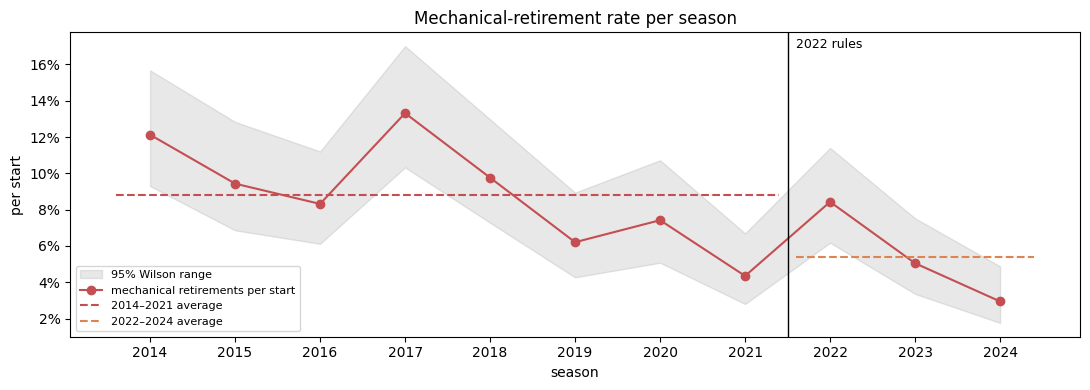

season,starts,mechanical retirements,rate
2014,404,49,12.1%
2015,371,35,9.4%
2016,457,38,8.3%
2017,398,53,13.3%
2018,420,41,9.8%
2019,419,26,6.2%
2020,337,25,7.4%
2021,437,19,4.3%
2022,439,37,8.4%
2023,436,22,5.0%


In [229]:
season = starts.groupby("year").agg(starts=("mech", "size"), mech=("mech", "sum")).reset_index()
season["rate"] = season.mech / season.starts
season["ci_lo"], season["ci_hi"] = wilson(season.mech, season.starts)

fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(season.year, season.ci_lo, season.ci_hi, color=GREY, alpha=0.2, label="95% Wilson range")
ax.plot(season.year, season.rate, marker="o", color="#C44E52", label="mechanical retirements per start")
for p, (a, b) in {P1: (FIRST_SEASON, SPLIT - 1), P2: (SPLIT, LAST_SEASON)}.items():
    s = season[season.year.between(a, b)]
    ax.hlines(s.mech.sum() / s.starts.sum(), a - 0.4, b + 0.4, color=P_COLORS[p], ls="--", label=f"{p} average")
ax.axvline(SPLIT - 0.5, color="black", lw=1); ax.text(SPLIT - 0.4, ax.get_ylim()[1] * 0.95, f"{SPLIT} rules", fontsize=9)
ax.set(xlabel="season", ylabel="per start", title="Mechanical-retirement rate per season")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xticks(season.year); ax.legend(fontsize=8)
plt.tight_layout(); savefig("q3_01_rate_by_season"); plt.show()

table(pd.DataFrame({"season": season.year, "starts": season.starts, "mechanical retirements": season.mech,
                    "rate": season.rate}), pct1=["rate"], caption="Mechanical-retirement rate per season")

A team that raced only in 2014 would look unreliable partly because of the year, and a team that raced only in 2024 would look reliable partly because of the year. **Fix: compare each team with what was normal in its own seasons**, as in Q1: the **normal rate for its seasons** is the average of the seasons in which its starts took place (each season's rate is computed over all teams). The pretend starts are given at this normal rate, and

> **score = adjusted rate − normal rate for its seasons**, in percentage points: *how much more often than normal this team's cars broke down.*

**Teams are ranked by this score.** For teams that raced in every season of a period (Mercedes, Ferrari, ...), the normal rate is simply the period's rate; it only matters for teams that raced in part of a period.

In [230]:
def constructor_table(d, event="mech", min_n=MIN_STARTS, k_values=K_VALUES):
    """One row per constructor and period: raw rate, Wilson range, normal rate for its seasons, scores and ranks."""
    season_rate = d.groupby("year")[event].mean()                 # over ALL teams, before the minimum-sample filter
    t = (d.assign(expected=d.year.map(season_rate))
           .groupby(["period", "constructorId"])
           .agg(constructor=("constructor", "first"), first=("year", "min"), last=("year", "max"),
                starts=(event, "size"), events=(event, "sum"), expected=("expected", "mean"))
           .reset_index())
    t["raw rate"] = t.events / t.starts
    t["ci_lo"], t["ci_hi"] = wilson(t.events, t.starts)
    for k in k_values:
        t[f"score_k{k}"] = bayes_avg(t.events, t.starts, t.expected, k) - t.expected
    t = t[t.starts >= min_n].copy()
    for k in k_values:
        t[f"rank_k{k}"] = t.groupby("period")[f"score_k{k}"].rank(ascending=False, method="min").astype(int)
    sort_k = K_MAIN if K_MAIN in k_values else k_values[0]
    return t.sort_values(["period", f"rank_k{sort_k}"]).reset_index(drop=True)

RANK_COLS = [f"rank_k{k}" for k in K_VALUES]

def top_group(t, top=TOP):
    """Constructors in the top `top` under every value of k."""
    return t[(t[RANK_COLS] <= top).all(axis=1)]

ct = constructor_table(starts)
ct_upper = constructor_table(starts, event="mech_upper")    # upper bound: grey-zone statuses counted

#### 3.2 The ranking

In [231]:
for p in PERIODS:
    t = ct[ct.period == p]
    up = ct_upper[ct_upper.period == p].set_index("constructorId")["raw rate"]
    table(pd.DataFrame({
        "rank": t[f"rank_k{K_MAIN}"], "constructor": t.constructor,
        "seasons": [f"{a}" if a == b else f"{a}–{b}" for a, b in zip(t["first"], t["last"])],
        "starts": t.starts, "mechanical retirements": t.events, "raw rate": t["raw rate"],
        "95% Wilson range": pct_range(t.ci_lo, t.ci_hi, digits=1), "normal for its seasons": t.expected,
        f"adjusted rate (+{K_MAIN} pretend starts)": t.expected + t[f"score_k{K_MAIN}"],
        "score: adjusted − normal (points)": t[f"score_k{K_MAIN}"] * 100,
        "upper bound (grey zone counted)": t.constructorId.map(up),
    }), pct1=["raw rate", "normal for its seasons", f"adjusted rate (+{K_MAIN} pretend starts)", "upper bound (grey zone counted)"],
        dec1=["score: adjusted − normal (points)"], caption=f"{p}: mechanical-retirement ranking")

rank,constructor,seasons,starts,mechanical retirements,raw rate,95% Wilson range,normal for its seasons,adjusted rate (+20 pretend starts),score: adjusted − normal (points),upper bound (grey zone counted)
1,Toro Rosso,2014–2019,242,39,16.1%,12.0% – 21.3%,9.8%,15.6%,5.8,18.2%
2,Caterham,2014,33,7,21.2%,10.7% – 37.8%,12.1%,17.8%,5.7,30.3%
3,Lotus F1,2014–2015,75,13,17.3%,10.4% – 27.4%,10.8%,16.0%,5.2,24.0%
4,McLaren,2014–2021,315,40,12.7%,9.5% – 16.8%,8.8%,12.5%,3.7,15.2%
5,Renault,2016–2020,199,26,13.1%,9.1% – 18.5%,9.0%,12.7%,3.7,16.1%
6,AlphaTauri,2020–2021,77,7,9.1%,4.5% – 17.6%,5.7%,8.4%,2.7,10.4%
7,Red Bull,2014–2021,318,34,10.7%,7.8% – 14.6%,8.8%,10.6%,1.8,11.6%
8,Alpine F1 Team,2021,44,3,6.8%,2.3% – 18.2%,4.3%,6.0%,1.7,9.1%
9,Racing Point,2019–2020,75,6,8.0%,3.7% – 16.4%,6.7%,7.7%,1.0,9.3%
10,Sauber,2014–2018,199,21,10.6%,7.0% – 15.6%,10.6%,10.6%,-0.0,13.1%


rank,constructor,seasons,starts,mechanical retirements,raw rate,95% Wilson range,normal for its seasons,adjusted rate (+20 pretend starts),score: adjusted − normal (points),upper bound (grey zone counted)
1,Alfa Romeo,2022–2023,88,11,12.5%,7.1% – 21.0%,6.7%,11.4%,4.7,12.5%
2,Alpine F1 Team,2022–2024,135,14,10.4%,6.3% – 16.7%,5.4%,9.7%,4.3,10.4%
3,RB F1 Team,2024,48,2,4.2%,1.2% – 14.0%,2.9%,3.8%,0.9,10.4%
4,AlphaTauri,2022–2023,88,6,6.8%,3.2% – 14.1%,6.7%,6.8%,0.1,8.0%
5,Williams,2022–2024,134,7,5.2%,2.6% – 10.4%,5.4%,5.3%,-0.2,8.2%
6,Sauber,2024,48,1,2.1%,0.4% – 10.9%,2.9%,2.3%,-0.6,6.2%
7,Ferrari,2022–2024,134,6,4.5%,2.1% – 9.4%,5.4%,4.6%,-0.8,6.7%
8,Haas F1 Team,2022–2024,135,6,4.4%,2.1% – 9.4%,5.4%,4.6%,-0.8,5.2%
9,Mercedes,2022–2024,136,6,4.4%,2.0% – 9.3%,5.4%,4.5%,-0.9,4.4%
10,McLaren,2022–2024,136,5,3.7%,1.6% – 8.3%,5.4%,3.9%,-1.5,3.7%


**Same team, different names.** The ranking uses the constructor names as entered, as the question asks about constructors. Some teams changed name inside a period, so the same factory can appear twice: in 2022–2024, **Alfa Romeo** (2022–2023) and **Sauber** (2024) are the same team, as are **AlphaTauri** (2022–2023) and **RB F1 Team** (2024). Part C groups them by factory.

**The figure:** for each team, the **grey dot** is the normal rate for its seasons and the **coloured dot** its adjusted rate; the number is the score. Teams at the top broke down more often than normal, teams at the bottom less often.

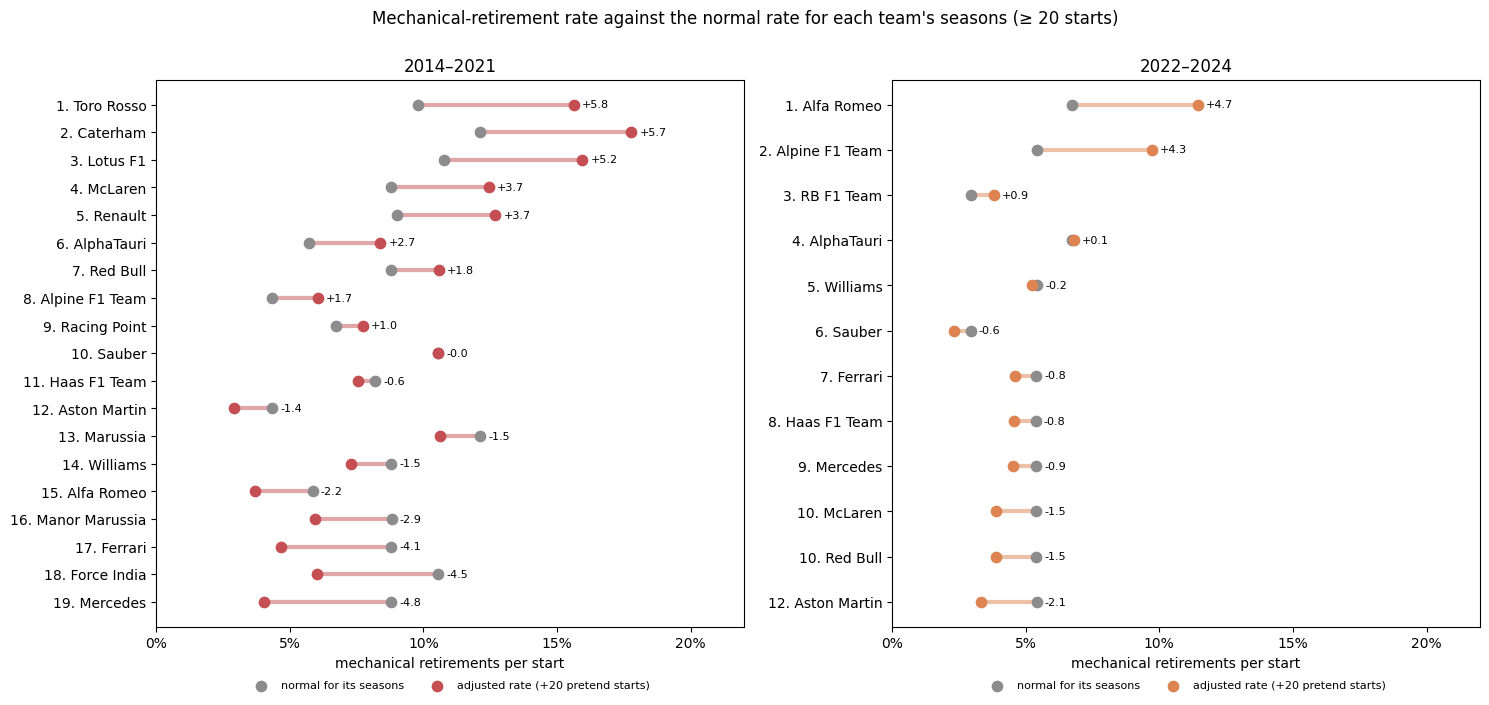

In [232]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, p in zip(axes, PERIODS):
    t = ct[ct.period == p].iloc[::-1]
    y = np.arange(len(t))
    adjusted = t.expected + t[f"score_k{K_MAIN}"]
    ax.hlines(y, t.expected, adjusted, color=P_COLORS[p], lw=3, alpha=0.5)
    ax.scatter(t.expected, y, color=GREY, s=55, zorder=3, label="normal for its seasons")
    ax.scatter(adjusted, y, color=P_COLORS[p], s=55, zorder=4, label=f"adjusted rate (+{K_MAIN} pretend starts)")
    for yi, a, x, sc in zip(y, adjusted, t.expected, t[f"score_k{K_MAIN}"]):
        ax.text(max(a, x) + 0.003, yi, f"{sc * 100:+.1f}", va="center", fontsize=8)
    ax.set_yticks(y); ax.set_yticklabels([f"{r}. {c}" for r, c in zip(t[f"rank_k{K_MAIN}"], t.constructor)])
    ax.set(title=p, xlabel="mechanical retirements per start", xlim=(0, 0.22))
    ax.set_xticks(np.arange(0, 0.21, 0.05))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
fig.suptitle(f"Mechanical-retirement rate against the normal rate for each team's seasons (≥ {MIN_STARTS} starts)", y=1.0)
plt.tight_layout(); savefig("q3_02_ranking"); plt.show()

#### 3.3 Does the answer depend on our choices?

We chose **20** pretend starts, a minimum of **20** starts, and only the clear mechanical statuses. So we also tried **10 and 40** pretend starts, a minimum of **10 and 40** starts, and counting the **grey zone** as mechanical. As in Q1 we report a **top group**: teams in the top 3 with 10, 20 **and** 40 pretend starts.

In [233]:
rob_rows, groups = [], {}
for m in MIN_STARTS_VALUES:
    t_m = constructor_table(starts, min_n=m)
    for p in PERIODS:
        g = top_group(t_m[t_m.period == p])
        groups[(p, m)] = set(g.constructorId)
        rob_rows.append({"period": p, "version": f"minimum {m} starts", "teams ranked": int((t_m.period == p).sum()),
                         f"top group (top {TOP} with 10, 20 and 40 pretend starts)": ", ".join(g.constructor) or "none"})
for p in PERIODS:
    g = top_group(ct_upper[ct_upper.period == p])
    rob_rows.append({"period": p, "version": "grey zone counted as mechanical", "teams ranked": int((ct_upper.period == p).sum()),
                     f"top group (top {TOP} with 10, 20 and 40 pretend starts)": ", ".join(g.constructor) or "none"})
table(pd.DataFrame(rob_rows).sort_values("period", kind="stable"), caption="The top group under each choice")

period,version,teams ranked,"top group (top 3 with 10, 20 and 40 pretend starts)"
2014–2021,minimum 10 starts,19,"Toro Rosso, Caterham, Lotus F1"
2014–2021,minimum 20 starts,19,"Toro Rosso, Caterham, Lotus F1"
2014–2021,minimum 40 starts,17,"Toro Rosso, Lotus F1"
2014–2021,grey zone counted as mechanical,19,"Caterham, Lotus F1, Toro Rosso"
2022–2024,minimum 10 starts,12,"Alfa Romeo, Alpine F1 Team, RB F1 Team"
2022–2024,minimum 20 starts,12,"Alfa Romeo, Alpine F1 Team, RB F1 Team"
2022–2024,minimum 40 starts,12,"Alfa Romeo, Alpine F1 Team, RB F1 Team"
2022–2024,grey zone counted as mechanical,12,"RB F1 Team, Alfa Romeo, Alpine F1 Team"


#### 3.4 Part A answer

In [234]:
robust_ids = {p: set.intersection(*(groups[(p, m)] for m in MIN_STARTS_VALUES)) for p in PERIODS}
lines = []
for p in PERIODS:
    t = ct[ct.period == p]
    g = top_group(t)
    desc = "; ".join(f"**{c}**{' ✓' if cid in robust_ids[p] else ''} ({e}/{n} starts, normal {x:.1%}, {s * 100:+.1f} points)"
                     for cid, c, e, n, x, s in zip(g.constructorId, g.constructor, g.events, g.starts, g.expected,
                                                   g[f"score_k{K_MAIN}"])) or f"no constructor is in the top {TOP} under every k"
    low = t.nsmallest(2, f"score_k{K_MAIN}")
    lines.append(f"- **{p}:** {desc}. Most reliable: "
                 + ", ".join(f"{c} ({s * 100:+.1f} points)" for c, s in zip(low.constructor, low[f"score_k{K_MAIN}"])) + ".")
close = [(p, c, s) for p in PERIODS for c, s in zip(top_group(ct[ct.period == p]).constructor,
                                                    top_group(ct[ct.period == p])[f"score_k{K_MAIN}"]) if s < 0.01]
note = "".join(f"\n\n**{c}** ({p}) is in the top group, but only {s * 100:+.1f} points above normal: it is in the top {TOP} "
               "because few teams in that period broke down more often than normal, not because it stands out." for p, c, s in close)
md(f"**Highest mechanical-retirement rate** (top group: top {TOP} with 10, 20 and 40 pretend starts, minimum {MIN_STARTS} "
   "starts; mechanical retirements/starts, normal rate for its seasons, score):\n" + "\n".join(lines) +
   f"\n\n✓ = also in the top group with a minimum of {MIN_STARTS_VALUES[0]} and {MIN_STARTS_VALUES[-1]} starts. "
   "The table in 3.3 shows which teams change when the grey zone is counted." + note)

**Highest mechanical-retirement rate** (top group: top 3 with 10, 20 and 40 pretend starts, minimum 20 starts; mechanical retirements/starts, normal rate for its seasons, score):
- **2014–2021:** **Toro Rosso** ✓ (39/242 starts, normal 9.8%, +5.8 points); **Caterham** (7/33 starts, normal 12.1%, +5.7 points); **Lotus F1** ✓ (13/75 starts, normal 10.8%, +5.2 points). Most reliable: Mercedes (-4.8 points), Force India (-4.5 points).
- **2022–2024:** **Alfa Romeo** ✓ (11/88 starts, normal 6.7%, +4.7 points); **Alpine F1 Team** ✓ (14/135 starts, normal 5.4%, +4.3 points); **RB F1 Team** ✓ (2/48 starts, normal 2.9%, +0.9 points). Most reliable: Aston Martin (-2.1 points), McLaren (-1.5 points).

✓ = also in the top group with a minimum of 10 and 40 starts. The table in 3.3 shows which teams change when the grey zone is counted.

**RB F1 Team** (2022–2024) is in the top group, but only +0.9 points above normal: it is in the top 3 because few teams in that period broke down more often than normal, not because it stands out.

### Step 4: Did cars become more reliable, and was it because of 2022? (Part B)

The chart in 3.1 shows the rate falling over time. Two comparisons:
- **2014–2021 vs 2022–2024**, the question's periods;
- **2019–2021 vs 2022–2024**: the three seasons just before the new rules against the three under them. If the 2022 rules made the difference, this change should also be clear.

**The range of a change:** a team's two cars share the same engine and parts all season, so their failures go together. The range is found by redrawing whole **team-seasons** (for example "McLaren 2015", both cars and every race) 1,000 times and keeping the middle 95%. A change is **clear** when its range does not include 0.

In [235]:
team_season = (starts.groupby(["constructorId", "year"])
                     .agg(mech=("mech", "sum"), n=("mech", "size")).reset_index())

def team_season_range(a0, a1, b0, b1, B=N_BOOT, seed=SEED):
    """Rate before, rate after, and the 95% range of the change (points) when whole team-seasons are redrawn."""
    rng = np.random.default_rng(seed)
    wa, wb = team_season[team_season.year.between(a0, a1)], team_season[team_season.year.between(b0, b1)]
    ia, ib = rng.integers(0, len(wa), size=(B, len(wa))), rng.integers(0, len(wb), size=(B, len(wb)))
    ra = wa.mech.values[ia].sum(axis=1) / wa.n.values[ia].sum(axis=1)
    rb = wb.mech.values[ib].sum(axis=1) / wb.n.values[ib].sum(axis=1)
    lo, hi = np.percentile((rb - ra) * 100, [2.5, 97.5])
    return wa.mech.sum() / wa.n.sum(), wb.mech.sum() / wb.n.sum(), lo, hi

cmp_rows = []
for name, a, b in [(f"the question's periods: {P1} vs {P2}", (FIRST_SEASON, SPLIT - 1), (SPLIT, LAST_SEASON)),
                   (f"just before vs after: {LATE_PRE}–{SPLIT - 1} vs {P2}", (LATE_PRE, SPLIT - 1), (SPLIT, LAST_SEASON))]:
    ra, rb, lo, hi = team_season_range(*a, *b)
    cmp_rows.append({"comparison": name, "rate before": ra, "rate after": rb, "change (points)": (rb - ra) * 100,
                     "95% range of the change": f"{lo:+.1f} to {hi:+.1f}", "clear change?": "yes" if (hi < 0 or lo > 0) else "no",
                     "_lo": lo, "_hi": hi})
cmp = pd.DataFrame(cmp_rows)
table(cmp.drop(columns=["_lo", "_hi"]), pct1=["rate before", "rate after"], dec1=["change (points)"],
      caption="Change in the mechanical-retirement rate (negative = fewer failures)")

main, late = cmp.iloc[0], cmp.iloc[1]
when = (f"Against the three seasons just before the rules the change is also clear ({late['rate before']:.1%} → "
        f"{late['rate after']:.1%}), so the 2022 period really is more reliable than the end of the previous rules."
        if late["clear change?"] == "yes" else
        f"Against the three seasons just before the rules the change is **not clear** ({late['rate before']:.1%} → "
        f"{late['rate after']:.1%}, range {late['_lo']:+.1f} to {late['_hi']:+.1f} points). Most of the improvement "
        "had already happened before 2022, so the data does not show that the 2022 rules caused it.")
md(f"""**Part B answer:** cars did become more reliable: {main['rate before']:.1%} → {main['rate after']:.1%}
({main['change (points)']:+.1f} points, range {main['_lo']:+.1f} to {main['_hi']:+.1f}, {'clear of zero' if main['clear change?'] == 'yes' else 'includes zero'}).
{when}""")

comparison,rate before,rate after,change (points),95% range of the change,clear change?
the question's periods: 2014–2021 vs 2022–2024,8.8%,5.4%,-3.4,-5.3 to -1.5,yes
just before vs after: 2019–2021 vs 2022–2024,5.9%,5.4%,-0.5,-2.5 to +1.4,no


**Part B answer:** cars did become more reliable: 8.8% → 5.4%
(-3.4 points, range -5.3 to -1.5, clear of zero).
Against the three seasons just before the rules the change is **not clear** (5.9% → 5.4%, range -2.5 to +1.4 points). Most of the improvement had already happened before 2022, so the data does not show that the 2022 rules caused it.

### Step 5: Did the same team break down less after 2022? (Part C)

Several teams changed name while keeping the same factory and staff: Toro Rosso → AlphaTauri → RB, Force India → Racing Point → Aston Martin, Lotus F1 → Renault → Alpine, Sauber ↔ Alfa Romeo, Marussia → Manor. The data gives each name its own `constructorId`. To compare **the same team** before and after 2022, the names are grouped by factory here; Part A keeps the names as entered.

In [236]:
LINEAGE = {
    "toro_rosso": "Faenza (Toro Rosso / AlphaTauri / RB)", "alphatauri": "Faenza (Toro Rosso / AlphaTauri / RB)",
    "rb": "Faenza (Toro Rosso / AlphaTauri / RB)",
    "force_india": "Silverstone (Force India / Racing Point / Aston Martin)",
    "racing_point": "Silverstone (Force India / Racing Point / Aston Martin)",
    "aston_martin": "Silverstone (Force India / Racing Point / Aston Martin)",
    "lotus_f1": "Enstone (Lotus F1 / Renault / Alpine)", "renault": "Enstone (Lotus F1 / Renault / Alpine)",
    "alpine": "Enstone (Lotus F1 / Renault / Alpine)",
    "sauber": "Hinwil (Sauber / Alfa Romeo)", "alfa": "Hinwil (Sauber / Alfa Romeo)",
    "marussia": "Banbury (Marussia / Manor)", "manor": "Banbury (Marussia / Manor)",
}
starts["team"] = starts.constructorRef.map(LINEAGE).fillna(starts.constructor)

names_used = starts.groupby(["team", "constructor"]).year.agg(["min", "max"]).reset_index()
names_used["label"] = names_used.constructor + " (" + names_used["min"].astype(str) + "–" + names_used["max"].astype(str) + ")"
renamed = names_used.groupby("team").filter(lambda g: len(g) > 1).groupby("team").label.agg(", ".join)
table(renamed.rename("names used (seasons)").reset_index(), caption="Teams that raced under more than one name, 2014–2024")

team,names used (seasons)
Banbury (Marussia / Manor),"Manor Marussia (2015–2016), Marussia (2014–2014)"
Enstone (Lotus F1 / Renault / Alpine),"Alpine F1 Team (2021–2024), Lotus F1 (2014–2015), Renault (2016–2020)"
Faenza (Toro Rosso / AlphaTauri / RB),"AlphaTauri (2020–2023), RB F1 Team (2024–2024), Toro Rosso (2014–2019)"
Hinwil (Sauber / Alfa Romeo),"Alfa Romeo (2019–2023), Sauber (2014–2024)"
Silverstone (Force India / Racing Point / Aston Martin),"Aston Martin (2021–2024), Force India (2014–2018), Racing Point (2019–2020)"


For every team that raced in both periods, we compare its rate before and after 2022. With only three seasons after 2022, the range is found by redrawing the team's **races** (both cars together) 1,000 times; this does not capture problems that last a whole season, so these ranges are somewhat narrow. A change is **clear** when its range does not include 0.

team,rate 2014–2021,rate 2022–2024,change (points),95% range,clear change?
McLaren,12.7%,3.7%,-9.0,-14.5 to -3.8,"yes, fewer failures"
Faenza (Toro Rosso / AlphaTauri / RB),14.4%,5.9%,-8.5,-13.6 to -2.9,"yes, fewer failures"
Red Bull,10.7%,3.7%,-7.0,-11.6 to -2.0,"yes, fewer failures"
Haas F1 Team,7.5%,4.4%,-3.1,-8.3 to +1.7,no
Enstone (Lotus F1 / Renault / Alpine),13.2%,10.4%,-2.8,-9.2 to +3.5,no
Silverstone (Force India / Racing Point / Aston Martin),5.7%,3.0%,-2.7,-6.7 to +2.0,no
Williams,7.2%,5.2%,-2.0,-6.6 to +2.8,no
Ferrari,4.4%,4.5%,0.1,-4.2 to +5.0,no
Mercedes,3.8%,4.4%,0.7,-3.1 to +5.0,no
Hinwil (Sauber / Alfa Romeo),7.8%,8.8%,1.0,-4.3 to +7.2,no


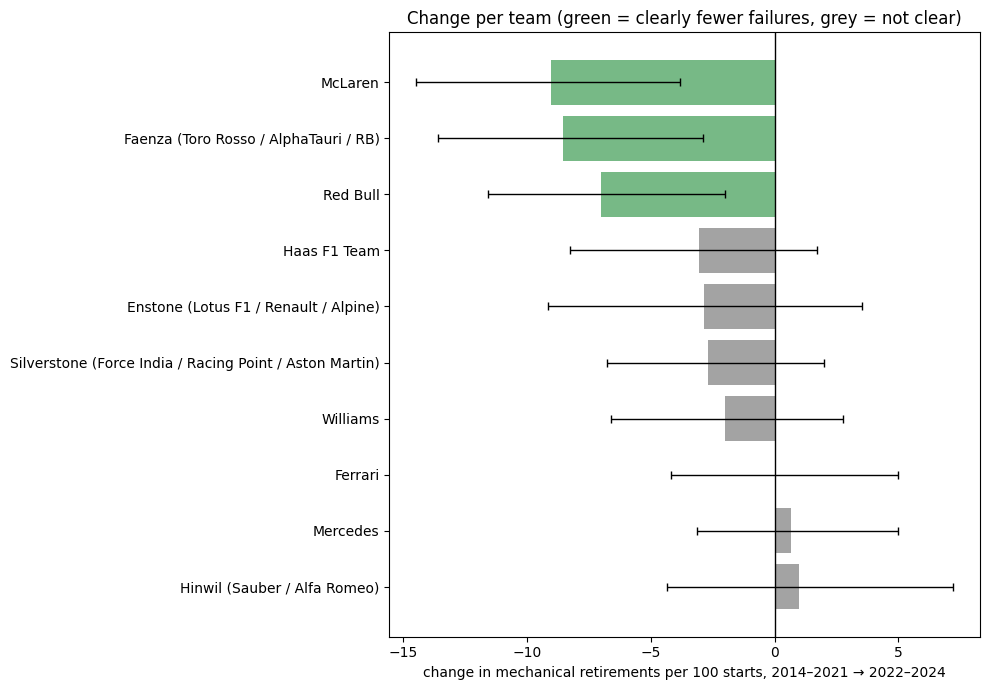

**Part C answer:** clearly fewer failures after 2022: **McLaren, Faenza (Toro Rosso / AlphaTauri / RB), Red Bull**. Clearly more: **none**. For the other teams the change is not clear.

In [237]:
team_race = starts.groupby(["team", "period", "raceId"]).agg(mech=("mech", "sum"), n=("mech", "size")).reset_index()

def team_change(team, B=N_BOOT, seed=SEED):
    """Change in one team's rate (points) between the periods, with a range from redrawing its races."""
    rng = np.random.default_rng(seed)
    out, sims = {"team": team}, []
    for p in PERIODS:
        g = team_race[(team_race.team == team) & (team_race.period == p)]
        idx = rng.integers(0, len(g), size=(B, len(g)))
        out[p] = g.mech.sum() / g.n.sum()
        sims.append(g.mech.values[idx].sum(axis=1) / g.n.values[idx].sum(axis=1))
    out["change (points)"] = (out[P2] - out[P1]) * 100
    out["lo"], out["hi"] = np.percentile((sims[1] - sims[0]) * 100, [2.5, 97.5])
    return out

both = team_race.groupby("team").period.nunique()
lineage_teams = [t for t in both.index[both == 2]
                 if team_race[team_race.team == t].groupby("period").n.sum().min() >= MIN_STARTS]
lin = pd.DataFrame([team_change(t) for t in lineage_teams]).sort_values("change (points)")
lin["clear change?"] = np.where(lin.hi < 0, "yes, fewer failures", np.where(lin.lo > 0, "yes, more failures", "no"))
table(pd.DataFrame({"team": lin.team, f"rate {P1}": lin[P1], f"rate {P2}": lin[P2],
                    "change (points)": lin["change (points)"],
                    "95% range": [f"{a:+.1f} to {b:+.1f}" for a, b in zip(lin.lo, lin.hi)],
                    "clear change?": lin["clear change?"]}),
      pct1=[f"rate {P1}", f"rate {P2}"], dec1=["change (points)"], caption="Change per team (negative = fewer failures)")

fig, ax = plt.subplots(figsize=(10, 0.55 * len(lin) + 1.5))
d = lin.sort_values("change (points)", ascending=False)
y = np.arange(len(d))
colors = ["#55A868" if h < 0 else ("#C44E52" if l > 0 else GREY) for l, h in zip(d.lo, d.hi)]
ax.barh(y, d["change (points)"], color=colors, alpha=0.8)
ax.errorbar(d["change (points)"], y, xerr=[d["change (points)"] - d.lo, d.hi - d["change (points)"]],
            fmt="none", ecolor="black", capsize=3, lw=1)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(y); ax.set_yticklabels(d.team)
ax.set(xlabel=f"change in mechanical retirements per 100 starts, {P1} → {P2}",
       title="Change per team (green = clearly fewer failures, grey = not clear)")
plt.tight_layout(); savefig("q3_03_team_change"); plt.show()

better = ", ".join(lin.loc[lin.hi < 0, "team"]) or "none"
worse = ", ".join(lin.loc[lin.lo > 0, "team"]) or "none"
md(f"**Part C answer:** clearly fewer failures after 2022: **{better}**. Clearly more: **{worse}**. "
   "For the other teams the change is not clear.")

### Answer and limitations

In [238]:
best = {p: ", ".join(f"{c}{' ✓' if cid in robust_ids[p] else ''}" for cid, c in
                     zip(top_group(ct[ct.period == p]).constructorId, top_group(ct[ct.period == p]).constructor)) or "none"
        for p in PERIODS}
table(pd.DataFrame([
    {"part": f"A. Highest mechanical-retirement rate {P1}", "answer": best[P1]},
    {"part": f"A. Highest mechanical-retirement rate {P2}", "answer": best[P2]},
    {"part": "B. Did cars become more reliable?",
     "answer": f"{main['rate before']:.1%} → {main['rate after']:.1%} ({main['change (points)']:+.1f} points, "
               f"range {main['_lo']:+.1f} to {main['_hi']:+.1f})"},
    {"part": "B. Did the drop come with the 2022 rules?",
     "answer": "yes: also clear against 2019–2021" if late["clear change?"] == "yes"
               else "mostly before 2022: no clear change against 2019–2021"},
    {"part": "C. Teams with clearly fewer failures after 2022", "answer": better},
    {"part": "C. Teams with clearly more failures after 2022", "answer": worse},
]), caption="Q3 answers (✓ = in the top group under every minimum sample)")

part,answer
A. Highest mechanical-retirement rate 2014–2021,"Toro Rosso ✓, Caterham, Lotus F1 ✓"
A. Highest mechanical-retirement rate 2022–2024,"Alfa Romeo ✓, Alpine F1 Team ✓, RB F1 Team ✓"
B. Did cars become more reliable?,"8.8% → 5.4% (-3.4 points, range -5.3 to -1.5)"
B. Did the drop come with the 2022 rules?,mostly before 2022: no clear change against 2019–2021
C. Teams with clearly fewer failures after 2022,"McLaren, Faenza (Toro Rosso / AlphaTauri / RB), Red Bull"
C. Teams with clearly more failures after 2022,none


**Limitations:**
- **Engine supplier is mixed into team reliability.** Many failures come from the power unit, which several teams buy from the same supplier (for example McLaren's 2015–2017 Honda engines). Ergast does not store the engine supplier.
- **The status gives only the official reason.** `Retired` hides the cause; the upper bound shows how much the grey zone could matter.
- **The status groups contain judgment calls** (step 1).
- **Team names vs factories.** Part A follows the names as entered, so a renamed team can appear twice in one period; Part C groups them by factory.
- **2022–2024 is only three seasons,** so rates in that period are less precise.
- **The per-team ranges in Part C redraw races, not seasons,** so they do not capture season-long problems and are somewhat narrow.
- **Sprint races are not in `results`,** so they are not counted.
- **Descriptive only:** the analysis does not show *why* reliability changed.

# 7. Feature engineering

Each row of the modelling table is one prediction: *will this driver finish on the podium in this race?* This section adds the **features**, the information the model gets for each row. Every feature has to pass two tests:
1. **Known before the race starts** (after qualifying). Anything written after the race (results, points, laps, status, the standings of that race) is never a feature (cleaning summary, *Features that must look backwards only*).
2. **Backed by evidence:** a chart or a number showing how it relates to the podium.

**How strongly a feature relates to the podium** is measured in the same way for every group, with the **AUC**: take one random start that ended on the podium and one that did not; the AUC is the chance that the feature gives the podium start the better value. 0.5 means the feature is no better than a coin flip, 1 means it always separates them. The AUC judges one feature on its own, so a feature that only helps together with another one can score low; the "same starting area" checks cover that case.

The features are built in **groups**, so that the ablation can later remove one group at a time. We start with the grid and add the other groups (qualifying, driver form, team form, standings, ...) one by one.

**Rules from the cleaning, used throughout:**
- Features that look at history are computed on **all** rows, so a driver's history counts every race. The `never_ran` and Indianapolis 500 rows are removed only afterwards, when the final modelling table is built.
- Races are ordered by `(year, round)`, never by `raceId`.
- Season totals become rates, because points and calendar length changed across eras.
- Missing feature values are not filled here; they are filled in preprocessing, using the training seasons only.


In [239]:
# the feature table: the columns it needs from the base table (section 5), in race order
fe = (base[['resultId', 'raceId', 'driverId', 'constructorId', 'grid', 'grid_clean', 'pit_lane_start',
            'positionOrder', 'never_ran', 'is_indy500', 'year', 'round', 'circuitId', 'podium']]
      .sort_values(['year', 'round', 'positionOrder'])
      .reset_index(drop=True))
model_rows = ~fe.never_ran & ~fe.is_indy500           # the rows the model will be trained and tested on

def auc(feature, target):
    """Chance that a random podium start has a higher feature value than a random non-podium start (0.5 = no better than chance)."""
    known = feature.notna()
    f, t = feature[known], target[known]
    return stats.mannwhitneyu(f[t == 1], f[t == 0]).statistic / ((t == 1).sum() * (t == 0).sum())

print('rows:', len(fe), '| model rows:', int(model_rows.sum()), '| podium rate in model rows:',
      f'{fe.loc[model_rows, "podium"].mean():.1%}')


rows: 26668 | model rows: 24577 | podium rate in model rows: 13.7%


## 7.1 Grid

**Hypothesis.** Where a driver starts decides most of their chance of a podium. Q1 and Q2 already showed it: a P1 starter reaches the podium about 64% of the time and a P10 starter about 6%.

**Features.**
- `grid_clean`: the starting slot, with pit-lane starters placed at the back of the field (results section, *pit-lane starts*).
- `pit_lane_start`: 1 when the driver started from the pit lane.

**Valid at the cutoff.** The grid is fixed before the race starts, after qualifying and any grid penalties, so both features are known at prediction time.

**Evidence:** the podium rate for every starting slot, on the model rows.


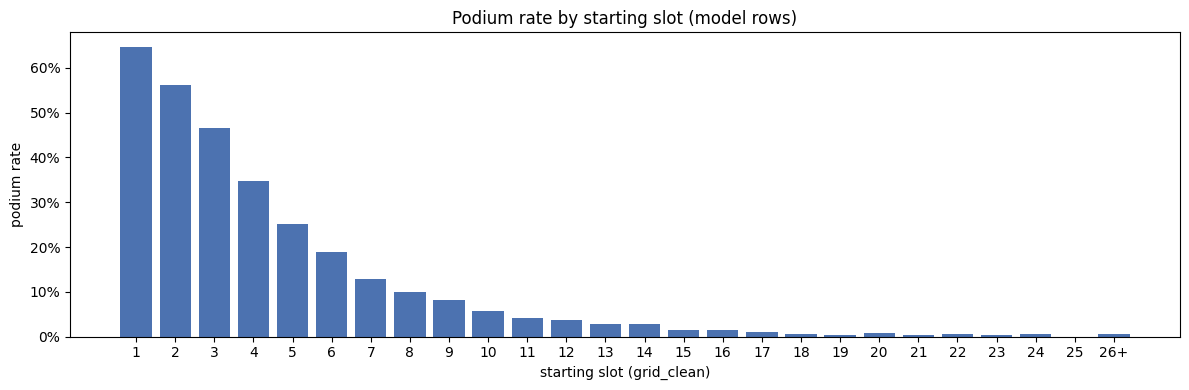

Spearman correlation between grid_clean and podium: -0.46 | AUC: 0.885
podium rate in slots 1-3: 56% | slots 4-10: 17% | slot 11 or further back: 1.6%


,starts,podiums,podium_rate
pit_lane_start,,,
started from a grid slot,24505,3359,0.137074
started from the pit lane,72,0,0.000000


In [240]:
g = fe[model_rows]
by_slot = (g.assign(slot=g.grid_clean.clip(upper=26))          # slots behind 26 are very rare: grouped as 26+
             .groupby('slot').agg(starts=('podium', 'size'), podiums=('podium', 'sum')))
by_slot['podium rate'] = by_slot.podiums / by_slot.starts

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(by_slot.index, by_slot['podium rate'], color='#4C72B0')
ax.set_xticks(by_slot.index)
ax.set_xticklabels([str(s) if s < 26 else '26+' for s in by_slot.index])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='starting slot (grid_clean)', ylabel='podium rate', title='Podium rate by starting slot (model rows)')
plt.tight_layout(); plt.show()

rho = stats.spearmanr(g.grid_clean, g.podium)[0]
pit = g.groupby('pit_lane_start').agg(starts=('podium', 'size'), podiums=('podium', 'sum'), podium_rate=('podium', 'mean'))
print(f'Spearman correlation between grid_clean and podium: {rho:.2f} | AUC: {auc(-g.grid_clean, g.podium):.3f}')   # minus: a smaller slot is better
print('podium rate in slots 1-3:', f"{g[g.grid_clean <= 3].podium.mean():.0%}",
      '| slots 4-10:', f"{g[g.grid_clean.between(4, 10)].podium.mean():.0%}",
      '| slot 11 or further back:', f"{g[g.grid_clean >= 11].podium.mean():.1%}")
display(pit.rename(index={False: 'started from a grid slot', True: 'started from the pit lane'}))


**Reading.** The podium rate falls steeply with the starting slot: about 65% from P1, 47% from P3, 6% from P10 and almost none from P15 back. Drivers starting in the top 3 reach the podium 56% of the time, from slots 4 to 10 17%, and from slot 11 or further back only 1.6%. The Spearman correlation between `grid_clean` and podium is −0.46 and its AUC is 0.885. The relation is strong but not a straight line: most of the change happens in the first ten slots, which the encoding has to respect (decided in preprocessing).

**Pit-lane starts.** The flag finds 72 pit-lane starts, all from 2015 on, and none reached the podium (the best finish is 5th). Before 2015 the data does not record a pit-lane start as `grid` = 0 but gives it a slot at the back of the grid, so those starts cannot be flagged. Pit-lane starters have reached the podium in that period: race reports (F1 history, not the data) name Trulli at the 2009 Australian Grand Prix, Vettel at the 2012 Abu Dhabi Grand Prix and Hamilton at the 2014 Hungarian Grand Prix, all third, and the data records them from grid slots 20, 24 and 22.

**Decision.** `grid_clean` is kept as the main grid feature: it places every pit-lane starter at the back of the field, before and after 2015. `pit_lane_start` is not used as a feature, because it only exists from 2015, covers 72 rows, and its information is already in `grid_clean`.


## 7.2 Qualifying

### 1. Hypothesis

The grid already contains most of qualifying, because drivers usually start where they qualified. Qualifying can still add two things the grid does not have:
- **(a) A fast car that was moved back.** A driver who qualified 3rd but starts 15th after a grid penalty still has a fast car. Q1 showed that drivers who qualified on the front row but started further back reached the podium 31% of the time, against 73% for those who kept their slot.
- **(b) How much faster.** Two drivers next to each other on the grid can be 0.01 seconds or a full second apart. The position does not show this, but the lap time does.

### 2. Candidate features

- `quali_pos`: the qualifying position, the obvious candidate.
- `grid_minus_quali`: `grid_clean` − `quali_pos`, for idea (a). Positive means the driver starts further back than they qualified (a penalty or a pit-lane start), negative means they were moved up.
- `quali_gap_pct`: how much slower the driver's Q1 lap was than the fastest Q1 lap of that race, in percent, for idea (b). Q1 is used because every driver takes part in it, while Q2 and Q3 only exist for the drivers who reached them. A percentage makes circuits of different lengths comparable.

### 3. Valid at the cutoff, and coverage

Qualifying takes place one or two days before the race (races section, *missing values*), so all three are known at prediction time.

The qualifying table starts in 1994. It is complete in 1994–1995 and from 2003, and only partly filled in 1996–2002 (results section, *What `grid` = 0 means*). Q1 times are also missing for 156 entries, where a missing time does not mean a slow car (qualifying section, *What happened to them in the race*). Missing values are left here and filled in preprocessing.

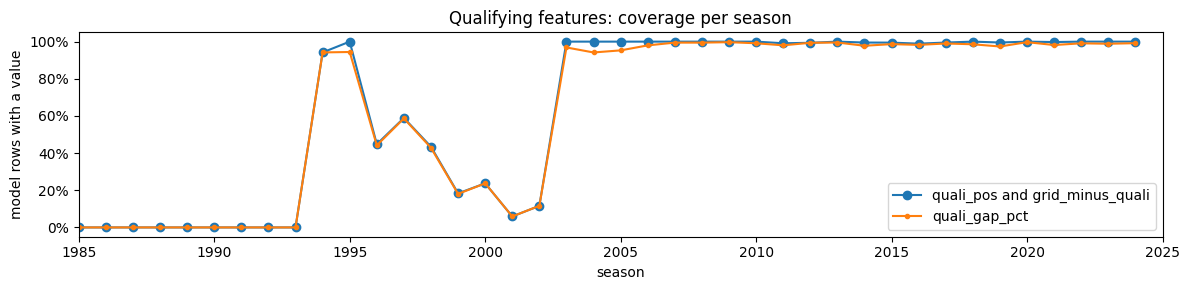

model rows with quali_pos, 2003-2024: 99.8% | with quali_gap_pct: 98.4%


In [241]:
q = qualifying[['raceId', 'driverId', 'position', 'q1_s']].rename(columns={'position': 'quali_pos'})
fe = fe.drop(columns=['quali_pos', 'q1_s', 'grid_minus_quali', 'quali_gap_pct'], errors='ignore')   # safe to rerun
fe = fe.merge(q, on=['raceId', 'driverId'], how='left', validate='1:1')
fe['grid_minus_quali'] = fe.grid_clean - fe.quali_pos
fe['quali_gap_pct'] = (fe.q1_s / fe.groupby('raceId').q1_s.transform('min') - 1) * 100

g = fe[model_rows]
cov = g.groupby('year')[['quali_pos', 'quali_gap_pct']].apply(lambda d: d.notna().mean())
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cov.index, cov.quali_pos, marker='o', label='quali_pos and grid_minus_quali')
ax.plot(cov.index, cov.quali_gap_pct, marker='.', label='quali_gap_pct')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlim=(1985, 2025), xlabel='season', ylabel='model rows with a value', title='Qualifying features: coverage per season')
ax.legend(); plt.tight_layout(); plt.show()

print('model rows with quali_pos, 2003-2024:', f"{g[g.year >= 2003].quali_pos.notna().mean():.1%}",
      '| with quali_gap_pct:', f"{g[g.year >= 2003].quali_gap_pct.notna().mean():.1%}")

### 4. Evidence

All three checks use the model rows from 2003, where qualifying is complete.

**4a. `quali_pos`: is it different from the grid?** If drivers almost always start where they qualified, `quali_pos` repeats `grid_clean`.

In [242]:
g = fe[model_rows & (fe.year >= 2003) & fe.quali_pos.notna()]
print(f'Spearman correlation between quali_pos and grid_clean: {stats.spearmanr(g.quali_pos, g.grid_clean)[0]:.2f}',
      f'| start where they qualified: {(g.grid_minus_quali == 0).mean():.1%}',
      f'| moved up: {(g.grid_minus_quali < 0).mean():.1%}',
      f'| moved back: {(g.grid_minus_quali > 0).mean():.1%}')
print(f'AUC 2003-2024: quali_pos {auc(-g.quali_pos, g.podium):.3f} | grid_clean {auc(-g.grid_clean, g.podium):.3f}')

Spearman correlation between quali_pos and grid_clean: 0.96 | start where they qualified: 72.5% | moved up: 21.1% | moved back: 6.3%
AUC 2003-2024: quali_pos 0.912 | grid_clean 0.909


**4b. `grid_minus_quali`: does a car moved back by a penalty still do better?** Drivers who start from the **same part of the grid** are compared: those who qualified in the top 5 and were moved back, against the others.

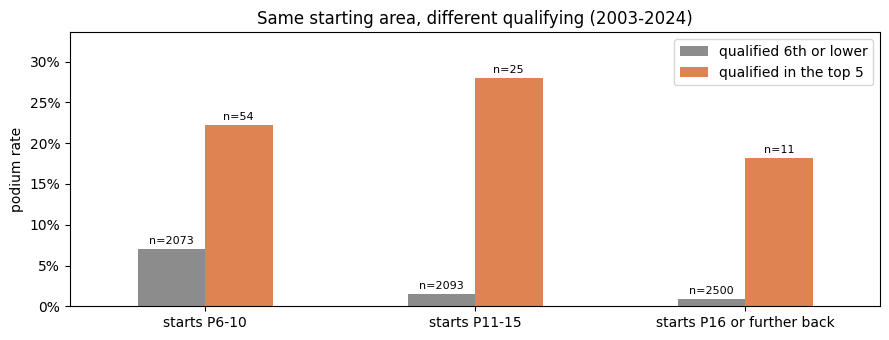

AUC of grid_minus_quali on its own: 0.550


In [243]:
g = fe[model_rows & (fe.year >= 2003) & fe.quali_pos.notna()]
back = g[g.grid_clean >= 6].assign(qualified=lambda d: np.where(d.quali_pos <= 5, 'qualified in the top 5', 'qualified 6th or lower'))
bands = pd.cut(back.grid_clean, [5, 10, 15, np.inf], labels=['starts P6-10', 'starts P11-15', 'starts P16 or further back'])
tab = (back.groupby([bands, 'qualified'], observed=True).podium.agg(starts='size', podium_rate='mean')
          .reset_index().rename(columns={'grid_clean': 'starting area', 'podium_rate': 'podium rate'}))
rates = tab.pivot(index='starting area', columns='qualified', values='podium rate')
sizes = tab.pivot(index='starting area', columns='qualified', values='starts')

fig, ax = plt.subplots(figsize=(9, 3.5))
rates.plot.bar(ax=ax, rot=0, color=['#8C8C8C', '#DD8452'])
for container, col in zip(ax.containers, rates.columns):
    ax.bar_label(container, labels=[f'n={n}' for n in sizes[col]], fontsize=8, padding=2)
ax.set_ylim(0, rates.max().max() * 1.2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='', ylabel='podium rate', title='Same starting area, different qualifying (2003-2024)')
ax.legend(title=''); plt.tight_layout(); plt.show()

print(f'AUC of grid_minus_quali on its own: {auc(g.grid_minus_quali, g.podium):.3f}')

**4c. `quali_gap_pct`: does the size of the gap matter?** The podium rate by how far behind the fastest Q1 lap a driver was.

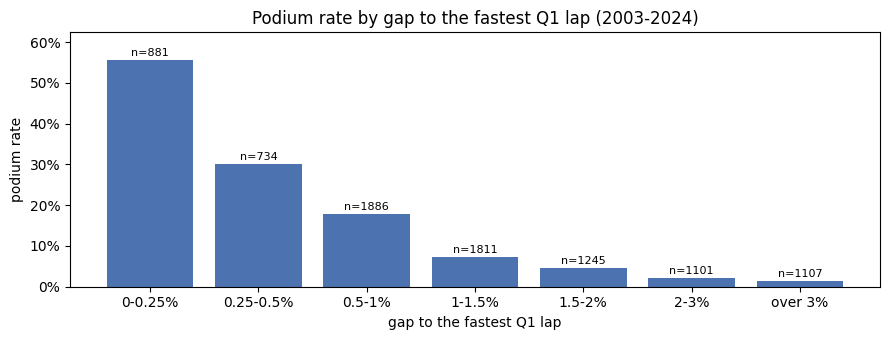

Spearman correlation with podium: quali_gap_pct -0.40 | AUC: 0.826


In [244]:
g = fe[model_rows & (fe.year >= 2003) & fe.quali_gap_pct.notna()]
gap_bins = pd.cut(g.quali_gap_pct, [-0.01, 0.25, 0.5, 1, 1.5, 2, 3, np.inf],
                  labels=['0-0.25%', '0.25-0.5%', '0.5-1%', '1-1.5%', '1.5-2%', '2-3%', 'over 3%'])
by_gap = g.groupby(gap_bins, observed=True).podium.agg(['size', 'mean'])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_gap.index.astype(str), by_gap['mean'], color='#4C72B0')
for i, (n, r) in enumerate(zip(by_gap['size'], by_gap['mean'])):
    ax.text(i, r + 0.01, f'n={n}', ha='center', fontsize=8)
ax.set_ylim(0, by_gap['mean'].max() * 1.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='gap to the fastest Q1 lap', ylabel='podium rate', title='Podium rate by gap to the fastest Q1 lap (2003-2024)')
plt.tight_layout(); plt.show()

print(f'Spearman correlation with podium: quali_gap_pct {stats.spearmanr(g.quali_gap_pct, g.podium)[0]:.2f} '
      f'| AUC: {auc(-g.quali_gap_pct, g.podium):.3f}')   # minus: a smaller gap is better

### 5. Reading and decision

- **Coverage:** from 2003, 99.8% of the model rows have a qualifying position and 98.4% a Q1 gap. Before 2003 the features are mostly or completely missing, which matters for the choice of training seasons.
- **4a.** Qualifying position and grid are almost the same (Spearman 0.96): 72.5% of drivers start where they qualified, 21.1% are moved up (usually because a car ahead was penalised or did not start) and 6.3% are moved back. On their own they are about equally strong (AUC 0.912 for `quali_pos`, 0.909 for `grid_clean` from 2003).
- **4b.** A car moved back still does better. Among drivers starting from P11–15, those who had qualified in the top 5 reached the podium 28% of the time, against 1.5% for the others; from P6–10 it is 22% against 7%. These groups are small (11 to 54 starts), but the pattern holds in every starting area. On its own `grid_minus_quali` is almost a coin flip (AUC 0.55): being moved back says little without knowing where the car starts, so it only helps together with `grid_clean`.
- **4c.** The gap matters: within 0.25% of the fastest Q1 lap, 56% reach the podium; at 0.5–1%, 18%; over 3%, about 1% (Spearman −0.40, AUC 0.826).

**Decision.** The qualifying group is `grid_minus_quali` and `quali_gap_pct`. `quali_pos` is not kept as a separate feature: it equals `grid_clean` − `grid_minus_quali`, so with those two in the model it adds no information and makes the three columns depend exactly on each other. Missing values (before 2003, and the entries with no Q1 time) are filled in preprocessing.

## 7.3 Driver form

### 1. Hypothesis

A driver who has reached the podium in recent races is likely to keep doing so a few races later: the same skill, the same car and the same team are still there. The cleaning already showed that recent results carry information: the standings before a race follow its finishing order with a rank correlation of about 0.6 in the modern seasons (driver_standings section, *how much the same-race standings would leak*).

Standings and form are related but not the same. The standings count every race of the current season and restart at zero every season; form looks at a fixed number of recent races and carries over from one season to the next. The overlap between the two is checked when the standings are built.

### 2. Candidate features

Each past race gives several numbers about the driver. Two of them are summarised over the driver's last N starts:
- `form_podium_rate`: the share of podiums in the last N starts.
- `form_avg_finish`: the average finishing position (`positionOrder`) in the last N starts. It is more detailed (a 4th place counts for something), but a driver who crashed on lap 1 gets a position near the back even if the car was fast.

And one about how much history there is:
- `career_starts`: how many starts the driver made before this race (0 for a debut). It tells how much the form value can be trusted, and experience may matter on its own.

Other numbers are left out on purpose: **points**, because the points system changed across eras (cleaning summary, *Numbers that are not comparable across eras*); **laps**, because races have different lengths; **places gained** (grid minus finish), because a driver starting on pole cannot gain any; and the **reason a race ended**, which belongs to a reliability group.

### 3. Valid at the cutoff

- **Only earlier races.** For each race, the window looks at the driver's starts **before** it, ordered by `(year, round)`. The race itself is never part of its own window. The check below proves it.
- **Only real starts count.** Races the driver did not start (`never_ran`) and the Indianapolis 500 are not results of a race, so they are not counted as a start without a podium.
- **The window crosses seasons.** At round 1 the window holds the last races of the previous season.
- **A debut has no history**, so its form value is missing and filled in preprocessing; `career_starts` is 0.

In [245]:
hist = fe[model_rows].sort_values(['driverId', 'year', 'round'])     # each driver's real starts, in race order
by_driver = hist.groupby('driverId')

def past_mean(col, n):
    """Mean of `col` over the driver's previous n starts (the current start is excluded by shift)."""
    return by_driver[col].transform(lambda s: s.shift(1).rolling(n, min_periods=1).mean())

fe = fe.drop(columns=['form_podium_rate', 'career_starts'], errors='ignore')     # safe to rerun
fe['form_podium_rate'] = past_mean('podium', 10)                               # aligned on the index of fe
fe['career_starts'] = by_driver.cumcount().astype('Int64')

# leakage check: the same value computed in a second, independent way from cumulative sums
cum = by_driver.podium.cumsum() - hist.podium                                  # podiums before this start
check = (cum - cum.groupby(hist.driverId).shift(10).fillna(0)) / fe.loc[hist.index, 'career_starts'].clip(upper=10)
assert np.allclose(check[fe.loc[hist.index, 'career_starts'] > 0], fe.loc[hist.index, 'form_podium_rate'].dropna()), 'form uses the current race'
assert fe.loc[hist.index][fe.loc[hist.index, 'career_starts'] == 0].form_podium_rate.isna().all(), 'a debut has a form value'

# one driver, start by start: the value only changes after a race
ham = (fe.loc[hist.index].merge(drivers[['driverId', 'forename', 'surname']], on='driverId')
         .query("forename == 'Lewis' and surname == 'Hamilton'").sort_values(['year', 'round']).head(5))
table(ham[['year', 'round', 'positionOrder', 'podium', 'career_starts', 'form_podium_rate']]
      .rename(columns={'positionOrder': 'finished'}), pct=['form_podium_rate'],
      caption="Lewis Hamilton's first five starts: the form value only uses the races before")

year,round,finished,podium,career_starts,form_podium_rate
2007,1,3,1,0,–
2007,2,2,1,1,100%
2007,3,2,1,2,100%
2007,4,2,1,3,100%
2007,5,2,1,4,100%


### 4. Evidence

**4a. Which window N, and which summary?** There is no obvious N, so both summaries are tried for N = 3, 5, 10, 20, 30 and 50 starts and compared with the AUC. This trial is kept here, as the brief asks for empirical choices.

In [246]:
g = fe[model_rows]
trial = []
for n in [3, 5, 10, 20, 30, 50]:
    rate, finish = past_mean('podium', n), past_mean('positionOrder', n)
    trial.append({'last N starts': n, 'AUC podium rate': auc(rate, hist.podium),
                  'AUC average finish': auc(-finish, hist.podium)})      # minus: a smaller position is better
display(pd.DataFrame(trial).style.format({'AUC podium rate': '{:.3f}', 'AUC average finish': '{:.3f}'}).hide(axis='index')
        .set_caption('Driver form: which window and which summary? (AUC, model rows)'))
print(f"correlation between the two summaries at N = 10: {stats.spearmanr(past_mean('podium', 10), past_mean('positionOrder', 10), nan_policy='omit')[0]:.2f}")

last N starts,AUC podium rate,AUC average finish
3,0.780,0.780
5,0.815,0.801
10,0.838,0.813
20,0.843,0.811
30,0.839,0.805
50,0.830,0.795


correlation between the two summaries at N = 10: -0.72


**4b. `form_podium_rate`: does recent form go with the podium?** The podium rate in a race, by the driver's podium rate over the previous 10 starts.

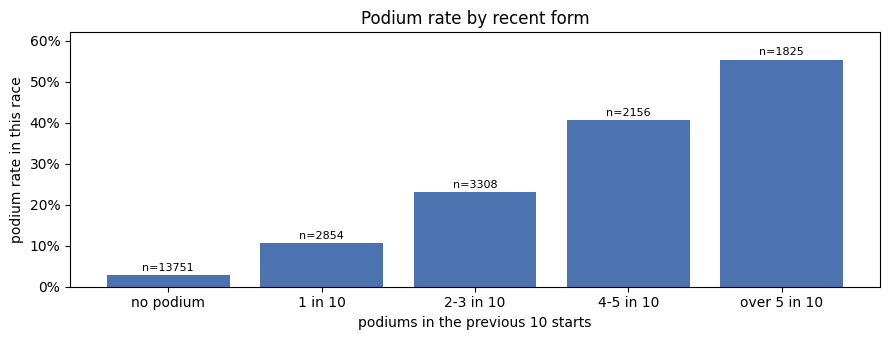

AUC of form_podium_rate: 0.838


In [247]:
g = fe[model_rows & fe.form_podium_rate.notna()]
levels = pd.cut(g.form_podium_rate, [-0.01, 0, 0.1, 0.3, 0.5, 1],
                labels=['no podium', '1 in 10', '2-3 in 10', '4-5 in 10', 'over 5 in 10'])
by_form = g.groupby(levels, observed=True).podium.agg(['size', 'mean'])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_form.index.astype(str), by_form['mean'], color='#4C72B0')
for i, (n, r) in enumerate(zip(by_form['size'], by_form['mean'])):
    ax.text(i, r + 0.01, f'n={n}', ha='center', fontsize=8)
ax.set_ylim(0, by_form['mean'].max() * 1.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='podiums in the previous 10 starts', ylabel='podium rate in this race', title='Podium rate by recent form')
plt.tight_layout(); plt.show()
print(f'AUC of form_podium_rate: {auc(g.form_podium_rate, g.podium):.3f}')

**4c. Does form add anything once the grid is known?** A fast driver usually also starts near the front, so form could just repeat the grid. Drivers who start from the **same part of the grid** are compared by their recent form.

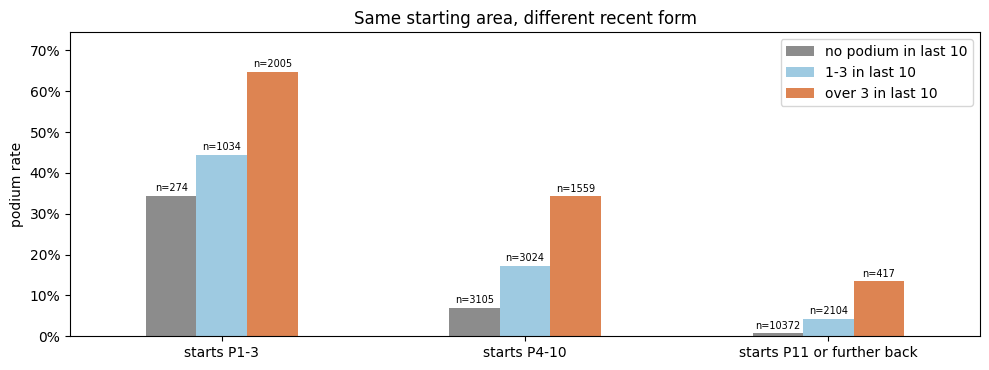

In [248]:
g = fe[model_rows & fe.form_podium_rate.notna()]
area = pd.cut(g.grid_clean, [0, 3, 10, np.inf], labels=['starts P1-3', 'starts P4-10', 'starts P11 or further back'])
form = pd.cut(g.form_podium_rate, [-0.01, 0, 0.3, 1], labels=['no podium in last 10', '1-3 in last 10', 'over 3 in last 10'])
tab = g.groupby([area, form], observed=True).podium.agg(starts='size', rate='mean').reset_index()
rates = tab.pivot(index='grid_clean', columns='form_podium_rate', values='rate')
sizes = tab.pivot(index='grid_clean', columns='form_podium_rate', values='starts')

fig, ax = plt.subplots(figsize=(10, 3.8))
rates.plot.bar(ax=ax, rot=0, color=['#8C8C8C', '#9ecae1', '#DD8452'])
for container, col in zip(ax.containers, rates.columns):
    ax.bar_label(container, labels=[f'n={n}' for n in sizes[col]], fontsize=7, padding=2)
ax.set_ylim(0, rates.max().max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='', ylabel='podium rate', title='Same starting area, different recent form')
ax.legend(title=''); plt.tight_layout(); plt.show()

**4d. `career_starts`: does experience matter, and does it change how far the form value can be trusted?** First the podium rate by the number of starts before the race, then the same form value split by whether it rests on a full window of 10 starts.

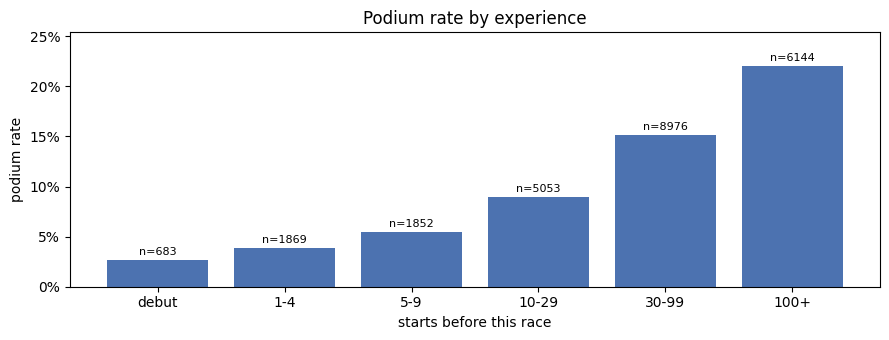

AUC of career_starts: 0.659


form_podium_rate,fewer than 10 starts: starts,full window (10 starts): starts,fewer than 10 starts: podium rate,full window (10 starts): podium rate
up to 20%,219,4634,11.0%,14.4%
20-50%,207,3258,24.6%,36.9%
over 50%,59,1766,44.1%,55.8%


In [249]:
g = fe[model_rows]
exp = pd.cut(g.career_starts, [-1, 0, 4, 9, 29, 99, np.inf], labels=['debut', '1-4', '5-9', '10-29', '30-99', '100+'])
by_exp = g.groupby(exp, observed=True).podium.agg(['size', 'mean'])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_exp.index.astype(str), by_exp['mean'], color='#4C72B0')
for i, (n, r) in enumerate(zip(by_exp['size'], by_exp['mean'])):
    ax.text(i, r + 0.005, f'n={n}', ha='center', fontsize=8)
ax.set_ylim(0, by_exp['mean'].max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='starts before this race', ylabel='podium rate', title='Podium rate by experience')
plt.tight_layout(); plt.show()
print(f'AUC of career_starts: {auc(g.career_starts, g.podium):.3f}')

w = g[g.form_podium_rate > 0]
trust = (w.assign(window=np.where(w.career_starts >= 10, 'full window (10 starts)', 'fewer than 10 starts'),
                  form=pd.cut(w.form_podium_rate, [0, 0.2, 0.5, 1], labels=['up to 20%', '20-50%', 'over 50%']))
          .groupby(['form', 'window'], observed=True).podium.agg(['size', 'mean']).unstack())
trust.columns = [f'{b}: {"starts" if a == "size" else "podium rate"}' for a, b in trust.columns]
table(trust.reset_index().rename(columns={'form': 'form_podium_rate'}),
      pct1=[c for c in trust.columns if 'rate' in c], caption='The same form value, on a full or a short window')

### 5. Reading and decision

- **4a. Window and summary.** The podium rate beats the average finish for every window (for example 0.838 against 0.813 at N = 10), and the two overlap strongly (Spearman −0.72), so only the podium rate is kept. Its AUC rises from 0.780 at N = 3 to 0.838 at N = 10 and 0.843 at N = 20, then falls (0.830 at N = 50): very short windows are noisy, very long ones reach back to old cars and seasons. **N = 10 is chosen**: it is within 0.005 of the best, still describes recent form (about half a season) rather than a career average, reacts faster when a driver changes team or car, and overlaps less with the standings, which already cover the whole season.
- **4b.** Recent form goes with the podium: with no podium in the previous 10 starts, 2.8% reach the podium; with 1 in 10, 10.7%; 2–3, 23.1%; 4–5, 40.6%; more than 5, 55.5% (AUC 0.838).
- **4c.** Form adds information beyond the grid. From the same starting area, drivers in strong form (more than 3 podiums in the last 10) reach the podium about twice as often as drivers with none: 64.7% against 34.3% from P1–3, 34.3% against 7.0% from P4–10, 13.4% against 0.7% from P11 or further back.
- **4d.** Experience matters: the podium rate rises from 2.6% on a debut to 22.1% after 100 or more starts (AUC 0.659). It also tells how far the form value can be trusted: the same form value means less on a short window, for example over 50% gives a podium 44.1% of the time with fewer than 10 past starts, against 55.8% on a full window.

**Decision.** The driver form group is `form_podium_rate` (podium rate over the previous 10 starts) and `career_starts` (starts before this race). `form_avg_finish` is not kept. The form value is missing for the 683 debuts; it is filled in preprocessing, and `career_starts` = 0 marks these rows.

## 7.4 Driver standings

### 1. Hypothesis

The championship table shows who has been strongest over the whole season so far. A driver high in the standings has a fast car and is scoring regularly, so they are more likely to reach the podium in the next race. The cleaning showed that the standings before a race follow its finishing order with a rank correlation of about 0.6 in the modern seasons (driver_standings section, *how much the same-race standings would leak*).

Driver form (7.3) also measures recent results, so the two overlap. The difference is the window: the standings count every race of the current season and are weighted by points, while form counts podiums in the last 10 starts across seasons. Section 4 checks whether the standings add anything once form is known.

### 2. Candidate features

Each standings row gives three numbers about the driver after a race:
- `position`: the championship rank (1st, 2nd, ...). It is not the average finishing position: it is decided by points, so wins count much more than steady 5th places.
- `points`: the season total. Raw points are not comparable across eras (cleaning summary, *Numbers that are not comparable across eras*), so it is turned into a **points share**: the driver's points divided by the leader's points (1 = leading, 0.5 = half the leader's points).
- `wins`: the number of wins so far, also tried as a win rate (wins per race so far).

### 3. Valid at the cutoff

- **Only the previous round.** A standings row is written after its race and already contains that race's result (driver_standings section, *is a row written before or after its race*). For a race in round r, the row of round r − 1 of the same season is used. Rounds run 1 to n with no gaps in every season (races section), so round r − 1 is always the race before.
- **Round 1 has no previous round.** For round 1, the driver's final position in the previous season is used instead: the last standing that is known before the new season starts.
- **No row in the previous round.** Some drivers have no standings row before a race, for example when their first race of a season comes after round 1. They also get last season's final position if they raced last season; otherwise the value is missing and filled in preprocessing.

In [250]:
stand = driver_standings[['raceId', 'driverId', 'position', 'points', 'wins']].merge(
    races[['raceId', 'year', 'round']], on='raceId', how='left', validate='m:1')
stand['points_share'] = stand.points / stand.groupby('raceId').points.transform('max').replace(0, np.nan)

# the row of round r - 1 is the standing before round r
before = (stand.assign(round=stand['round'] + 1)
               [['year', 'round', 'driverId', 'position', 'points_share', 'wins']]
               .rename(columns={'position': 'pos_before', 'points_share': 'share_before', 'wins': 'wins_before'}))
# the final standing of a season, used for the next season
last = stand[stand['round'] == stand.groupby('year')['round'].transform('max')]
last_season = (last.assign(year=last.year + 1)[['year', 'driverId', 'position']]
                   .rename(columns={'position': 'last_season_pos'}))

sd = (fe[['year', 'round', 'driverId', 'podium']]
        .merge(before, on=['year', 'round', 'driverId'], how='left', validate='m:1')
        .merge(last_season, on=['year', 'driverId'], how='left', validate='m:1'))
sd.index = fe.index

fe = fe.drop(columns=['champ_pos'], errors='ignore')                         # safe to rerun
fe['champ_pos'] = sd.pos_before.fillna(sd.last_season_pos).astype('Int64')

# leakage check: one driver, race by race; the value used is the standing after the previous race
ham = (fe.merge(drivers[['driverId', 'forename', 'surname']], on='driverId')
         .query("forename == 'Lewis' and surname == 'Hamilton' and year == 2008").sort_values('round').head(5)
         .merge(stand[['raceId', 'driverId', 'position']].rename(columns={'position': 'standing after this race'}),
                on=['raceId', 'driverId'], how='left'))
table(ham[['year', 'round', 'positionOrder', 'standing after this race', 'champ_pos']]
      .rename(columns={'positionOrder': 'finished', 'champ_pos': 'champ_pos (used)'}),
      caption='Lewis Hamilton, 2008: champ_pos is the standing after the previous race (round 1: final 2007 position)')

g = fe[model_rows]
print('model rows with champ_pos:', f'{g.champ_pos.notna().mean():.1%}',
      '| from the previous round:', f"{sd.loc[g.index, 'pos_before'].notna().mean():.1%}",
      '| from last season:', f"{(sd.loc[g.index, 'pos_before'].isna() & g.champ_pos.notna()).mean():.1%}")

year,round,finished,standing after this race,champ_pos (used)
2008,1,1,1,2
2008,2,5,1,1
2008,3,13,3,1
2008,4,3,2,3
2008,5,2,3,2


model rows with champ_pos: 96.5% | from the previous round: 88.2% | from last season: 8.2%


### 4. Evidence

**4a. Which standings number?** The candidates are compared with the AUC on the rows where they exist (all model rows after round 1 with a previous-round row).

In [251]:
m = sd.loc[fe.index[model_rows]].dropna(subset=['pos_before'])
m = m.assign(win_rate=m.wins_before / (m['round'] - 1))
display(pd.DataFrame([
    {'candidate': 'championship position', 'AUC': auc(-m.pos_before, m.podium)},          # minus: a smaller position is better
    {'candidate': 'points share', 'AUC': auc(m.share_before, m.podium)},
    {'candidate': 'wins so far', 'AUC': auc(m.wins_before, m.podium)},
    {'candidate': 'win rate so far', 'AUC': auc(m.win_rate, m.podium)},
]).style.format({'AUC': '{:.3f}'}).hide(axis='index').set_caption('Driver standings: which number? (AUC, previous round)'))
print(f'overlap: position vs points share {stats.spearmanr(m.pos_before, m.share_before)[0]:.2f} | '
      f'points share vs wins {stats.spearmanr(m.share_before, m.wins_before)[0]:.2f}')

candidate,AUC
championship position,0.842
points share,0.836
wins so far,0.723
win rate so far,0.724


overlap: position vs points share -0.93 | points share vs wins 0.62


**4b. `champ_pos`: does the championship position go with the podium?** The podium rate by the driver's championship position before the race.

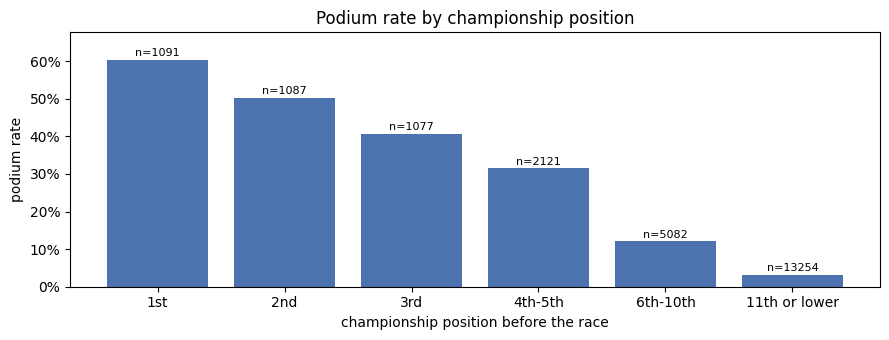

AUC of champ_pos: 0.840


In [252]:
g = fe[model_rows & fe.champ_pos.notna()]
levels = pd.cut(g.champ_pos, [0, 1, 2, 3, 5, 10, np.inf], labels=['1st', '2nd', '3rd', '4th-5th', '6th-10th', '11th or lower'])
by_pos = g.groupby(levels, observed=True).podium.agg(['size', 'mean'])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_pos.index.astype(str), by_pos['mean'], color='#4C72B0')
for i, (n, r) in enumerate(zip(by_pos['size'], by_pos['mean'])):
    ax.text(i, r + 0.01, f'n={n}', ha='center', fontsize=8)
ax.set_ylim(0, by_pos['mean'].max() * 1.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='championship position before the race', ylabel='podium rate', title='Podium rate by championship position')
plt.tight_layout(); plt.show()
print(f'AUC of champ_pos: {auc(-g.champ_pos, g.podium):.3f}')

**4c. Do the standings add anything once form is known?** Form and standings overlap, so drivers with the **same recent form** are compared by their championship position.

overlap of champ_pos and form_podium_rate: Spearman -0.75


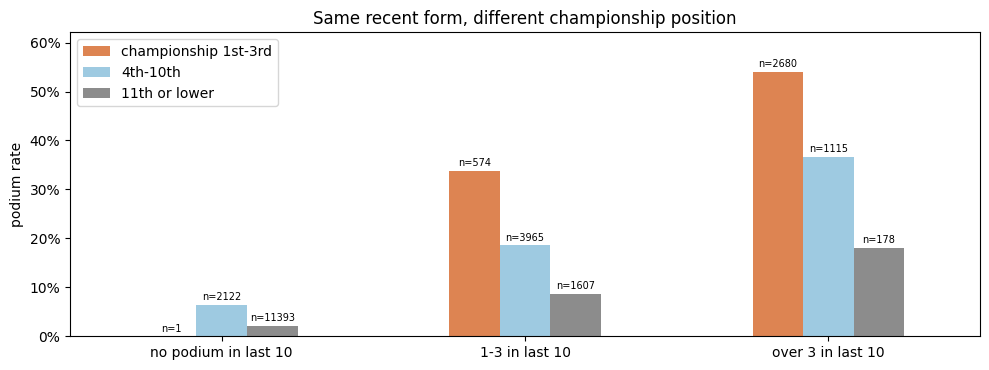

In [253]:
g = fe[model_rows & fe.champ_pos.notna() & fe.form_podium_rate.notna()]
print(f'overlap of champ_pos and form_podium_rate: Spearman {stats.spearmanr(g.champ_pos, g.form_podium_rate)[0]:.2f}')
form = pd.cut(g.form_podium_rate, [-0.01, 0, 0.3, 1], labels=['no podium in last 10', '1-3 in last 10', 'over 3 in last 10'])
pos = pd.cut(g.champ_pos, [0, 3, 10, np.inf], labels=['championship 1st-3rd', '4th-10th', '11th or lower'])
tab = g.groupby([form, pos], observed=True).podium.agg(starts='size', rate='mean').reset_index()
rates = tab.pivot(index='form_podium_rate', columns='champ_pos', values='rate')
sizes = tab.pivot(index='form_podium_rate', columns='champ_pos', values='starts')

fig, ax = plt.subplots(figsize=(10, 3.8))
rates.plot.bar(ax=ax, rot=0, color=['#DD8452', '#9ecae1', '#8C8C8C'])
for container, col in zip(ax.containers, rates.columns):
    ax.bar_label(container, labels=['' if pd.isna(n) else f'n={int(n)}' for n in sizes[col]], fontsize=7, padding=2)
ax.set_ylim(0, rates.max().max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='', ylabel='podium rate', title='Same recent form, different championship position')
ax.legend(title=''); plt.tight_layout(); plt.show()

**4d. Round 1: is last season's final position a good stand-in?** At round 1 there is no standing yet in the new season.

In [254]:
r1 = fe[model_rows & (fe['round'] == 1)]
print('round-1 starts:', len(r1), '| with last season\'s final position:', f'{r1.champ_pos.notna().mean():.0%}',
      f'| AUC of last season\'s final position at round 1: {auc(-r1.champ_pos, r1.podium):.3f}',
      f'| AUC of form at round 1: {auc(r1.form_podium_rate, r1.podium):.3f}')

round-1 starts: 1595 | with last season's final position: 84% | AUC of last season's final position at round 1: 0.803 | AUC of form at round 1: 0.790


### 5. Reading and decision

- **Coverage:** 96.5% of the model rows have a value: 88.2% from the previous round and 8.2% from last season's final position.
- **4a. Which number?** The championship position (AUC 0.842) and the points share (0.836) are about equally strong and say almost the same thing (Spearman −0.93), so only one is needed; the position is kept because it is simpler and comparable across eras without any conversion. The number of wins is clearly weaker (0.723, the win rate 0.724) and is already part of the points, so it is not used.
- **4b.** The championship position goes with the podium: 60.4% of the drivers leading the championship reach the podium, 50.1% in 2nd, 40.6% in 3rd, 31.5% in 4th–5th, 12.1% in 6th–10th and 3.1% from 11th or lower (AUC 0.840).
- **4c.** The standings overlap with form (Spearman −0.75) but add information: with the same recent form, a higher championship position still means more podiums. With 1–3 podiums in the last 10 starts, 33.8% of drivers in the top 3 of the championship reach the podium, against 18.6% in 4th–10th and 8.6% from 11th; with more than 3 it is 54.0%, 36.6% and 18.0%.
- **4d.** At round 1, last season's final position is available for 84% of the starts and works as a stand-in (AUC 0.803, slightly better than form at round 1, 0.790).

**Decision.** The standings group is `champ_pos`: the driver's championship position after the previous round, and at round 1 (or without a previous-round row) the final position of the previous season. The points share and the wins are not used. The 3.5% of model rows with no value (drivers in their first season with no previous-round row) are filled in preprocessing. The team's standings are left for the team group.

## 7.5 Team form

### 1. Hypothesis

Whether a driver reaches the podium depends mainly on two things: the driver and the car. Sections 7.3 and 7.4 describe the driver. This group describes the **car**: how strong the team has been recently, measured on both of its cars. It can differ from the driver's own record, for example for a new driver in a top team, or a driver whose own results suffered from bad luck while the teammate shows the car is fast.

### 2. Candidate features

Two ways of describing the team's strength:
- **The constructor standings** after the previous round: the team's championship `position`, or its **points share** (the team's points divided by the leader's points). As for the drivers, the number of wins is not tried again: it is part of the points.
- **Team form** (`team_form`): the share of the team's starts that ended on the podium over the team's last N races. Both cars of a race count, so a team with one podium from two cars in a race scores 50% for that race.

`constructor_results` (the team's points in each race) is not used as a separate source: its points are not comparable across eras, and the same races are already in `results`, where the team's points equal the sum of its drivers' points in about 97% of team-races (constructor_results section).

### 3. Valid at the cutoff

- **Only earlier races.** The constructor standings are taken from the previous round, like the driver standings. Team form looks at the team's races **before** the current one, ordered by `(year, round)`; both cars of a race enter the window together.
- **Renamed teams are separate constructors.** A new name usually comes with a new owner or a new car (constructors section, *is one constructorId one continuous team*), so each `constructorId` keeps its own history. A team's first races under a new name have no team form yet.
- **History restarts after a long break.** Some constructor ids cover separate periods, for example Mercedes in 1954–1955 and again from 2010 (constructors section). The team's history restarts after a break of five seasons or more, so Mercedes' first race in 2010 does not look back to 1955.
- Only real starts count (no `never_ran` rows and no Indianapolis 500), as for driver form.

In [255]:
team_races = (fe[model_rows].groupby(['constructorId', 'year', 'round', 'raceId'])
                .agg(cars=('podium', 'size'), podiums=('podium', 'sum')).reset_index()
                .sort_values(['constructorId', 'year', 'round']))
gap = team_races.year - team_races.groupby('constructorId').year.shift(1)           # seasons since the team's previous race
team_races['period'] = (gap >= 5).groupby(team_races.constructorId).cumsum()        # a new period after a 5-season break
by_team = team_races.groupby(['constructorId', 'period'])

def team_past(n):
    """Podiums per car start over the team's previous n races (the current race is excluded by shift)."""
    pods = by_team.podiums.transform(lambda s: s.shift(1).rolling(n, min_periods=1).sum())
    cars = by_team.cars.transform(lambda s: s.shift(1).rolling(n, min_periods=1).sum())
    return pods / cars

team_races['team_form'] = team_past(10)
fe = fe.drop(columns=['team_form'], errors='ignore')                                # safe to rerun
fe = fe.merge(team_races[['raceId', 'constructorId', 'team_form']], on=['raceId', 'constructorId'], how='left', validate='m:1')

# leakage and break check: Mercedes in 2010, its first races after the 1955 period
merc = constructors.loc[constructors.name == 'Mercedes', 'constructorId'].iloc[0]
table(team_races[(team_races.constructorId == merc) & (team_races.year == 2010)].head(4)
      [['year', 'round', 'cars', 'podiums', 'team_form']], pct=['team_form'],
      caption='Mercedes, 2010: no team form at its first race (history restarted), then only earlier races count')
print('team-races that start a new period after a break of 5+ seasons:', int((gap >= 5).sum()),
      '| model rows with team_form:', f'{fe.loc[model_rows, "team_form"].notna().mean():.1%}')

year,round,cars,podiums,team_form
2010,1,2,0,–
2010,2,2,0,0%
2010,3,2,1,0%
2010,4,2,1,17%


team-races that start a new period after a break of 5+ seasons: 22 | model rows with team_form: 98.8%


### 4. Evidence

**4a. Constructor standings or team form?** The candidates are compared with the AUC. Team form is tried for N = 5, 10 and 20 races.

In [256]:
cstand = constructor_standings[['raceId', 'constructorId', 'position', 'points']].merge(
    races[['raceId', 'year', 'round']], on='raceId', how='left', validate='m:1')
cstand['points_share'] = cstand.points / cstand.groupby('raceId').points.transform('max').replace(0, np.nan)
cbefore = cstand.assign(round=cstand['round'] + 1)[['year', 'round', 'constructorId', 'position', 'points_share']]

tc = fe[model_rows][['year', 'round', 'raceId', 'constructorId', 'podium']].merge(
    cbefore, on=['year', 'round', 'constructorId'], how='left', validate='m:1')
for n in [5, 10, 20]:
    tc = tc.merge(team_races.assign(**{f'form_{n}': team_past(n)})[['raceId', 'constructorId', f'form_{n}']],
                  on=['raceId', 'constructorId'], how='left', validate='m:1')
rows = [{'candidate': 'team championship position (previous round)', 'AUC': auc(-tc.position, tc.podium), 'has a value': tc.position.notna().mean()},
        {'candidate': 'team points share (previous round)', 'AUC': auc(tc.points_share, tc.podium), 'has a value': tc.points_share.notna().mean()}]
rows += [{'candidate': f'team form, last {n} races', 'AUC': auc(tc[f'form_{n}'], tc.podium), 'has a value': tc[f'form_{n}'].notna().mean()} for n in [5, 10, 20]]
display(pd.DataFrame(rows).style.format({'AUC': '{:.3f}', 'has a value': '{:.0%}'}).hide(axis='index')
        .set_caption('The team: which description? (AUC, model rows)'))
both = tc[['form_10', 'points_share']].dropna()
print(f'overlap of team form (10) and team points share: Spearman {stats.spearmanr(both.form_10, both.points_share)[0]:.2f}')

# why the championship table can mislead: McLaren 2007, excluded from the constructors' championship
mcl = constructors.loc[constructors.name == 'McLaren', 'constructorId'].iloc[0]
end07 = cstand[(cstand.year == 2007) & (cstand['round'] == cstand[cstand.year == 2007]['round'].max())].sort_values('points', ascending=False)
print('2007 final constructor table, by points:', ', '.join(f"{constructors.set_index('constructorId').name[c]} {p:.0f} pts (position {int(pos)})"
      for c, p, pos in zip(end07.constructorId.head(3), end07.points.head(3), end07.position.head(3))))

candidate,AUC,has a value
team championship position (previous round),0.834,88%
team points share (previous round),0.842,88%
"team form, last 5 races",0.833,99%
"team form, last 10 races",0.845,99%
"team form, last 20 races",0.845,99%


overlap of team form (10) and team points share: Spearman 0.83
2007 final constructor table, by points: McLaren 218 pts (position 11), Ferrari 204 pts (position 1), BMW Sauber 101 pts (position 2)


**4b. `team_form`: does a strong team go with the podium?** The podium rate by the team's podium rate over its previous 10 races.

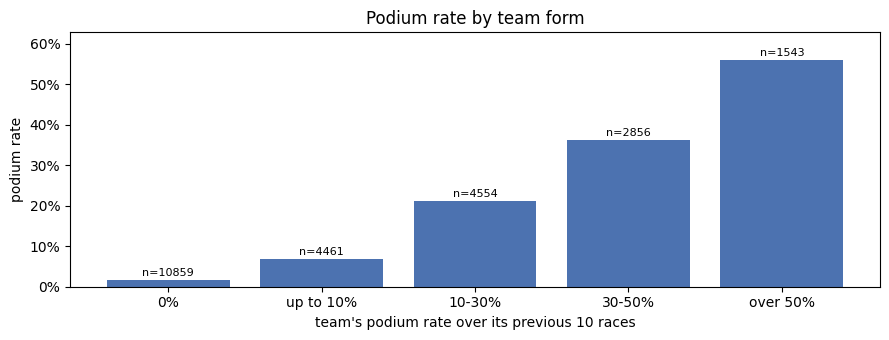

AUC of team_form: 0.845


In [257]:
g = fe[model_rows & fe.team_form.notna()]
levels = pd.cut(g.team_form, [-0.01, 0, 0.1, 0.3, 0.5, 1], labels=['0%', 'up to 10%', '10-30%', '30-50%', 'over 50%'])
by_team_form = g.groupby(levels, observed=True).podium.agg(['size', 'mean'])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_team_form.index.astype(str), by_team_form['mean'], color='#4C72B0')
for i, (n, r) in enumerate(zip(by_team_form['size'], by_team_form['mean'])):
    ax.text(i, r + 0.01, f'n={n}', ha='center', fontsize=8)
ax.set_ylim(0, by_team_form['mean'].max() * 1.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel="team's podium rate over its previous 10 races", ylabel='podium rate', title='Podium rate by team form')
plt.tight_layout(); plt.show()
print(f'AUC of team_form: {auc(g.team_form, g.podium):.3f}')

**4c. Does the team add anything once the driver's form is known?** Drivers with the **same recent form** are compared by the form of their team.

overlap of team_form and form_podium_rate: Spearman 0.79


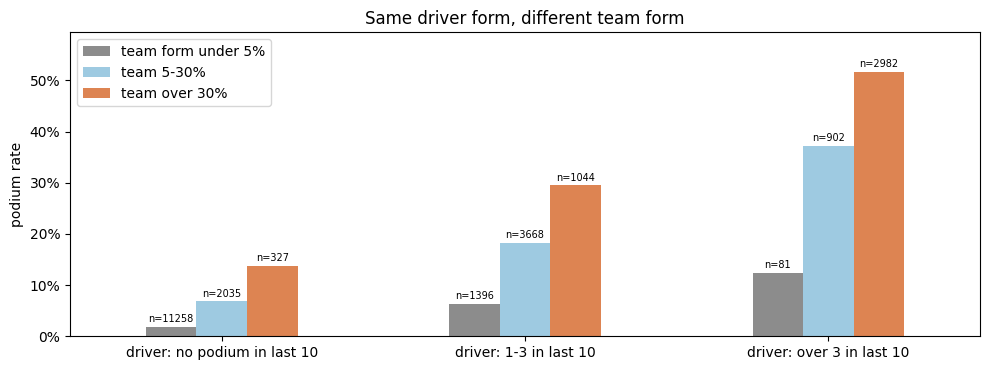

In [258]:
g = fe[model_rows & fe.team_form.notna() & fe.form_podium_rate.notna()]
print(f'overlap of team_form and form_podium_rate: Spearman {stats.spearmanr(g.team_form, g.form_podium_rate)[0]:.2f}')
dform = pd.cut(g.form_podium_rate, [-0.01, 0, 0.3, 1], labels=['driver: no podium in last 10', 'driver: 1-3 in last 10', 'driver: over 3 in last 10'])
tform = pd.cut(g.team_form, [-0.01, 0.05, 0.3, 1], labels=['team form under 5%', 'team 5-30%', 'team over 30%'])
tab = g.groupby([dform, tform], observed=True).podium.agg(starts='size', rate='mean').reset_index()
rates = tab.pivot(index='form_podium_rate', columns='team_form', values='rate')
sizes = tab.pivot(index='form_podium_rate', columns='team_form', values='starts')

fig, ax = plt.subplots(figsize=(10, 3.8))
rates.plot.bar(ax=ax, rot=0, color=['#8C8C8C', '#9ecae1', '#DD8452'])
for container, col in zip(ax.containers, rates.columns):
    ax.bar_label(container, labels=[f'n={n}' for n in sizes[col]], fontsize=7, padding=2)
ax.set_ylim(0, rates.max().max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='', ylabel='podium rate', title='Same driver form, different team form')
ax.legend(title=''); plt.tight_layout(); plt.show()

### 5. Reading and decision

- **Coverage:** 98.8% of the model rows have a team form value. The ones without are a team's first race (or its first race after a break of five seasons or more, which happens 22 times).
- **4a. Standings or form?** The team's points share (AUC 0.842) and its team form over the last 10 races (0.845) are about equally strong and say much the same thing (Spearman 0.83), so only one is kept. Team form is chosen because it is slightly stronger, it has a value for 99% of the model rows against 88% for the standings (it carries over from one season to the next, so round 1 needs no stand-in, and it exists before the constructor standings start in 1958), and it is built from race results, so it is not misled by the championship table. McLaren in 2007 shows why since it scored the most points of any team (218, ahead of Ferrari's 204) but was excluded from the constructors' championship, so the standings place it 11th and last. The window of 10 races is chosen because it is as strong as 20 (both 0.845) and stronger than 5 (0.833).
- **4b.** A strong team goes with the podium: 1.7% of drivers in a team with no podium in its last 10 races reach the podium, against 6.8% (up to 10%), 21.1% (10–30%), 36.1% (30–50%) and 56.1% (over 50%) (AUC 0.845).
- **4c.** The team adds information beyond the driver. Team form and driver form overlap (Spearman 0.79), but with the same driver form a stronger team still means more podiums: for drivers with no podium in their last 10 starts, 1.8% in a weak team against 13.8% in a strong one; with 1–3 podiums, 6.3% against 29.5%; with more than 3, 12.3% against 51.6%.

**Decision.** The team group is `team_form`, which is the share of the team's starts that ended on the podium over its previous 10 races, with each renamed team as its own constructor and the history restarting after a break of five seasons or more. The constructor standings are not used. The value is missing for a team's first race and is filled in preprocessing.

## 7.6 Reliability

### 1. Hypothesis

A car that breaks down cannot reach the podium, however fast it is. Team form (7.5) already contains some of this, because a car that broke did not score a podium, but the two are not the same: a fast but fragile car has a high podium rate when it finishes and often does not finish, while a slow but reliable car rarely breaks and rarely reaches the podium.

Reliability changed a lot over the years: in the 1980s cars broke down very often, and by 2024 almost never (Q3: from 12% of starts in 2014 to 3% in 2024). A failure rate of 10% means an unreliable car in 2024 but an average one in the 1980s, so the team's rate may need to be compared with the rest of the field at the time.

### 2. Candidate features

A **mechanical failure** is a start that ended in the `mechanical (clear)` group of the status grouping (status section, *grouping the labels for the mechanical-retirement question*), the same definition as Q3. The grey zone (for example `Retired` with no reason given) is not counted.
- **Team failure rate:** the share of the team's starts that ended in a mechanical failure over its last N races (both cars), tried for N = 5, 10 and 20.
- **Relative to the field:** the team's rate minus the failure rate of **all** cars over the last N races of the calendar.
- **Driver failure rate** over the driver's last 10 starts, raw and relative, and the **driver crash rate** (`accident or collision` group) over the last 10 starts.

### 3. Valid at the cutoff

- **Only earlier races.** Like team form, the windows look at races **before** the current one, ordered by `(year, round)`; the field's rate uses the previous races of the calendar. The way a race ended is only known afterwards, so the current race is never part of its own window.
- **The same team rules as team form:** renamed teams are separate constructors, and the history restarts after a break of five seasons or more.
- Only real starts count (no `never_ran` rows and no Indianapolis 500).

In [259]:
group_of_status = status.set_index('statusId').group
fe = fe.drop(columns=['statusId', 'mech', 'crash', 'team_mech_rel'], errors='ignore')     # safe to rerun
fe = fe.merge(results_unique[['resultId', 'statusId']], on='resultId', how='left', validate='1:1')
fe['mech'] = (fe.statusId.map(group_of_status) == 'mechanical (clear)').astype(int)           # outcome of the race: never a feature
fe['crash'] = (fe.statusId.map(group_of_status) == 'accident or collision').astype(int)

starts = fe[model_rows]
team_rel = (starts.groupby(['constructorId', 'year', 'round', 'raceId'])
                  .agg(cars=('mech', 'size'), fails=('mech', 'sum')).reset_index()
                  .sort_values(['constructorId', 'year', 'round']))
team_gap = team_rel.year - team_rel.groupby('constructorId').year.shift(1)
team_rel['period'] = (team_gap >= 5).groupby(team_rel.constructorId).cumsum()       # same restart rule as team form
by_team_rel = team_rel.groupby(['constructorId', 'period'])

field = (starts.groupby(['year', 'round', 'raceId']).agg(cars=('mech', 'size'), fails=('mech', 'sum'))
               .reset_index().sort_values(['year', 'round']))

def team_fail(n):
    """Mechanical failures per car start over the team's previous n races."""
    f = by_team_rel.fails.transform(lambda s: s.shift(1).rolling(n, min_periods=1).sum())
    c = by_team_rel.cars.transform(lambda s: s.shift(1).rolling(n, min_periods=1).sum())
    return f / c

def field_fail(n):
    """Mechanical failures per car start over all cars in the previous n races of the calendar."""
    return (field.fails.shift(1).rolling(n, min_periods=1).sum() / field.cars.shift(1).rolling(n, min_periods=1).sum())

team_rel = team_rel.merge(field.assign(field_20=field_fail(20))[['raceId', 'field_20']], on='raceId', how='left')
team_rel['team_20'] = team_fail(20)
team_rel['team_mech_rel'] = team_rel.team_20 - team_rel.field_20
fe = fe.merge(team_rel[['raceId', 'constructorId', 'team_mech_rel']], on=['raceId', 'constructorId'], how='left', validate='m:1')

# example: McLaren at the start of 2016; its previous 20 races cover the 2015 season
mcl = constructors.loc[constructors.name == 'McLaren', 'constructorId'].iloc[0]
table(team_rel[(team_rel.constructorId == mcl) & (team_rel.year == 2016)].head(4)
      [['year', 'round', 'cars', 'fails', 'team_20', 'field_20', 'team_mech_rel']],
      pct1=['team_20', 'field_20', 'team_mech_rel'],
      caption='McLaren, start of 2016: its failure rate over the previous 20 races (mostly 2015) against the field (positive = fails more often)')
print('model rows with team_mech_rel:', f'{fe.loc[model_rows, "team_mech_rel"].notna().mean():.1%}')

year,round,cars,fails,team_20,field_20,team_mech_rel
2016,1,2,0,18.4%,9.5%,9.0%
2016,2,2,1,18.4%,9.7%,8.7%
2016,3,2,0,20.5%,9.3%,11.2%
2016,4,2,0,15.4%,8.8%,6.6%


model rows with team_mech_rel: 98.8%


### 4. Evidence

**4a. Which version?** The candidates are compared with the AUC. A failure rate is better when it is **lower**, so the rates are entered with a minus sign.

In [260]:
tc = fe[model_rows][['raceId', 'constructorId', 'driverId', 'year', 'round', 'podium', 'mech', 'crash']]
for n in [5, 10, 20]:
    t = team_rel[['raceId', 'constructorId']].assign(**{f'team_{n}': team_fail(n)})
    t = t.merge(field.assign(**{f'field_{n}': field_fail(n)})[['raceId', f'field_{n}']], on='raceId')
    tc = tc.merge(t, on=['raceId', 'constructorId'], how='left', validate='m:1')
tc = tc.sort_values(['driverId', 'year', 'round'])
by_drv = tc.groupby('driverId')
tc['driver_10'] = by_drv.mech.transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())
tc['crash_10'] = by_drv.crash.transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())

rows = [{'candidate': f'team failure rate, last {n} races', 'AUC raw': auc(-tc[f'team_{n}'], tc.podium),
         'AUC relative to the field': auc(-(tc[f'team_{n}'] - tc[f'field_{n}']), tc.podium)} for n in [5, 10, 20]]
rows += [{'candidate': 'driver failure rate, last 10 starts', 'AUC raw': auc(-tc.driver_10, tc.podium),
          'AUC relative to the field': auc(-(tc.driver_10 - tc.field_10), tc.podium)},
         {'candidate': 'driver crash rate, last 10 starts', 'AUC raw': auc(-tc.crash_10, tc.podium), 'AUC relative to the field': np.nan}]
display(pd.DataFrame(rows).style.format({'AUC raw': '{:.3f}', 'AUC relative to the field': '{:.3f}'}, na_rep='–')
        .hide(axis='index').set_caption('Reliability: which version? (AUC, model rows)'))
both = tc[['team_10', 'driver_10']].dropna()
print(f'overlap of the team and the driver failure rate (last 10): Spearman {stats.spearmanr(both.team_10, both.driver_10)[0]:.2f}')

candidate,AUC raw,AUC relative to the field
"team failure rate, last 5 races",0.605,0.632
"team failure rate, last 10 races",0.610,0.653
"team failure rate, last 20 races",0.614,0.669
"driver failure rate, last 10 starts",0.589,0.616
"driver crash rate, last 10 starts",0.569,–


overlap of the team and the driver failure rate (last 10): Spearman 0.76


**4b. `team_mech_rel`: do teams that break down more often than the field reach the podium less?** The podium rate by the team's failure rate relative to the field (last 20 races).

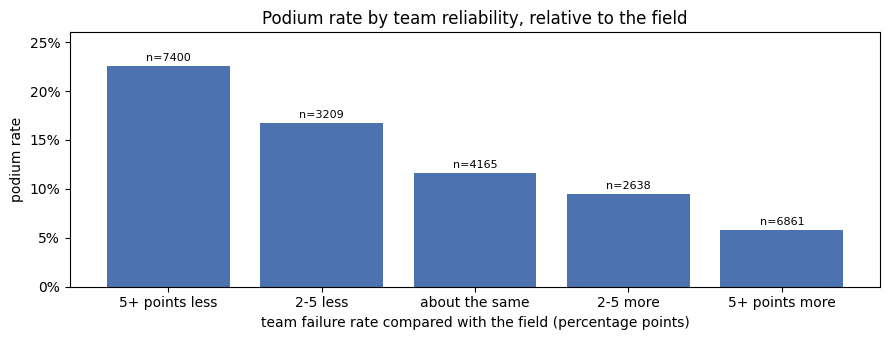

AUC of team_mech_rel: 0.669


In [261]:
g = fe[model_rows & fe.team_mech_rel.notna()]
levels = pd.cut(g.team_mech_rel, [-1, -0.05, -0.02, 0.02, 0.05, 1],
                labels=['5+ points less', '2-5 less', 'about the same', '2-5 more', '5+ points more'])
by_rel = g.groupby(levels, observed=True).podium.agg(['size', 'mean'])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_rel.index.astype(str), by_rel['mean'], color='#4C72B0')
for i, (n, r) in enumerate(zip(by_rel['size'], by_rel['mean'])):
    ax.text(i, r + 0.005, f'n={n}', ha='center', fontsize=8)
ax.set_ylim(0, by_rel['mean'].max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='team failure rate compared with the field (percentage points)', ylabel='podium rate',
       title='Podium rate by team reliability, relative to the field')
plt.tight_layout(); plt.show()
print(f'AUC of team_mech_rel: {auc(-g.team_mech_rel, g.podium):.3f}')

**4c. Does reliability add anything once team form is known?** Teams with the **same team form** are compared by their reliability.

overlap of team_mech_rel and team_form: Spearman -0.40


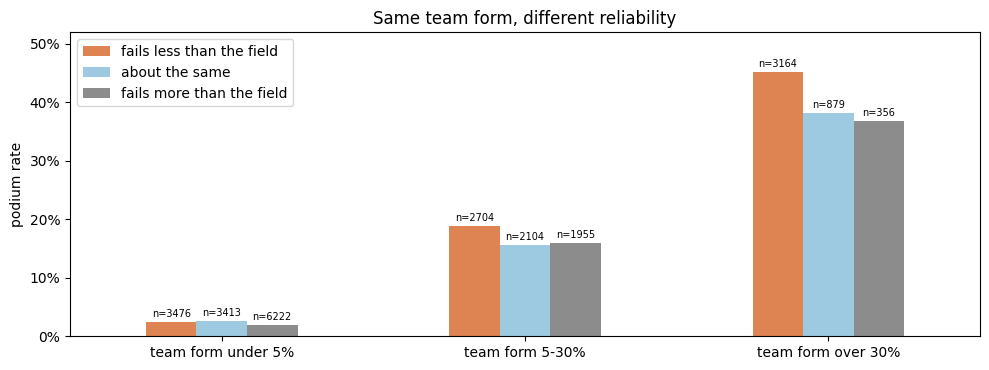

In [262]:
g = fe[model_rows & fe.team_mech_rel.notna() & fe.team_form.notna()]
print(f'overlap of team_mech_rel and team_form: Spearman {stats.spearmanr(g.team_mech_rel, g.team_form)[0]:.2f}')
tform = pd.cut(g.team_form, [-0.01, 0.05, 0.3, 1], labels=['team form under 5%', 'team form 5-30%', 'team form over 30%'])
rel = pd.cut(g.team_mech_rel, [-1, -0.03, 0.03, 1], labels=['fails less than the field', 'about the same', 'fails more than the field'])
tab = g.groupby([tform, rel], observed=True).podium.agg(starts='size', rate='mean').reset_index()
rates = tab.pivot(index='team_form', columns='team_mech_rel', values='rate')
sizes = tab.pivot(index='team_form', columns='team_mech_rel', values='starts')

fig, ax = plt.subplots(figsize=(10, 3.8))
rates.plot.bar(ax=ax, rot=0, color=['#DD8452', '#9ecae1', '#8C8C8C'])
for container, col in zip(ax.containers, rates.columns):
    ax.bar_label(container, labels=[f'n={n}' for n in sizes[col]], fontsize=7, padding=2)
ax.set_ylim(0, rates.max().max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='', ylabel='podium rate', title='Same team form, different reliability')
ax.legend(title=''); plt.tight_layout(); plt.show()

### 5. Reading and decision

- **Coverage:** 98.8% of the model rows have a value; the others are a team's first race (or its first race after a long break).
- **4a. Which version?** Reliability is much weaker on its own than the other groups (AUC about 0.6–0.67 against 0.84 for team form): a breakdown is only one of many ways to miss the podium. Comparing the team with the field always helps (0.653 against 0.610 at N = 10), which confirms that raw failure rates mean different things in different eras. The longest window is the strongest (0.669 for 20 races), because failures are rare and a short window holds only a few of them. The driver's own failure rate is weaker (0.616 relative) and mostly repeats the team's (Spearman 0.76), and the crash rate is weak (0.569), so the driver-level versions are not used.
- **4b.** Teams that break down less than the field reach the podium more often: 22.6% when the team fails at least 5 percentage points less often than the field, 11.6% when it is about the same, and 5.8% when it fails at least 5 points more often (AUC 0.669).
- **4c.** Reliability overlaps only partly with team form (Spearman −0.40) and adds a little for the stronger teams: with team form over 30%, 45.2% of drivers in a team that fails less than the field reach the podium, against 36.8% in a team that fails more; with team form of 5–30%, 18.9% against 15.9%. For weak teams it makes no difference (2.5% against 2.0%).

**Decision.** The reliability group is `team_mech_rel`: the team's mechanical-failure rate over its previous 20 races minus the failure rate of all cars over the previous 20 races of the calendar, with the same team rules as team form. It is weak on its own and adds only a little beyond team form, so the ablation will show whether it is worth keeping in the model. The value is missing for a team's first race and is filled in preprocessing. The columns `mech` and `crash` describe how the race ended and are only used to build this feature; they are never model inputs.

## 7.7 Circuit history (tested, not used)

### 1. Hypothesis

Some drivers suit some circuits. A driver who has reached the podium at a circuit before may do so again there, beyond what their general form says.

### 2. Candidate features

The driver's record at **this circuit** in their previous visits: the podium rate over all past visits, the podium rate over the last 3 visits, the finishing position at the last visit, and whether the last visit ended on the podium.

### 3. Valid at the cutoff

Only the driver's earlier starts at the same circuit (`circuitId`) count, ordered by `(year, round)`; the race itself is never included. Only real starts count, as for driver form. A driver's first visit to a circuit has no history.

### 4. Evidence

In [263]:
ch = fe[model_rows][['driverId', 'circuitId', 'year', 'round', 'podium', 'positionOrder', 'form_podium_rate']].sort_values(['driverId', 'year', 'round'])
by_visit = ch.groupby(['driverId', 'circuitId'])
ch['rate_all'] = by_visit.podium.transform(lambda s: s.shift(1).expanding().mean())
ch['rate_last3'] = by_visit.podium.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
ch['last_finish'] = by_visit.positionOrder.shift(1)
ch['last_podium'] = by_visit.podium.shift(1)

display(pd.DataFrame([
    {'candidate': 'podium rate here, all past visits', 'AUC': auc(ch.rate_all, ch.podium)},
    {'candidate': 'podium rate here, last 3 visits', 'AUC': auc(ch.rate_last3, ch.podium)},
    {'candidate': 'finishing position last time here', 'AUC': auc(-ch.last_finish, ch.podium)},     # minus: a smaller position is better
    {'candidate': 'podium last time here', 'AUC': auc(ch.last_podium, ch.podium)},
]).style.format({'AUC': '{:.3f}'}).hide(axis='index').set_caption('Circuit history: which version? (AUC, rows with a past visit)'))
both = ch[['rate_all', 'form_podium_rate']].dropna()
print(f"model rows with a past visit to the circuit: {ch.last_finish.notna().mean():.0%} | "
      f"overlap with driver form: Spearman {stats.spearmanr(both.rate_all, both.form_podium_rate)[0]:.2f}")

# does it add anything once driver form is known?
g = ch.dropna(subset=['rate_all', 'form_podium_rate'])
form = pd.cut(g.form_podium_rate, [-0.01, 0, 0.3, 1], labels=['no podium in last 10', '1-3 in last 10', 'over 3 in last 10'])
here = pd.cut(g.rate_all, [-0.01, 0, 0.5, 1], labels=['never on the podium here', 'up to half the visits', 'over half the visits'])
tab = g.groupby([form, here], observed=True).podium.mean().unstack()
display(tab.rename_axis(index='driver form', columns='podium rate at this circuit before')
           .style.format('{:.1%}').set_caption('Podium rate: same driver form, different record at this circuit'))

candidate,AUC
"podium rate here, all past visits",0.672
"podium rate here, last 3 visits",0.670
finishing position last time here,0.656
podium last time here,0.623


model rows with a past visit to the circuit: 70% | overlap with driver form: Spearman 0.45


podium rate at this circuit before,never on the podium here,up to half the visits,over half the visits
driver form,,,
no podium in last 10,3.0%,4.5%,7.4%
1-3 in last 10,15.6%,21.0%,25.1%
over 3 in last 10,41.4%,48.9%,53.5%


### 5. Reading and decision

- The podium rate over all past visits is the strongest version (AUC 0.672); the last result alone is noisier (0.656 for the finishing position, 0.623 for the podium), because a single race can end in a crash or a breakdown.
- It is much weaker than the main groups (driver form 0.838), and only 70% of the model rows have a past visit to the circuit: every first visit is missing.
- It overlaps only partly with driver form (Spearman 0.45) and adds a little beyond it: with more than 3 podiums in the last 10 starts, drivers who were on the podium in over half their visits to the circuit reach it 53.5% of the time, against 41.4% for drivers who never were.

**Decision.** Circuit history is **not used**. Its gain beyond driver form is small, and it would leave 30% of the rows to be filled in preprocessing. Reliability (7.6) is about as strong on its own but is kept, because it describes the team, which matters more for the podium than the circuit, and it has a value for 99% of the rows. The trial is kept here, as the brief asks.

## 7.8 Pace

### 1. Hypothesis

Driver form and team form only see how a race ended: a podium or not. A driver who was fast but crashed or broke down scores nothing there. Lap times show the **speed** in every race, also in races that ended badly, so a driver's recent race pace may add something the result-based features miss.

### 2. Candidate feature

`pace_form`: the driver's typical lap in each race, compared with the rest of the field, averaged over the previous 10 starts. The typical lap of a driver in a race is the **median** of their relative lap times, where each lap is divided by the median lap of that race (lap_times section, *extreme laps and why circuits cannot be compared*). The median ignores the few laps slowed by a pit stop, lap 1 or a red flag. Below 1 means faster than the typical lap of the race.

### 3. Valid at the cutoff

- Only the driver's **earlier** starts count, ordered by `(year, round)`; the race itself is never included.
- Dividing by the median lap of the same race compares the driver with the same cars, track and weather, so races at different circuits become comparable.
- The 19 driver-races flagged `laps_mismatch` in cleaning are skipped.
- **A race only counts if the driver completed at least 10 laps.** With only 1 or 2 laps, the "typical lap" is just lap 1 (a standing start) or a lap with a red flag, so the value is meaningless. For example, Stroll retired after 2 laps at Bahrain 2020, and one of them included the 22-minute stop after Grosjean's fire; his race pace came out as 7.8, nearly 8 times the typical lap. The next code cell shows how the race pace depends on the number of laps completed.
- **Coverage:** lap times only exist from 1996, so the feature is missing before that.

In [264]:
MIN_LAPS = 10                                                            # fewer laps: no typical lap to measure
per_race = (laps[~laps.laps_mismatch].groupby(['raceId', 'driverId'])
                .agg(laps_done=('relative', 'size'), race_pace=('relative', 'median')).reset_index())

# why the minimum: with few laps the median is lap 1 or a red-flag lap
by_laps = pd.cut(per_race.laps_done, [0, 2, 4, 9, 19, np.inf], labels=['1-2', '3-4', '5-9', '10-19', '20 or more'])
display(per_race.groupby(by_laps, observed=True).race_pace.describe(percentiles=[0.5, 0.99])[['count', '50%', '99%', 'max']]
        .rename(columns={'count': 'driver-races', '50%': 'median', '99%': 'worst 1%'}).rename_axis('laps completed')
        .style.format('{:.2f}').format('{:.0f}', subset=['driver-races']).set_caption('Race pace by the number of laps completed'))
print(f'driver-races with fewer than {MIN_LAPS} laps, not used:', int((per_race.laps_done < MIN_LAPS).sum()), 'of', len(per_race))

race_pace = per_race.loc[per_race.laps_done >= MIN_LAPS, ['raceId', 'driverId', 'race_pace']]   # the driver's typical relative lap in a race
fe = fe.drop(columns=['race_pace', 'pace_form'], errors='ignore')        # safe to rerun
fe = fe.merge(race_pace, on=['raceId', 'driverId'], how='left', validate='1:1')    # outcome of the race: never a feature

hist = fe[model_rows].sort_values(['driverId', 'year', 'round'])
fe.loc[hist.index, 'pace_form'] = (hist.groupby('driverId').race_pace
                                       .transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean()))

g = fe[model_rows]
print('model rows with pace_form:', f'{g.pace_form.notna().mean():.0%}',
      '| from 1997 on:', f'{g[g.year >= 1997].pace_form.notna().mean():.0%}',
      '| before 1996:', f'{g[g.year < 1996].pace_form.notna().mean():.0%}')

,driver-races,median,worst 1%,max
laps completed,,,,
1-2,173,1.17,4.41,7.78
3-4,60,1.08,1.93,2.27
5-9,235,1.03,1.61,1.70
10-19,376,1.02,1.46,1.68
20 or more,10178,1.00,1.05,1.35


driver-races with fewer than 10 laps, not used: 468 of 11022


model rows with pace_form: 46% | from 1997 on: 99% | before 1996: 0%


### 4. Evidence

**4a. Strength and overlap.** The AUC on the rows that have a pace value (from 1996), next to driver form and team form on the same rows. A smaller pace value is faster, so it is entered with a minus sign.

In [265]:
g = fe[model_rows & fe.pace_form.notna()]
print(f'AUC on these rows: pace_form {auc(-g.pace_form, g.podium):.3f} | form_podium_rate {auc(g.form_podium_rate, g.podium):.3f} '
      f'| team_form {auc(g.team_form, g.podium):.3f}')
for col in ['form_podium_rate', 'team_form']:
    both = g[['pace_form', col]].dropna()
    print(f'overlap of pace_form and {col}: Spearman {stats.spearmanr(both.pace_form, both[col])[0]:.2f}')

AUC on these rows: pace_form 0.858 | form_podium_rate 0.872 | team_form 0.881
overlap of pace_form and form_podium_rate: Spearman -0.74
overlap of pace_form and team_form: Spearman -0.74


**4b. Does pace add anything once driver form and team form are known?** The drivers are split into three groups by their form and their team's form; inside each group they are split into thirds by their past pace.

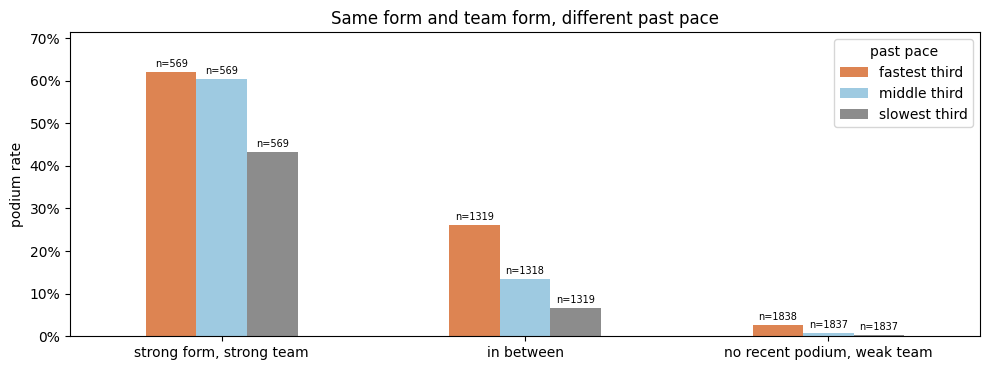

pace,fastest third,middle third,slowest third
group,,,
"strong form, strong team",62.0%,60.5%,43.2%
in between,26.1%,13.5%,6.7%
"no recent podium, weak team",2.7%,0.8%,0.4%


In [266]:
g = fe[model_rows].dropna(subset=['pace_form', 'form_podium_rate', 'team_form'])
grp = np.select([(g.form_podium_rate > 0.3) & (g.team_form > 0.3), (g.form_podium_rate == 0) & (g.team_form < 0.05)],
                ['strong form, strong team', 'no recent podium, weak team'], default='in between')
third = g.groupby(grp).pace_form.transform(lambda s: pd.qcut(s, 3, labels=['fastest third', 'middle third', 'slowest third']))
tab = g.assign(group=grp, pace=third).groupby(['group', 'pace'], observed=True).podium.agg(starts='size', rate='mean').reset_index()
rates = tab.pivot(index='group', columns='pace', values='rate').loc[['strong form, strong team', 'in between', 'no recent podium, weak team']]
sizes = tab.pivot(index='group', columns='pace', values='starts').loc[rates.index]

fig, ax = plt.subplots(figsize=(10, 3.8))
rates.plot.bar(ax=ax, rot=0, color=['#DD8452', '#9ecae1', '#8C8C8C'])
for container, col in zip(ax.containers, rates.columns):
    ax.bar_label(container, labels=[f'n={n}' for n in sizes[col]], fontsize=7, padding=2)
ax.set_ylim(0, rates.max().max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='', ylabel='podium rate', title='Same form and team form, different past pace')
ax.legend(title='past pace'); plt.tight_layout(); plt.show()
display(rates.style.format('{:.1%}').set_caption('Podium rate by group and past pace'))

### 5. Reading and decision

- **Coverage:** 46% of all model rows have a pace value, because lap times start in 1996; from 1997 on, 99% have one.
- **4a.** On the rows that have it, pace is strong on its own (AUC 0.858; driver form 0.872 and team form 0.881 on the same rows) and overlaps with both only partly (Spearman −0.74 with each).
- **4b.** Pace adds clear information beyond driver form and team form. Among drivers in strong form in a strong team, the fastest third reach the podium 62.0% of the time against 43.2% for the slowest third; in the middle group it is 26.1% against 6.7%. Pace shows how fast a driver was even in races that ended in a crash or a breakdown, which the result-based features cannot see.

**Decision.** `pace_form` is kept as a **candidate**. It is strong and adds information, but it only exists from 1996, so whether it stays depends on the training seasons chosen with the split: if training starts in 1997 or later, it has a value for almost every row; if it starts earlier, it would be missing for most of the older seasons. The column `race_pace` describes the race itself and is only used to build this feature; it is never a model input.

## 7.9 Sprints (tested, not used)

**Hypothesis.** On a sprint weekend, the result of the Saturday sprint shows how fast a car is in race conditions, one day before the race.

**What the data allows.** There are 18 sprint weekends, from 2021 to 2024 (sprint_results section). In 2021 and 2022 the sprint result **set** the Sunday grid, so on those weekends the grid already contains it. From 2023 the Sunday grid comes from the normal qualifying, so only the 12 sprint weekends of 2023–2024 can show whether the sprint adds anything beyond the grid. The sprint is held the day before the race, so it would be valid at the cutoff.

In [267]:
spr = sprint_results[['raceId', 'driverId', 'positionOrder']].rename(columns={'positionOrder': 'sprint_pos'})
sw = fe[model_rows].merge(spr, on=['raceId', 'driverId'], how='left', validate='1:1')
print(f'model rows with a sprint result: {sw.sprint_pos.notna().mean():.1%}')

a = sw[sw.sprint_pos.notna() & sw.year.between(2021, 2022)]
print(f'2021-2022 (the sprint set the grid): Spearman correlation between sprint position and Sunday grid {stats.spearmanr(a.sprint_pos, a.grid_clean)[0]:.2f}')

b = sw[sw.sprint_pos.notna() & (sw.year >= 2023)]
print(f'2023-2024: {len(b)} starts, {int(b.podium.sum())} podiums | Spearman sprint position vs grid {stats.spearmanr(b.sprint_pos, b.grid_clean)[0]:.2f}')
area = pd.cut(b.grid_clean, [0, 3, 10, np.inf], labels=['starts P1-3', 'starts P4-10', 'starts P11 or further back'])
sprint = pd.Series(np.where(b.sprint_pos <= 3, 'sprint top 3', 'sprint 4th or lower'), index=b.index, name='sprint result')
table(b.groupby([area.rename('starting area'), sprint], observed=True).podium.agg(starts='size', podium_rate='mean')
       .reset_index().rename(columns={'podium_rate': 'podium rate'}),
      pct=['podium rate'], caption='2023-2024 sprint weekends: same starting area, different sprint result')

model rows with a sprint result: 1.4%
2021-2022 (the sprint set the grid): Spearman correlation between sprint position and Sunday grid 0.93
2023-2024: 236 starts, 36 podiums | Spearman sprint position vs grid 0.59


starting area,sprint result,starts,podium rate
starts P1-3,sprint 4th or lower,14,43%
starts P1-3,sprint top 3,21,57%
starts P4-10,sprint 4th or lower,70,11%
starts P4-10,sprint top 3,12,58%
starts P11 or further back,sprint 4th or lower,116,2%
starts P11 or further back,sprint top 3,3,33%


**Reading and decision.**
- Only 1.4% of the model rows have a sprint result.
- In 2021–2022 the sprint position and the Sunday grid are almost the same (Spearman 0.93), because the sprint set the grid.
- In 2023–2024 the sprint is separate from the grid (Spearman 0.59). The table suggests it may add something: from P4–10, drivers who finished the sprint in the top 3 reached the podium 58% of the time, against 11% for the others. But there are only 236 starts and 36 podiums, and the groups with a sprint top 3 hold between 3 and 21 drivers, so this cannot be relied on.

The sprint result is **not used**: in 2021–2022 it is the grid itself, from 2023 there are far too few sprint weekends to measure its effect, and it would be missing for 98.6% of the rows.

## 7.10 Summary of the features

The table lists every feature that goes forward, with the evidence behind it. The AUC is measured on the model rows that have a value (`grid_minus_quali` only helps together with `grid_clean`, see 7.2). Features that were tested and not used: `pit_lane_start`, `quali_pos`, the average finish, the standings points share and wins, the constructor standings, the driver-level reliability rates, circuit history and the sprint result.

In [268]:
FEATURES = {
    'grid_clean':       ('grid',             'starting slot, pit-lane starters at the back',          'the grid is fixed before the start', -1),
    'grid_minus_quali': ('qualifying',       'grid slot minus qualifying position',                  'qualifying is before the race', 1),
    'quali_gap_pct':    ('qualifying',       'gap to the fastest Q1 lap, in %',                       'qualifying is before the race', -1),
    'form_podium_rate': ('driver form',      'podium rate over the previous 10 starts',               'earlier starts only', 1),
    'career_starts':    ('driver form',      'starts before this race',                               'earlier starts only', 1),
    'champ_pos':        ('driver standings', 'championship position after the previous round',        'previous round; round 1: last season', -1),
    'team_form':        ('team form',        "team's podium rate over its previous 10 races",         'earlier races only', 1),
    'team_mech_rel':    ('reliability',      "team's failure rate minus the field's, previous 20 races", 'earlier races only', -1),
    'pace_form':        ('pace (candidate)', 'relative lap pace over the previous 10 starts',         'earlier starts only', -1),
}
g = fe[model_rows]
display(pd.DataFrame([{'group': grp, 'feature': f, 'what it is': what, 'why valid before the race': why,
                       'AUC': auc(sign * g[f].astype(float), g.podium), 'has a value': g[f].notna().mean()}
                      for f, (grp, what, why, sign) in FEATURES.items()])
        .style.format({'AUC': '{:.3f}', 'has a value': '{:.0%}'}).hide(axis='index').set_caption('The features that go forward'))

group,feature,what it is,why valid before the race,AUC,has a value
grid,grid_clean,"starting slot, pit-lane starters at the back",the grid is fixed before the start,0.885,100%
qualifying,grid_minus_quali,grid slot minus qualifying position,qualifying is before the race,0.542,42%
qualifying,quali_gap_pct,"gap to the fastest Q1 lap, in %",qualifying is before the race,0.825,42%
driver form,form_podium_rate,podium rate over the previous 10 starts,earlier starts only,0.838,97%
driver form,career_starts,starts before this race,earlier starts only,0.659,100%
driver standings,champ_pos,championship position after the previous round,previous round; round 1: last season,0.840,96%
team form,team_form,team's podium rate over its previous 10 races,earlier races only,0.845,99%
reliability,team_mech_rel,"team's failure rate minus the field's, previous 20 races",earlier races only,0.669,99%
pace (candidate),pace_form,relative lap pace over the previous 10 starts,earlier starts only,0.858,46%


**How each feature is calculated.** "Previous" always means races before the one being predicted, ordered by season and round. The current race is left out with `shift(1)`, so no value uses the race's own result. All history features count real starts only (the model rows).

- **`grid_clean`** (7.1): the grid slot from `results`. Pit-lane starters (`grid` = 0 but laps run) are put at the back: the highest grid slot of that race + 1.
- **`grid_minus_quali`** (7.2): `grid_clean` − qualifying position. 0 = started where they qualified; positive = moved back (penalty or pit-lane start); negative = moved up. Missing when there is no qualifying row.
- **`quali_gap_pct`** (7.2): (driver's Q1 time ÷ fastest Q1 time of that race − 1) × 100. 0 = fastest in Q1; 1.5 = 1.5% slower. Missing when there is no qualifying row or no Q1 time.
- **`form_podium_rate`** (7.3): podiums ÷ starts over the driver's previous 10 starts (fewer if the driver has made fewer than 10). Example: 3 podiums in the last 10 starts = 30%. Missing at a driver's first start.
- **`career_starts`** (7.3): the number of starts the driver made before this race. 0 at the first start, never missing.
- **`champ_pos`** (7.4): the driver's championship position after the previous round of the same season (from `driver_standings`). At round 1, or if the driver has no standing yet, the final position of last season is used. Missing for a driver with neither (usually a new driver early in their first season).
- **`team_form`** (7.5): podiums ÷ car starts of the team over its previous 10 races. Example: 5 podiums from 20 car starts = 25%. If the team was away for 5 or more seasons, its history starts again. Missing at the team's first race.
- **`team_mech_rel`** (7.6): team failure rate − field failure rate, both over the previous 20 races. The team rate is clear mechanical failures ÷ the team's car starts; the field rate is the same for all cars. Example: team 7.5%, field 6.0% → +1.5 points, so the team breaks down more than normal for its time. Same restart rule as `team_form`. Missing at the team's first race.
- **`pace_form`** (7.8, candidate): every lap time is divided by the median lap time of its race (1.00 = a typical lap). The driver's pace in a race is the median of their relative laps; `pace_form` is the mean of that over the driver's previous 10 starts. Lower = faster. Missing before 1996 (no lap times) and at a driver's first start.

### Which seasons each feature covers

The chart shows, for every season, the share of the model rows that have a value for each feature (dark = complete). The table gives the first season from which each feature stays complete (at least 95% of the rows in every later season). This is what limits the first season of the training data.

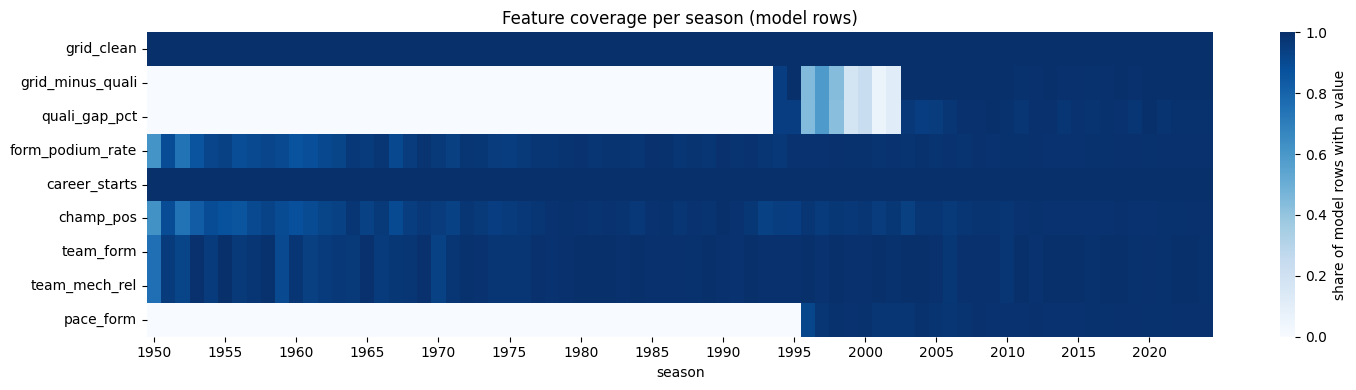

feature,group,complete from (95%+ every later season)
grid_clean,grid,1950
grid_minus_quali,qualifying,2003
quali_gap_pct,qualifying,2005
form_podium_rate,driver form,1976
career_starts,driver form,1950
champ_pos,driver standings,2004
team_form,team form,1971
team_mech_rel,reliability,1971
pace_form,pace (candidate),1997


year,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007
grid_minus_quali,94%,100%,45%,59%,43%,18%,24%,6%,12%,100%,100%,100%,100%,100%
quali_gap_pct,94%,94%,44%,59%,43%,18%,24%,6%,12%,97%,94%,95%,98%,99%
champ_pos,95%,94%,98%,95%,97%,97%,98%,95%,97%,94%,98%,98%,96%,98%
pace_form,0%,0%,91%,98%,99%,99%,99%,98%,98%,97%,99%,98%,98%,98%


In [269]:
cov = g.groupby('year')[list(FEATURES)].apply(lambda d: d.notna().mean()).T

fig, ax = plt.subplots(figsize=(15, 4))
sns.heatmap(cov, cmap='Blues', vmin=0, vmax=1, xticklabels=5, cbar_kws={'label': 'share of model rows with a value'}, ax=ax)
ax.set(xlabel='season', ylabel='', title='Feature coverage per season (model rows)')
plt.tight_layout(); plt.show()

def complete_from(row, level=0.95):
    """First season from which the coverage stays at or above `level` in every later season."""
    ok = row >= level
    later_all_ok = ok[::-1].cummin()[::-1]
    return int(later_all_ok.idxmax()) if later_all_ok.any() else None

table(pd.DataFrame({'feature': cov.index, 'group': [FEATURES[f][0] for f in cov.index],
                    'complete from (95%+ every later season)': [complete_from(cov.loc[f]) for f in cov.index]}),
      caption='First season each feature is complete')

display(cov.loc[['grid_minus_quali', 'quali_gap_pct', 'champ_pos', 'pace_form'], 1994:2007]
        .style.format('{:.0%}').set_caption('Coverage of the late-starting features around the possible start seasons'))

**Reading: which seasons have problems.**
- **No problem at any time:** `grid_clean`, `career_starts`, `team_form` and `team_mech_rel` (complete from 1950–1971; the team features only miss a team's first race).
- **`form_podium_rate`:** complete from 1976. Before that, many drivers made only a few starts, so many rows are debuts with no form.
- **`pace_form`:** no lap times before 1996, complete from 1997.
- **Qualifying (`grid_minus_quali`, `quali_gap_pct`):** this is the real limit. Complete in 1994–1995, then only 6–59% filled in 1996–2002, and complete again from **2003**.
- **`champ_pos`:** 94–98% in every season. The missing rows are drivers in their first season at round 1, so this is not a season problem.
- The table says 2004 for `champ_pos` and 2005 for `quali_gap_pct` only because single seasons sit at 94%, just under the 95% line. They have the same small gaps as later seasons.

**Possible first seasons.** From 2003, every feature has a value for at least 94% of the rows in every season, and the few gaps left can be filled in preprocessing. Starting earlier would mean filling most qualifying values in 1996–2002 with guesses. The next table counts what each possible first season keeps.

### How many rows each possible first season keeps

The training data will start in one season and keep every later season. For several possible first seasons, the table counts:
- the model rows (drivers who started, without the Indianapolis 500);
- the rows with at least one missing feature, which we would lose if incomplete rows were dropped instead of filled (with and without the `pace_form` candidate);
- the **shared-car rows**: two or more drivers credited with one car's finishing place (the same rule as in Q2). Their result is two drivers' effort, not one driver's.

In [270]:
F = list(FEATURES)
F_no_pace = [f for f in F if f != 'pace_form']
shared = g.duplicated(['raceId', 'positionOrder', 'constructorId'], keep=False)

rows = []
for start in [1950, 1962, 1976, 1994, 1997, 2003, 2005, 2010, 2014]:
    w = g.year >= start
    rows.append({'first season': start, 'model rows': w.sum(),
                 'shared-car rows': (w & shared).sum(),
                 'missing a feature (no pace)': g[w][F_no_pace].isna().any(axis=1).sum(),
                 'missing a feature (with pace)': g[w][F].isna().any(axis=1).sum()})
lost = pd.DataFrame(rows)
lost['share missing (with pace)'] = lost['missing a feature (with pace)'] / lost['model rows']
table(lost, pct1=['share missing (with pace)'], caption='Rows kept and rows with a missing feature, by first training season')

first season,model rows,shared-car rows,missing a feature (no pace),missing a feature (with pace),share missing (with pace)
1950,24577,129,14597,15357,62.5%
1962,22734,0,12754,13514,59.4%
1976,19324,0,9344,10104,52.3%
1994,12218,0,2238,2998,24.5%
1997,11067,0,1958,1964,17.7%
2003,8909,0,329,335,3.8%
2005,8231,0,274,280,3.4%
2010,6394,0,182,188,2.9%
2014,4597,0,129,131,2.8%


**Reading and decision.**
- **Before 2003, qualifying causes almost all the losses.** About 1,600–1,700 rows from 1997–2002 have no qualifying values. Starting before 2003 would leave 18% or more of the rows with a gap, and half or more before 1976.
- **From 2003, about 3–4% of the rows miss a feature**, whatever the first season. These are not bad seasons. They are mostly drivers in their first race (no form, no championship position yet) and new teams (no team history).
- **Shared cars end in 1961.** Every first season from 1962 leaves them out.

**Fill, do not drop.** The gaps from 2003 are drivers' debuts and new teams. If those rows were dropped, the model would never see a rookie, but it must still predict for one. Missing values are filled in preprocessing, using the training data only.

**Old seasons are left out for a reason, not just because they are old.** Before 2003, qualifying is mostly missing, so most of its values would be guesses. Before 1962, some results belong to two drivers sharing a car. The first season is chosen together with the split, in the next section.

### How much the features overlap

Spearman correlation between every pair of features, on the model rows where both have a value. Values close to ±1 would mean two features say the same thing.

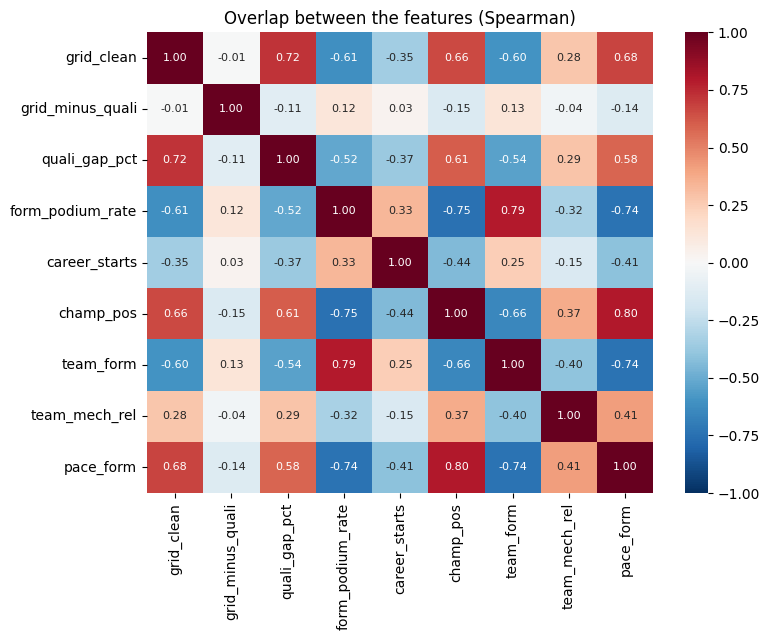

In [271]:
corr = g[list(FEATURES)].astype(float).corr(method='spearman')
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax, annot_kws={'size': 8})
ax.set_title('Overlap between the features (Spearman)')
plt.tight_layout(); plt.show()

**Reading.** No two features say the same thing: the strongest overlaps are past pace with the championship position (0.80), driver form with team form (0.79), and driver form with the championship position (−0.75). All are below the 0.96 that led us to drop `quali_pos` in 7.2. A good driver usually sits in a good car, but the two can differ (a strong driver in a weak team), so all features are kept, and the ablation in the modelling section tests which ones the model really needs. `grid_minus_quali` overlaps with nothing, because it is only non-zero for the few drivers moved by a penalty.

# 8. Training seasons and split

## 8.1 First season: 2003

The model is trained and tested on the seasons **2003–2024**. The reasons come from the tables in 7.10:
- **Qualifying.** The `qualifying` table is only 6–59% filled in 1996–2002 and complete from 2003. Starting earlier would mean filling most qualifying values with guesses, or dropping the two qualifying features.
- **Few gaps.** From 2003, every feature has a value for at least 94% of the rows in every season, and only 3.8% of the rows miss any feature. These are mostly drivers at their first start and teams at their first race, and they are filled in preprocessing.
- **Shared cars** (two drivers credited with one car's result) end in 1961, so none are left.
- **Drivers who did not start** (`never_ran`) were rechecked for these seasons. From 2003, the only removed row marked as retired, disqualified or excluded is Räikkönen at Malaysia 2017, whose car lost power on the way to the grid. Every removed row marked as withdrawn (W, 0 laps) is a known non-start: the 14 cars that pulled into the pits after the formation lap at the 2005 United States GP, cars that failed on the formation lap or on the way to the grid (for example Vettel, Bahrain 2016; Leclerc, Monaco 2021), and injured or ill drivers. The unclear cases (cars disqualified or excluded during the weekend) are all from 1981–1997, outside our seasons.

The first season only decides which rows the model **learns from**. The history features of a 2003 race still look back at earlier seasons (for example, a driver's form at the first race of 2003 uses their 2002 starts). That is allowed, because those races happened before the race being predicted.

## 8.2 The split

| Part | Seasons | Used for |
|---|---|---|
| Training | 2003–2018 | learning the model |
| Validation | 2019–2021 | choosing between models and settings, and the ablation |
| Test | 2022–2024 | the final score, used once at the end |

**Why by whole seasons, in time order:**
- **Like real use.** The model predicts future races from past ones, so it is always tested on seasons after the ones it learned from.
- **A race stays together.** Only 3 drivers of a race can finish on the podium, so the rows of one race depend on each other. A random split would put some drivers of a race in training and the others in test, and the model would partly know the answer.
- **History features stay honest.** Features such as form and team form use earlier races. With a time split, a test row's history never comes from a race the model is tested on later.

**Why the test set is 2022–2024.** New car rules started in 2022. Testing on these seasons shows whether the model still works on cars it has never seen, which is the hardest and most honest test.

**Why validation is 2019–2021, not 2020–2021.** We also considered training on 2003–2019. Moving 2019 changes the two parts very differently (table below):
- **Training** grows by only about 7%. With 9 features, the model already has thousands of rows, so one more season changes little.
- **Validation** shrinks by about a third. Validation scores are estimates, and their error depends mostly on the number of podiums. Models we compare will often differ by only 0.01–0.02 in AUC, so with a smaller validation set a difference of that size is more often just luck.
- **2020 was an unusual season**: COVID, 17 races, two races in a row at the same circuit and several one-off circuits. Without 2019, it would be a third of the validation set.

**2019 is not lost.** After the model and its settings are chosen, it is trained again on 2003–2021 (training + validation) before the test set is scored.

In [272]:
TRAIN = (2003, 2018)
VAL = (2019, 2021)
TEST = (2022, 2024)

fe['split'] = pd.Series(pd.NA, index=fe.index, dtype='string')
for name, (a, b) in [('train', TRAIN), ('validation', VAL), ('test', TEST)]:
    fe.loc[model_rows & fe.year.between(a, b), 'split'] = name

def auc_error(auc_value, pos, neg):
    """Approximate standard error of a ROC-AUC (Hanley and McNeil, 1982)."""
    q1, q2 = auc_value / (2 - auc_value), 2 * auc_value**2 / (1 + auc_value)
    return np.sqrt((auc_value * (1 - auc_value) + (pos - 1) * (q1 - auc_value**2) + (neg - 1) * (q2 - auc_value**2)) / (pos * neg))

g = fe[model_rows]
rows = []
for option, tr, va in [('train 2003-2018, validation 2019-2021 (chosen)', (2003, 2018), (2019, 2021)),
                       ('train 2003-2019, validation 2020-2021', (2003, 2019), (2020, 2021))]:
    t, v = g[g.year.between(*tr)], g[g.year.between(*va)]
    rows.append({'option': option, 'training rows': len(t), 'validation races': v.raceId.nunique(),
                 'validation podiums': int(v.podium.sum()),
                 'AUC error (if AUC = 0.90)': auc_error(0.90, v.podium.sum(), (1 - v.podium).sum())})
display(pd.DataFrame(rows).style.format({'AUC error (if AUC = 0.90)': '±{:.3f}'}).hide(axis='index')
        .set_caption('Moving 2019 from validation to training'))

option,training rows,validation races,validation podiums,AUC error (if AUC = 0.90)
"train 2003-2018, validation 2019-2021 (chosen)",6362,60,180,±0.016
"train 2003-2019, validation 2020-2021",6782,39,117,±0.019


## 8.3 Checks on the split

Each part should have enough races and podiums, a similar podium rate and few missing values.

In [273]:
g = fe[model_rows & fe.split.notna()]
check = (g.groupby('split', sort=False)
          .agg(seasons=('year', lambda y: f'{y.min()}-{y.max()}'), races=('raceId', 'nunique'), rows=('podium', 'size'),
               podiums=('podium', 'sum'), podium_rate=('podium', 'mean'))
          .reset_index())
miss = g.groupby('split', sort=False)[list(FEATURES)].apply(lambda d: d.isna().any(axis=1).mean())
check['rows missing a feature'] = check.split.map(miss)
table(check.rename(columns={'podium_rate': 'podium rate'}), pct1=['podium rate', 'rows missing a feature'],
      caption='The three parts')

table(g.groupby('split', sort=False)[list(FEATURES)].apply(lambda d: d.isna().mean()).T.reset_index()
       .rename(columns={'index': 'feature'}), pct1=['train', 'validation', 'test'],
      caption='Share of rows missing each feature, per part')

split,seasons,races,rows,podiums,podium rate,rows missing a feature
train,2003-2018,300,6362,900,14.1%,4.1%
validation,2019-2021,60,1195,180,15.1%,3.7%
test,2022-2024,68,1352,204,15.1%,2.1%


feature,train,validation,test
grid_clean,0.0%,0.0%,0.0%
grid_minus_quali,0.3%,0.3%,0.0%
quali_gap_pct,1.7%,1.7%,1.0%
form_podium_rate,1.1%,0.8%,0.6%
career_starts,0.0%,0.0%,0.0%
champ_pos,1.9%,1.3%,0.8%
team_form,0.6%,0.8%,0.3%
team_mech_rel,0.6%,0.8%,0.3%
pace_form,1.3%,0.8%,0.6%


**Reading.**
- **Every race has exactly 3 podiums** (300 races → 900 podiums), so the podium rate only depends on how many cars start. Training is slightly lower (14.1% against 15.1%) because 2003–2018 includes seasons with up to 24 cars.
- **About 1 row in 7 is a podium in every part.** This imbalance is why the models are also scored with PR-AUC and F1, not only accuracy.
- **Few missing values in every part** (2–4% of the rows miss any feature, at most 1.9% for one feature). They are filled in the next section, using values learned from the training part only.

# 9. Preprocessing

This section turns the features of section 7 into the **modelling table**: one row per driver per race in 2003–2024, a value for every feature, and nothing learned from the validation or test seasons.

The steps, in this order:

| Step | What it does | Learned from data? |
|---|---|---|
| 9.1 Rows | keeps the drivers who started, in 2003–2024 | no |
| 9.2 Filling | gives every missing feature value a value | some fill values, from the training part only |
| 9.3 Capping | limits a few extreme but misleading values | one limit, from the training part only |
| 9.4 Effect | shows what filling and capping changed | – |
| 9.5 Scaling | puts every feature on the same scale | mean and spread, from the training part only |
| 9.6 Order experiments | tests what happens if the steps are done in another order | – |
| 9.7 The modelling table | the final table, checked | – |

**The rule for every step:** a value that is learned from data (a median, a limit, a mean) is learned from the **training part (2003–2018) only**, then applied unchanged to validation and test. This is how the model will be used for real: when a 2023 race is predicted, nothing from 2023 or later is known yet. If validation or test seasons helped choose these values, the scores in section 10 would be slightly too optimistic.

## 9.1 Rows

The modelling rows were decided in the earlier sections. Each removal has a reason:
- **One row per driver per race** (results section, *duplicates*): the 91 extra rows from shared drives were removed in cleaning, so each row is one prediction, "will this driver finish on the podium in this race?".
- **Drivers who never started** (`never_ran`, results section and 8.1): they have no race to predict. This includes drivers who did not qualify, withdrew, or failed on the way to the grid.
- **The Indianapolis 500** (races section): part of the championship until 1960, but a different race with different drivers.
- **Seasons 2003–2024** (8.1): before 2003 the qualifying features are mostly missing.

No row is removed because of a missing feature value: those are filled in 9.2.

In [274]:
steps = pd.DataFrame({'step': ['results, one row per driver per race', 'minus drivers who never started (never_ran)',
                               'minus the Indianapolis 500', 'seasons 2003-2024 only'],
                      'rows left': [len(fe), (~fe.never_ran).sum(), model_rows.sum(), fe.split.notna().sum()]})
steps['rows removed'] = (-steps['rows left'].diff()).fillna(0).astype(int)
table(steps, caption='From the results table to the modelling rows')

table(fe[fe.split.notna()].groupby('split', sort=False)
        .agg(seasons=('year', lambda y: f'{y.min()}-{y.max()}'), races=('raceId', 'nunique'), rows=('podium', 'size'))
        .reset_index(), caption='Rows per part (8.2)')

step,rows left,rows removed
"results, one row per driver per race",26668,0
minus drivers who never started (never_ran),24958,1710
minus the Indianapolis 500,24577,381
seasons 2003-2024 only,8909,15668


split,seasons,races,rows
train,2003-2018,300,6362
validation,2019-2021,60,1195
test,2022-2024,68,1352


## 9.2 Filling the missing values

**Why fill instead of dropping.** From 2003, 3.8% of the rows miss at least one feature (7.10). Most of them are a driver's **first start** (no form, no pace, no championship position yet) or a team's **first race** (no team history). If these rows were dropped, the model would never see a rookie or a new team, but it must still predict for them. So every row is kept and every gap is filled.

**The rules.** Each feature gets the rule that matches *why* its value is missing (8.3 and the missing-value check in this section):

| Feature | Missing when | Filled with | Why this value |
|---|---|---|---|
| `grid_minus_quali` | the driver has no qualifying row (set no lap, or was excluded from qualifying) | **0** | "not moved from qualifying". Their grid slot already shows that they start at the back. |
| `quali_gap_pct` | no Q1 time, or no qualifying row | the driver's **median gap over their previous 10 starts**; if they have none, the **training median** | the driver's own recent qualifying speed is the best guess for this weekend |
| `form_podium_rate` | the driver's first start | **0** | true: the driver has no podium yet. `career_starts` = 0 tells the model that this 0 is a debut, not a bad run. |
| `pace_form` | the driver's first start (or no earlier race with 10+ laps) | the **training median** | no earlier pace exists, so the driver is treated as typical |
| `champ_pos` | no standing this season and none last season (debut, or back after a season out) | the **worst `champ_pos` in the same race + 1** | the driver has no points, so they are behind everyone. It is the same idea as pit-lane starters in `grid_clean`, and it only uses other drivers' pre-race standings. |
| `team_form` | the team's first race (a new team, a new name, or a return after 5+ seasons) | the **training median** | no history, so the team is treated as typical |
| `team_mech_rel` | the team's first race | the **training median** | the same |

**Why new team names are not linked to the old name.** Most "new" teams are renamed teams (Red Bull 2005 was Jaguar, Brawn 2009 was Honda). Their history was not carried over, because a new name often means a new owner and a different car. Honda had 1 podium in 2008; as Brawn the same factory won 6 of the first 7 races of 2009. The other features of the row (the grid slot and the gap in qualifying) already show how fast the new car is that weekend.

**Why the median, and why only training.** The median is the middle value, so a few extreme values cannot pull it. It is computed on the training rows only and used for every part, so a test row is never filled with information from the test seasons.

In [275]:
# the driver's median Q1 gap over their previous 10 starts (the current race is left out)
hist = fe[model_rows].sort_values(['driverId', 'year', 'round'])
fe = fe.drop(columns=['quali_prev_median'], errors='ignore')                  # safe to rerun
fe.loc[hist.index, 'quali_prev_median'] = (hist.groupby('driverId').quali_gap_pct
                                               .transform(lambda s: s.shift(1).rolling(10, min_periods=1).median()))

ID_COLS = ['raceId', 'driverId', 'constructorId', 'year', 'round', 'split']
F = list(FEATURES)
data = fe.loc[fe.split.notna(), ID_COLS + F + ['quali_prev_median', 'podium']].copy()
data[F] = data[F].astype(float)
train_mask = data.split == 'train'

def fit_fill(rows):
    """The fill values learned from data: the medians of the given rows."""
    return {f: rows[f].median() for f in ['quali_gap_pct', 'pace_form', 'team_form', 'team_mech_rel']}

def apply_fill(d, learned):
    """Fill every missing feature value with the rules above."""
    d = d.copy()
    d['grid_minus_quali'] = d.grid_minus_quali.fillna(0)
    d['quali_gap_pct'] = d.quali_gap_pct.fillna(d.quali_prev_median).fillna(learned['quali_gap_pct'])
    d['form_podium_rate'] = d.form_podium_rate.fillna(0)
    d['champ_pos'] = d.champ_pos.fillna(d.groupby('raceId').champ_pos.transform('max') + 1)
    for f in ['pace_form', 'team_form', 'team_mech_rel']:
        d[f] = d[f].fillna(learned[f])
    return d

learned = fit_fill(data[train_mask])
filled = apply_fill(data, learned)

display(pd.DataFrame({'value': learned}).rename_axis('feature').style.format('{:.4f}')
        .set_caption('Fill values learned from the training part'))
print('team_form = 0 in the training rows:', f'{(data.loc[train_mask, "team_form"] == 0).mean():.0%}')
q_miss = data.quali_gap_pct.isna()
print("quali_gap_pct: filled with the driver's previous median:", int((q_miss & data.quali_prev_median.notna()).sum()),
      "| with the training median (no earlier Q1 time):", int((q_miss & data.quali_prev_median.isna()).sum()))

check = pd.DataFrame({p: data.loc[data.split == p, F].isna().sum() for p in ['train', 'validation', 'test']})
check['missing before, all'] = check.sum(axis=1)
check['missing after'] = filled[F].isna().sum()
table(check.reset_index().rename(columns={'index': 'feature', 'train': 'missing before, train',
                                          'validation': 'missing before, validation', 'test': 'missing before, test'}),
      caption='Missing values before and after filling')
assert filled[F].notna().all().all(), 'a feature value is still missing'

,value
feature,
quali_gap_pct,1.3570
pace_form,1.0000
team_form,0.0000
team_mech_rel,-0.0096


team_form = 0 in the training rows: 52%
quali_gap_pct: filled with the driver's previous median: 141 | with the training median (no earlier Q1 time): 3


feature,"missing before, train","missing before, validation","missing before, test","missing before, all",missing after
grid_clean,0,0,0,0,0
grid_minus_quali,18,3,0,21,0
quali_gap_pct,111,20,13,144,0
form_podium_rate,72,9,8,89,0
career_starts,0,0,0,0,0
champ_pos,124,15,11,150,0
team_form,41,10,4,55,0
team_mech_rel,41,10,4,55,0
pace_form,81,10,8,99,0


**Reading.**
- **Every feature value is now filled** (the last column is 0 everywhere), and no row was removed.
- **Few values were filled:** at most 150 of 8,909 rows for one feature (`champ_pos`), and only 21 for `grid_minus_quali`.
- **`quali_gap_pct`:** 141 of the 144 gaps were filled with the driver's own recent median. Only 3 drivers had no earlier Q1 time and got the training median.
- **`pace_form`:** 99 gaps: the 89 first starts, plus 10 drivers whose earlier races all ended before 10 laps (7.8).
- **The training median of `team_form` is 0**, because 52% of the training rows belong to teams with no podium in their previous 10 races. A team at its first race is therefore filled as "no recent podium", which is true of the typical team. Brawn in 2009 is the exception, and its grid slots show the car's speed.
- **The training median of `team_mech_rel` is about −0.01**, almost exactly "as reliable as the field".

## 9.3 Capping extreme values

Two features have a few values that are real but do not mean what the feature is meant to measure:

- **`quali_gap_pct`.** A normal gap to the fastest Q1 lap is 0–5%. A few drivers are 10–45% slower, because their only Q1 lap had a problem (a spin, a crash, a car failure or rain at the end of the session). That lap does not show the car's speed. These values are **capped at 7%**: anything above becomes 7%. The limit comes from the sport's own **107% rule**: a car more than 7% slower than the fastest lap in qualifying is not considered to be at racing speed (it may be refused a start). The limit is a fixed rule, so nothing is learned from data.
- **`team_mech_rel`.** A normal value is between about −0.1 and +0.1. At a team's first few races the rate is based on very few cars: if both cars break down in the team's first race, the team has a 100% failure rate from 2 starts. These values are **capped at the 1st and 99th percentiles of the training part**: the 1% most extreme values at each end are pulled in to that limit.
- **`pace_form`.** A normal value is between about 0.98 and 1.05. The same problem as for reliability: at a driver's first few starts, the average covers only one or two races, and a single chaotic race can dominate it. Justin Wilson's race pace at the wet, red-flagged Brazilian GP 2003 was 1.44, which kept his `pace_form` near 1.1–1.2 for the next races. It is **capped at the 1st and 99th percentiles of the training part**, like `team_mech_rel`.

**Why cap.** For logistic regression and the neural network, one extreme value stretches the scale (9.5) and pulls the model towards a few unusual rows. Trees are not affected, because they only compare values with a threshold. Capping keeps the row and keeps its order (the value is still the most extreme), it only shortens the distance.

The other features have no misleading extremes: grid slots, positions and podium rates have fixed ranges, and `career_starts` is a count.

In [276]:
QUALI_CAP = 7.0                                                                # the 107% rule

def fit_caps(rows):
    """The capping limits learned from data: the 1st and 99th percentiles of team_mech_rel and pace_form."""
    return {f: tuple(rows[f].quantile([0.01, 0.99])) for f in ['team_mech_rel', 'pace_form']}

def apply_caps(d, caps):
    """Cap quali_gap_pct at 7%, and team_mech_rel and pace_form at the learned limits."""
    d = d.copy()
    d['quali_gap_pct'] = d.quali_gap_pct.clip(upper=QUALI_CAP)
    for f, limits in caps.items():
        d[f] = d[f].clip(*limits)
    return d

caps = fit_caps(filled[train_mask])
capped = apply_caps(filled, caps)
display(pd.DataFrame(caps, index=['low limit', 'high limit']).T.rename_axis('feature').style.format('{:.3f}')
        .set_caption('Capping limits learned from the training part'))

over = filled.quali_gap_pct > QUALI_CAP
outside = {f: (filled[f] < lo) | (filled[f] > hi) for f, (lo, hi) in caps.items()}
mech_out = outside['team_mech_rel']
table(pd.DataFrame({'part': ['train', 'validation', 'test'],
                    'quali_gap_pct above 7%': [int((over & (filled.split == p)).sum()) for p in ['train', 'validation', 'test']],
                    'team_mech_rel outside the limits': [int((mech_out & (filled.split == p)).sum()) for p in ['train', 'validation', 'test']],
                    'pace_form outside the limits': [int((outside['pace_form'] & (filled.split == p)).sum()) for p in ['train', 'validation', 'test']]}),
      caption='Rows changed by capping')
print(f'podium rate of the rows above 7% in qualifying: {filled[over].podium.mean():.1%} ({int(filled[over].podium.sum())} of {over.sum()})')

names = (filled[over].nlargest(6, 'quali_gap_pct')
           .merge(drivers[['driverId', 'forename', 'surname']], on='driverId').merge(races[['raceId', 'name']], on='raceId'))
table(names.assign(driver=names.forename + ' ' + names.surname, grid_clean=names.grid_clean.astype(int))
           [['year', 'name', 'driver', 'quali_gap_pct', 'grid_clean', 'podium']]
           .rename(columns={'name': 'race', 'grid_clean': 'grid'}), dec1=['quali_gap_pct'],
      caption='The largest gaps in qualifying (before capping)')

teams = (filled[mech_out].drop_duplicates(['raceId', 'constructorId']).nlargest(6, 'team_mech_rel')
           .merge(constructors[['constructorId', 'name']], on='constructorId'))
table(teams[['year', 'round', 'name', 'team_mech_rel']].rename(columns={'name': 'team'}), dec2=['team_mech_rel'],
      caption='The largest team_mech_rel values (before capping)')

slow = (filled[outside['pace_form']].nlargest(6, 'pace_form').merge(drivers[['driverId', 'forename', 'surname']], on='driverId'))
table(slow.assign(driver=slow.forename + ' ' + slow.surname, career_starts=slow.career_starts.astype(int))
          [['year', 'round', 'driver', 'career_starts', 'pace_form']], dec2=['pace_form'],
      caption='The largest pace_form values (before capping)')

,low limit,high limit
feature,,
team_mech_rel,-0.164,0.319
pace_form,0.979,1.053


part,quali_gap_pct above 7%,team_mech_rel outside the limits,pace_form outside the limits
train,90,127,128
validation,14,4,0
test,2,0,0


podium rate of the rows above 7% in qualifying: 6.6% (7 of 106)


year,race,driver,quali_gap_pct,grid,podium
2023,Saudi Arabian Grand Prix,Logan Sargeant,44.8,20,0
2004,San Marino Grand Prix,Zsolt Baumgartner,33.3,19,0
2005,Australian Grand Prix,Michael Schumacher,26.6,19,0
2003,Italian Grand Prix,Fernando Alonso,24.0,20,0
2009,Brazilian Grand Prix,Giancarlo Fisichella,21.6,19,0
2010,Belgian Grand Prix,Lucas di Grassi,20.8,22,0


year,round,team,team_mech_rel
2012,2,Caterham,0.92
2010,2,Sauber,0.91
2010,2,Virgin,0.91
2010,3,Virgin,0.90
2010,5,Virgin,0.61
2010,4,Virgin,0.56


year,round,driver,career_starts,pace_form
2003,4,Justin Wilson,3,1.19
2010,3,Lucas di Grassi,2,1.15
2003,5,Justin Wilson,4,1.15
2003,6,Justin Wilson,5,1.12
2003,2,Justin Wilson,1,1.11
2003,7,Justin Wilson,6,1.11


**Reading.**
- **`quali_gap_pct`:** 106 rows are above 7% (90 in training), about 1.2% of all rows. The largest gaps are problem laps, not slow cars. For example, Michael Schumacher in a Ferrari, 26.6% off in Australia 2005, was caught by rain in qualifying. 7 of these 106 drivers still reached the podium (6.6%), which confirms that a huge gap often does not mean a slow car.
- **`team_mech_rel`:** the limits learned from training are −0.164 and +0.319. The values above come from a team's first races, where very few cars count. Examples are Virgin and Sauber in the first races of 2010 (a new team and a team whose history restarted) and Caterham in 2012 (a new name). 127 training rows are changed (1% at each end, by design), 4 in validation and none in test.
- **`pace_form`:** the limits are 0.979 and 1.053. The largest values belong to drivers in their first few starts, such as Justin Wilson in 2003 and Lucas di Grassi in 2010, whose average still contained a chaotic race. 128 training rows are changed and none in validation or test.
- Every row is kept, and a capped row is still the most extreme in its race. Capping only shortens how far out it is.

## 9.4 Effect of filling and capping

The table follows each changed feature through the steps, on the **training part**: the values that were observed, then after filling, then after capping. Besides the mean, spread and range, the last column is the feature's **AUC** (how well it separates podiums from the rest, 7.1), to check that the steps did not weaken it. The chart shows where the filled values land compared with the observed values.

feature,stage,rows with a value,mean,median,std,min,max,AUC
grid_minus_quali,observed,6344,-0.002,0.000,1.521,-7.000,23.000,0.556
grid_minus_quali,filled,6362,-0.002,0.000,1.518,-7.000,23.000,0.556
grid_minus_quali,filled and capped,6362,-0.002,0.000,1.518,-7.000,23.000,0.556
quali_gap_pct,observed,6251,1.812,1.357,1.859,0.000,33.285,0.829
quali_gap_pct,filled,6362,1.821,1.367,1.857,0.000,33.285,0.830
quali_gap_pct,filled and capped,6362,1.765,1.367,1.525,0.000,7.000,0.830
form_podium_rate,observed,6290,0.142,0.000,0.234,0.000,1.000,0.873
form_podium_rate,filled,6362,0.141,0.000,0.234,0.000,1.000,0.873
form_podium_rate,filled and capped,6362,0.141,0.000,0.234,0.000,1.000,0.873
champ_pos,observed,6238,11.316,11.000,6.504,1.000,27.000,0.887


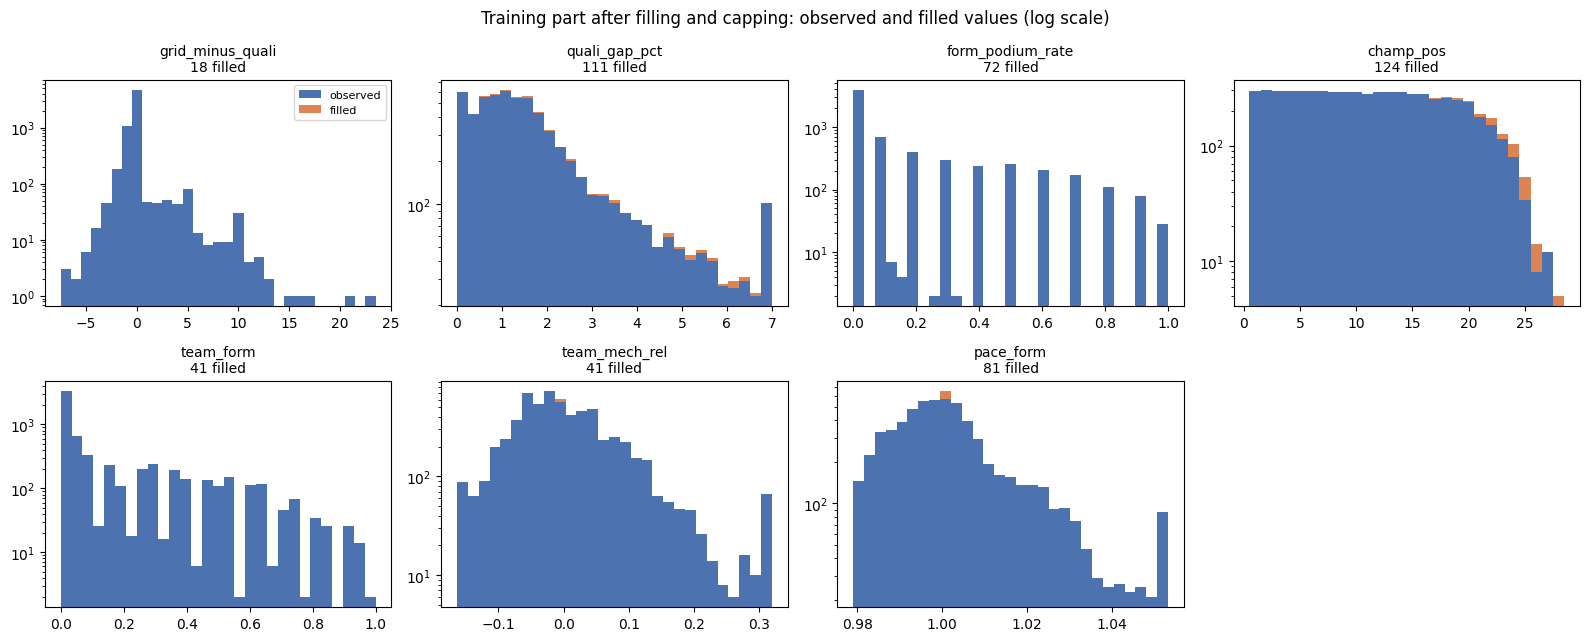

In [277]:
CHANGED = ['grid_minus_quali', 'quali_gap_pct', 'form_podium_rate', 'champ_pos', 'team_form', 'team_mech_rel', 'pace_form']
SIGN = {f: FEATURES[f][3] for f in F}
tr = train_mask
rows = []
for f in CHANGED:
    for stage, d in [('observed', data), ('filled', filled), ('filled and capped', capped)]:
        x = d.loc[tr, f]
        known = x.notna()
        rows.append({'feature': f, 'stage': stage, 'rows with a value': int(known.sum()), 'mean': x.mean(), 'median': x.median(),
                     'std': x.std(), 'min': x.min(), 'max': x.max(), 'AUC': auc(SIGN[f] * x, d.loc[tr, 'podium'])})
effect = pd.DataFrame(rows)
display(effect.style.format({c: '{:.3f}' for c in ['mean', 'median', 'std', 'min', 'max', 'AUC']})
        .hide(axis='index').set_caption('Training part: each changed feature through the steps'))

fig, axes = plt.subplots(2, 4, figsize=(16, 6.5)); axes = axes.ravel()
for ax, f in zip(axes, CHANGED):
    was_missing = data.loc[tr, f].isna()
    x = capped.loc[tr, f]
    bins = np.arange(x.min() - 0.5, x.max() + 1.5, 1) if f in ('champ_pos', 'grid_minus_quali') else np.linspace(x.min(), x.max(), 30)
    ax.hist([x[~was_missing], x[was_missing]], bins=bins, stacked=True,
            color=['#4C72B0', '#DD8452'], label=['observed', 'filled'])
    ax.set_yscale('log'); ax.set_title(f'{f}\n{was_missing.sum()} filled', fontsize=10)
axes[-1].axis('off'); axes[0].legend(fontsize=8)
fig.suptitle('Training part after filling and capping: observed and filled values (log scale)')
plt.tight_layout(); plt.show()

**Reading.**
- **Filling barely moves the distributions.** Means, medians and spreads change by at most a few thousandths, because only 0.3–2% of the training values were filled. The filled values (orange) land where the rules put them: at 0 for `grid_minus_quali` and `form_podium_rate`, at the back for `champ_pos`, and in the middle for the medians. In the chart they are a thin layer on top of the observed values, and at 0 they are hidden by the thousands of observed zeros.
- **`champ_pos` gets a slightly longer tail** (maximum 27 → 28, mean 11.3 → 11.5): drivers with no standing are placed behind everyone, as intended.
- **Capping changes the range of three features.** In the chart, the bar at 7 for `quali_gap_pct` and the bars at the ends of `team_mech_rel` and `pace_form` are the capped values. The maximum of `quali_gap_pct` falls from 33.3 to 7.0 and its spread from 1.86 to 1.53. `team_mech_rel` goes from −0.26 to 0.92 down to −0.16 to 0.32, and `pace_form` from 0.968 to 1.190 down to 0.979 to 1.053. The medians do not move, because only the tails were changed.
- **No feature lost strength.** The AUC is the same after each step (within 0.001), so the filled and capped values separate podiums from the rest as well as the observed values did.

## 9.5 Scaling

The features are on very different ranges: `career_starts` goes from 0 to over 300, `form_podium_rate` from 0 to 1 and `team_mech_rel` from about −0.16 to +0.32. Each feature is **standardised** with the mean and spread of the training part:

**scaled value = (value − training mean) ÷ training standard deviation**

For example, the training mean of `grid_clean` is about 11.2 and its standard deviation about 6.3, so pole position (grid 1) becomes (1 − 11.2) ÷ 6.3 ≈ −1.6, grid 11 becomes about 0, and grid 20 becomes about +1.4. After scaling, every feature in the training part has mean 0 and standard deviation 1.

**Why scale.**
- **Logistic regression** (with the usual regularisation) shrinks all weights by the same rule, so a feature measured on a large range would be treated differently from one on a small range only because of its unit.
- **The neural network** learns slowly and unevenly when its inputs are on very different scales.
- **Trees** only compare a value with a threshold, so scaling changes nothing for them. The same scaled table can be used for every model.

**Why standardisation and not min-max** (squeezing each feature into 0–1). Min-max uses the single smallest and largest value, so one extreme row decides the scale of the whole feature. Standardisation uses the mean and spread of all rows, and the extremes were already capped in 9.3.

**Why only the training part.** Validation and test are scaled with the training mean and spread, so their means are not exactly 0. That is expected: it shows how the later seasons differ from the training seasons (for example, drivers in 2022–2024 have more career starts on average).

feature,stage,train mean,train std,validation mean,validation std,test mean,test std,train min,train max
grid_clean,before,11.22,6.26,10.53,5.80,10.49,5.76,1.00,24.00
grid_clean,after,0.00,1.00,-0.11,0.93,-0.12,0.92,-1.63,2.04
grid_minus_quali,before,-0.00,1.52,0.04,1.84,0.01,1.96,-7.00,23.00
grid_minus_quali,after,0.00,1.00,0.03,1.21,0.01,1.29,-4.61,15.15
quali_gap_pct,before,1.77,1.53,1.34,1.15,1.03,0.80,0.00,7.00
quali_gap_pct,after,0.00,1.00,-0.28,0.75,-0.48,0.52,-1.16,3.43
form_podium_rate,before,0.14,0.23,0.15,0.25,0.15,0.24,0.00,1.00
form_podium_rate,after,-0.00,1.00,0.04,1.08,0.05,1.03,-0.60,3.68
career_starts,before,91.96,78.85,116.04,92.15,145.77,96.95,0.00,321.00
career_starts,after,-0.00,1.00,0.31,1.17,0.68,1.23,-1.17,2.90


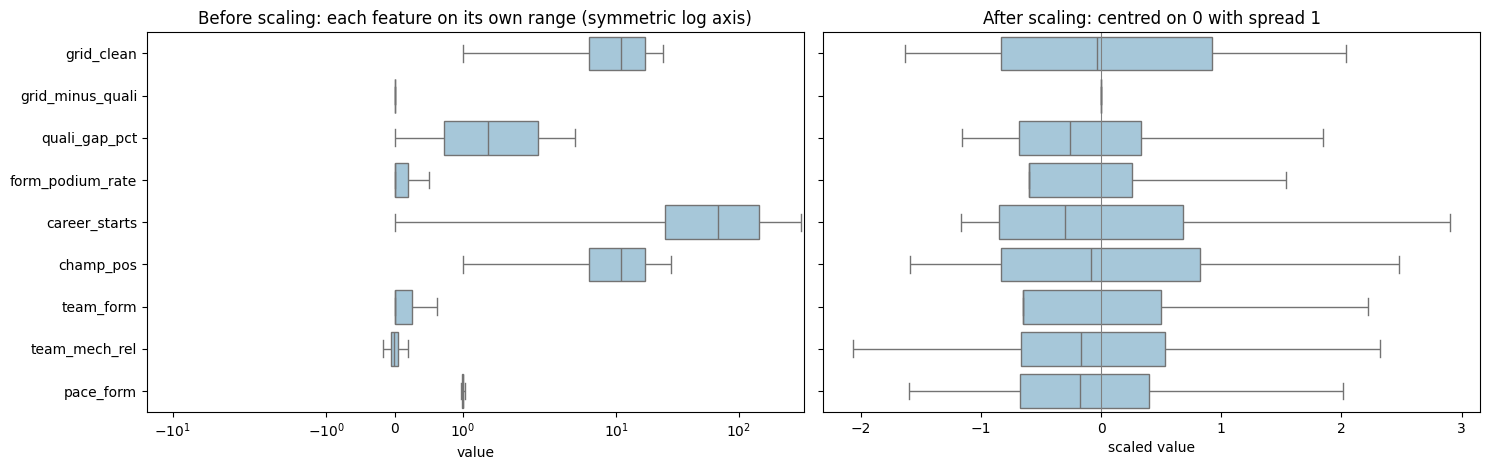

In [278]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

scaler = StandardScaler().fit(capped.loc[train_mask, F])
scaled = capped.copy()
scaled[F] = scaler.transform(capped[F])

rows = []
for f in F:
    for stage, d in [('before', capped), ('after', scaled)]:
        r = {'feature': f, 'stage': stage}
        for part in ['train', 'validation', 'test']:
            x = d.loc[d.split == part, f]
            r[f'{part} mean'], r[f'{part} std'] = x.mean(), x.std()
        r['train min'], r['train max'] = d.loc[train_mask, f].min(), d.loc[train_mask, f].max()
        rows.append(r)
sc_table = pd.DataFrame(rows)
display(sc_table.style.format({c: '{:.2f}' for c in sc_table.columns[2:]}).hide(axis='index')
        .set_caption('Scaling: mean, spread and range per part, before and after (learned from the training part)'))

long_before = capped.loc[train_mask, F].melt(var_name='feature', value_name='value')
long_after = scaled.loc[train_mask, F].melt(var_name='feature', value_name='value')
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
sns.boxplot(data=long_before, x='value', y='feature', orient='h', showfliers=False, color='#9ecae1', ax=axes[0])
axes[0].set_xscale('symlog'); axes[0].set(title='Before scaling: each feature on its own range (symmetric log axis)', xlabel='value', ylabel='')
sns.boxplot(data=long_after, x='value', y='feature', orient='h', showfliers=False, color='#9ecae1', ax=axes[1])
axes[1].axvline(0, color='grey', lw=0.8); axes[1].set(title='After scaling: centred on 0 with spread 1', xlabel='scaled value', ylabel='')
plt.tight_layout(); plt.show()

**Reading.**
- **Training part:** every feature now has mean 0 and standard deviation 1, so no feature dominates only because of its unit. The boxes in the right chart sit on the same scale.
- **The shape does not change.** Scaling only shifts and stretches each feature, so the order of the rows, the skew (most drivers have no recent podium, a few have many) and the AUC stay exactly the same.
- **Validation and test** are not exactly at mean 0 and spread 1, because they were scaled with the training values. The clearest difference is `career_starts`: drivers in 2019–2024 have more starts on average than in 2003–2018, so their scaled mean is above 0. The model will see these later seasons as they really are, compared with what it learned from.

## 9.6 Preprocessing-order experiments

The order of the steps above was chosen on purpose. Two experiments check what happens when it is changed. Each one prepares the data in two ways, trains the same simple model on the training part (a logistic regression on the 9 features, the baseline of section 10), and scores it on the **validation part** with ROC-AUC and PR-AUC. The test part is not used, so it stays unseen until the end.

**Experiment 1: learn the preprocessing values from the training part only, or from all seasons.**
- **A (our order):** split first, then learn the fill values, the capping limits and the scaling from the training part only.
- **B:** learn them from all seasons 2003–2024, then split. This is a common mistake: the validation and test seasons help decide the medians, limits, means and spreads, so information from the "future" leaks into the preparation of the training data.

**Experiment 2: fill before scaling, or scale before filling.**
- **A (our order):** fill, cap, then scale.
- **B:** cap, scale, then fill with the same rules. After scaling, 0 no longer means "no podium" but "an average podium rate", and "+1" for `champ_pos` no longer means "one place behind" but "one standard deviation behind". The same rule then gives different values.

In [279]:
def preprocess(learn_from):
    """Fill, cap and scale every row, with all values learned from the rows in learn_from."""
    learned = fit_fill(data[learn_from])
    f = apply_fill(data, learned)
    caps = fit_caps(f[learn_from])
    f = apply_caps(f, caps)
    sc = StandardScaler().fit(f.loc[learn_from, F])
    f[F] = sc.transform(f[F])
    return learned, caps, sc, f

def score(d):
    """Logistic regression trained on the training part, scored on the validation part."""
    tr, va = d[d.split == 'train'], d[d.split == 'validation']
    p = LogisticRegression(max_iter=2000).fit(tr[F], tr.podium).predict_proba(va[F])[:, 1]
    return roc_auc_score(va.podium, p), average_precision_score(va.podium, p)

all_mask = data.split.notna()
exp1 = {}
for name, mask in [('A. learned from the training part (our order)', train_mask),
                   ('B. learned from all seasons 2003-2024', all_mask)]:
    lv, cp, sc, d = preprocess(mask)
    roc, pr = score(d)
    exp1[name] = {**{f'fill value: {k}': v for k, v in lv.items()},
                  'capping limit: team_mech_rel low': cp['team_mech_rel'][0], 'capping limit: team_mech_rel high': cp['team_mech_rel'][1],
                  'scaling mean: career_starts': sc.mean_[F.index('career_starts')],
                  'scaling mean: quali_gap_pct': sc.mean_[F.index('quali_gap_pct')],
                  'validation ROC-AUC': roc, 'validation PR-AUC': pr}
exp1 = pd.DataFrame(exp1)
exp1['difference (B - A)'] = exp1.iloc[:, 1] - exp1.iloc[:, 0]
display(exp1.style.format('{:.4f}').set_caption('Experiment 1: where the preprocessing values are learned'))

,A. learned from the training part (our order),B. learned from all seasons 2003-2024,difference (B - A)
fill value: quali_gap_pct,1.3570,1.2227,-0.1343
fill value: pace_form,1.0000,1.0005,0.0005
fill value: team_form,0.0000,0.0000,0.0000
fill value: team_mech_rel,-0.0096,-0.0080,0.0016
capping limit: team_mech_rel low,-0.1635,-0.1469,0.0167
capping limit: team_mech_rel high,0.3192,0.2798,-0.0393
scaling mean: career_starts,91.9640,103.3583,11.3943
scaling mean: quali_gap_pct,1.7655,1.5974,-0.1681
validation ROC-AUC,0.9319,0.9319,0.0000
validation PR-AUC,0.7168,0.7167,-0.0002


In [280]:
_, _, _, order_a = preprocess(train_mask)                       # fill, cap, scale

b = apply_caps(data, fit_caps(data[train_mask]))                # cap, then scale (missing values are ignored by the scaler)
sc_b = StandardScaler().fit(b.loc[train_mask, F])
b[F] = sc_b.transform(b[F])
qi = F.index('quali_gap_pct')
b['quali_prev_median'] = (data.quali_prev_median.clip(upper=QUALI_CAP) - sc_b.mean_[qi]) / sc_b.scale_[qi]
order_b = apply_fill(b, fit_fill(b[train_mask]))                # then fill with the same rules

def back_to_units(v, f, sc):
    return v * sc.scale_[F.index(f)] + sc.mean_[F.index(f)]

debut = data.form_podium_rate.isna()
no_standing = data.champ_pos.isna()
a_sc = preprocess(train_mask)[2]
examples = pd.DataFrame({
    'A: value in original units': [back_to_units(order_a.loc[debut, 'form_podium_rate'].mean(), 'form_podium_rate', a_sc),
                                   back_to_units(order_a.loc[no_standing, 'champ_pos'].mean(), 'champ_pos', a_sc)],
    'B: value in original units': [back_to_units(order_b.loc[debut, 'form_podium_rate'].mean(), 'form_podium_rate', sc_b),
                                   back_to_units(order_b.loc[no_standing, 'champ_pos'].mean(), 'champ_pos', sc_b)]},
    index=['form_podium_rate of a first start', 'champ_pos of a driver with no standing (average)'])
display(examples.style.format('{:.2f}').set_caption('Experiment 2: the same fill rule gives a different value'))

exp2 = pd.DataFrame([dict(zip(['validation ROC-AUC', 'validation PR-AUC'], score(d)), order=name)
                     for name, d in [('A. fill, cap, then scale (our order)', order_a), ('B. cap, scale, then fill', order_b)]]).set_index('order')
display(exp2.style.format('{:.4f}').set_caption('Experiment 2: scores on the validation part'))

,A: value in original units,B: value in original units
form_podium_rate of a first start,0.00,0.14
champ_pos of a driver with no standing (average),22.41,27.92


,validation ROC-AUC,validation PR-AUC
order,,
"A. fill, cap, then scale (our order)",0.9319,0.7168
"B. cap, scale, then fill",0.9319,0.7167


**Reading.**

**Experiment 1.** Learning the values from all seasons changes them: the fill value of `quali_gap_pct`, the capping limits and the scaling means move, because 2019–2024 differ from 2003–2018 (for example, drivers have more career starts and smaller gaps in qualifying). The validation score barely changes (the difference is in the fourth decimal). The leak is small here for two reasons: only a few percent of the values are filled or capped, and scaling a logistic regression with slightly different means does not change which rows it ranks highest. The order still matters: in B, part of the validation and test seasons was used to prepare the data, so the scores would no longer measure how the model does on seasons it has never seen. With more missing values or a model that depends more on the exact scale, the effect would be larger, and nothing would show it.

**Experiment 2.** Scaling before filling gives different values for the same rule. A first start gets a `form_podium_rate` equal to the training average (about 14%) instead of 0, so every debut looks like a driver with a podium every seven races. A driver with no standing is placed about 28th on average instead of about 22nd: "+1" now means one standard deviation (about 6–7 places), not one place. The validation score changes little, again because few rows are affected, but the values in B are wrong for what the features mean. Filling first keeps each rule's meaning ("no podium yet", "one place behind everyone"); scaling then only changes the unit.

**Decision.** The order of 9.1–9.5 is kept: split, then fill, cap and scale, with every value learned from the training part only.

## 9.7 The modelling table

The result of this section: one row per driver per race in 2003–2024, 9 features with no missing value, and the target `podium`. The table keeps the filled and capped values in their original units (easy to read and to explain). The models use the scaled copies `X_train`, `X_val` and `X_test`, all scaled with the training values.

In [281]:
model_table = capped[ID_COLS + F + ['podium']].reset_index(drop=True)
assert model_table[F + ['podium']].notna().all().all(), 'a value is missing'
assert not model_table.duplicated(['raceId', 'driverId']).any(), 'a driver appears twice in a race'
assert (model_table.groupby('raceId').podium.sum() == 3).all(), 'a race does not have exactly 3 podiums'
assert model_table.quali_gap_pct.max() <= QUALI_CAP

print('modelling table:', len(model_table), 'rows |', len(F), 'features | missing values:', int(model_table[F].isna().sum().sum()),
      '| duplicated driver-races: 0 | races with exactly 3 podiums: all', model_table.raceId.nunique())
table(model_table.groupby('split', sort=False)
        .agg(seasons=('year', lambda y: f'{y.min()}-{y.max()}'), races=('raceId', 'nunique'), rows=('podium', 'size'),
             podiums=('podium', 'sum'), podium_rate=('podium', 'mean')).reset_index()
        .rename(columns={'podium_rate': 'podium rate'}), pct1=['podium rate'], caption='The modelling table')

display(model_table[F].describe().T[['mean', 'std', 'min', '50%', 'max']].rename(columns={'50%': 'median'})
        .style.format('{:.3f}').set_caption('The 9 features (all rows, original units)'))

example = (model_table.merge(drivers[['driverId', 'surname']], on='driverId')
                      .query("year == 2018 and round == 1").sort_values('grid_clean').head(5))
whole = ['grid_clean', 'grid_minus_quali', 'career_starts', 'champ_pos']
display(example[['year', 'round', 'surname'] + F + ['podium']]
        .style.format({f: '{:.0f}' if f in whole else '{:.3f}' for f in F})
        .hide(axis='index').set_caption('Example: the first five on the grid, Australia 2018'))

def xy(part):
    rows = scaled[scaled.split == part]
    return rows[F], rows.podium
X_train, y_train = xy('train')
X_val, y_val = xy('validation')
X_test, y_test = xy('test')
print('scaled inputs for the models: X_train', X_train.shape, '| X_val', X_val.shape, '| X_test', X_test.shape)

modelling table: 8909 rows | 9 features | missing values: 0 | duplicated driver-races: 0 | races with exactly 3 podiums: all 428


split,seasons,races,rows,podiums,podium rate
train,2003-2018,300,6362,900,14.1%
validation,2019-2021,60,1195,180,15.1%
test,2022-2024,68,1352,204,15.1%


,mean,std,min,median,max
grid_clean,11.020,6.135,1.000,11.000,24.000
grid_minus_quali,0.005,1.638,-8.000,0.000,23.000
quali_gap_pct,1.597,1.418,0.000,1.229,7.000
form_podium_rate,0.144,0.237,0.000,0.000,1.000
career_starts,103.358,85.969,0.000,82.000,401.000
champ_pos,11.295,6.471,1.000,11.000,28.000
team_form,0.144,0.220,0.000,0.000,1.000
team_mech_rel,0.002,0.073,-0.164,-0.008,0.319
pace_form,1.002,0.013,0.979,1.000,1.053


year,round,surname,grid_clean,grid_minus_quali,quali_gap_pct,form_podium_rate,career_starts,champ_pos,team_form,team_mech_rel,pace_form,podium
2018,1,Hamilton,1,0,0.000,0.700,208,1,0.650,-0.108,0.984,1
2018,1,Räikkönen,2,0,0.328,0.500,271,4,0.526,-0.082,0.989,1
2018,1,Vettel,3,0,0.633,0.600,198,2,0.526,-0.082,0.986,1
2018,1,Verstappen,4,0,0.796,0.300,60,6,0.350,0.092,0.986,0
2018,1,Magnussen,5,-1,1.310,0.000,60,14,0.000,-0.008,1.006,0


scaled inputs for the models: X_train (6362, 9) | X_val (1195, 9) | X_test (1352, 9)


# 10. Models

Three models are trained on the **same modelling table** (9.7): the same rows, the same 9 features and the same split, so their scores can be compared directly.

| Model | Type | Role |
|---|---|---|
| Logistic regression | statistical | **baseline**: the simplest reasonable model |
| Gradient boosting | statistical (trees) | a more flexible model: does it earn its extra complexity? |
| Shallow neural network (PyTorch) | neural network, 1–2 hidden layers | the same question for a network |

All choices (settings, threshold, number of training rounds) are made on the **validation part (2019–2021)**. The test part (2022–2024) is used only once, at the end (10.8).

## 10.1 How the models are scored

Every model outputs a **probability of a podium** for each driver in each race. The scores:

| Score | What it measures | Needs a threshold? |
|---|---|---|
| **ROC-AUC** | How well the probabilities separate podium and non-podium drivers overall: the chance that a random podium driver gets a higher probability than a random non-podium driver. 0.5 = guessing, 1 = perfect. | no |
| **PR-AUC** | How well the podium drivers are ranked at the top. It looks only at the podium class, so it is more informative than ROC-AUC when podiums are rare (about 15% of rows). Guessing gives about 0.15. | no |
| **F1** | Turns the probabilities into yes/no with a threshold, then balances precision (of the drivers predicted on the podium, how many were) and recall (of the real podium drivers, how many were found). | yes |
| **Top-3 per race** | In each race, take the 3 drivers with the highest probability and count how many really finished on the podium. Not required, but it is the most natural question for F1 racing. | no |

**Main score for choosing settings: PR-AUC.** Podiums are the rare class we care about, and PR-AUC needs no threshold. **Second score: F1**, the quality of the yes/no answers at the chosen threshold. Both choices are explained with evidence in 10.9.

**The threshold for F1** is chosen on the validation part, as the probability cut-off that gives the best F1 there, and will be reused unchanged on the test part. A threshold of 0.5 is not used, because with 15% podiums it would predict too few.

**Reference: the grid.** The rule "the top 3 on the grid finish on the podium" needs no model at all. It is not one of the three models, but it shows how much the models add beyond the starting grid.

In [282]:
import copy
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, log_loss,
                             precision_recall_curve, roc_curve, confusion_matrix)

train_rows = scaled[scaled.split == 'train']
val_rows = scaled[scaled.split == 'validation']

def best_threshold(y, p):
    """The probability cut-off with the best F1 on these rows."""
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    return thr[np.argmax(f1[:-1])]

def top3_hits(rows, p):
    """Share of each race's 3 highest probabilities that finished on the podium."""
    d = rows[['raceId', 'podium']].assign(p=np.asarray(p))
    d['rank'] = d.groupby('raceId').p.rank(ascending=False, method='first')
    return d.loc[d['rank'] <= 3, 'podium'].mean()

def scores(rows, p, threshold):
    y, pred = rows.podium, (np.asarray(p) >= threshold).astype(int)
    return {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p), 'F1': f1_score(y, pred),
            'precision': precision_score(y, pred, zero_division=0), 'recall': recall_score(y, pred),
            'top-3 per race': top3_hits(rows, p)}

def train_and_validation_scores(train_prob, val_prob, threshold):
    """The scores of one model on the training and the validation part, as a table."""
    return pd.DataFrame({'train': scores(train_rows, train_prob, threshold),
                         'validation': scores(val_rows, val_prob, threshold)}).T

def show_table(df, caption, decimals=4):
    display(df.style.format(precision=decimals).hide(axis='index').set_caption(caption))

# reference: the top 3 on the grid (a smaller grid slot = a higher "probability")
grid_score = {part: -capped.loc[capped.split == part, 'grid_clean'].values for part in ['train', 'validation']}
grid_results = {part: scores(rows, grid_score[part], -3) for part, rows in [('train', train_rows), ('validation', val_rows)]}
display(pd.DataFrame(grid_results).T.style.format('{:.3f}')
        .set_caption('Reference: "the top 3 on the grid finish on the podium"'))

,ROC-AUC,PR-AUC,F1,precision,recall,top-3 per race
train,0.907,0.620,0.640,0.641,0.638,0.643
validation,0.917,0.683,0.719,0.721,0.717,0.722


## 10.2 Baseline: logistic regression

**How it works.** Logistic regression gives each feature a weight. For a driver it adds up *weight × feature value* over the 9 features, plus a constant, and turns the total into a probability between 0 and 1 with the logistic (S-shaped) curve. A positive weight means a higher value raises the podium probability. Training finds the weights that make the observed podiums as likely as possible. Because the features are scaled (9.5), the weights can be compared with each other: a bigger weight (in absolute value) means a bigger effect for a one-standard-deviation change.

**Setting to choose: `C`, the regularisation strength.** Regularisation keeps the weights small, so the model does not lean too heavily on any feature. A small `C` means strong regularisation (simpler model), a large `C` means weak regularisation. Each value is trained on the training part and scored on the validation part.

**Step 1: try settings.** One model per value of `C`, trained on the training part and scored on the validation part.

In [283]:
results = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    model = LogisticRegression(C=C, max_iter=5000)
    model.fit(X_train, y_train)
    train_prob = model.predict_proba(X_train)[:, 1]       # probability of a podium, for each training row
    val_prob = model.predict_proba(X_val)[:, 1]
    results.append({'C': C,
                    'train PR-AUC': average_precision_score(y_train, train_prob),
                    'validation PR-AUC': average_precision_score(y_val, val_prob),
                    'validation ROC-AUC': roc_auc_score(y_val, val_prob)})

lr_tuning = pd.DataFrame(results)
show_table(lr_tuning, 'Logistic regression: choosing C')

C,train PR-AUC,validation PR-AUC,validation ROC-AUC
0.0010,0.6214,0.6733,0.9256
0.0100,0.6567,0.6990,0.9301
0.1000,0.6740,0.7150,0.9317
1.0000,0.6769,0.7168,0.9319
10.0000,0.6773,0.7173,0.9320
100.0000,0.6773,0.7173,0.9320


**Step 2: train the model** with the best `C`, on the training part.

In [284]:
LR_C = lr_tuning.loc[lr_tuning['validation PR-AUC'].idxmax(), 'C']      # the C with the best validation PR-AUC

lr = LogisticRegression(C=LR_C, max_iter=5000)
lr.fit(X_train, y_train)                                                 # the training happens here
print(f'trained a logistic regression with C = {LR_C:g} on {len(X_train)} rows')

trained a logistic regression with C = 100 on 6362 rows


**Step 3: scores** on the training and the validation part. The F1 threshold is chosen on the validation part (10.1).

In [285]:
train_prob = lr.predict_proba(X_train)[:, 1]
val_prob = lr.predict_proba(X_val)[:, 1]
p_lr = {'train': train_prob, 'validation': val_prob}

lr_threshold = best_threshold(y_val, val_prob)                           # chosen on validation
lr_results = train_and_validation_scores(train_prob, val_prob, lr_threshold)
print(f'F1 threshold (chosen on validation) = {lr_threshold:.3f}')
display(lr_results.style.format('{:.3f}').set_caption('Logistic regression: training and validation scores'))

F1 threshold (chosen on validation) = 0.366


,ROC-AUC,PR-AUC,F1,precision,recall,top-3 per race
train,0.927,0.677,0.658,0.615,0.708,0.644
validation,0.932,0.717,0.732,0.683,0.789,0.678


**Step 4: chart.** The learned weight of each feature.

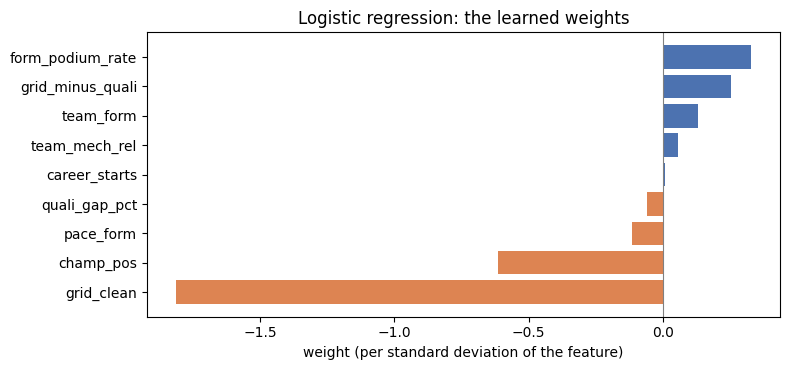

In [286]:
weights = pd.Series(lr.coef_[0], index=F).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(weights.index, weights.values, color=np.where(weights.values > 0, '#4C72B0', '#DD8452'))
ax.axvline(0, color='grey', lw=0.8)
ax.set(xlabel='weight (per standard deviation of the feature)', title='Logistic regression: the learned weights')
plt.tight_layout(); plt.show()

**Reading.**
- **`C` barely matters** once it is 0.1 or more (validation PR-AUC 0.715–0.717), and the largest value is chosen. With only 9 features and over 6,000 training rows, the model has little room to overfit, so it needs almost no regularisation.
- **The validation scores are higher than the training scores** (PR-AUC 0.717 against 0.677). This is not a mistake: 2019–2021 were easier seasons to predict (Mercedes and then Red Bull won most races), and their podium share is a little higher (15.1% against 14.1%), which raises PR-AUC by itself. The grid reference shows the same pattern (0.683 against 0.620).
- **The weights** confirm section 7:
  - The grid slot has by far the largest effect, followed by the championship position and recent form.
  - `grid_minus_quali` is positive: of two drivers starting from the same slot, the one who qualified higher and was moved back has the better chance, as found in 7.2.
  - A smaller `pace_form` and a smaller `quali_gap_pct` (faster) raise the probability.
  - `team_mech_rel` has a small positive weight, which does not mean that breakdowns help. Its information overlaps with team form and the championship position, so its own weight is small and hard to read. The ablation (10.7) tests whether it is needed.

**Limitations of logistic regression.**
- **Straight-line effects only.** Each feature adds a fixed amount per step, so moving from P2 to P1 counts the same as moving from P16 to P15, although the first matters much more for a podium.
- **No interactions.** It cannot learn that a front-row start matters more in a strong team, unless such a combination is added by hand as a new feature.
- **Each row is scored on its own.** The model does not know that a race has exactly 3 podiums, so the probabilities within a race do not add up to 3. This is true of all three models.
- **Correlated features make single weights hard to read**, as `team_mech_rel` shows.

## 10.3 Gradient boosting

**How it works.** A decision tree asks a few yes/no questions about the features ("grid slot ≤ 3?", "team form > 0.4?") and gives each group of drivers at the end of the questions a score. Gradient boosting builds many small trees **one after another**: each new tree is trained to correct the mistakes the previous trees still make, and the final prediction adds up all the trees. Unlike logistic regression it can learn **interactions** (for example, that a front-row start matters more in a strong team) and **non-linear** effects (for example, that the difference between P1 and P3 matters more than between P15 and P17). We use scikit-learn's `HistGradientBoostingClassifier`.

**Settings to choose.**
- `max_depth`: how many questions each tree may ask (deeper trees learn more detailed patterns, but can memorise the training data).
- `learning_rate`: how much each new tree may correct (smaller is more careful but needs more trees).
- `max_iter`: the number of trees.

Every combination is trained on the training part and scored on the validation part.

**Step 1: try settings.** One model per combination, trained on the training part and scored on the validation part.

In [287]:
settings = [(depth, rate, trees) for depth in [2, 3, 5] for rate in [0.03, 0.1] for trees in [100, 300]]

results = []
for depth, rate, trees in settings:
    model = HistGradientBoostingClassifier(max_depth=depth, learning_rate=rate, max_iter=trees,
                                           early_stopping=False, random_state=0)
    model.fit(X_train, y_train)
    train_prob = model.predict_proba(X_train)[:, 1]
    val_prob = model.predict_proba(X_val)[:, 1]
    results.append({'max_depth': depth, 'learning_rate': rate, 'max_iter': trees,
                    'train PR-AUC': average_precision_score(y_train, train_prob),
                    'validation PR-AUC': average_precision_score(y_val, val_prob),
                    'validation ROC-AUC': roc_auc_score(y_val, val_prob)})

gb_tuning = pd.DataFrame(results).sort_values('validation PR-AUC', ascending=False)
show_table(gb_tuning, 'Gradient boosting: choosing the settings (best first)')

max_depth,learning_rate,max_iter,train PR-AUC,validation PR-AUC,validation ROC-AUC
2,0.0300,300,0.7184,0.7525,0.9405
3,0.0300,300,0.7559,0.7522,0.9399
3,0.0300,100,0.7156,0.7456,0.9380
3,0.1000,100,0.7651,0.7426,0.9380
2,0.0300,100,0.6950,0.7423,0.9389
3,0.1000,300,0.8492,0.7417,0.9388
2,0.1000,100,0.7230,0.7401,0.9386
5,0.0300,100,0.7878,0.7372,0.9369
2,0.1000,300,0.7636,0.7347,0.9390
5,0.0300,300,0.8507,0.7208,0.9355


**Step 2: train the model** with the best settings, on the training part.

In [288]:
best = gb_tuning.iloc[0]                                                 # the row with the best validation PR-AUC
GB_PARAMS = dict(max_depth=int(best['max_depth']), learning_rate=float(best['learning_rate']), max_iter=int(best['max_iter']))

gb = HistGradientBoostingClassifier(**GB_PARAMS, early_stopping=False, random_state=0)
gb.fit(X_train, y_train)                                                 # the training happens here
print('trained gradient boosting with', GB_PARAMS, f'on {len(X_train)} rows')

trained gradient boosting with {'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 300} on 6362 rows


**Step 3: scores** on the training and the validation part.

In [289]:
train_prob = gb.predict_proba(X_train)[:, 1]
val_prob = gb.predict_proba(X_val)[:, 1]
p_gb = {'train': train_prob, 'validation': val_prob}

gb_threshold = best_threshold(y_val, val_prob)
gb_results = train_and_validation_scores(train_prob, val_prob, gb_threshold)
print(f'F1 threshold (chosen on validation) = {gb_threshold:.3f}')
display(gb_results.style.format('{:.3f}').set_caption('Gradient boosting: training and validation scores'))

F1 threshold (chosen on validation) = 0.360


,ROC-AUC,PR-AUC,F1,precision,recall,top-3 per race
train,0.941,0.718,0.687,0.650,0.729,0.680
validation,0.941,0.752,0.738,0.693,0.789,0.711


**Step 4: chart.** The loss after each added tree, on the training and the validation part.

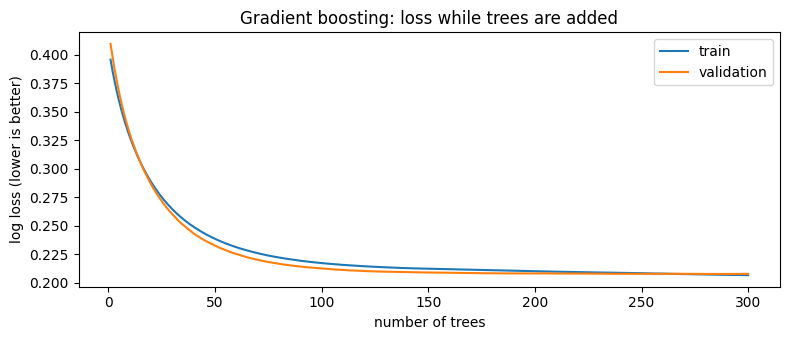

validation loss: lowest 0.2078 after 285 trees | 0.2079 after 300 trees


In [290]:
# staged_predict_proba gives the predictions after 1 tree, after 2 trees, ... after all trees
train_loss, val_loss = [], []
for train_p, val_p in zip(gb.staged_predict_proba(X_train), gb.staged_predict_proba(X_val)):
    train_loss.append(log_loss(y_train, train_p[:, 1]))
    val_loss.append(log_loss(y_val, val_p[:, 1]))
n_trees = range(1, len(train_loss) + 1)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(n_trees, train_loss, label='train')
ax.plot(n_trees, val_loss, label='validation')
ax.set(xlabel='number of trees', ylabel='log loss (lower is better)', title='Gradient boosting: loss while trees are added')
ax.legend(); plt.tight_layout(); plt.show()
best_trees = int(np.argmin(val_loss)) + 1
print(f'validation loss: lowest {min(val_loss):.4f} after {best_trees} trees | {val_loss[-1]:.4f} after {len(val_loss)} trees')

**Reading.**
- **Small trees work best:** the best settings are trees of depth 2, a learning rate of 0.03 and 300 trees.
- **Deep trees memorise the training data.** With depth 5, rate 0.1 and 300 trees, the training PR-AUC reaches 0.980, but the validation PR-AUC falls to 0.700, below the baseline.
- **The chosen model does not overfit:** the two loss curves stay together, and the validation loss is still slowly falling at the end (its lowest point is at 285 of the 300 trees).
- **It beats the baseline on every score** on validation: PR-AUC 0.752 against 0.717, ROC-AUC 0.941 against 0.932, and its top-3 picks per race are right 71.1% of the time against 67.8%. Being able to learn curved effects and interactions is worth something here.

**Limitations of gradient boosting.**
- **Harder to explain.** The prediction is the sum of 300 trees, so there is no single weight per feature. Section 11 (explainability) is needed to see what it relies on.
- **It cannot go beyond the training values.** A tree splits at values it has seen, so a driver with more career starts than anyone in 2003–2018 (the maximum was 321) is treated like the most experienced training driver.
- **More settings to choose,** and choosing them on the validation part makes the validation score slightly optimistic.
- **Each row is scored on its own,** as with logistic regression.

## 10.4 Shallow neural network

**How it works.** A feed-forward neural network passes the 9 features through one or two **hidden layers** of small units. Each unit computes a weighted sum of its inputs and applies a simple non-linear function (ReLU: keep positive values, set negative values to 0). The last layer combines the hidden units into one number, which is turned into a probability with the logistic curve, as in logistic regression. With no hidden layer, the network would *be* a logistic regression; the hidden layers let it learn non-linear effects and interactions, like gradient boosting.

**Training.** The weights start random and are adjusted in small steps (the Adam optimiser, learning rate 0.001, batches of 256 rows) to reduce the **log loss** on the training part. One pass over all training rows is an **epoch**. After every epoch the loss on the validation part is measured. Training stops when the validation loss has not improved for 25 epochs (**early stopping**), and the weights of the best epoch are kept. This stops the network from memorising the training data.

**Settings to choose.**
- The **architecture**: one hidden layer of 16 or 32 units, or two layers (32 then 16). All are "shallow".
- **Weight decay**: a penalty on large weights (the same idea as `C` in logistic regression).

The random start makes results vary a little between runs, so the chosen network is also trained with 5 different random seeds to show how stable its score is.

**The network.** A class with the layers (`__init__`) and what happens to a batch of rows (`forward`). The output is one number per row; the sigmoid turns it into a probability when predicting.

In [291]:
torch.set_num_threads(1)

class Net(nn.Module):
    def __init__(self, hidden):
        super().__init__()
        layers = []
        n_in = len(F)                              # 9 features go in
        for n_units in hidden:                     # e.g. hidden = (32, 16): two hidden layers
            layers.append(nn.Linear(n_in, n_units))
            layers.append(nn.ReLU())
            n_in = n_units
        layers.append(nn.Linear(n_in, 1))          # 1 number comes out
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x).squeeze(1)

print(Net((32, 16)))

Net(
  (layers): Sequential(
    (0): Linear(in_features=9, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


**The data as tensors.** PyTorch works with tensors; `TensorDataset` pairs each row with its label, and the `DataLoader` (inside the training below) serves it in shuffled batches of 256 rows.

In [292]:
X_train_t = torch.tensor(X_train.values, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32)
X_val_t = torch.tensor(X_val.values, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32)

train_data = TensorDataset(X_train_t, y_train_t)
print('training rows:', len(train_data), '| validation rows:', len(X_val_t))

training rows: 6362 | validation rows: 1195


**One epoch of training, the loss, and predictions.** `train_one_epoch` is the usual training loop: for every batch, compute the loss, work out how each weight should change (`backward`) and change it a little (`step`). `evaluate` measures the loss without changing anything, and `predict` gives the probabilities.

In [293]:
loss_fn = nn.BCEWithLogitsLoss()                    # log loss for a yes/no target

def train_one_epoch(model, loader, optimizer):
    model.train()
    for X_batch, y_batch in loader:
        optimizer.zero_grad()                       # forget the previous step
        loss = loss_fn(model(X_batch), y_batch)     # how wrong the model is on this batch
        loss.backward()                             # how each weight should change
        optimizer.step()                            # change the weights a little

def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        return loss_fn(model(X), y).item()

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.tensor(X.values, dtype=torch.float32))).numpy()

**The full training: epochs with early stopping.** `fit_network` repeats `train_one_epoch`, measures the loss on both parts after every epoch, remembers the weights of the best epoch, and stops when the validation loss has not improved for 25 epochs. With `show=True` it prints the progress every 20 epochs. It is a function because it is used three times: to try the settings, to train the final network and to check other random seeds.

In [294]:
def fit_network(hidden, weight_decay, seed=0, max_epochs=400, patience=25, show=False):
    torch.manual_seed(seed)                          # the same random start every time
    model = Net(hidden)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=weight_decay)
    loader = DataLoader(train_data, batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(seed))

    history = []
    best_loss, best_epoch, best_weights = float('inf'), 0, None
    for epoch in range(1, max_epochs + 1):
        train_one_epoch(model, loader, optimizer)
        train_loss = evaluate(model, X_train_t, y_train_t)
        val_loss = evaluate(model, X_val_t, y_val_t)
        history.append({'epoch': epoch, 'train': train_loss, 'validation': val_loss})
        if show and (epoch == 1 or epoch % 20 == 0):
            print(f'epoch {epoch:3d}: train loss {train_loss:.4f} | validation loss {val_loss:.4f}')

        # early stopping
        if val_loss < best_loss - 1e-5:              # a new best epoch: remember its weights
            best_loss, best_epoch, best_weights = val_loss, epoch, copy.deepcopy(model.state_dict())
        elif epoch - best_epoch >= patience:         # no improvement for `patience` epochs: stop
            break

    if show:
        print(f'stopped after epoch {epoch}. Keeping the weights of epoch {best_epoch} (validation loss {best_loss:.4f}).')
    model.load_state_dict(best_weights)
    return model, best_epoch, pd.DataFrame(history).set_index('epoch')

**Step 1: try settings.** One network per combination, trained on the training part and scored on the validation part.

In [295]:
results = []
for hidden in [(16,), (32,), (32, 16)]:
    for weight_decay in [0, 1e-3]:
        model, best_epoch, _ = fit_network(hidden, weight_decay)
        train_prob = predict(model, X_train)
        val_prob = predict(model, X_val)
        results.append({'hidden layers': hidden, 'weight decay': weight_decay, 'best epoch': best_epoch,
                        'train PR-AUC': average_precision_score(y_train, train_prob),
                        'validation PR-AUC': average_precision_score(y_val, val_prob),
                        'validation ROC-AUC': roc_auc_score(y_val, val_prob)})

nn_tuning = pd.DataFrame(results).sort_values('validation PR-AUC', ascending=False)
show_table(nn_tuning, 'Neural network: choosing the settings (best first)')

hidden layers,weight decay,best epoch,train PR-AUC,validation PR-AUC,validation ROC-AUC
"(32, 16)",0.0010,105,0.7056,0.7483,0.9366
"(16,)",0.0000,296,0.7092,0.7463,0.9362
"(32,)",0.0000,216,0.7115,0.7394,0.9369
"(32,)",0.0010,241,0.7070,0.7342,0.9364
"(16,)",0.0010,206,0.7008,0.7327,0.9355
"(32, 16)",0.0000,105,0.7145,0.7306,0.9341


**Step 2: train the network** with the best settings, on the training part. The progress is printed while it learns: both losses should go down, and training stops once the validation loss stops improving.

In [296]:
best = nn_tuning.iloc[0]
NN_HIDDEN, NN_WD = best['hidden layers'], best['weight decay']
print(f'hidden layers {NN_HIDDEN}, weight decay {NN_WD:g}')

nn_model, NN_EPOCHS, nn_history = fit_network(NN_HIDDEN, NN_WD, show=True)      # the training happens here

hidden layers (32, 16), weight decay 0.001
epoch   1: train loss 0.6399 | validation loss 0.6599


epoch  20: train loss 0.2283 | validation loss 0.2286


epoch  40: train loss 0.2203 | validation loss 0.2215


epoch  60: train loss 0.2155 | validation loss 0.2167


epoch  80: train loss 0.2125 | validation loss 0.2143


epoch 100: train loss 0.2107 | validation loss 0.2132


epoch 120: train loss 0.2098 | validation loss 0.2126


stopped after epoch 130. Keeping the weights of epoch 105 (validation loss 0.2126).


**Step 3: scores** on the training and the validation part.

In [297]:
train_prob = predict(nn_model, X_train)
val_prob = predict(nn_model, X_val)
p_nn = {'train': train_prob, 'validation': val_prob}

nn_threshold = best_threshold(y_val, val_prob)
nn_results = train_and_validation_scores(train_prob, val_prob, nn_threshold)
print(f'F1 threshold (chosen on validation) = {nn_threshold:.3f}')
display(nn_results.style.format('{:.3f}').set_caption('Neural network: training and validation scores'))

F1 threshold (chosen on validation) = 0.357


,ROC-AUC,PR-AUC,F1,precision,recall,top-3 per race
train,0.938,0.706,0.671,0.624,0.726,0.661
validation,0.937,0.748,0.738,0.681,0.806,0.717


**Step 4: chart.** The loss after every epoch, on the training and the validation part.

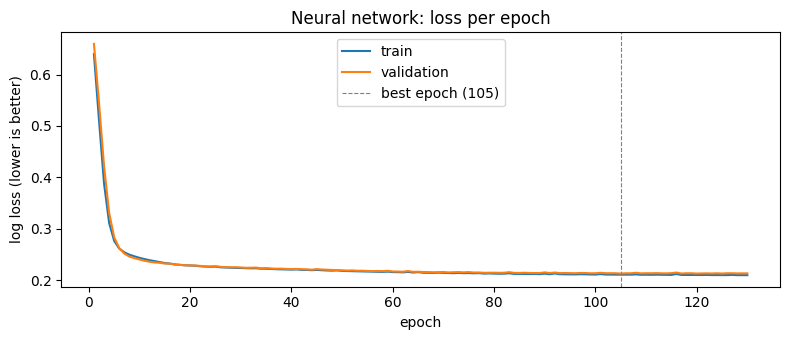

In [298]:
fig, ax = plt.subplots(figsize=(8, 3.5))
nn_history.plot(ax=ax)
ax.axvline(NN_EPOCHS, color='grey', ls='--', lw=0.8, label=f'best epoch ({NN_EPOCHS})')
ax.set(xlabel='epoch', ylabel='log loss (lower is better)', title='Neural network: loss per epoch')
ax.legend(); plt.tight_layout(); plt.show()

**Step 5: how stable is it?** The same network trained with 5 different random starts.

In [299]:
seed_scores = []
for seed in range(5):
    model, _, _ = fit_network(NN_HIDDEN, NN_WD, seed=seed)
    seed_scores.append(average_precision_score(y_val, predict(model, X_val)))
    print(f'seed {seed}: validation PR-AUC {seed_scores[-1]:.4f}')

print(f'mean {np.mean(seed_scores):.4f} ± {np.std(seed_scores, ddof=1):.4f}')

seed 0: validation PR-AUC 0.7483


seed 1: validation PR-AUC 0.7379


seed 2: validation PR-AUC 0.7425


seed 3: validation PR-AUC 0.7223


seed 4: validation PR-AUC 0.7291
mean 0.7360 ± 0.0104


**Reading.**
- **All six networks are close** (validation PR-AUC 0.731–0.748). The chosen one has two hidden layers (32 and 16 units) and a small weight decay, and its best epoch is 105.
- **No overfitting:** the training and validation losses fall together and stay together, and early stopping ends the training 25 epochs after the best one.
- **The score depends on the random start.** Over 5 seeds the validation PR-AUC is 0.736 ± 0.010. The run that was chosen (0.748) is the best of the five, so it is a little lucky; a typical run lies between the baseline (0.717) and gradient boosting (0.752).

**Limitations of the neural network.**
- **Results vary between runs** because of the random start and the random order of the batches, so one run does not give an exact score.
- **A black box.** Its weights cannot be read like those of logistic regression; section 11 is needed to explain it.
- **It needs scaled inputs** and more choices than the other models (layers, units, weight decay, learning rate, epochs, batch size).
- **Little to gain on a small table.** With 9 features and about 6,000 training rows, a network has no advantage over gradient boosting, which usually does at least as well on tables like this.
- **Each row is scored on its own,** as with the other models.

## 10.5 Comparing the models on the validation part

,ROC-AUC,PR-AUC,F1,precision,recall,top-3 per race,threshold
the top 3 on the grid (reference),0.917,0.683,0.719,0.721,0.717,0.722,–
logistic regression (baseline),0.932,0.717,0.732,0.683,0.789,0.678,0.366
gradient boosting,0.941,0.752,0.738,0.693,0.789,0.711,0.360
neural network,0.937,0.748,0.738,0.681,0.806,0.717,0.357


,ROC-AUC,PR-AUC
logistic regression,-0.005,-0.040
gradient boosting,+0.000,-0.034
neural network,+0.002,-0.043


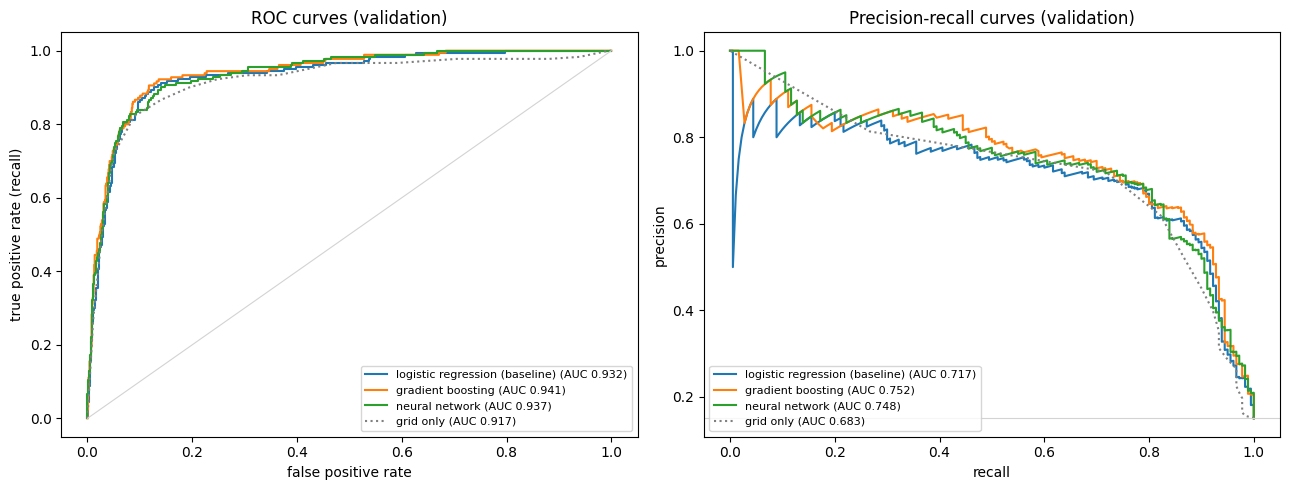

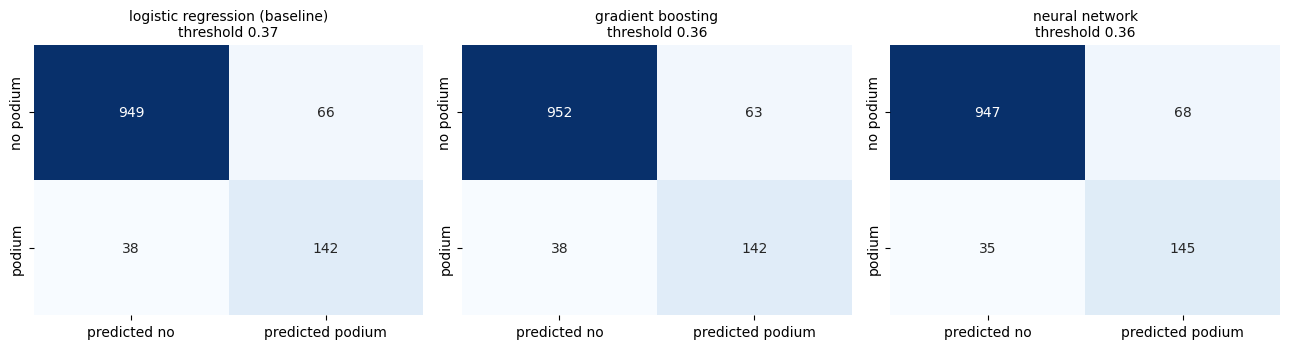

In [300]:
compare = pd.DataFrame({'the top 3 on the grid (reference)': {**grid_results['validation'], 'threshold': np.nan},
                        'logistic regression (baseline)': {**lr_results.loc['validation'], 'threshold': lr_threshold},
                        'gradient boosting': {**gb_results.loc['validation'], 'threshold': gb_threshold},
                        'neural network': {**nn_results.loc['validation'], 'threshold': nn_threshold}}).T
display(compare.style.format('{:.3f}', na_rep='–').set_caption('Validation part (2019-2021): all models'))

gap = pd.DataFrame({name: res.loc['train', ['ROC-AUC', 'PR-AUC']] - res.loc['validation', ['ROC-AUC', 'PR-AUC']]
                    for name, res in [('logistic regression', lr_results), ('gradient boosting', gb_results), ('neural network', nn_results)]}).T
display(gap.style.format('{:+.3f}').set_caption('Training score minus validation score (a large gap = memorising the training data)'))

probs = {'logistic regression (baseline)': p_lr['validation'], 'gradient boosting': p_gb['validation'], 'neural network': p_nn['validation']}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_val, p)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(y_val, p):.3f})')
    prec, rec, _ = precision_recall_curve(y_val, p)
    axes[1].plot(rec, prec, label=f'{name} (AUC {average_precision_score(y_val, p):.3f})')
fpr, tpr, _ = roc_curve(y_val, grid_score['validation'])
axes[0].plot(fpr, tpr, color='grey', ls=':', label=f'grid only (AUC {roc_auc_score(y_val, grid_score["validation"]):.3f})')
prec, rec, _ = precision_recall_curve(y_val, grid_score['validation'])
axes[1].plot(rec, prec, color='grey', ls=':', label=f'grid only (AUC {average_precision_score(y_val, grid_score["validation"]):.3f})')
axes[0].plot([0, 1], [0, 1], color='lightgrey', lw=0.8)
axes[1].axhline(y_val.mean(), color='lightgrey', lw=0.8)
axes[0].set(xlabel='false positive rate', ylabel='true positive rate (recall)', title='ROC curves (validation)')
axes[1].set(xlabel='recall', ylabel='precision', title='Precision-recall curves (validation)')
for ax in axes: ax.legend(fontsize=8, loc='lower right' if ax is axes[0] else 'lower left')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, p), thr in zip(axes, probs.items(), [lr_threshold, gb_threshold, nn_threshold]):
    cm = confusion_matrix(y_val, (p >= thr).astype(int))
    sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap='Blues', ax=ax,
                xticklabels=['predicted no', 'predicted podium'], yticklabels=['no podium', 'podium'])
    ax.set_title(f'{name}\nthreshold {thr:.2f}', fontsize=10)
plt.tight_layout(); plt.show()

**Reading.**
- **All three models beat the grid** on ROC-AUC (0.932–0.941 against 0.917) and PR-AUC (0.717–0.752 against 0.683). Over all races, they rank podium drivers above the rest better than the starting order alone, because they also use form, team and championship information.
- **Gradient boosting is the best model** on ROC-AUC and PR-AUC. The neural network is close behind (its top-3 per race is slightly higher: 71.7% against 71.1%); the baseline is the weakest, but not by much. The extra complexity earns about 0.035 PR-AUC and 3 percentage points of correct top-3 picks.
- **F1 is almost the same for all three** (0.732–0.738). At their thresholds, logistic regression and gradient boosting find 142 of the 180 podium finishers and the network 145, with 63–68 false alarms (confusion matrices).
- **No model memorises the training data.** For all three, the training score is at most 0.002 above the validation score, and for PR-AUC it is below it, because 2019–2021 were easier to predict than 2003–2018 (10.2).
- **Picking exactly 3 drivers per race, the grid is still as good as the models:** its top 3 were right in 130 of 180 picks (72.2%), gradient boosting in 128 (71.1%). The models are better at ranking drivers across all races, but within one race the grid order is already very strong, and the models do not know that each race has exactly 3 podiums. This is the clearest limit of all three.
- **These scores are slightly optimistic:** the settings, the thresholds and the stopping epoch were all chosen on this validation part. The honest score is the one on the unseen test part (2022–2024), after the feature-group ablation.

## 10.6 The final model

Sections 10.2–10.4 trained three models, and 10.5 compared them on the validation part. Before the ablation and the test, one of them is chosen as the **final model**: the model we would use to predict a race, and the one that the ablation (10.7) and the explanations (section 11) are about. The test part is still unseen, so the choice uses the validation part only.

**How sure is a difference?** The validation part has only 60 races and 180 podiums, so a small difference in PR-AUC can be luck. To measure this, the 60 races are **redrawn 1,000 times** (each time some races are drawn twice and some not at all, always with all their drivers), the difference between two models is computed on every redraw, and the middle 95% is kept. A difference is **clear** when this range does not include 0. It is the same idea as the ranges in Q2 and Q3. Whole races are redrawn because the drivers of one race depend on each other: only 3 of them can finish on the podium.

**Step 1: the redraws.** `race_redraws` makes the 1,000 redraws of a set of races, and `change_range` gives the 95% range of the difference between two models. Both are used again in 10.7 and 10.8.

In [301]:
def race_redraws(rows, n=1000, seed=0):
    """n random redraws of the races in `rows`, each race with all its drivers (lists of row positions)."""
    rng = np.random.default_rng(seed)
    races = [np.flatnonzero(rows.raceId.values == r) for r in rows.raceId.unique()]
    return [np.concatenate([races[i] for i in rng.integers(0, len(races), len(races))]) for _ in range(n)]

def change_range(y, p_a, p_b, redraws):
    """95% range of the change in PR-AUC from model A to model B (B minus A) over the redraws."""
    y = np.asarray(y)
    changes = [average_precision_score(y[r], p_b[r]) - average_precision_score(y[r], p_a[r]) for r in redraws]
    return np.percentile(changes, [2.5, 97.5])

val_redraws = race_redraws(val_rows)
print(f'{len(val_redraws)} redraws of the {val_rows.raceId.nunique()} validation races')

1000 redraws of the 60 validation races


**Step 2: gradient boosting against the other two models** on the validation part.

In [302]:
rows = []
for name, p in [('logistic regression (baseline)', p_lr['validation']), ('neural network', p_nn['validation'])]:
    lo, hi = change_range(y_val, p, p_gb['validation'], val_redraws)
    rows.append({'comparison': f'gradient boosting minus {name}',
                 'PR-AUC difference': average_precision_score(y_val, p_gb['validation']) - average_precision_score(y_val, p),
                 '95% range': f'{lo:+.3f} to {hi:+.3f}', 'clear difference?': 'yes' if (lo > 0 or hi < 0) else 'no'})
display(pd.DataFrame(rows).style.format({'PR-AUC difference': '{:+.3f}'}).hide(axis='index')
        .set_caption('Validation part: how sure are the differences?'))
print(f'neural network over 5 random starts (10.4): validation PR-AUC {np.mean(seed_scores):.3f} ± {np.std(seed_scores, ddof=1):.3f}')

comparison,PR-AUC difference,95% range,clear difference?
gradient boosting minus logistic regression (baseline),+0.035,+0.002 to +0.068,yes
gradient boosting minus neural network,+0.004,-0.013 to +0.021,no


neural network over 5 random starts (10.4): validation PR-AUC 0.736 ± 0.010


**Reading and decision: gradient boosting is the final model.**
- **It has the best validation PR-AUC** (0.752, the main score of 10.1), and also the best ROC-AUC (10.5).
- **It is clearly better than the baseline.** Its PR-AUC is 0.035 higher than logistic regression's, and the range of the difference (+0.002 to +0.068) stays above 0. So the extra complexity earns something, which is what the baseline is there to show.
- **Against the neural network the difference is not clear** (+0.004, range −0.013 to +0.021). Gradient boosting is still preferred, because it gives **the same model every time** it is trained, while the network's score moves by about ±0.010 with its random start, and the chosen network run was the best of five (10.4).
- **It is simpler to use and to explain:** it needs no scaling, it learns curved effects and interactions by itself (10.3), and tree models can be explained exactly with SHAP (section 11).

All three models still go to the final test (10.8), because the brief asks for every model's score on the unseen test part.

## 10.7 Feature-group ablation

**What an ablation is.** Section 7 chose each feature **before** training, with evidence from the data. The ablation measures what each group of features **actually contributes after training**: a group is removed, the model is trained again without it, and the validation score shows how much was lost.

**Five experiments.** Removing one group at a time is the brief's ablation and our main experiment. On its own it can mislead when groups overlap: if two groups carry the same information, removing either one costs almost nothing, because the model uses the other (7.10 showed overlaps of up to 0.80 between features). So the features are looked at from five sides:

| Experiment | Models trained | Question it answers |
|---|---|---|
| 1. One group removed | 7, each without one group | How much does the model lose without this group? |
| 2. One group alone | 7, each with one group only | How much does this group know on its own? |
| 3. Two groups removed | 21 pairs (and the 7 single groups again) | Do two groups cover for each other? |
| 4. Every combination | all 127 sets of 1 to 7 groups | Could a smaller set of groups do as well? |
| 5. One feature removed | 9, each without one feature | Does each feature matter on its own, also inside its group? |

**Which models.** The ablation is about the final model, gradient boosting (10.6), always with its settings of 10.3. Experiments 1 and 5 are repeated with logistic regression, a very different model, as a second opinion. The neural network is left out: its score moves by about ±0.010 with its random start (10.4), as much as most group effects, so its ablation could not be read without many repeated runs.

**How a change is judged.** Every model is trained on the training part and scored on the validation part with PR-AUC (the main score). The range of a change comes from redrawing the validation races, as in 10.6.

**The rule for the final feature set, set before the experiments:** a group is removed only if the model is **clearly better without it**. A group whose removal makes no clear difference is kept: it was chosen with evidence in section 7, it is valid at the cutoff, and a change smaller than the luck of 60 races is not a reason to drop it.

**The groups.** The 9 features were built in 7 groups in section 7 (the `group` column of `FEATURES`, 7.10).

In [303]:
import itertools

GROUPS = {}
for f, (group, *_) in FEATURES.items():
    GROUPS.setdefault(group, []).append(f)

table(pd.DataFrame({'group': list(GROUPS), 'features': [', '.join(fs) for fs in GROUPS.values()]}),
      caption='The 7 feature groups')

group,features
grid,grid_clean
qualifying,"grid_minus_quali, quali_gap_pct"
driver form,"form_podium_rate, career_starts"
driver standings,champ_pos
team form,team_form
reliability,team_mech_rel
pace (candidate),pace_form


**Helper functions.** One model is trained per set of features, with the same settings and the same rows every time; only the columns change.

In [304]:
def features_without(*groups):
    """The feature columns left after removing the given groups."""
    return [f for f in F if not any(f in GROUPS[g] for g in groups)]

def features_of(*groups):
    """The feature columns of the given groups only."""
    return [f for g in groups for f in GROUPS[g]]

def gb_val_prob(cols):
    """Gradient boosting with the settings of 10.3, trained on the training part with these columns only."""
    model = HistGradientBoostingClassifier(**GB_PARAMS, early_stopping=False, random_state=0)
    return model.fit(X_train[cols], y_train).predict_proba(X_val[cols])[:, 1]

def lr_val_prob(cols):
    """Logistic regression with the C of 10.2, trained the same way."""
    model = LogisticRegression(C=LR_C, max_iter=5000)
    return model.fit(X_train[cols], y_train).predict_proba(X_val[cols])[:, 1]

### Experiment 1: one group removed

For each group: train both models without it, and compare the validation PR-AUC with the model that has all 9 features. A negative change means the model is worse without the group.

In [305]:
p_gb_all, p_lr_all = gb_val_prob(F), lr_val_prob(F)
gb_all, lr_all = average_precision_score(y_val, p_gb_all), average_precision_score(y_val, p_lr_all)

rows = []
for g in GROUPS:
    p_gb_without, p_lr_without = gb_val_prob(features_without(g)), lr_val_prob(features_without(g))
    lo, hi = change_range(y_val, p_gb_all, p_gb_without, val_redraws)
    rows.append({'group removed': g, 'gradient boosting PR-AUC': average_precision_score(y_val, p_gb_without),
                 'change': average_precision_score(y_val, p_gb_without) - gb_all, 'lo': lo, 'hi': hi,
                 'logistic regression PR-AUC': average_precision_score(y_val, p_lr_without),
                 'change (logistic regression)': average_precision_score(y_val, p_lr_without) - lr_all})
leave_one = pd.DataFrame(rows).sort_values('change').reset_index(drop=True)
leave_one['clear change?'] = np.where(leave_one.hi < 0, 'yes, worse', np.where(leave_one.lo > 0, 'yes, better', 'no'))

print(f'all 9 features: gradient boosting PR-AUC {gb_all:.3f} | logistic regression PR-AUC {lr_all:.3f}')
display(leave_one.assign(**{'95% range of the change': [f'{a:+.3f} to {b:+.3f}' for a, b in zip(leave_one.lo, leave_one.hi)]})
        [['group removed', 'gradient boosting PR-AUC', 'change', '95% range of the change', 'clear change?',
          'logistic regression PR-AUC', 'change (logistic regression)']]
        .style.format({'gradient boosting PR-AUC': '{:.3f}', 'logistic regression PR-AUC': '{:.3f}',
                       'change': '{:+.3f}', 'change (logistic regression)': '{:+.3f}'})
        .hide(axis='index').set_caption('Experiment 1: one group removed (validation part)'))

all 9 features: gradient boosting PR-AUC 0.752 | logistic regression PR-AUC 0.717


group removed,gradient boosting PR-AUC,change,95% range of the change,clear change?,logistic regression PR-AUC,change (logistic regression)
grid,0.670,-0.082,-0.127 to -0.038,"yes, worse",0.669,-0.048
pace (candidate),0.741,-0.012,-0.028 to +0.006,no,0.717,-0.001
driver standings,0.741,-0.012,-0.023 to -0.002,"yes, worse",0.711,-0.006
reliability,0.747,-0.006,-0.013 to +0.001,no,0.718,+0.001
team form,0.748,-0.004,-0.014 to +0.005,no,0.725,+0.007
driver form,0.754,+0.002,-0.010 to +0.012,no,0.721,+0.004
qualifying,0.755,+0.003,-0.015 to +0.019,no,0.716,-0.002


**Chart.** The change for each group; the black line on each blue bar is its 95% range.

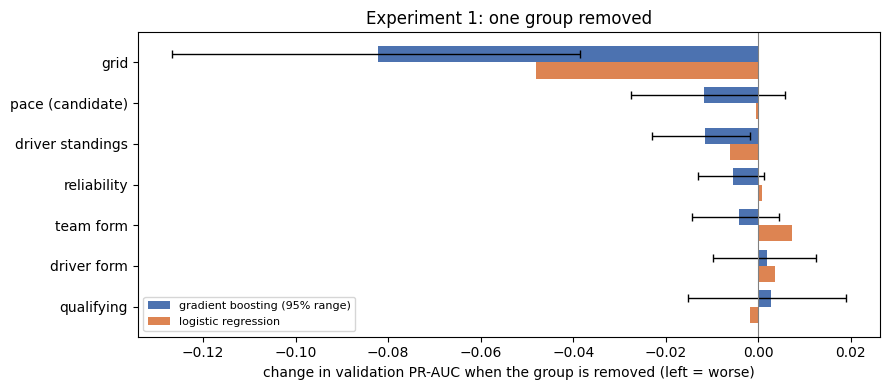

In [306]:
d = leave_one.iloc[::-1]
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(y + 0.2, d.change, height=0.4, color='#4C72B0', label='gradient boosting (95% range)',
        xerr=[d.change - d.lo, d.hi - d.change], error_kw={'lw': 1, 'capsize': 3})
ax.barh(y - 0.2, d['change (logistic regression)'], height=0.4, color='#DD8452', label='logistic regression')
ax.axvline(0, color='grey', lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(d['group removed'])
ax.set(xlabel='change in validation PR-AUC when the group is removed (left = worse)', title='Experiment 1: one group removed')
ax.legend(fontsize=8, loc='lower left'); plt.tight_layout(); plt.show()

**Reading.**
- **The grid is by far the most important group.** Without it, the PR-AUC of gradient boosting falls from 0.752 to 0.670 (−0.082), and the loss is clear. Logistic regression loses the most without it too (−0.048).
- **The championship position is the only other group with a clear loss** (−0.012, range −0.023 to −0.002).
- **Pace (−0.012), reliability (−0.006) and team form (−0.004)** lower the score when removed, but their ranges include 0, so the loss is not clear.
- **Driver form (+0.002) and qualifying (+0.003)** lose nothing on validation; again the changes are far from clear.
- **Logistic regression agrees on the two clear groups** (grid, standings); for the others its changes are all smaller than 0.01, in both directions.

A small loss does not mean that a group knows little. Experiment 2 shows why.

### Experiment 2: one group alone

Each group on its own: train gradient boosting with only that group's features. For comparison, the table repeats the change from experiment 1.

In [307]:
rows = []
for g in GROUPS:
    rows.append({'group': g, 'PR-AUC with this group only': average_precision_score(y_val, gb_val_prob(features_of(g))),
                 'change when it is removed (experiment 1)': leave_one.set_index('group removed').loc[g, 'change']})
alone = pd.DataFrame(rows).sort_values('PR-AUC with this group only', ascending=False)
display(alone.style.format({'PR-AUC with this group only': '{:.3f}', 'change when it is removed (experiment 1)': '{:+.3f}'})
        .hide(axis='index').set_caption('Experiment 2: each group on its own (gradient boosting, validation part)'))

group,PR-AUC with this group only,change when it is removed (experiment 1)
grid,0.683,-0.082
driver standings,0.629,-0.012
team form,0.596,-0.004
driver form,0.587,+0.002
pace (candidate),0.582,-0.012
qualifying,0.496,+0.003
reliability,0.231,-0.006


**Chart.** The dashed line is the model with all 9 features, the dotted line is guessing (the share of podiums in the validation part).

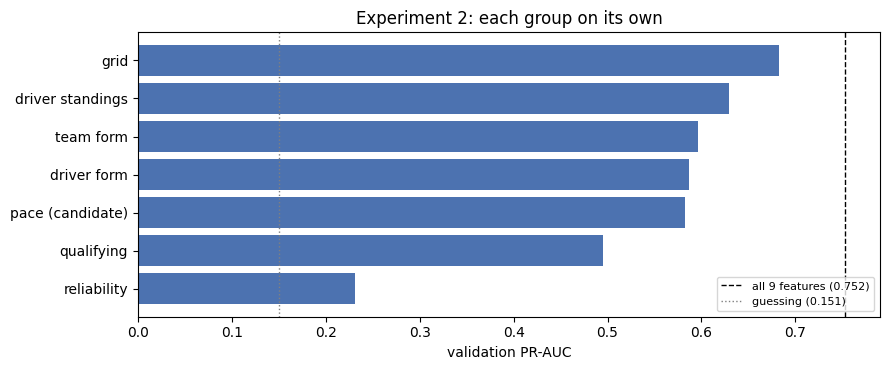

In [308]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(alone.group[::-1], alone['PR-AUC with this group only'][::-1], color='#4C72B0')
ax.axvline(gb_all, color='black', ls='--', lw=1, label=f'all 9 features ({gb_all:.3f})')
ax.axvline(y_val.mean(), color='grey', ls=':', lw=1, label=f'guessing ({y_val.mean():.3f})')
ax.set(xlabel='validation PR-AUC', title='Experiment 2: each group on its own')
ax.legend(fontsize=8, loc='lower right'); plt.tight_layout(); plt.show()

**Reading.**
- **Every group except reliability is strong on its own:** the grid reaches 0.683, the championship position 0.629, team form 0.596, driver form 0.587, pace 0.582 and qualifying 0.496, all far above guessing (0.151). Reliability alone reaches only 0.231: it is weak on its own, as found in 7.6.
- **Strong alone, but little lost when removed.** Driver form alone reaches 0.587, yet removing it from the full model costs nothing (+0.002). The other groups carry the same information: a driver in good form is usually high in the championship and in a strong team (7.10). So a small change in experiment 1 means that a group can be **replaced** by the others, not that it is **useless**. Experiment 3 tests this directly.

### Experiment 3: two groups removed together

Every pair of groups is removed together (21 pairs). The diagonal of the chart repeats experiment 1 (one group removed). If two groups cover for each other, removing both costs more than removing each one alone.

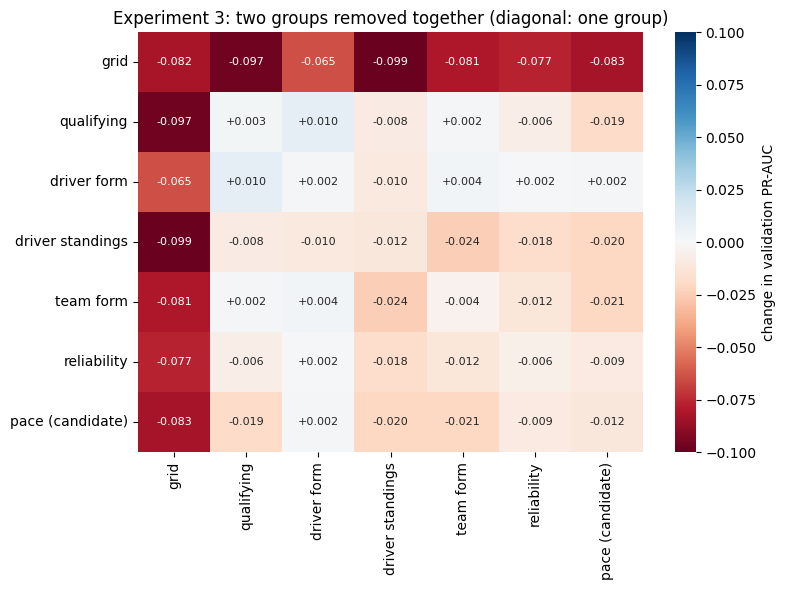

In [309]:
names = list(GROUPS)
pair_change = pd.DataFrame(np.nan, index=names, columns=names)
for a, b in itertools.combinations_with_replacement(names, 2):       # a == b: one group removed, as in experiment 1
    p = gb_val_prob(features_without(a, b))
    pair_change.loc[a, b] = pair_change.loc[b, a] = average_precision_score(y_val, p) - gb_all

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(pair_change, annot=True, fmt='+.3f', cmap='RdBu', center=0, vmin=-0.1, vmax=0.1, ax=ax, annot_kws={'size': 8},
            cbar_kws={'label': 'change in validation PR-AUC'})
ax.set_title('Experiment 3: two groups removed together (diagonal: one group)')
plt.tight_layout(); plt.show()

**Reading.**
- **Overlapping groups cover for each other.** The championship position and team form cost −0.012 and −0.004 when removed one at a time, but −0.024 together. Pace with team form costs −0.021, pace with the championship position −0.020, and pace with qualifying −0.019, while qualifying alone costs nothing. When one of these groups is removed, the model gets most of its information from the other.
- **Without the grid, every pair loses a lot** (−0.065 to −0.099): no other group can replace the starting slot.
- **Driver form overlaps with everything.** Removing it together with any other group (except the grid) changes the score by at most +0.010 or −0.010, so whatever it knows, the other groups also know.

### Experiment 4: every combination of groups

All 127 possible sets of 1 to 7 groups, each trained with gradient boosting. This shows whether a smaller set of groups could do as well as all of them.

In [310]:
rows = []
for k in range(1, len(names) + 1):
    for combo in itertools.combinations(names, k):
        p = gb_val_prob(features_of(*combo))
        rows.append({'groups kept': ', '.join(combo), 'number of groups': k, 'PR-AUC': average_precision_score(y_val, p), 'p': p})
every = pd.DataFrame(rows)

best_per_size = every.loc[every.groupby('number of groups')['PR-AUC'].idxmax()]
display(best_per_size[['number of groups', 'groups kept', 'PR-AUC']].style.format({'PR-AUC': '{:.3f}'})
        .hide(axis='index').set_caption(f'Experiment 4: the best of the {len(every)} combinations, for each number of groups'))

best_set = every.loc[every['PR-AUC'].idxmax()]
lo, hi = change_range(y_val, p_gb_all, best_set.p, val_redraws)
print(f'best combination: {best_set["groups kept"]} | PR-AUC {best_set["PR-AUC"]:.3f}, '
      f'{best_set["PR-AUC"] - gb_all:+.3f} against all 9 features (95% range {lo:+.3f} to {hi:+.3f})')
print(f'combinations within 0.01 of all 9 features, or better: {(every["PR-AUC"] >= gb_all - 0.01).sum()} of {len(every)}')

number of groups,groups kept,PR-AUC
1,grid,0.683
2,"grid, driver standings",0.743
3,"grid, driver standings, reliability",0.759
4,"grid, driver standings, reliability, pace (candidate)",0.757
5,"grid, driver standings, team form, reliability, pace (candidate)",0.763
6,"grid, driver form, driver standings, team form, reliability, pace (candidate)",0.755
7,"grid, qualifying, driver form, driver standings, team form, reliability, pace (candidate)",0.752


best combination: grid, driver standings, team form, reliability, pace (candidate) | PR-AUC 0.763, +0.010 against all 9 features (95% range -0.010 to +0.028)
combinations within 0.01 of all 9 features, or better: 30 of 127


**Chart.** Every combination is one light dot, placed by how many groups it keeps. The line joins the best combination of each size; the black dot is the model with all 9 features.

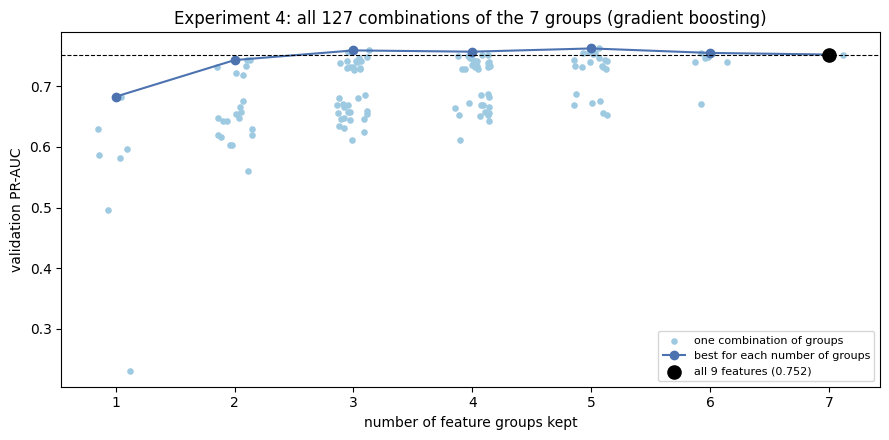

In [311]:
fig, ax = plt.subplots(figsize=(9, 4.5))
jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(every))           # spreads the dots sideways, so they do not overlap
ax.scatter(every['number of groups'] + jitter, every['PR-AUC'], s=14, color='#9ecae1', label='one combination of groups')
ax.plot(best_per_size['number of groups'], best_per_size['PR-AUC'], color='#4C72B0', marker='o', label='best for each number of groups')
ax.scatter([len(names)], [gb_all], s=90, color='black', zorder=3, label=f'all 9 features ({gb_all:.3f})')
ax.axhline(gb_all, color='black', ls='--', lw=0.8)
ax.set(xlabel='number of feature groups kept', ylabel='validation PR-AUC',
       title=f'Experiment 4: all {len(every)} combinations of the 7 groups (gradient boosting)')
ax.legend(fontsize=8, loc='lower right'); plt.tight_layout(); plt.show()

**Reading.**
- **Two groups already do most of the work:** the grid and the championship position together reach 0.743. From three groups on, the best combinations are between 0.755 and 0.763, and all 9 features reach 0.752.
- **Many different sets do about equally well:** 30 of the 127 combinations are within 0.01 of all 9 features, or better. This is what overlapping groups look like: the same information can come from several places.
- **The best combination is not clearly better.** Grid, championship position, team form, reliability and pace reach 0.763, +0.010 above all 9 features, but the range of the difference (−0.010 to +0.028) includes 0. It is also the highest of 127 scores measured on the same 60 races: when many sets are tried, the one that comes out on top is partly the luckiest, so its lead would probably shrink on new races.

### Experiment 5: one feature removed

The same as experiment 1, but for single features: each of the 9 features is removed on its own. This matters for the two groups that hold two features (qualifying and driver form), where one feature could be needed and the other not.

In [312]:
rows = []
for f in F:
    cols = [c for c in F if c != f]
    p_gb_without, p_lr_without = gb_val_prob(cols), lr_val_prob(cols)
    lo, hi = change_range(y_val, p_gb_all, p_gb_without, val_redraws)
    rows.append({'feature removed': f, 'group': FEATURES[f][0], 'gradient boosting PR-AUC': average_precision_score(y_val, p_gb_without),
                 'change': average_precision_score(y_val, p_gb_without) - gb_all, 'lo': lo, 'hi': hi,
                 'change (logistic regression)': average_precision_score(y_val, p_lr_without) - lr_all})
leave_one_feature = pd.DataFrame(rows).sort_values('change').reset_index(drop=True)
leave_one_feature['clear change?'] = np.where(leave_one_feature.hi < 0, 'yes, worse', np.where(leave_one_feature.lo > 0, 'yes, better', 'no'))

display(leave_one_feature.assign(**{'95% range of the change': [f'{a:+.3f} to {b:+.3f}' for a, b in zip(leave_one_feature.lo, leave_one_feature.hi)]})
        [['feature removed', 'group', 'gradient boosting PR-AUC', 'change', '95% range of the change', 'clear change?', 'change (logistic regression)']]
        .style.format({'gradient boosting PR-AUC': '{:.3f}', 'change': '{:+.3f}', 'change (logistic regression)': '{:+.3f}'})
        .hide(axis='index').set_caption('Experiment 5: one feature removed (validation part)'))

feature removed,group,gradient boosting PR-AUC,change,95% range of the change,clear change?,change (logistic regression)
grid_clean,grid,0.670,-0.082,-0.127 to -0.038,"yes, worse",-0.048
pace_form,pace (candidate),0.741,-0.012,-0.028 to +0.006,no,-0.001
champ_pos,driver standings,0.741,-0.012,-0.023 to -0.002,"yes, worse",-0.006
team_mech_rel,reliability,0.747,-0.006,-0.013 to +0.001,no,+0.001
team_form,team form,0.748,-0.004,-0.014 to +0.005,no,+0.007
grid_minus_quali,qualifying,0.752,-0.001,-0.004 to +0.001,no,-0.001
quali_gap_pct,qualifying,0.753,+0.000,-0.014 to +0.013,no,+0.001
career_starts,driver form,0.754,+0.002,-0.010 to +0.012,no,-0.000
form_podium_rate,driver form,0.754,+0.002,-0.004 to +0.008,no,+0.003


**Chart.** The change for each feature; the black line on each blue bar is its 95% range.

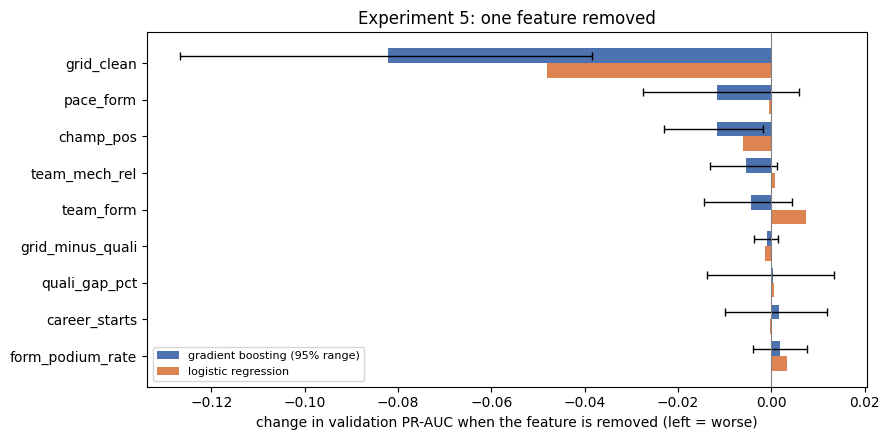

In [313]:
d = leave_one_feature.iloc[::-1]
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(y + 0.2, d.change, height=0.4, color='#4C72B0', label='gradient boosting (95% range)',
        xerr=[d.change - d.lo, d.hi - d.change], error_kw={'lw': 1, 'capsize': 3})
ax.barh(y - 0.2, d['change (logistic regression)'], height=0.4, color='#DD8452', label='logistic regression')
ax.axvline(0, color='grey', lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(d['feature removed'])
ax.set(xlabel='change in validation PR-AUC when the feature is removed (left = worse)', title='Experiment 5: one feature removed')
ax.legend(fontsize=8, loc='lower left'); plt.tight_layout(); plt.show()

**Reading.**
- **The same two are clearly needed:** `grid_clean` (−0.082) and `champ_pos` (−0.012). For the groups with one feature, the result is the same as in experiment 1.
- **Qualifying:** `grid_minus_quali` changes the score by only −0.001 (range −0.004 to +0.001), and `quali_gap_pct` by +0.000. Each matters very little on its own: `grid_minus_quali` is 0 for most drivers (72.5% start where they qualified, 7.2), and the speed shown by `quali_gap_pct` is also shown by the grid slot and by `pace_form` (in experiment 3, qualifying and pace removed together cost −0.019).
- **Driver form:** removing `form_podium_rate` or `career_starts` gives +0.002 each, not clear. Their information is also in the championship position and team form (experiment 2).
- **No feature makes the model clearly better when it is removed.** Logistic regression agrees: all its changes except the grid are within ±0.008.

### Decision: the final features

**All 7 groups (the 9 features) are kept.**
- **No group makes the model clearly better when it is removed** (experiment 1), so by the rule set above, none is dropped.
- **No single feature makes it clearly better either** (experiment 5), so all 9 features stay. This includes `grid_minus_quali`: it adds very little (−0.001 when removed), but the model is not better without it.
- **Two groups are clearly needed:** the grid and the championship position.
- **Pace is no longer a candidate.** In 7.8 it was kept as a candidate, to be decided with the training seasons and the ablation. It is complete from 1997, so it has a value in all our seasons (2003–2024); it is strong on its own (0.582), and removing it costs 0.012, and about 0.020 together with team form or the standings.
- **Reliability is kept.** 7.6 asked whether it is worth keeping. It is weak on its own (0.231), and removing it costs a little (−0.006, and −0.009 to −0.018 together with team form, the championship position or pace), but the loss is not clear in either direction. By the rule, it stays.
- **Driver form and qualifying are kept** for the same reason: the model loses nothing without them on validation, but they are strong on their own, valid at the cutoff, and their information is shared with other groups rather than missing.
- **A smaller set is not chosen.** The best of the 127 combinations is not clearly better, and it was picked from many tries on the same races.

The final model is therefore the one of 10.3: gradient boosting on the 9 features. Before the test it is trained once more, on 2003–2021.

## 10.8 The final test

The test part (2022–2024) has not been used so far: every setting, threshold, feature and the final model were chosen on the training and validation parts. It is now used **once**.

**Fixed before the test:**
- the features: all 9 (10.7);
- the settings of each model (10.2–10.4) and its F1 threshold, chosen on the validation part and used unchanged;
- the final model: gradient boosting (10.6). All three models are scored, because the brief asks for every model's score on the unseen test part.

**Trained again on 2003–2021.** As planned in 8.2, the models are trained again on the training and validation seasons together. The validation seasons are the closest to the test seasons, so they are the most useful to learn from, and nothing about the models is being chosen any more. The preprocessing values (fill values, capping limits and scaling) are also learned again from 2003–2021, with the `preprocess` function of 9.6, so the rule of section 9 still holds: nothing is learned from the test seasons.

**The network without a validation part.** Early stopping (10.4) watches the validation loss. With 2003–2021 all used for training, there is nothing left to watch, so the network is trained for a fixed number of epochs: the best epoch found in 10.4.

**Step 1: preprocessing learned from 2003–2021.** The table shows that the learned values move a little when three more seasons are added.

In [314]:
final_mask = data.split.isin(['train', 'validation'])                 # 2003-2021
final_fill, final_caps, final_scaler, final_scaled = preprocess(final_mask)

X_final, y_final = final_scaled.loc[final_mask, F], final_scaled.loc[final_mask, 'podium']
test_rows = final_scaled[final_scaled.split == 'test']
X_test_final, y_test_final = test_rows[F], test_rows.podium
print(f'training rows (2003-2021): {len(X_final)} | test rows (2022-2024): {len(X_test_final)}')

learned_values = pd.DataFrame({
    'learned from 2003-2018 (sections 9 and 10)': [learned['quali_gap_pct'], caps['team_mech_rel'][1], scaler.mean_[F.index('career_starts')]],
    'learned from 2003-2021 (final)': [final_fill['quali_gap_pct'], final_caps['team_mech_rel'][1], final_scaler.mean_[F.index('career_starts')]]},
    index=['fill value: quali_gap_pct', 'capping limit: team_mech_rel high', 'scaling mean: career_starts'])
display(learned_values.style.format('{:.3f}').set_caption('Some preprocessing values, learned again from 2003-2021'))

training rows (2003-2021): 7557 | test rows (2022-2024): 1352


,learned from 2003-2018 (sections 9 and 10),learned from 2003-2021 (final)
fill value: quali_gap_pct,1.357,1.303
capping limit: team_mech_rel high,0.319,0.296
scaling mean: career_starts,91.964,95.771


**Step 2: the network for a fixed number of epochs.** The same network and the same training steps as in 10.4 (`Net`, `train_one_epoch`), without early stopping.

In [315]:
def fit_network_fixed(hidden, weight_decay, epochs, X, y, seed=0):
    """The network of 10.4, trained for a fixed number of epochs (no validation part is left to stop on)."""
    torch.manual_seed(seed)
    model = Net(hidden)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=weight_decay)
    rows = TensorDataset(torch.tensor(X.values, dtype=torch.float32), torch.tensor(y.values, dtype=torch.float32))
    loader = DataLoader(rows, batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(seed))
    for epoch in range(epochs):
        train_one_epoch(model, loader, optimizer)
    return model

**Step 3: train the three models on 2003–2021,** with the settings chosen in 10.2–10.4.

In [316]:
lr_final = LogisticRegression(C=LR_C, max_iter=5000).fit(X_final, y_final)
gb_final = HistGradientBoostingClassifier(**GB_PARAMS, early_stopping=False, random_state=0).fit(X_final, y_final)
nn_final = fit_network_fixed(NN_HIDDEN, NN_WD, NN_EPOCHS, X_final, y_final)

print(f'logistic regression: C = {LR_C:g}')
print('gradient boosting:', GB_PARAMS)
print(f'neural network: hidden layers {NN_HIDDEN}, weight decay {NN_WD:g}, {NN_EPOCHS} epochs (the best epoch in 10.4)')
print(f'all three trained on {len(X_final)} rows (2003-2021)')

logistic regression: C = 100
gradient boosting: {'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 300}
neural network: hidden layers (32, 16), weight decay 0.001, 105 epochs (the best epoch in 10.4)
all three trained on 7557 rows (2003-2021)


**Step 4: the test scores.** Each model is scored on the test part, with the threshold chosen on the validation part. This is the only time the test part is used.

In [317]:
p_test = {'logistic regression (baseline)': lr_final.predict_proba(X_test_final)[:, 1],
          'gradient boosting (final model)': gb_final.predict_proba(X_test_final)[:, 1],
          'neural network': predict(nn_final, X_test_final)}
thresholds = {'logistic regression (baseline)': lr_threshold, 'gradient boosting (final model)': gb_threshold,
              'neural network': nn_threshold}                         # chosen on validation in 10.2-10.4, not changed
grid_test = -capped.loc[test_rows.index, 'grid_clean'].values         # reference: a smaller grid slot = a higher "probability"

test_results = pd.DataFrame({'the top 3 on the grid (reference)': {**scores(test_rows, grid_test, -3), 'threshold': np.nan},
                             **{name: {**scores(test_rows, p, thresholds[name]), 'threshold': thresholds[name]}
                                for name, p in p_test.items()}}).T
display(test_results.style.format('{:.3f}', na_rep='–').set_caption('Test part (2022-2024): all models, scored once'))

,ROC-AUC,PR-AUC,F1,precision,recall,top-3 per race,threshold
the top 3 on the grid (reference),0.913,0.647,0.649,0.650,0.647,0.652,–
logistic regression (baseline),0.937,0.717,0.679,0.646,0.716,0.657,0.366
gradient boosting (final model),0.939,0.707,0.674,0.634,0.721,0.667,0.360
neural network,0.933,0.702,0.677,0.628,0.735,0.652,0.357


**Step 5: every model on every part.** Training and validation scores come from 10.2–10.4 (models trained on 2003–2018); test scores from the models trained on 2003–2021.

In [318]:
rows = []
for name, res in [('logistic regression (baseline)', lr_results), ('gradient boosting (final model)', gb_results), ('neural network', nn_results)]:
    for part in ['train', 'validation']:
        rows.append({'model': name, 'part': part, **res.loc[part]})
    rows.append({'model': name, 'part': 'test', **test_results.loc[name].drop('threshold')})
all_parts = pd.DataFrame(rows)
display(all_parts.style.format({c: '{:.3f}' for c in all_parts.columns[2:]}).hide(axis='index')
        .set_caption('Every model on every part'))

model,part,ROC-AUC,PR-AUC,F1,precision,recall,top-3 per race
logistic regression (baseline),train,0.927,0.677,0.658,0.615,0.708,0.644
logistic regression (baseline),validation,0.932,0.717,0.732,0.683,0.789,0.678
logistic regression (baseline),test,0.937,0.717,0.679,0.646,0.716,0.657
gradient boosting (final model),train,0.941,0.718,0.687,0.650,0.729,0.680
gradient boosting (final model),validation,0.941,0.752,0.738,0.693,0.789,0.711
gradient boosting (final model),test,0.939,0.707,0.674,0.634,0.721,0.667
neural network,train,0.938,0.706,0.671,0.624,0.726,0.661
neural network,validation,0.937,0.748,0.738,0.681,0.806,0.717
neural network,test,0.933,0.702,0.677,0.628,0.735,0.652


**Step 6: how sure are the test differences?** The 68 test races are redrawn 1,000 times, as in 10.6.

In [319]:
test_redraws = race_redraws(test_rows)
gb_name, lr_name, nn_name = 'gradient boosting (final model)', 'logistic regression (baseline)', 'neural network'
comparisons = [('gradient boosting minus logistic regression', p_test[lr_name], p_test[gb_name]),
               ('gradient boosting minus the neural network', p_test[nn_name], p_test[gb_name]),
               ('logistic regression minus the grid', grid_test, p_test[lr_name]),
               ('gradient boosting minus the grid', grid_test, p_test[gb_name]),
               ('neural network minus the grid', grid_test, p_test[nn_name])]
rows = []
for name, p_a, p_b in comparisons:
    lo, hi = change_range(y_test_final, p_a, p_b, test_redraws)
    rows.append({'comparison': name,
                 'PR-AUC difference': average_precision_score(y_test_final, p_b) - average_precision_score(y_test_final, p_a),
                 '95% range': f'{lo:+.3f} to {hi:+.3f}', 'clear difference?': 'yes' if (lo > 0 or hi < 0) else 'no'})
display(pd.DataFrame(rows).style.format({'PR-AUC difference': '{:+.3f}'}).hide(axis='index')
        .set_caption('Test part: how sure are the differences?'))

comparison,PR-AUC difference,95% range,clear difference?
gradient boosting minus logistic regression,-0.010,-0.039 to +0.018,no
gradient boosting minus the neural network,+0.005,-0.014 to +0.026,no
logistic regression minus the grid,+0.070,+0.027 to +0.108,yes
gradient boosting minus the grid,+0.060,+0.028 to +0.094,yes
neural network minus the grid,+0.055,+0.023 to +0.086,yes


**Step 7: charts.** The ROC and precision-recall curves on the test part, with the grid as a reference.

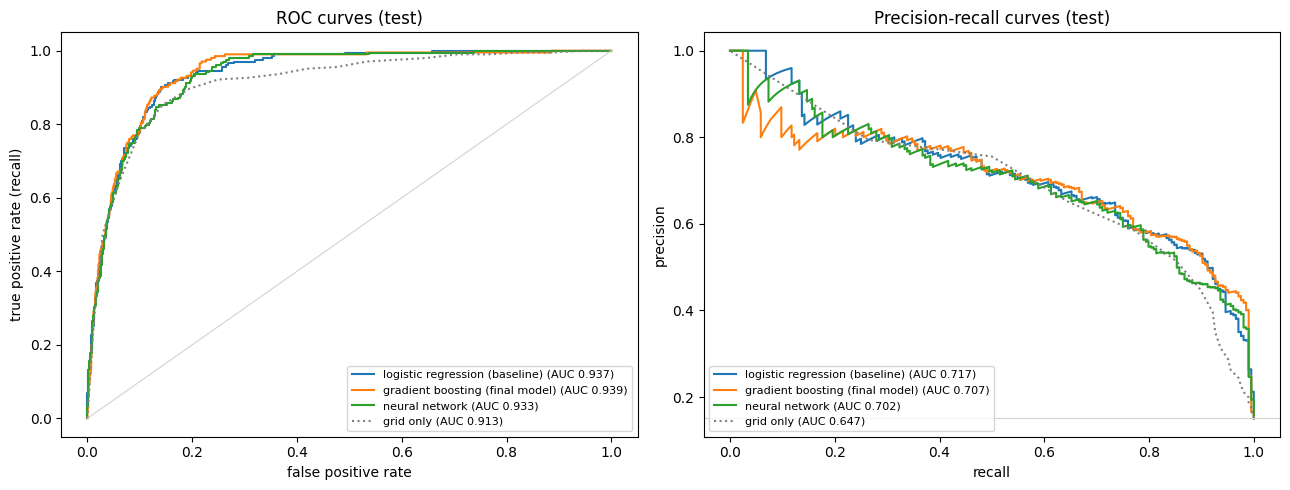

In [320]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in p_test.items():
    fpr, tpr, _ = roc_curve(y_test_final, p)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(y_test_final, p):.3f})')
    prec, rec, _ = precision_recall_curve(y_test_final, p)
    axes[1].plot(rec, prec, label=f'{name} (AUC {average_precision_score(y_test_final, p):.3f})')
fpr, tpr, _ = roc_curve(y_test_final, grid_test)
axes[0].plot(fpr, tpr, color='grey', ls=':', label=f'grid only (AUC {roc_auc_score(y_test_final, grid_test):.3f})')
prec, rec, _ = precision_recall_curve(y_test_final, grid_test)
axes[1].plot(rec, prec, color='grey', ls=':', label=f'grid only (AUC {average_precision_score(y_test_final, grid_test):.3f})')
axes[0].plot([0, 1], [0, 1], color='lightgrey', lw=0.8)
axes[1].axhline(y_test_final.mean(), color='lightgrey', lw=0.8)
axes[0].set(xlabel='false positive rate', ylabel='true positive rate (recall)', title='ROC curves (test)')
axes[1].set(xlabel='recall', ylabel='precision', title='Precision-recall curves (test)')
for ax in axes: ax.legend(fontsize=8, loc='lower right' if ax is axes[0] else 'lower left')
plt.tight_layout(); plt.show()

The confusion matrices on the test part, at the thresholds chosen on validation.

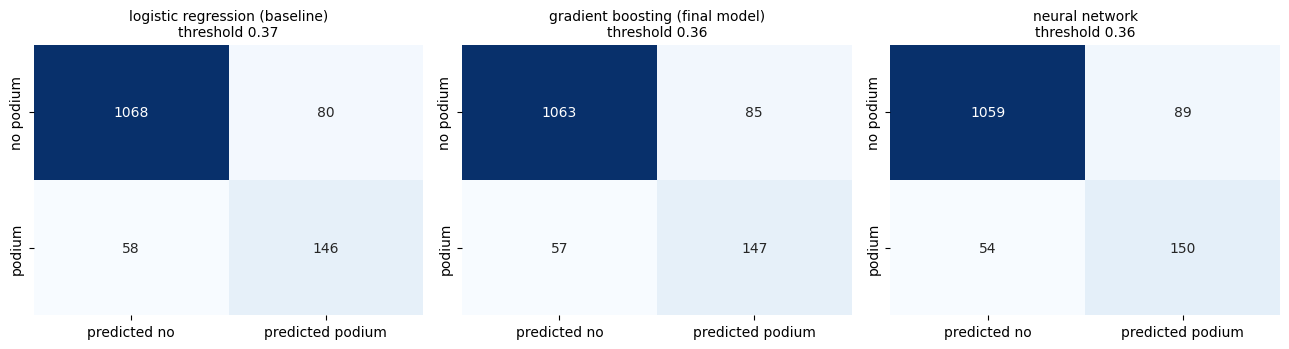

In [321]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, p) in zip(axes, p_test.items()):
    cm = confusion_matrix(y_test_final, (p >= thresholds[name]).astype(int))
    sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap='Blues', ax=ax,
                xticklabels=['predicted no', 'predicted podium'], yticklabels=['no podium', 'podium'])
    ax.set_title(f'{name}\nthreshold {thresholds[name]:.2f}', fontsize=10)
plt.tight_layout(); plt.show()

**Step 8: the most confident predictions.** PR-AUC depends most on the top of the ranking, so the models' highest probabilities show where their PR-AUC differs.

In [322]:
table(pd.DataFrame([{'model': name, 'podiums among its 25 highest probabilities': int(y_test_final.values[np.argsort(-p)[:25]].sum())}
                    for name, p in p_test.items()]), caption='Test part: the 25 most confident picks of each model')

misses = (test_rows[['raceId', 'driverId', 'year', 'podium']]
          .assign(grid=capped.loc[test_rows.index, 'grid_clean'].astype(int).values,
                  gb=p_test[gb_name], lr=p_test[lr_name])
          .query('podium == 0').nlargest(6, 'gb')
          .merge(drivers[['driverId', 'surname']], on='driverId').merge(races[['raceId', 'name']], on='raceId'))
table(misses[['year', 'name', 'surname', 'grid', 'gb', 'lr']]
      .rename(columns={'name': 'race', 'gb': 'gradient boosting', 'lr': 'logistic regression'}),
      dec2=['gradient boosting', 'logistic regression'], caption='Test part: the 6 most confident gradient boosting picks that missed the podium')

model,podiums among its 25 highest probabilities
logistic regression (baseline),24
gradient boosting (final model),20
neural network,23


year,race,surname,grid,gradient boosting,logistic regression
2022,Azerbaijan Grand Prix,Leclerc,1,0.86,0.70
2024,Australian Grand Prix,Verstappen,1,0.86,0.85
2024,Austrian Grand Prix,Verstappen,1,0.86,0.84
2022,Monaco Grand Prix,Leclerc,1,0.85,0.69
2022,Spanish Grand Prix,Leclerc,1,0.84,0.71
2022,French Grand Prix,Leclerc,1,0.83,0.71


**Reading.**
- **On seasons it has never seen, the final model (gradient boosting) reaches** a PR-AUC of 0.707, a ROC-AUC of 0.939 and an F1 of 0.674, and its top 3 per race are right 66.7% of the time.
- **All three models clearly beat the grid.** Their PR-AUC is 0.055 to 0.070 higher than the grid's 0.647, and every range stays above 0. Form, team and championship information add something real beyond the starting order, also with the new 2022 cars.
- **The three models are very close to each other.** Logistic regression has the highest PR-AUC (0.717), then gradient boosting (0.707) and the network (0.702); gradient boosting has the best ROC-AUC (0.939) and top-3 per race (66.7%); F1 is 0.674–0.679 for all three. None of the differences between models is clear (gradient boosting minus logistic regression: −0.010, range −0.039 to +0.018).
- **Where the difference comes from.** Gradient boosting's most confident mistakes are pole-sitters who missed the podium (last table), each given about 0.85, as high as the pole-sitters who did reach it. Logistic regression gives Leclerc's 2022 poles about 0.70, below its most confident picks. Of their 25 most confident picks, 24 (logistic regression) and 20 (gradient boosting) reached the podium, and PR-AUC weighs the top of the ranking the most.
- **The final model stays gradient boosting.** It was chosen on the validation part (10.6). Switching to the model that happens to score best on the test part would use the test part to choose, and the test difference is not clear anyway.
- **Every score is lower than on validation** (gradient boosting PR-AUC 0.752 → 0.707, F1 0.738 → 0.674), and the grid falls too (0.683 → 0.647). So part of the drop comes from the seasons themselves, not from the models: 2022–2024 were harder to predict from the grid. The validation scores were also slightly optimistic, because everything was chosen on them (10.5).
- **At their thresholds,** gradient boosting finds 147 of the 204 podium finishers with 85 false alarms, logistic regression 146 with 80, and the network 150 with 89 (confusion matrices).

## 10.9 Primary and secondary metric

The brief asks for ROC-AUC, PR-AUC and F1 for every model (all reported above, together with precision, recall and top-3 per race), and for a **primary** and a **secondary** metric, with a justification.

| | Metric | In one sentence |
|---|---|---|
| **Primary** | **PR-AUC** | How well the podium finishers are ranked above everyone else, without choosing a threshold. |
| **Secondary** | **F1**, at the threshold chosen on validation | How good the final yes/no answers are. |

**Primary: PR-AUC.**
- **Podiums are the rare class** (about 15% of the rows), and they are what we want to find. Precision and recall are both about the podium class, so PR-AUC measures exactly how well the podium finishers are found and ranked at the top.
- **It needs no threshold**, so it judges the model itself, not a cut-off. This is why it was used to choose every setting (10.1), the final model (10.6) and the feature groups (10.7).

**Secondary: F1.**
- **In use, the model gives a yes/no answer** for each driver: on the podium or not. PR-AUC scores the ranking over all possible thresholds; F1 scores the answers at the one threshold that is actually used. Together they cover the ranking and the final answers.
- **Like PR-AUC, it is about the podium class:** it counts the missed podium finishers and the false alarms, and ignores the many easy, correct "no podium" answers.
- **Its threshold was chosen on the validation part only,** so the test F1 is an honest score of the answers the model would give.

**Not chosen as primary or secondary:**
- **ROC-AUC** stays in every table, but it adds little as a second score. It also ranks without a threshold, like PR-AUC, and it compares every podium driver with every non-podium driver. Most non-podium drivers start far back and are easy to rank (table below), so ROC-AUC is high for every model and even for the grid alone.
- **Accuracy** would be misleading: answering "no podium" for every driver is already right about 85% of the time.
- **Top-3 per race** is the most natural score for F1 racing and stays as an extra check, but it is not one of the brief's metrics, and it only looks at the order inside each race.

**The evidence.** The first table puts the three scores side by side for the grid and the three models. The prints show why ROC-AUC is high for everyone, and what accuracy would give.

In [323]:
rows = []
for part, res in [('validation', compare), ('test', test_results)]:
    grid_row, models = res.iloc[0], res.iloc[1:]                     # the first row is the grid reference
    for metric in ['PR-AUC', 'F1', 'ROC-AUC']:
        rows.append({'part': part, 'metric': metric, 'the grid': grid_row[metric],
                     'models (lowest)': models[metric].min(), 'models (highest)': models[metric].max(),
                     'best model minus the grid': models[metric].max() - grid_row[metric]})
display(pd.DataFrame(rows).style.format({c: '{:.3f}' for c in ['the grid', 'models (lowest)', 'models (highest)']} |
                                        {'best model minus the grid': '{:+.3f}'})
        .hide(axis='index').set_caption('The three metrics for the grid and the models'))

for part, rows_, p in [('validation', val_rows, p_gb['validation']), ('test', test_rows, p_test[gb_name])]:
    no_podium = (rows_.podium == 0).values
    far_back = (capped.loc[rows_.index, 'grid_clean'] >= 11).values
    predicted_podium = p >= gb_threshold
    print(f'{part}: {(no_podium & far_back).sum() / no_podium.sum():.0%} of the non-podium rows start P11 or further back, '
          f'and gradient boosting gives them {p[no_podium & far_back].mean():.1%} on average')
    print(f'{part}: accuracy of answering "no podium" for everyone {no_podium.mean():.1%} | '
          f'accuracy of gradient boosting at its threshold {(predicted_podium == ~no_podium).mean():.1%}')

part,metric,the grid,models (lowest),models (highest),best model minus the grid
validation,PR-AUC,0.683,0.717,0.752,+0.069
validation,F1,0.719,0.732,0.738,+0.019
validation,ROC-AUC,0.917,0.932,0.941,+0.023
test,PR-AUC,0.647,0.702,0.717,+0.070
test,F1,0.649,0.674,0.679,+0.030
test,ROC-AUC,0.913,0.933,0.939,+0.026


validation: 58% of the non-podium rows start P11 or further back, and gradient boosting gives them 1.3% on average
validation: accuracy of answering "no podium" for everyone 84.9% | accuracy of gradient boosting at its threshold 91.5%
test: 58% of the non-podium rows start P11 or further back, and gradient boosting gives them 2.0% on average
test: accuracy of answering "no podium" for everyone 84.9% | accuracy of gradient boosting at its threshold 89.5%


**Reading.**
- **ROC-AUC is high for everyone:** 0.917 for the grid alone on validation, and 0.932–0.941 for the models. The reason is in the prints: 58% of the non-podium drivers start P11 or further back, and the final model gives them about 1–2% on average. Every comparison between a podium driver and one of them is easy, and these comparisons make up more than half of ROC-AUC.
- **PR-AUC shows the most difference between the grid and the models** (+0.069 on validation, +0.070 on test), because it only looks at how cleanly the podium finishers come out on top.
- **F1 shows what the yes/no answers are worth:** on the test part, about 63% of the final model's predicted podiums are right and 72% of the real podiums are found (10.8). F1 is also higher than for the top 3 on the grid (+0.019 on validation, +0.030 on test).
- **Accuracy is misleading.** Answering "no podium" for every driver already gets 84.9%, and the final model gets 91.5% on validation and 89.5% on test. Most of its correct answers are the easy "no podium" rows, so accuracy says little about how well the podium finishers are found.